# CS781 Assignment 5 — Post-training, Alignment, Grokking, Double Descent & Mechanistic Interpretability [705 Marks]


## Enter your details

**Full Name:** _Your name_  
**Roll Number:** _Your roll number_  
**IITK Email:** _Your email_  
**Deadline:** November 7, 11:59PM

**Student Package:** https://drive.google.com/drive/folders/1BQ92bwDZcGGejY-lQYKLAbkH1Ywk3yfw?usp=sharing
> Submit one ZIP named `CS781-A5-[Firstname]-[Lastname]-[RollNo].zip`.


**Student:** Anirudh Bankhede · **Roll:** 240131 · **Email:** anirudhb24@iitk.ac.in


# Post-training in LLMs

In A-3 you built a decoder-only Transformer (`DecoderLM`) from scratch and trained it on the
**Harry Potter** books. A-5 keeps the same corpus and the same architecture and asks what happens
*after* (and *inside*) training:

| Q | Topic | What you do |
|---|-------|-------------|
| 1 | **Grokking** | train your `DecoderLM` on a *reduced* Harry Potter subset until it memorises — and keep going until it suddenly generalises |
| 2 | **Double descent** | sweep model size on Harry Potter text across the interpolation threshold: random features, then your `DecoderLM` at several widths |
| 3 | **Safety alignment** | implement RLHF, DPO, ORPO and GRPO objectives from scratch and align a model on a Harry-Potter *safety* preference set |
| 4 | **TransformerLens** | port your from-scratch model into a `HookedTransformer`, prove the port is exact, compare the memorised and grokked checkpoints |
| 5 | **Attention heads** | find the head that copies in your grokked model, ablate it, and test whether it copies by content or by position |
| 6 | **Residual stream** | logit lens and an exact direct-logit attribution of your model's predictions |

Q4–Q6 dissect **the model you grokked in Q1**, so the assignment tells one story: a model that first
memorises Harry Potter passages, then discovers a general rule — and you find out, inside the model,
what that rule actually is.

### Compute
* **You** run this notebook on a GPU (Kaggle or Colab). Grokking and the width sweep need long
  training runs; a T4 is plenty.
* **Graders** run on CPU. Every autograder only loads your saved checkpoints and does forward
  passes, so make sure everything under `submissions/` is saved (the provided save helpers move
  tensors to CPU for you).

### Grading
Each question has its own autograder; run them yourself as often as you like:
```bash
python autograder/autograder_q1.py --student_dir .
```
They contain no solution code — they test your functions on inputs with known answers and check
your saved models with forward passes.

### Rules
* Implement every function marked `TODO`; do not change signatures.
* Do not modify `common_a5.py`.
* Answer the analytical questions in the markdown cells under each question.


## 0 — Setup

The corpus is the same Hugging Face dataset as A-3,
[`WutYee/HarryPotter_books_1to7`](https://huggingface.co/datasets/WutYee/HarryPotter_books_1to7).
`common_a5.load_corpus()` downloads it (cached after the first run), removes page numbers and running
headers, and unwraps the lines into prose. It then cuts the series into 100 equal segments and holds
out 5 of them, spread through the middle 70% of the books. Held-out text is never trained on anywhere in A-5.

`transformer_lens` is pinned to **3.9.0** (the 4.x API removed `HookedTransformer`); it also
installs `datasets`.


### Anirudh's Kaggle Run All setup

This notebook contains the required Python sources, preference data, support files and graders.
Import this notebook, select **GPU T4 x2**, turn **Internet on**, and set **Session persistence to Files**.
Then use **Run All**, or **Save Version → Save & Run All** for a background run.
Use one active run at a time. Checkpoints are written every 100 updates or 900 seconds and completed
compatible experiments are reused. Kaggle still controls session duration and output persistence;
save/download outputs before discarding the session. After a session limit, restore the saved files
and use Run All again to resume. Both GPUs run independent experiments/head interventions;
CPU parity and sequential dependencies will have different utilization.


In [4]:
# Central run configuration — submission identity is already filled in.
STUDENT_IDENTITY = {
    "first_name": "Anirudh", "last_name": "Bankhede", "roll_no": "240131",
    "email": "anirudhb24@iitk.ac.in",
}
ARTIFACT_ROOT = None  # Kaggle: /kaggle/working/assignment5_artifacts
RESTORE_ARTIFACTS_FROM = None  # Optional: attached previous-output artifact directory
REQUIRE_TWO_GPUS = True

# Embedded, hash-checked assignment assets: no extra source upload is needed.
import base64, hashlib, importlib, io, json, os, sys, zipfile
from pathlib import Path
if Path("/kaggle/working").is_dir():
    os.chdir("/kaggle/working")
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
_A5_BUNDLE_B85 = (
    'P)h>@6aWAK2mq{|W?j6w4=7p+000RZ000XB003b%Uvp)2b#N|ld6ijPbK5o+e)q4yavzp*Wjc16G<B-'
    'ZDvq3Fn#7K*bZ5uw;lLy$p{7Wd0Bvhi|M&e4F1$!ew)I0qf(HlZ@|_zJ1i?j7X?~LlR#sx3$;DE$c~P-'
    '(E~`3SvR6F6U5ZrvL$TA#A6^`>@iR89b2iShC<ubRc~z`f9M5ZAS0av?T$NzRc%B!UYgy!KZ_lmSpG@9tEkrA!dCE24{!(k1`PJW4k^ARD`6sp'
    'P(y02Ttcpaa_WQbd)M8c6WhSiDCD%(F;YGf{>)zg8D&{OH^0{0<p-'
    '`qG*HW*CY=6jjrRAI_I<AUBk3JT;7_v$zT|jf<*ev~CODyU8B3_iW8qKO&3{LhK{$w8C^2Gw?9<iIE$ihNJBEOSWkw*)m!{C?kn>X(#@h_9<$I'
    '1J6`uSr#`}f5p7z`MkLL!F2q2+LRUsSg;Uj&0lsyLNZIPga#MaFNwcEaiT`|+!II(a`CUryrL_zjrbjq|>SR$}_2H?T9u_echjcqn<E)=J>`2*'
    'xO~JK+Qo88|iy@8-'
    '6t%pq4wF7g$u{w(%Ksi4o$sMqpKD|shchH#$7_CvFL_+kB;ejNv=Ca`IDHI{3+840;mf?%%YN=&M%sKVewfmimXD9Cw+C%X}d6yd{RNFGu`v+;'
    'EH?reNIi>K%3Go}kxib_dELa`Nb5h)|k@P&vvayheDZ4OzGD1=+wu}46wyY1u5qjp<4O77Ee@PBp_eYCnIYm~eKg~jcVi3i9Y7q=G1hPH*&RWN'
    '=Q_Y@AUajMc)Xz<~IwF3qlOdRmf-'
    'r=8%$@KEw<!titbYj>AM?tf#tYl7cV!1Jqo8)yVv<7?>`x%c=vdCMjCjzTy2z%u{rZg#^FS_P;d{37mxh)GkD@22U;A{h;FWDuBhkhmYI7a44R'
    ';S>tmja+EYF*Y^dCnV3e)#-;_AY*N@wul~CqjWABp_aA5C!!AI-epF#HSaZ<JsHkWc>Ov7_#7ai+OL~+q3xX`G*N8y&K5&%XyseWGOn)-'
    'pyUDUsO?7NfS?9nr}wC;~7$HSr$!jnZR&dM;2(!UVQ6?UIWF3g4k3dLovBSPAx*qsl#-'
    'Wpuc^vGq!)_S?wcxI=P&kPbUqGFXOZ6`3JVDl?GrKXQ`ae1%-'
    'qQ27sW+l=xVQ1SVSdQ%uP7b=Vkx#dA4_C6URZMONH|!G1*5%;xni1N8PLEh4eI^4m-'
    'OXEwuOqLLKwF+i`yHj54OxG<P_J+mU=8CHu0EUM5N)Oq@nsasi=^jYRWy9ZJ?ochVg;L6nLC@IRdu7q%Y92##A$&4!Ak!m*Nn%a|)KoNs!M=rp'
    'V0B^BjcG@Bi9DfOX6%S5uPNJKtK0q+_>KO={)HU3&Y_M6^L2L@_<~nh;DFYNu;(Ijg8pkMIlMt~N#la!EucQVm@t{LmiPCyis!kgsb9x*d;}B%'
    'FB83x1L9OQpFP!l!fle%U+Pi+HY3)M0Y`Phl0})x)?M~3pnfyn&jKL-'
    '~Tz@O7T%fq!6ncrZL}a4k@PUHQL@7v|L<+niF))(e<m0Bk1vbU`2CS%(rCGRh>2qY)qBwRdaU7{KlkoL-!Qkr2wSV*ALTu@}%tW~2Whf~o-'
    'Nvhv<7-'
    '63Pb@qhvgaLG@2cjrisuToU?r;eB3JBb^drlKNR<`m=h1QWJVGhS5ZlHY83m7Kw(KxuaHs?Yjn)KzURgS2tB;p9F<paKGO1G@rQ%K|A~s);|45'
    '(qBT^Z^<1!;7;v+>7d*b!B&b!(M;<XXOp7j$u{-)}4#C8d-'
    '5Ix7F2Rvtjntd_*A0zfI_i8Guf2X*PTL9pV%rN_&J;315J#P#_(lkSYHH6g>Wh&0=Rjikl;HiQSAHt&{Tgg0pF=W)LCS~2224@_jZ8^lhu4wt<'
    'Z!md60l!8Kd=N=(V28l_gI%m=bQXQxf|lj7<W+i4#eKxCuFVQfJQP_ERPO<eg$Ruh9TZu&HLkR;uqL_f<crz-'
    '*vWr?XOjm}C1idC8ImZ?LdGy0W@_S!VR14(eQQkVx|6IxV%2b6PAy8q@s3JXb3P^w6^2L8hwSM2VCbY9*`HPl^m_vSm}dpoVQ4x0({dU_s$QWy'
    'Qc3>)$&b&YC(W)79@RQemS`~Ke?_>-yzJu|!$s_{jkJuiqmdRuW0-'
    'c2H+{rQ${itcGZC0XiC;J{=PSyaWke5nUx^ipYrK#*W>sUX%woHUJbJvp|Mbb@W*0XP$ehk8C+v%5_Bf=cT?|g5qxmCyBVRQ+)C5>c011*}wE}'
    'kdv#4BC_q8fgk)eBr-gbd&YV9fL?K>&&9%-'
    'gMr0h%W1BOzQ<+EV3v>@|RdW>mwsgQTwZjEDdo~_Zw#;Puf#2;B}6h5Ac>d=WtZv+?mzRkTuZ(BH##`Zn7`)S`b`;J}ByR_|N{QDRANJKVN+Au'
    '-%{xGmXw30}DIaS;%GPj{L4@B%O>ZUK#Thd3<-qB1RIxZk^j5gC4weTMceMZ^JrSVs&rYP9FG)PCw?zgf4%8;d^-'
    '_SXQZrNuMo}eb9W$(qm7c~r!p`5F^F0+E}A-pr`kf4(lXte3wRYY^3E>_5}Ry`&aqicbUF3U;a!@!W*JXx(<QUIW>liRl?k^2}1x-'
    'Dl18S0rIm>&{R?z(4*F024ObAIJqlD?_D?T5c%enHiYo&@c_O|`mm#U$5gWVbY>-'
    '0$dFlmOzolU=?0JEM*t%N^*ty~w8b{UL*HdcHuh5)}qHs@kWYUyl#$D4E)v<^>?g=7z@AL{s+Ltb8xg7WsRnXeLNDUaepIsQ_h+qp4VxeN7PQ%'
    'A|O${G<gMGoyDtMfyPpU)$Gh6$2ylXheE%6+N=WfAZjK4Ws{SZ_Xk!a$sD{vhZrF!X8kg9h9=9A7>?cJUB?DBANqyJ8-'
    '8T7*;z{(vClHXw`GmYe!#Hxqa`+>&~pzfLrD$Y!dJmcG6XDGW~18O?h_%wY`9Ek26m(%0Z3n)kd(nTij&f8{oG^aVyeJ_c`2NI<>943x>ZI_B+'
    'FJR|9+@^BmaT?1P;@ZMTBdMWKj-gvt74ug!JcOaBJUSI^G<o^M(EQ<igIKXyLCf@u>#l<Y$cg(Ei}qU+RRbjHyTn}`A`1n=Hjn0Ff!;Z0{~J}^'
    'rThuub@xM?mq+~(GYsMaJ6z8kuTBt;3H&*cLq5!heOrAUJvDH|<pCCZGWH#A#^p4V1W=GG(XgyWmFCcIKJ_Eq66x+FS+taG3hu+B4?-'
    '}*YYJwp4#zD4KmlIXI4rsn;9KP=kpg7#}Gwcs1|esN{7)sQ#>(-`iI{lGVZ*y0~|Mc#==^KLHlN{AR~=hpRy?vBB%)C!rxj`9)FHQi!=5Qpe-N'
    'Aqvb;T^(1F^aos<)ZnIm6BYavOk*JBSlk6dr|5(d^$S(bbR>fsX4)xHO<<a9A(CcPtVvA$YJVUh*Gf{5pG6w8tGo*B*?#J1~~TP>BZ-'
    '$e?`zyX77JcO9KQH000080IZ#6UAkJ2Lzor-'
    '06;(h01N;C0Ap`$ZEtR0VKpvrdA(b0bKEwP{_ZOO2ZY`|kq$*$NxaETqTSWnitSpzD7JFBt+AHokeC@p9Fie8lIIjv<v;9wxexc}@=NaN20((G'
    'v65V^S1OH$B+%$?^vlx#=y~4lTWPggRb`w!i0X~_`KSLDYMC@L6L~pr64f^Av|Tq+%&SHmDU~nEl`LEF;Px&5q*CpE+a!6Jmy1vw73N_m9yitb'
    'Ip2I#t!IT4kEBYe+rNqDGF>KRuG%~mPs>&|btBtkmKS-u38LG#Zr?h-'
    'kj<uDqC0pHNBa*%vo4jWO3^N*czyKzSUgFZW+P6j7X3w9HT7DFwPL2x;nPT*E^{STRkp_1xw?HTU)5F9qQPv#RDM`Xa8QA4S+#OjRp%k!S5>hd'
    '-%rX+Na9H(>$X}nNhX^REpOjaHMmyjS)EIWlu%D@{`B5U0VRq&gV1@J6q>;0QZ_PzPQ;6sr^H@9--x_rsb9BiYODk+l%!3><CAZN|JP)(fE4${'
    '!>UMTK_rekE=VcGMif<&Y3`E?h?p*AdR|vKh~2(L+(3OaeV0j-'
    'i8@hAvN9i@d`nUo(WvV^CPX|!XCjjqc`EmlMOo2gfk}_dMQc)2ol=GVSLCw@sw=wNYB{{z^gSBceO(mQth@MLRb_XvO4?=L19DWW+qdRTwGvs<'
    'CTXDsG0(eOm@bv&X=|Fco0{!Nw|WM%gGu6XC|=eyTS*a$({)`)ngY|RT(95>2~42w?zL5uE_s@cj~|Icaq#J<pVQ^-TbY~-'
    'CEHj@nfdfFff2T7LM?;I?OOsrn*FG26X@Gz9lhrXj~A_ya-9_M_+dUb&(n35M7fHSizJ6_6w<c?_B6PSLnuy)!V<ImFTlT^Za)zFe-'
    '!Zg$!{78F1&6^;ZZBE>j|<++cv(YFiTQ+NroBnR<-'
    'g%@uDha!0s|^5aIDJ4@ESLa_!*t+S4*UKl;!3<mlDW^VgV%2lwOq_xTTP@4(PkQlt{`26ll-'
    'M!4t|kyh)njq9XABZL;^!$)PoI>Dq)2IHyq%C93Bi!7iu3Xe5~AMO!3Bmzg#WV1~hU*;6v;@LWbiu4#E?ERe{Sy>C}#Tao=;^BK()eZDGX!q5j'
    'LpKz2@2Z@H*P`zx<hvBcpg4Y9IXs}1<}Vtmxzy6!5r-e-hbSLJI|DrBCLQH4gHP6r1<l~sNh;a<;e*|Den{rNTep9c@*Xp&`HLw{sQ93*KA#}4'
    'O7XUp@7lLuyI8NvkZ)Z!NnIm0!|J4{U<iUbi5k*1)n!D4pCb0_gu<yKt&lku>k5K1eX^}aCK(A`H3<F_lPM0(^Mm~dp}0tjJkxnd-'
    'xq%fiFk{2XYYI-'
    'iSL+xnzXXSA8B<(^xI|9YT|H7jFwgx^c6b4Tvo_IFsfWC=JpgfNleZZ)n!Sk1M;CivQ3*~hRCr?N-oF*ISWr_&(x9*M=-6I^EvA!DWFX-'
    'lwZh+sMoEi3kb-gbSj{!zSks|_wGh5?$aQY(vZm3O)3vPJn}f7KKVL+baZ<3`uG%bdpFLS$E{zVJbQXd0mJuLv4~J!uTHumC3^6%7xC-'
    'k$Ip*naO(q(E9U2pHc(a*X(ojbkf7pL@(0A={X&)ts6olaiqm}*MMUw*@v}!Sza?HD2>0g>HDECxkloNsA#2xU3Akvg^+Kz3m1h}d==1x(57~T'
    '{vdBcWZndwzPLs0afCmsXPf~&zG}mO5Nke`E8hIlyk!+%@YE@wtSxev$f#~sZ{OTAC0>S_@);R)m<Ne(~d86(o_*>vl;_uCmf1=Oq;~(o}fg2y'
    '=tB-%xTz?P#^y8cC>LC2=I`|#53TjUuzj*oT_#x&B%8g%r`{KpZ7muNlqesWDb`0tN{mF?Q0iV<TpMUzt*^h&G!6^kgiSE9tE-B8V-'
    'S2`OW6|%QJLmu?O#gthDBN_J`!XgAoKR96PE1<Jq?B1G)}?iCwpDWPqQDGa$WrT1ld@AjVH`3Ay)#S7j?x>9V`BrmsdJf1OOS0|a|Rn<&b>a<#'
    '5|2LfuMLf?=onIpAarP@I<~F+ZgHyn3t-BB%S91t0?5T6`Tj$7$%T94hIzc-t$a0qTI-ljjXEkG$*G6D|F8@<vgIDO-'
    '`n)8CO$ocQ*A%Ti)4jd7(|8G@9j&mAeL*Bt{ii0Y0J5h(7#EMf5EC9(dVyf~#|M@q(a7T&M>$6&H&nxsu{*nB|MA{Tc~5J8qh)@#o%)N^pFd;~'
    '6{Cm7#roPZ0XjaqJaL{P}UT%7Vyqbj3JgJeH$|s+Of+heDQVMfu>+TetK5FJR!3hF6CkqHEPiFNi2k_(8;4V-'
    '5Min55@e4V$!9rO%%uIEV`1QB&1|JezRxj1a^<3i%vemXfOyE~QH278A-'
    'eO2V)a)}h66U#{wQW5P^Ar2tVT{aZs*HIlmeQp}2^JU0zzNJa=p1Wr)<)JrjgXh;eE-kUe&9`xrKn4+5>imC5;G;amPVS<`M7MLu^;uirl(l&W'
    '*a9ct8=6+|I24gECa&_%kaMx;Nxg&ekou}%|f;1Ho%7a$!2jXLKU=0$*bqIea*PWh)`1^&S<_!V?;zz8tyo>rD3GH(DgMa#pZ+yYmYPx@L#x@M'
    'fd(lUK^4{$I{L}yb{L}yJ4TPZ<V}WoRY>sYrGDH;l%FOqKr=19GgW$_fvaxai4$8G03~F-=%9J);65r6lb{;^Hlr-'
    'J*kvg^}VLT4_v8<}ztA~Q!AkY8<Baf){45?@;-n3^Q6E+a^@uoCgm{4zJy@PR})Ogn44&R|LQKGwP;f}|SILJ(}cnf;ab<&}*n-'
    'Qw;(<EK$g^;&45xf=2ywyn07-'
    '8N3FQy3oK{S9?6ULxp6h?`HZu^x+ay#5{oR8RZm@u$93$Ok2eR15B#grotcZ8{KLdo!{RUp1{bLd?{U|W&<KayfCZOArN2BL*pt2$3}K<{D$@J'
    'cDtzv>8Ii*$+UO{sbcY}lSr@aM48&^JHFh&?O!99DG5$r;Wk<wE)nmxvC**$^xcNg^`UBTVzNiTy^+&(7XY&XO`ltBuFEP~(t3!fu>H`z5sVt^'
    'YZ;OOO(XGBz#aJX3xd_ozk}t^N3+IPY&7e9LCc@COghdP_d<1t!=;dZ#2X#JJC&K6>=*m@uw^!WL=!>KqjYWgxn#jTceRSYU#yg9pD4xPU}`xT'
    'nM($+8b&v_)}NrAh<XCd;WJ!W7pu!FyDfXA%!HNl}5;FfsPBy41uaoJm(zxn7>MFlv=FRIorEOUm(yDiq5cYQd2H{pjEUjHOp(5Ssg6jP4I+b6'
    'QlG|K8Yq5Zo6B_$w+hIRBh3gDq=24;;|Mu)u~R{cmFIgeQtu#t5i}f<L;6b7t<9=EvunDb_}1EoFEGdqFgLVm04QxGoY+DU#Cy>c)7xSz4y`HL'
    'YJbr&Bw23gu$waHoNi6Kct#PLY8_o`P%_ww2aas1vZHwVejmutk6ZO>VO(joO7LuCjZAqmJ<2em<OjW=@%*kf~^`efXu8Pa^TqMl-'
    'XF{a^Uz>y_lBsLF-PVgF{4cs*O?(0^41AC@gz^uMgggHWWBTRnVo^y=v0>G3N>)eBif;yb&RfHc2xEM-08%7&}kh1rGBvEU9eB=1FJW-'
    'p?YRJ<kPFDJ+1qDqt5x=0}8WwkB{KtTgyRjF31MM!|%jL^0Mu;uY&_9ap6vVllaK!qgTP!357Re?5VDzTEQsxkWm`xk0|AxjumVRsBx5-'
    '=f+cuj>F;Vp|hW;vfBF~^x+{j_eMINJc)g-'
    '9U1a5G!ykiqUO9G}FeFaLV{f=u%(T>a4?epBv(|5H2j#;>`eilNdrj!~`@bHt>!aw}JNNtPN!^qeX|H1O$rFnX@qibCF1ikx8GEFHR8M<=)*b!'
    'M%^3LMf9gl)T~<6&eCzo$yi4$Anr)4{lX4Lr7^z4zwb{ret)YEl%n{xfR}Q?;zJUP+8oD9rh3L3NK^DS%yN83GZ?A7qCD^iP|$bd_fGHPs`XA('
    ')%mluBp~8}`MOetPY2jnHFBk6=0oTI{+@ToYu#r=6c(46Y=lnQ6rm?99||0_qetO?6b`*;I_G`I~)y=8lv}XC%r9!vfP8z_UTwPBk&&=fN36$E'
    '}+m(T<BXbcT|i_)&P<Rg3xQ;xL%tc+PZ)jAIuAC6PNC#;G{hT5|Y?`d7(007Rp@Wd&T6$x8Zk!DWjVQJMY@dX1~|LpF+@0_}fA*?Lv`R~`umxZ'
    'MeQ9h$lylu&A*BKQT<q*_2*<xXxLbKqgQc{f53Of?5*!G}*mpGM-5flVB^5Yay5fTSF~?G|4G*HxErhzv%rccD&Y2}cY?$=Ed%dfm-'
    'j=)jGJw)JCsgYDR*&?BVMjOH%sn}G>SzSSeV)p<r~Fq(*i{YNlOL=+-'
    'M#QoAT<CIsbO&Tr|^w2a=4HV0;M|+p)Luk<9|FHWOOef{AP|&16IX(BMIjy-'
    '(6vC6HbJj0V=&}D52J%@XUhAEad+zQwu5{{DwBi1tO@`b*X2k6OU`zB++`X%3NLk-'
    '<qreZmn7GT^jgBdzT%k(3h%yO%Fa01&>$R?qb(37hdI0|-&|&R@XW%@<7sAAPbc6`GQhsn9ZUwx-3a94CV=<z-'
    '^@8!*#7ICkYuZnr>@X1>GHxVK<x?FONZ*8X4tb9@6qhnzEL#=R>4n3u0hQb`ll83AL=*F-'
    'rmJtWSxP~*TO=`Ct}RDaK(k4=xj!Y=X(5gl0Jl|Re`r|=3gm+>u_=Ffce;1t*8~R>jL4@n_LNCvjbo3z&_+hu$hxVrb(-'
    'r_Eo7t#)rFA_*l*wN81d~}=xQToQt#)GOuT$d5LNM7SE_df4b)|bOAY!`mj)+Y7vf}tWKarQw5F(%LrOmhCbPk?6@c!5R;8p~tky7;>5`H&%P}'
    '()6W>w20k5=9!uS*wC@&p>8|v`oU{ErcM3=^SBW8&4)P^>cj9!0>(<s7eJKe?g2yG1rPA$v`(~m~hIktVzLw%4T&3a}!X%(;UO8FNhf(K2_^98'
    'Q-'
    '*%H0g9;Nd|u*0T2wm~%J|D^P*Yf9eRenP5nb{KZp1ZkPdOftsds&lS*cLp}$@8}nzf+KIipeGpgS$>Xz*gh>AIV5Rzbqz+aQr~5$IuHRDb48as'
    'i9opEM(9=2RDlN73-'
    '9BE7o;OP5<)eQ@4@iAz*$h1#s5zcH%fSeP=leB{5521=VZtZk`BckdQN8BL`*ZMBbS8mVRWpw+SxVze%i^iLGf&0O@_uuqW5iYc}I>Ub`_WD0&'
    'rv%56J!tzXEU|pVBsCh6x<gAf<ryl1eClH~*G*8$C!Lhc@inh(xKz^qJm2>sObRPMRFeheZ?(Y_^7W%Iz!;d%Ik7wN|wLlNQJbV!#Ur+Lo3O(1'
    'LcJOf)7HbsK%w5v-$kB9E8>$U;FXw&WcyptCeA>6W&-bzGNfM#mpZdr)L-a64j^W+NDp>3Kli<j~x)S)`8xMrl=VKJl${I$g#<WQYK|5+-'
    'z19qR+0)}PyEGuX@7@NUSV3s!XT^s6C>rG-cz_w>xSsZ9&66L+b@ZRaEu)0Pfh)vY+@e|%_^4`SW4K{3?m+<VB&ROD)UM`jz2T#>XNHP-'
    ';o1YW*57+_~!RvMMZUVj#N8->xDla^TTDE6Y#c@q@+4X-'
    '}IN|v&T9Lj+%X&~QVGu;W?j($T%n_Mc78ubI3HaBnQJls}<c3A^^m<EAFAfY*Jge$S9#oJ@~_WJSm2D|fgq><d!_ntj}s4V~i?vYm2v*%tgOw='
    'UBGEsaGa?5l>rZ!GUTAI^M-3en32am!Givx$Dvr|_@=$cml*h+_!-SIzk5vUzzy2Vsv<?`>|b!Nu#ht<w*oeF3^-'
    'PVz=EP6!dP9<%TrmYL}{u$1(WAd{~YB0sS%zFEX7F1h07CumHB)(O$KWaF3l4M8rBa1Q4K{f*QcT3Xr=$p@e{^=jz{NX0AFqPFRk{3zg2cZogd'
    'O1>K$`DX;t6<Zn5%&`KKOA&>$W8_G%$^dL?~>G*lD3|lwd|}myLApkL7AWPp|O75ft2bb4xK0t%;A|)Vjg(?7>LkX)2}#DGoIk*2K4aknh1A~a'
    '*IA+=*|$o7hoo(-_W3DV<&MYM}NH|UP)CI2%fsC(&wd=@QEDMxT?v8k7!2`?ng)ctCAd(58YR_#CJ2zv~^`^Iw5)n0f_`36}zNEGYOQ0_-'
    'Wr==#EUXB~m^o%+ejqGIf;J{EkGf9|U&W5i%HO<-;wuHJ9rIz{-'
    'HI(=K>EAhh+f3#aSzpM(oW_F$^8s>obk$_c$85ScqsUDe>GXJyDcjmL<o@8M82w#hpY)PilyRFE5MekC1{_V0&cAlWcJs#>PBOFMYKA)>qbd;('
    'c;2PAyYdLk(H5_@|2b%;HgusxQ<hvQ_*K@t;x6C{1goOBtkLjWA|&G19xH)fQy)>B;gX&!D#sPAhTi8Y@-'
    '+>Mi7?Ner*?D9<Kgmoc@3N&&>@*UKs8~6sd{kCxL3jcmEWR5i2xbW2AbG?7Ldu?PR+_!_q(SDe6UC+P4=V$WQ1es9=KqQ7!4-'
    'C+l>vTfewYEL1AGY0NT$hgBDjZisZi{uD(N>(}o&PlG^BeGvp1vIbr?X$1E{(+v77xv$@L<_c-<k}N<F8wF>NjN!5wj7qYvI$hh^P-'
    '$q_j;F^5K!PJ^X~~oq4h@+QXO{#O7+8(YM%t&m!z-+vb<~aTj|B9Qc)0$#6lX3h5OkIvBH%m^C{vZIxBQ`#a3RR7-'
    'V!*Msle*r&{rrb#w^mnv#24&mdMp86H>%56Pd5gc{4uk5r9GeN&cFOHu5?e){w@w1nY<CCM)Csbl5@W7422t~EfN^|FC5jRqiy3XZ>U$t0EXLA'
    'kxw`f|mqAwor+-GxFIN1D@*(~I0-X1^&fhk6%Fu>!EO%u<z_6L8B;SrU(p$VOPQxI9m>`Yu?q-#pbJk+)KFWBLEU|#vzH%ItYGMDWJtjW1-'
    'c;%ZG(1riar-'
    '6A#HLq2Vjv854AA0|XeY0ms`R>f?gPP7$ww}W4chTvs!|o_mcYvyqDKGhTrlI`8Ih5?o==iWV8%|+Qm^z1t8~vtG>gECSKG>C4BjfN!iI>unKf'
    'l(}$nSv`WaeGd>tb~Lpb6+zu^B)Gy#v%_6LHmC4_^bL0eauyZQGbm!o=MnB8?whg;5`Uj&;Y86Lb9Xu-'
    'o@<rj}be9O3a&BJLT!2lqM&?A?JLhB06;cI2Gj;PJb28(Z5_lqp!6c*duciE`K<nVJj<>(}`TS=tkj2mk(wQ;VHo6u=E%3rIppRnsx~fR7^(mP'
    'kNBo$GxSV8R1>W!JW{Tg9|k)z@U*MEC?gh6i+hP$AP(qtoU$84bq<UO%(iGRH)=W@c0uB)dBiS7+k|L_Rd@*PxRG(}_{q=+HPVH~3VU=rgr79i'
    'yKf*vlk%Z^xR~>&!E~70$cjBY*_$*n=~~4~X~N>vJG9Ry|k(VZKPAw&#la-QR9F*fBMUi$)B>;XNjXK-~fc9qK2XH4Ukhj!Tgu^bA`!u(pk-jq'
    '|i~h@tIYnQnA4(wi_%dxwUnTPr6Zm}W%0zh@dYD`cks15ir?1QY-'
    'O00;oAon~Fe_UQE%1polQ4*&oS0001OZ)9a`Utw}%XfAMhwO31X+cprs>sO#WktxGiO51~`%G6Dqv@>=lZrWZv9u7n<B}^zl0YF>MukYeP5}@R'
    '<b0`lo2`s*Seb`+mNpk&~)KG~U<dR%3UMgsz(ohqnDX*!l3Dp|7W`gJBp6M-'
    '7jCV?~nzlqp@|XB@LH0s1BcX~UNoH)f7gCcQ)!SJk#g5ce)2gLPfg*l$Sn8#<kkvN&C^#on5zZaRU`7w|mUfD^pP_Be`>ok*_S=YTf63+5TfrN'
    ')S<VPPccP-}Qn7EaB#djjR+l?;zqJcwMHWB*VwZW@(g%>LU;oLkZh_WEi(l?et=DDK^egkTg<IUwL#g0v*#e)ctfknCPA^H*3Tigain-mu0GF^'
    '^m-'
    '=CkhAS;`FBub&SfL?8rK)HPBg#j?!PzO~u56f8sA4Tdi+k^Bt6*|G*5Y~KbfBLtHF9OmcD?x)e>SV33CL0Qq`+6;NHE4Xsqww{JC6dNk(Y0L-'
    'v0)!gmn304e@8luNV%)IDg81J0bH($`p`)Y1_etltQM-'
    'C$FDWbWba$9|$@^+}V3pBa?TX(qs*uzITvheX!lZl{bh=$~Vv(k9L~?t=yiC@#{rabX<My0KP#wcQ9}Vykxv)71DkJbv8Jklf`L3i_u6xP+qYB'
    '0uKB1rMX;1D>mu;44>jGBQIiwuX+Uz2(`8rV{q<82p(8}=B@WB8`ORSDO3=H-uy>x?-6d6IVNhkxE-'
    'L7B&jnf>yz9k^$nSiISmo!5kiHgI0Un|JQ6I_mhRzZetYXQNYI_+10a&s6^Hi#^?M=jk>4rj#g(YL7BXjnp>v7xWV$R<EQ?J{*nGU*`Q+keqYJ'
    '9rgG{qx0LsQKge*9i3xuja+gxZyTVu#2<3MFP1{qalxsm&DarsZ`Uf(&TsaKxm1N5U$2;GbhoyN;%LmV0(BNv84;GmCe?@W5ghT#6*it5XA!df'
    '+(<xr=;CwN0S!x)-+mLgKHIuURA+{OCR)b)=jX62)MG6-'
    'WeGzH*9lS!j62ME@Y!Z(Qiqi+oEJE;BnF^r3QPC5l8zQfAe7uJ5V!isFRl1a8FwSQ#}PS(Z)M{!v^KQ2vU!V=z_qX;-'
    '^1s*+%NLU0WNnJ)B9#HLp{5WPO?URa}%OX+F$w3-z?u8eTu)!QrBJfZw<hX?hfsJ6#_;+rQy1e?ISdTG^6Kgr~L)fKFhcq%#qb3aJD4}hmj-z_'
    'qHgO)TsFbGT_+$~m+lO%;y!zw()rafzS6A2PBkhtSBO}@x<&2XwoLTao$xm4nA@w~wo<bea)P!-^8-'
    '@pWDcxW<nIKLp4=~L5Fr0m4b{OsnDnfGMZ@jF<7vqb&Zx_2Y)OIe4t<A~F`*$j^t9TBKy|Ef4Y?#s@%XQZ@ForXEM!R@onwwU%$n0mpBhQtwjq'
    '8;iLnk3zoBp9(sN7|`MCtU#^%c~W8HSS5Fw2cqVRp0IqcT@E&#!Z)XnSebFptVyn6EXX>ZA__rnm>T+3LR5cnbK{$4Vos56fsCeq=!Q#6a<ao1'
    '2csVDS{EeVM|z?K|z5yrp+|r_9hq(lyo9Hb-OabO>2MZOrlp2j`X5*Uwm?9bVwga0x<!JZ0CP)*cT5hYFjFB9*O=oy31hM-'
    'C1%eR86h`v9kCV|LVDzV8M_O~)U*Svm`EQBmrq-'
    '$P;lX2)Z+c??M{mkm(^W*@7v>*?Wi=P^`D2PWIT^B+)40|XQR000O8tes|EeSeCOPy_$~ybS;V3;+NCVRUq5ZggpHZZ2?nwN_1U<2Dez`&Ud=1'
    'fU98j?-IEFE(h?7HCs+yTD!+3xSrXn6*sGB&9f){p}r!qQ0z+vnbXVlhp9d<M7Q4gCKaIqM`*n{C>Ck?cLq#;oTjiw9>dljbXxYDd35l9mvv-a'
    'b1@MH_II@a`;F7eIExwu;7PMDgy^<c7AN6O2?B}2%s8-Sma6`K*^Fp`+ZySB1`N_lG1d?BA{hiJU1(g#Ud@J*6?$~>pd&-J5P-'
    'W5kJVRDp+{C0Q_Yvha};Gn<OC`O(V#XgUnbFfk<|YX4($+wI3hoDbehh6ih@7!swSF0a=;Nb$lH`rCCF0^D8a1rRZ5CI;92M{3V5_VSl<RnId7'
    '_(FwaxJol{Nrwv?#RG!>m?m0F~w<B(fa?RiaEh=`elvE^muwW}|kGGYXorXiDF|G_sskz}b3ufJ4b&dxdt_I#OIrcz}yNuU7W3YYhV@*ZY;Wq0'
    'Yc+6*T4X--y(Ef#!S_Q-'
    '%mv+_#b^}}((tZx3cIH2yp(s}3mLVjpR#VXNrmR`ST|P|xh8b%wFtp!FSr9)TMQUtm!#nhJ1vi&MXOk8bJ62pVjR3%E3}Ul8;|C@*Dta2iiPVu'
    'GS;yC~YBE07M`g%>MR=Y_lOLXA3duFt1OkS+1$iN<Arq5u6bB()y@|QbZGtf}$27FMo;|{AR5sn?mF65a!5@fj9I|6lD)}!)3QN?VTrjFgSBbj'
    '8mQ(G@$t2+W7j{o&{KHTIFJRW+027Pj|2ii|SR`$gbr`?6327H6_9$7Necgsft_@Skw#sv?$ARl^$${#95VeiTC|(dZL<wp#lEtt?j3=3S#%|#'
    'D*@O+ThG5Ot)}b)d^G<VjEWT9Q0>y>R{Yf(<Bd1@?v-#sX7^(5Bjf*eyyMTe*f`;K7M%R0Dsh+6H+SYp-'
    'v_m}pDHd2^;JXd{cq#L`4iD^9vealGTWZpsJ^!&{B4wSr!a=cWZ7@)e2LGE@h!H)-dPngkG2r4%;Eg--KorjO<MpRY6yLW*kYUOg=1eL@&L1nq'
    'vccOar6o<dc^;5F`Yz&11UZFq&Dj%~ke}&Y?X{y`snA$?7+FVf(<ARa^8Pi*{UhjA;I#*@zXABGlfx;r74^qk=k-%GSVy~VeS~7;-'
    'ajkJG3s!~Nw6Q=?dR;ihkHy-'
    '_~V0XoY=fjHumQ6jYF*x3@SlZ8XlFbN{~6ASk!Z4t>d#}yT`>FSl^y8*<(JIj2e7JVonx})@`S2_C&U4Z`R`j*qf@qZktY}eGOn=Kf+t|+27Oh'
    'CW7TU41G(O^u!K<7KMCbnZKezM)})_z+a0K4k}>X>&E@}jGh>O+!;&B6<95EgN2Ydrm+QPS(5XjAfH>`QTuKPmR#h4t;Y70%k>=SS@$9Bx84{R'
    '%cjZrU2ma2|L6u&VaL4$$b6nOwW)Wen5mSQX>w%LXNhx%Poe(+P)h>@6aWAK2mq{|W?fvW3>MV_000>W000L70044taAhuVd8JgrZrd;nz2_@9'
    '0|VsNanf{`1@msbcU`f|P#B6$$HE-RmE<hhuzw#V*{+io?ST0ZN0RmU`1r^uioUjuu=AQX6=-F-'
    'K0>REutG`R0PZ$emO^d~R7!)b5q4a5bn@jIxV0$VhtTjN>NJX?nb@^TTd+zO^=vjPv4Tw}nljg_#k}A}jcmscxxvT0LAeGYZ31OpBQN{Kh8tW%'
    ')hKQugR3Py=`vo=fF25Qhqlua3S|~X(Az;8P!*V(w+QThfQvn4^ORmub1AWbmJ4k>TL&pBm=J<b87zVB1&s6Mdsqb`?$KNrgm1j*@J4H;Su_RO'
    'b;iO5do}k6T$TgOi)Xk;8N~x9r-F-q^;*0;b$b)O91yn}xkXngE<s7`0bR<ukR={SQeT{uYc99QdPa){tVlR}Y%vSxz5v&&o{-'
    '$5Hkel$A3K!Akzjn>iwj`$Rl0<WX^h2Cf)Kp-lR1w)k?WP%Lrj5B0IH)T*$A9GCm8Nhm}YXV;FhroUNQxbiG$c>^Q&-'
    'G2cHFml<dangMLNEV{vb9*EAM$=P-6y_kr$F8l_{He?Hk5O?*pQjeZpHQ`q`xc^Sl8P(cC-'
    '>ObJ{aXBxM>Wd*H<vsQAA@%<MKEHYxO*`Ft!@1r`P79$)FFram@wS9YxM@K0P#P4tcU47wL=9`OP~_i?;uUo#f3VeyN=`~J4_A_aFcCgT%G<U%'
    '`iXI_XyW?*e2c2_ue#s)VgcK5Ths|SnT<=pdjP{mPGn+V5^|ZZ%GMP?SQAFfsp^uxhIbi!cvD>=Tf*~=T6608eqOyvr576yEfyA?&TK5~>LHm{'
    'd7K`$Ya3*wRXB?s!x6v@a(_<3y>R|YB2~!5&)jF3{2l=Q^o%Jyk#!`jVkPcHf!QGqe};aiwR^{DCk<tezmP3Y7aqz@`po_QKUD9=15GSP@ba{Q'
    'W7?)Lv%gSF0|XQR000O8tes|EwHy-1wgvzIzZL)h5C8xGaBp&SUt@1>baG*1bS`jtrC3{U+cp$_50L-'
    'B@<|#Lb=#wh3}~BV9Tsduo2?H)z|az9Ymq5Uq>?&@|NGA2Mb^!Ulj_AXFW<THJBOl_{=<tr<vK4VS&E_(wIW$r6Q!F}NPY59=UNL%u4*n7Osqt'
    'GDWoD*S!)$jN{^4Sx?B;)vPL(xV2tD|oFrVzQX61(eB@T?b(PD7U-4e9amM}AWt}YX|MAg>_g~K0$BSRt#c$`AXJ5!E38-'
    'WRUxRiuBJjQxJT<Q=Ta~FO?CX7*@Hq`FNGdYI5}qstyA$icyv<N%MBx7nEUZIv@(Y=lWidNGBJk*X?cVS)JFa2v&2Fp~U?h5@5q3~~OGKr~x%m'
    'NGXQQ<jyilT}5>Iq~Z~QW?)1)pAYpBvtI^hb(x*K_}1o>U8&+EFZgN*)#zBV`{S7endg%PR6e@$MCl<c%48<6v+-o`W}CU^k6GvnT-jbM707zH'
    'E-!&n9;CJ}`64u)nnwDA?Zmvuybh`czK7JOy`03k-7dgCFlJ~v<uQ7c{)n2-'
    ';=PTyL!E3On|SL&UDDwmSa3t_VIBq=2*m1rW+WEG>z2>RLEXklR4J!ClMXX~$JS>7?Rnu~Nsf)CMEbQb!lc~K^JD&7>^m}@O#v$TR&0V=$;J8^'
    '=kq^yN9`#%A~)zb)%PSB_5%p~>HYO@e9^ORM!@WSlCDo^_ZRjKq-%A2LDqGDy!U1wKbfnRvaD-B*UF(j)-'
    'X)=dV<L8DKBPRF+fFkXT#s)?;RaN97wZONxx?o)LVy$w;a1J7Mdy7JvqFoGOg+$4<NRUcSa+!)sNaP`iHBUj~w`Z5{Jx{%}(2l7TvPvOVxLAYy'
    '2azw9nyh$bDMz9XC0iP8Z*Su^(cDQgxdLf;eKU3bEPL&2WSHxo$3`C5?aMO)EC?qpmr8S)2!Aw2d%}*iokB6F4;~0;t9nqZLK_vI{^*-'
    'xq+C3X3k?ru4GVpp(T`<Qq}B#U(|7`NDIr6i&4d}*0PdDLmnPW)9J~-'
    'v6?E+#L17fw`;SrzrylqWR{}fX;DlCmY?|BP>C6|4h`3S_5mzW80>#Z$ir6cL1ux457z$}JC_b}MFqd2z13+eEw>=%ZY+B!VWA<)QZ%@B%h(MG'
    'D8Jlm%cZ#osUY17lfYyy<54m32x`#!v9l`8TG#s0g0K+1A27|y@To;*_Tez|Nw?Q1o;XWIC@{QcCpurJ9RvF1@3ChD@G8?48Rv%O2i*k`;yK=a'
    '9r$_+(=xUiP*`nrYF!YNR6uA;}YBh=bVeyK+{4kEa+(#xE&kL+w8)&pd05D<9nB*&H%eI5VIEV5K3R+!awd7UX(Nw^{B4ySVY`$=91R16==VNz'
    'z!ksg91I!yZCmX1cyg3~r?Tu_kU4eJ*voT%rdngPDhKl!)w(rOSGG{X(ciRRT&jxfbk;B0A5zt+Mhr=<l%VuC0Mia+m*h-'
    'p??YUzy>a%t|RmT}c>%viUXr**~YTgc!dhJBrjJ;`otPVR@8Nx&_L3S-f;GN=`w8sF@g=G0R$c&7(odvGi(r(teZtIk6`s!wMV*w^QDLOMz*-'
    '1C-9hx}lFggIJ(}R6K*rS8cQz(WQ_oMW?wlPqfZU;d?pZC2G*crYa!?lcu0c?B6$EMclDfw}bxIRa&JHiV2lNBg|;oy?-'
    '2uJm1iiDihLlA#{CE}Pu+9C!`>Pn61|0P_3&#U;tKX}i{rN4;!$93ta2QkV>d*~bki(uFW|2pmgS8%xw9=ODI)|iP0z+A+TjA1p-'
    'jn#baK_>%1L@cx<k9p;EaE>2!AA4Q5pY;4q&5@rgAXZG@y?DGCe)bS*qFe3E_PbW+z_y#|EF7xe?<)KQH|hpkhR#MGF>`<>GN7#+W^boT?B%Rc'
    'vQH>7<=wGTj`72hr`zkSl`u-(=Nq0^C~-*RGc37JHNP||;kqN?GC2r#Xc8W`24jW&&A@}$;z-'
    'S&{i}PTW4q_t7<K~~Sd6@I`1_UpNuTM)$C5I7X(-'
    'saYX$|pyw6jyKiABugiH1bt{|p<AgkD=G3|?J`v`Dq_sh<1)j~*7=Luvt_&eC=bc|Q)W>f$NOyky<Hx(QTCjARNBHPWum08z~usx%>3)yc7Y@T'
    'y9oE=E;7UMG8U(#-'
    '27+$uS((6Jv^9EUfMhwiMg=ASSx%q7QmHmxBjkIlP*yj_>H19p1dDGHgm=p8@n?5uRSzh6Xm8i{&vH5VN88{tuo<Myj43YbAw=WRx);X18_%pb'
    'q{SQz}0|XQR000O8tes|E!{$Z>^9BF_#1#Ml761SMbZlQ?ZeeVBb7^y5b9HcVZ*p`laCxm*TW{Mo6n^)wAoMb6m6fK&_Ta%l3+$l}X}4i1_Fxz'
    '^Ezvd?iBd@_sT<_K@9-jux;W{81_5G|=lY#<K9Y%|=shRpSu%-Ev}~x5NS=tG1=^pHRBb`IT0RJ-6y@kv5H1h3sHnK1T%x8HN@k12-'
    '&Rf{Ry8H9;3HBeiXJFCp43%d^8-7!f+$vVRFS4({D>GwyPc}>sjly6vD;<n_5?vxb<vh|L5f16nwMu|D6gvuR0SnP-KwkKZ{DMds#6UzgcnBS{'
    'ac7eswIc$(7vqmJ0xjExMI2dZNU^OYAO-06&P#IpmuiQfg1s9Tq@D#Hg1T4mI(6H-'
    '>Pg8MbY9Q>I$iILrs#9H~MHIxP_&~!Y!#<<fp}AQP2azIvlLS!C>iuh$1#&rI3bX1#SdQ0cudQfNFV6t355&pK4Ci1)Be92$;RQ$2rMQ6a&=aY'
    '!wjEHPRU4ipV>&n5>K$NT9>#<`d*wP_aTcpJEdUdev(tsZN=PdmnH9OfrptHsnJ`YYTFw%ZL4P>^~(&9t?8~CG+BXA@-'
    '?#X{k74#+z2H161zl%;G&MTRK@@JO|6n+61NHS8MM=>?YN2HSRtn0WcLHHUkVS+uCO(zwRNjz*{5MN>w&fk8aUffN!z4nsm-pEBH)7py1x|n_d'
    'kZJELI0b}NJaCuNC=BLghkMz?fqW+6qkkC~8aeJk3quap9G!zumim#e>i_4BD}m^DOl)shl@FtZ-'
    '8i1o{J3M8Tp?smrCZilK?Dnv>>@@KTCh)l@GPU!<v*1O}XpQK?JS}bf=2m+A+t7&?np5hpHRfn9<sD?G7DDch1iD@0g!3gl2OWBr6d(SX=i+gB'
    'v-RioG`xRRsb}+=#FRy&tYLc;R1$=02ny+#-n15SD$0OjT=bm`VGpQ9%ETp=+CqNNv5~nhjv^=CXuN0N!OhwZBa-'
    'C#$H;2fEl06!+Co{ahzuHno+uj8fzX8JGYQ|6Cz-'
    '~eYkCEZJXyu$m#;#r4K6!b7&hB`2j5Jb4C$n>1uv`t%vQ9Qpud@Y@p`T!9PzsZ1+E;|~wlck8(s89phTcL>ya3#gBm<vg>Udcn<VO0sxEfItVO'
    'Z%wjRz_)`FPKW9ME#M$A1i@3^_TmP9wW#^dY`Z5&SN%lZ<|C-~`4*j+s9wpb2a^DXYoprqS2IYt&%|j}GztaLhP1DJD~;pxB4##-'
    'a7$QHwvBnj6K<Dn;<CKW`@{yt>a8J3GdJU%jlTsWeo1u7-|wM-`-'
    '{q|@X8%6nF~eUWAl4;@?bf3xzYmwoq6Y~*d#mT+gg*Nts%HrY2SU~o!yH#z8kNGS&%gD<bXqmEWz2z~c_5it1No1Z2yKya?DI!8;7<gAULf==V'
    'dbWwl0gXpp+kTH#0<2^?kK{$soT)WHq$W+JDX2X$ncyA1BnG&|#kfyC?$zhh^0JRV&!Ew`w`d^wW+@A^H5U$tMdhL#eZr7hiiijgsm<<|4=A`V'
    'YHR`-tB+O<oO*xpO`th>v%>zRIb5>Ep<APP|<+Z+N(nfzaHyUrFU;={IPZh_h-sOYtKn>3p{X769`v-'
    'sS1EwYDn;5()t=MO`&EUdOwQ#CH5N}fSIvJxK$3BxQi$G#s8p}y0+bRb74NGgDMt0O^(S8PE$MM5t_vqc_96MI;_V)NQV)l8Z@flrS+(}~xZ>%'
    '>?U5jl3tQNs_D>&VTm!M!HwX#W|Holt-b;r9i2Bw2EG%?+uG4jGx3@yGOJR9Ss4j9LJNp4`&Rl}^n8{wTj0C<g$f)sIL9t}ndmvB$+o(Wx-'
    '!8M-)2Jirr<Vdy1QJq}J3EEJigOVl7A=7~jG>D!FX!en=?{ty_my-'
    'M(TcD>*<u>%lSy$T(x~U>x^~9j{+C``LuUFeZEXfXKO;ns%mPj(_hAIx;cTizn_>H3?N6oJ%*Sqad1ujYO+9=}hrgVQ3?N3nG$mR$&TXOjJ+dM'
    '`EZPW?w)8=oAA^-~8%wW-@cB!G`@C-<jr@;j4fSg(TZ-K$p*e9B7FLg>mO(RPR4J|Y$I&PY48&^?F0TPYsW%m43=<WF#w`g08%<~N-'
    'O9t=ZUN>>JxDssNYMM6H{jO;Z%xw5}M6WX!G7lry*qMNADvlgqn&EiPK?nTIbz#~sa1370G@CKxIqmuGfTgZMY>7gOv4Yu=z++s*`gnD*0@=$i'
    'Ev4V69zZy|`Y&MzKSl->=vDI<8rW3^R%}a2Me@6NP_G2UG*}>`|G+mBhF0;hJ-'
    'L5zz?oSQ!M?$Zu_UqW$RAHpT{b$2mFxSBPi4DdA>+&tP1q|eHCPO%tutxS+QOv%2T)4`1QY-O00;oAon~E5rHr{X5dZ+-'
    'EC2u&0001FVRT_HaB^j4WpZV1V`XzLYIARHY@J%clH16Uz3*34=)y~P$9lu3@nNDz8cVXJuy!=|#76j11d3pZ1r%HbkfI&_cfXfe0NDiDjM$U9'
    ')j(BNR_1#zGx4uCeTr>Ay!pYr`4A7Lj^?9TCwDN`yi0a$wu6Zq^U3dh*O+(C4%;8!JeW7tHfGoHt&ipqyVYP0HtftXj%L`Vi1$owyT;+iZ2CC('
    '*gdv(hee*um*8x6#^#;*lH$hY9FzIl+1?r7Vc$IVF717GwW)&5`H34Q_svy<tGVURHXqI3$N%~7-~HZHY0O)bV;}o%l-'
    '<_OcKN~Bx`t(`J;Ye!x2`rh_}=)z3=z+_E_M$8!d!PWRSd!Q**(4a_kaEC%q71%TWwA2_>_5@#>(3PTf7}pmX|-'
    '8%64YNFIYFyc(J&(gL}Gk6P|>dwl4JIrtO#pn0161Pv%!F|JQC4Q{(q`9h~lvjZMz1ZP&pS_@ilX7L(w;*!{uu>c)Y7$C0cVXsk;McYTSz8@Ok'
    '}C3SGdCRR8E%*CmEGQIU(@z6GogPhfOFn6%LH#2sF59+5}VfXgZOTS@Pxw}7ivDyt|>dbQpbSs>La2k)s<M+k}1V!56RD<8xYRHRFI`h%N4_j<'
    '%hbQxO@RgjAmf0Q~@0}RiXYTsW+a{JR7l;4gY|U4HqHjAn<xgYU(YN@KG5C+syCEFK!Q3FZJS5Ne;d<<wVa{f8<m3m(z(Bb6E(C6Yw6QxFgdg8'
    '0M0y+s-6i8@0xmDqi=fclIX|%5;KZl**Dl1a$y`6;k16X-$zDuJoXKZe;gV<cSIM_-;f234-'
    '{7c>dl)k=wRH%Iw_BUq2kzOKHR4vUes9Mxs5Nh6w-'
    'HNZ&nDTmIp9VlesNWoP9cEkl`|v0#BlsJ`iehE9N`GQMQS5@ksq+9Pi_Mf)khtjXOY3Ymceu$(DPb+(1zMo&hMS+T|_n*T%g`T#yc^XGzOQET<'
    'OS*rngRe^0r}1>oeT}H}aC|W$uI#Az;ncB2hLtsko>t@?h!|1yX#c|1SsC8%ojY!xbDG2zUIgm5t#eWLmoP-'
    '+P`#Vk*S_v>M{E@_<Ho4*&{e*hXF)4zsa{J1*BQ!Dbm(@M(ceyi(B_1q4^wY@7?8QI=ebopS+(Dt1^9;rOSKu~C2qK?v(RWJy@2+fSs9=QgGRF'
    'M9g|cO^6Uc0aZ~uER)l{DBF!!b#S+z%@XRxW9HV(kYl4*VTCuYCIWSMaZPXx`>F9`*}CE0MMGR6X<u?yFD8B-'
    'M0B2B<o@|(2?np8BYLIMWC@hswZ1F1&i?;zP7?nAe!W1w_Q&F$_*FZc^mtq*&<&<l%L?81Aqjse=ylMomoAHHIn#rhLr{rpDfh%xq6TMX?XXzp'
    'N+3!Dlg&^lI^gPdqkMP+Dw8z^8KoC*GzyNkOe<&Jlt$(zUQ+U2fe}cCkg|66bchxA#@Vo9{VTradQ@5Yk@At99{$95HOjFh5WC8_V<!3ywSDWd'
    'V&J86tcjteeeUwB}AsWumY}tREeYDjylHBB4U2!rntN<Kx)b*OEL|(t3Jex<a+>D4L}vpoL>v4TVm_#;Qwh8DA*&qW7@551X9ENWpF?!Fm<zLr'
    'vml72@qU}2#k|#D~jlolgna)X#{1var1Tnb$UAA1gXzn+y&Gfahi5)8sH5gxAm0`*sdpyi9ZLTs)kg>2;vFNZ_p8B>uJ9UC$eoteKeP@{J3gOi'
    'Cf+Z+-+w)hA3w0iP{kSmCe2hfV{kc-'
    'V3tI4Fu?h*PP0~Kk@~oyfY8GJ;<wIsu=QAMA;mr2cc^9>vM?P2z0U&V&@?uaWhGfqIKcgKl;x7z#Sdc8jjEjT^y3@s_lbGj3PmP-xX$731Pz{T'
    'p4Py97qnO5_@-*F-3Cs(SsJxA(>K-'
    'fJ3tzH;A(<5#)=swCfzh2=^WrxUcK#MXA(0B_@Rf+@L!BVbYTTmB9)rLqbyt__lR5bg#Pt_o^!fA`Gq?9>^gc9`QPNEN2qA5*SOWk=H=Zogb>L'
    'TwJWLODoGd0@&-'
    'sc=#y*TL|bC6Wuac^YD0dHYu+(TA`>^2Y0nN;PEwDETxKULG*Ip5eg?ot|?h!2bt=@Lh!Hf%&k29#Z?h7VT(*YGn}Uba^XLO0t>o{#=)Xz0=q{'
    'h0X{EW@)nmNfLmBkSg8p3qOP*}%hPX9pPm2$Ds;BK1~n*j+|yBo<vy;+yru~%nIVk-DSyUBMT=nRgkTVM1oHBaJt=wvd2}T_enyhmsrJBfs*?|'
    '3Ku9mRIv=10B|vu0X>A6%1s)xHeFwON1UL04<Z<HFTe?Zfjo<=lXFH)r1Rv=GA|Ro-'
    '3io0HIhNh&eI+^8S0yk?^@<4SwLXxfzgvVo`*yA{+_AvoDCv^{jwr!!Z0PN8V~6b716<F_Oukgx)<T_hjwFlw3QJ8i%kMn4tyH7$9F<Iz%(25D'
    '=7QrwINl41?1uCAC69&Z3(gNJFpxFSj6|MOxi9RJMi-vUFRo`&(SF(WX6k&BGHrgW)Or+wAP&TOJ!bVZv@yyzZAKK^4vech&c)lMUw#Jj!oL&m'
    'NO$9JkRyOCmqxi<K!{5zHmpn9<Ee<pVH!)D3#xFddjV9Zu{mD>7E*BwvQqCbSy}PpRC^zTJo8d-'
    'UpnVkz?73(BNyJn!!=T3H!;qU0$THljEI8gA0s@$l%+|iejZHlJB8px6uWfNm*fD1^(1J?rh9-'
    '=Q9i;YP**2LAFj!%?qw5$V&c+UG!)@}gqt(!Y7(#QcA2cLe!MQCh8qnMREvTnNbVTiBQAQ0LeJE2(s<C*{2)GQMUvn^FvVGgQpxpM{p_Qt+4B3'
    'u?Fumxa{~{(m9qYNbpqO}cCGa<)b5PX*?}eo9Gtot8J(8xfy;i#yrA$n?+VVEUl(E@wo=<^J7Ct@IA~@^Ln!@ffC&%cCKKYv1{FtYU`fUUPU_5'
    'iK50HsJdPbXzckQTkrvt4BwH`_H!G5fMi?!;6m15e>~lv+yVwGBQH9_Ks1YiTdnE|f3U2<?NK>(GS?rvNDdvw{8Bnzb)ley=NM(B&D}Yb-DEyc'
    'o;cIxTE?v+P2C=K09$6F64-'
    'az!)=}Ccg3yAYc2Sp2R7LuDTpu5WMqWfaHI7rre4maRmSs{~38JTndI<kgs^7yQWSMAIJ}UyJQ;06zk~xAT+naO*LY&GFQnB`Nmn{(=RP!QPD)'
    'vQaGZgBUB9hGx^ASGkY9C9hN+hthN79fimX=6TY)Vp>Lge0*##?2r&sx@?9>H%_6(O2_)W$?#pv%*Gd)7OX&fNW+;)*E6#`>}_o9-'
    'OM%Swt)R4bM~fuz|MU=FciKNWFPYK&s7dLvkctdoOZnC!l5CcV;cY+2?sqH@@$+)2BrBL(MSWH&$saqHYr6tNAW_SKqt#PXz|SHcGr>n6U(KL-'
    '}rN?9vHu2!dt%B>!2dL8nyXV}FJPPoJw>6B9XYWraCPB7T`jdlXrqlm4WU}v(ooWgFv)CA#;JKXHne{ziv9`c|%p1Smj5~Dp9EuUAWm5#?$W1W'
    '-lD_P~cJ<zQ<2j1W!Q!25&E^xW)5WHl@sdA7G8_-zlU^boUgrx{#qEH;77~@o<x3lo5-'
    '3FznD>Y{F8_7Y9pVGyrx*c38WQSMOVQGB`k<|cS8bGTdY=wHy8#lJOClo=s-'
    'LP2hOeMmzBMRZdNTLD1F}}(!H;V>)su<QBDS&?jS)1gkgN9{qQ5}&jYs+wXe(hnh`9=tTD4k-KM<`cCL)5B0q#<GJJv-'
    'M7a?Tk7f|JQ4{iqKtE$eaTUd<uFma}&ST&Sc+$&PvBr?d48SiIxefL#aVZ@%4Vedoa$tkXr4pvHv4>k&VNI$%^K+L9(W`D_5j{ZWA_h98Okf=<'
    '$2h`zfTH|JBqes1PV9I1?(I&<uEbEEz^Ri_OKL*yDbto0D<cL}|`dbQX%O*vFJ(+;@uEdHx2jw(9&W%F=i_1P^`u8}r<s-'
    'zR5{Y?R!z*0RwUg4>U(J!ZFlY^#ai+1bF1i^DsK`w87{n#>K@8ganjb*+a88!bqqQGYxMW%K^D)$4Wft2EUFyQo+(D{?^zP~U+GHhxQ#?6KWm&'
    'jopn)O#N14Q+-'
    '>AhHcUGUER5}thZ*>{Xm>6##$R;T`r(&*zlBCiW;WzAuNkT1gQRd);?zGHwRr<hAQm!Nqt4#Z!1D}|&@jq>2xmdlCqAIlhFwm1t2z=sE9Wa*t2'
    'l?Oi~YZ^QUR;(3|Wo%NfI1$h}>9CZ3QxoT+azYM|VyZ+-'
    'wG9!4LS*1kC$;WJ^R{$qS6>69tCYSPz5lO1^w|zkD<?*6Z!6Ehl?SwO{BRPp2RF5guZ%R>weK|i5r^5a9y)J6XLjkWNw!fCf=a_mJ5Gw{+#n`N'
    'd1}q&8E*_Wtj@yceow(7ljU0QfDY_vG#9s7>KZ7Cy9I@;sLdx?>s%*~J*BxIyQp0i%o~|b7<iY$u8dhYu?g;)$DXk;%Ntxu2p-Ta4MC|+lz}-'
    'STU%!IQCW%;oVhI3VVSmp$N;X)g<#@s=$57mszBz<OPN?l5s62MHR=9O<+j#)?6BVRSy}#N=afrL5`SKMDim(^f!-oL-'
    '6SmM_AJYHk1gP+hZijmnTyHTNxL38iXi&R6#Ugb(E0qKx3yF$TAK6pt5R>^I#;+bR()r~175nM)|GzZSq{##jd^y#dXLSHRSVnuUOQc<xerY{Z'
    'KK1VqTAOo?v}vy%lQC8Bhvz*aJ#)l8C#Ls3fmtL&f0jGrWgZ<<TJ&(*$bRhEOfxB$vS`V;F8t;zxF(-'
    'h5>}>IDb|n166i7q`~Z7{ro|o(X#d~$CwqitodX<%fF8Y-'
    '%ovXUzb+6Ooj4|lKz8~S^)6kot^`A*!`Dv@Ov*`A|P1miS*<<h^^#*EK;iMu(u$G?cK>DQkJWoHAFcL7)BjPvuR?X?aQrJ92`R&-'
    'JMO()w^gE{l1|bXt~jqF!6FzSP2Jtu3$Ta${1u0rUh8}4kW~=Uo-isB^E-S8t}F6I=A?2;jHi6`zahpsQAgH|2HE3ej*mbrIM%w{Seu}D-'
    'E1`5F<_1IV7a@QhKP<CkxuuSmmjZn-$QoR6t(`kb{-aTjXmP{#3=Pj5tc+sYh7H!z2W#wI-LykXV`yd>l$KF2Z8!sA|u&mh&LxwY&ZN@s&0z_}'
    '2E6a#V}U$;(Bk{37ckx7q09`lnv1dx?1RW!Cu!M~t7gyMo2+<A7rZS3YDx3FRw(EdX9$$6+Xqpgmqs3e2S?*~H;=4Ed-JnYJj&Ce@e~0Z&bHG9'
    'S5ZSI}7Id3&c{Wt6BFb$%C6xCnJl*`iR?&r=NI7F{}h@N%n$_##J`EvlxOkiM1T+FgW5jq}rDsJj%kM`}J>_Lu}FKikEKPa8a!oj@tgT-rD!<a'
    '>mjG(x1Kp#mU{-'
    'BeIsA9!9iyUrGrlZ+`zmt>mWi=LsKMXMS8@<2a5TlRC3?efMq#I_(`#K<TX3h)s)vYTtlQWQF6?sodTM`mGK?aTLQn`?dJS;XiNh3|ZgNv!{1M'
    'fvn_06+2RTzk}D6Crv+niizC{MPUyRFZFAEY7lGY*8%=L!5o5$z5wu2yDGI_nay$KFcmj@-1%-'
    '?vyVq^GPkwZKDT{R}lLwHsu>TKZtx_ThA@Ma$;lA808x=`3}P5Htwhw+O>Yq(r<;QFTZ91fbo-'
    'C#g|u030d%w3%(4{(k+$s&%R^H)90GAMw<50?^terzf!(jIYX!iExdIY2zM#SC=t&T8Y05Aln>LqiWM<^_8(A70|XQR000O8tes|E)ZB~r6$Jn'
    'Q*a-jt7XSbNQdLf0K}<|vNlsH#QdL7#Nl#8wE^TCOR?Bi5HxRt<S4@?wa$r$QOP2DygjPw3D&^Rs<XlB?F}p-'
    '@32g9?M4f!f2PFAIe@S`(lA>eX$RRL~p6&);(bO8B^pf5xyIQhl`uyo%I=}hu`(v7hU^=^I8|kd7X0GqaruBmTk2D&coW4GOb37UmRTpbzdWor'
    '$YjJY=voUd1tEM(~G^(msujn_`bv;wyn1-'
    'r4uIb#ficD(vi*=C~&aFsUO(`()T^htc|MfRrtq12L{k}bds?m|j!HS6Hx!=3ze(%oit`mo7oDH=ZHg++uX~ush<5^SVG>>WU+_GoeFliOlm_i'
    'zIl@?XQSn^6IomZNDAmy1D!)wj@CyX&DFYSNW#HF)Ga);8;JEhCfWGy!wg7TZXI;rW(VxAk0(bz7GMySR;Hxa>KK76FxQ+hm+C|kAYW%Mf>*;|'
    'ehls1~BbAhEPNrOS1r2&1J5c3FvlE8)BHBE=1-'
    '%wm~$bjdXwBXjEu@IG)0P!O?Nf4^5H#L3CfX|YpY2O21oJCzS(uQiHxo7gpjtOBjpz!q%sg5qBat?e$UtG@s(n2+>&bx#W?#qQz%UN{jEcU-oP'
    'O4MJhA53wP;2~#PFoxxjlDI|36`fd-7XK<(k!`I1=2jQ)quiq$bc<eToSMi*ryM1ELp9T33Pq@`O`nw-'
    '(on7gXQL3cWhZU8ghAMRlkX*Q9V9}hfDw@ZB3Uv$Wijh!7V+?k_HT`I;6N)z0rh|sgI$qD(RRX2h6~d1j#eY$ONF7$$K<CJK9R|XeY&^qOtnP4'
    '6@a$NNN~Zp%-JT`DB%KGkI`+g?&!uxdqHLS9=|t-R&R@6U{w<_QJ0)nb%pA=K|i~u;nrzP<A-8LB}4u5SlaxM}n-'
    'G<pA0~e*GGZ*BLUf;s<;UxNdc(_k#iayL3?8fW6e!xmyoC$E?BiprR47gOP%nsKzsd4|!dm73SSz2GMY-tXhPKRkNfeD_vLM8f5G`038HNunY&'
    'jLgr;W=Cs&=Hm$;rfX3E^FhKOKN5!qkbOI~nL)kx$9LTPwiz3)8y)Oh=<W^-aZ&QWnhJv$<GtutBieZpTaY%8mP%MhGLV>C_p;2DTH?_-'
    'CS63|^<^}Qhmz#nx!eilIl$eR3nA+Z2w?Zw7%lS4gk&02URlwAswlukGj#PM-oUw?AgGHLpE^cn$&o1t!v)il7>G|!=-'
    'R124yLkm3N{d;00%}%H0kUCK7XL<DFLQN%Ao#3yl#L;JHB^O3xGNbRyost%$a#=x2Z9K14a~6Cw|g5Xeg`z{&MP9EU~+vjxqg$y>5a5eKmq}UV'
    'qdbbuHGuxwy}H8W|kjX&zR0(=XfQNP0XXX6CRu1Wg9-Q3Hi1J#FaK}euyH$j(hWzQL5=O0j7fpx%R-+RNM+t98=-'
    '0$qT~rviDTQZOTRQ^70snBJvwm<1NK<9<kuBh%Tp<@37r9M~oq<yM*TsSg_7)QGj^+n8MswqB6{=u#U|*s~%1H)a=rUN$$ObTKroG*^l>>sys*'
    'W{>+Irs{ogMUPjSPvCU`fWN=v#U}<_~WZ!tg8+mlMj$3Xh-z?>YF}CTG77;u%Iqz><PrqRLAh}B(YF;~?^1lMtwx%&Sfe82e7YZkz-'
    'v*Yy5#fb@7%~im25H5V`KM*<9{s}G`ElD{=A3lyhKRAAU}??&d|I&kHFX(>OC|YtUeZ9pTvz`AP)h>@6aWAK2mq{|W?gj{>=F43006on000{R0'
    '03cibZ=*JVPs`;FJX0bZ)b90WMy(+aWO7%d9_)4Z`;Tb|6iYC!NZ-&mZl~7l1tRn0X|=nD-fsZB`FLD0<k8S5>F(T-'
    'd!qIT?73P{e=A_otfoJ4?Dpj6@pm%nwg#FZ&r@u@XE-'
    'g;;~TS?I<X>?7#p14|}8JdYu+aCJXi}S8B^<(iowbdpY|EliAj1g=9(?#nS>ddck18;8SkR3eI#y&kpFHo@!IYqA+2cDhB6X-'
    'IXFTnx)0=+Jq=BYf<2+&vF@yEaWO$AthIqCY1%xNaloRnPxXUS~DY=SqTuYlq{0v)+0)~y2(?m;e<ZB9i811v7j_SR^(EpTEsLmaxIGVpF#z{Y'
    'gzbAmsx7+eMY5`rum0~<2ZvfFQqa}YS^~b&Cp1YaAyz{MUYfQRLjdXdp#JyiJ;_W6{Lk0%D6)x2-z99e!+9$He-IH@vj?(Nt%f;^gM5nD4E0c@'
    '>~`nY8dTR^K{>!#(xty@L80lVGefkStfZLHY$euSDC0MJI(r}tj9jIITjIYR}DSXPeaCP$OqluR;dE&u}IQF=&-r{)8tbf!WA-'
    '+gMcFT+20h8GV%5bE+Imhgp$TS<7KJj9oR~3!$_*K(pC&_FnIm(-'
    'Q{~WWpgLzYY~DI2oAKul55SELOVWlbi_f6;JGHmq1f=Of=ywT?+oo(XE7KI;2I2d=<3+BjtPsvrKf1u`TOX}=y9wcF2QxDt)+jLL=@QeJl*mB!'
    'fr=LclEp&WxXBMRMP|^(lmN^K{}t!fz^Wjnay{|+>U&fcr1~MB@lE^+Jioz$vRY!V?S7Myc;g0-8x|G?k;4U#iG`o)t{+UfocqNmFHY-U3-'
    '&8Fh-W_A1H%pC8D*PIIWXtcAq>rhi>LBF<-'
    'znc@gh<RkP&TlvRgJ9Z38c2InQMTwQ<#_M!vrPm6DwwcT*C#GPicv8hut`vy|nAN{Zj{B^>Pdo@u<CpGPq+f#NLYmnEbBCdF`6z*s^9D3|q_VR'
    '~z*9@{cBr<aBAAB}??z5LK+tq7y_ux2t7Z}jt8J+iQR&PWh6o>Dw2M3FaXQ38gfuZMhWXJy}y60by?x;ssu7R#=D)1-'
    'wI?yX#3Xe@;3aE|QpV$lnZe;!LM#{`}ujdosv%o#T$_t=QxjlOJgWIhP5WqaMhbFUy&+Ks|I$3y!`(VS^PGk7*FP--oeZvHgR;*S5%PVczjbI#'
    'HzcA^tl9gtk(ju0hm`uoHTv*W}s!X~O43nbJSc1W2I;y?H)B3_z_z_6YPFZ~s_%>QtcSA*t4%ASm1JEwsrK1Xw>X4Gz{jSa*oF)wi%ZjVmeI(y'
    'c80{xJb26?EmxJI;p$M=Q&o%;>^ckYbMGQ%$i>0p@zP-}Zi&>iO2dp*Zu5Y)CIjH*TBKXCY;kQ>V4BlQ{$|6aZ?nXxZCe)CTr{{nu>f|-'
    'WU@pRpZ-vs+F@9eO9@k&jn|Ad1azIjtNisc$vpK&5@ovLR6w?>LP03PLW;zV|q4+5^s|E*2!Yci%;s<kn5&EnQG4baCf*&-'
    'Yg1=BX_5ObRK*e*i!odSYIDw-9kK@oC2IpRX+c%Uk+1q!F$Y~a*+CWOKQt*qLOfbSxqqAYl;6{Kr0(5-8p0G_2WwHR<kc?}eZ61^Gp-'
    'T~!q1@B6wVOkB2%dF1SxN|`Df^%*(awF2!>$etS4)A6ti1E}0#)KRI$3*6WLh9s$V%;=9TFtOcWq(FGPtW2?#8c)1JE)Od`Fx<KZsO1i?NEgO('
    '8Kr*(+pm+9~>u@vK~Nzo+}EFtUOo9{V*JZ87~pEcaAb$BbrTBLGVg4|L;qQst~w54+h~b`-aC;w#o%i((MaamY~wLapG$;U82-'
    'eg;#F09!rt*>jq{mTk?2k_-5pAU<q%f9{tGtJx2*m*#p|0fA_p(E7&Dxn8%F0eDI6et^(3+fq#JB<5j&khpPfO9zo&)DBn2g-'
    'VwzL){!+%<|ElnaPFsu&~<za`#&LL?15XL7{=s%-'
    'fN0{KX=U=M!cNL|?u`39*%9qfWr_mq|E2DxxjpwvTYt+~HBw;(aJy@DH7y9DH|Ek}6GmhV`B!mApAI-lsb}Mt8hNc=UO~a|Z%d_XzjfBNtrkc>'
    't_XmmU%O{xed33ANW8(n&+^Na4mxZI6uDy?S8(ssm*Vqw!(2-'
    'm}{T%&U}$3@fEh5yETs9YeX$^!<?26yd$tsN=jBGg<z}<7F}#FZL7jUMv9lN8_MVjJPX9l7GsEl!G6)5rpUyTdd;u6~5z@<XgeB<6etG;D$z^+'
    'JpdfjB=Its9~~v!hm)K(rjB>Kn{jHoAs=8m=rq$W%<`g!Z%{YH>s@D1WV*6kdjcWAl{d=kM?;7yUw;L!vS=<VAL7RVd|x+xifPXFnMhN1zw8{t'
    'kv`Ml7(8T$0)vItEHh_aT#2$xcbm`yU52qXsq|!VXsrK?OknmJYlh{0DQy^9M?5ST8Zxc=|r<1-@lsugw-4u@-'
    '&V!;p{`S8WtO6f$^OB1Z+s!665c*BSv)%3GfO47l&#5L|;;$6Pu^b*@H#_8bmA9U|j`(9{_K`20}Lq?@~(u{egu{=u;WTrc+nBdw3A9Z|Qa<tS'
    '~_0K);1#E0M*g2uqq?2jB_Bkc3{Rd9ZAjz*SrJQ%ui^b6-'
    'z9G%MOUVA7I7sero9F(%v}p@t8?f6*G%qxYcZ5r7qd<3SQ26ju@0URO78{=lGsrO`?rtI3g2&E!K%ym?cgkn>sC_<sF5cf>c_XB>$As|$N6e9p'
    'm_%{#c#7f|Rw{`9EyR6|Tyk{V4;`)qjC2WeHj#2Z62MH0YZAKubIy7Xmmb#WceE`GbXdf)ifw#(<s5Tkb)QurPMfLb3E;xmx(@f~8bi&}_o{wQ'
    '72)Kg^bh8|UM7m3oaSM(>vL<uN%g4wW;w|v5We*0=T>>-'
    '*?i*3qdGy%OhIuH2HC#lGn_LzH4T_?y{u(Y|t3&Ieah%kJZuzT^~9Mq7*$G4sc<hH<*v^D7>rv{4Mt2w}^C}KZhnS1#R1wjMtBA;e;-_=1@+I-'
    'S&K3PnH^W@<$=Jw=S(pwGW2*{mAvXAfHzk2oVAoM|TmMm*!d@=M6LJpnjn8Yt^Mxf<CAY&`d>%ac?{(}Xu+VHJrD=cE9w;zGcbDJnqe1<Gje2='
    'hixe@-'
    'R@r1B7WVAH)B&D@S1?`MS6D35rIbvf7W3yx67i8f45d*(CX5jow4SY<d9Wy6fq5nfuYgXLW#75!JqBD01S)AlJ{~`;YQmh}l$NAwkI^pi~<KDn'
    'Fx)tXMkEye63svgg62S^Bt)S{b2vI$RwE*&^>)@nRTTuP|gXeeiO=$^Xzg^r{Y9^OU5GYCUcc<1Ldohu716ysf)_l`A?|}jd1)v-'
    '|@De8gJPB>Wz8dGJqlJG&=ZI2=WA9MCwV3xvkFIvINAtvI^LJq7g@?3B*$^KxFDvu3zK=yHx;SbWD!0Y48}y#W(>SH-'
    '2r?(*30AGz_B4O!S*cD72<jpd=zz6dz#L#F7d#lk66|a|t2S7e(<*pc4L4xamoqIA`A95iBhbnS+ik(N%xJnnVE8HqMb%t{jnB|)k}zHUTv^YW'
    '@9kUc)FCUz40f;!=9U>G2KM&Ks~w3F1v~2;3VV<vZ-;Qb)%=8Zqb*O!F>JJ)F<Ppv+*|o7zm<Tx#8RbZ3yu<yZ-'
    '2M|JWUx`CNu#Kz1DT>fbHSlPl@d>J)ludu7d72IijRrXUraCRlzqr&FERtl}VDNg`i)`V{Z7F;-'
    '74u*Xy(_(X@2x6l{G10BDt#*4VW(;OkxQL0E+bY!023pfA+9w5x#FFrV=JCI)ypVUA-'
    '#8{+iTNIg#%1fElLh90(V2^1Ff<Zxy*1ivJ>DK;MTN(JQagC#(s-'
    'QmO@M)VGXKubxGy_Rzqvm+mi+ra^F&?7=@_K2u`BG@|=1k_q0MjbKAArMFaaK=q9)h=tXq~8%8ibcH1Bp80Xi<KIh`_021&0bTmOVg-'
    '6&7;_BFaS4e;2O3fPDsDmhoNJAp!pHs#s9p){{T=+0|XQR000O8tes|E_8H1vY6$=UKNtW28vp<RVRdwGXL4a=WpXcJb#!lMa$#g;a$j*WE^v9'
    'RSnF=%#ufgrr<k%RGHfKSB(J-OHVUxyqMJWiY|{o!Aqd1+99pz_Gl#S-3kvcM?Gxrn`kgaFin_Sl6cHeaoH^&rxnIWfJk`|2O{F4Th4<5-'
    '+=yR({<nBvG}oyXkv1!x*P_V9x2mc(;!{!Ax)Sp0(+^loH$#yZqSAGxl03<8{9rH;_>`M^4V*pcS0|^8My75e5D%lI62SYUs#?4giNUEjBLhKG'
    'C##vL*IHOqoHVMM+=xxl;6>$8k&R-'
    'l>Za1dJZfDMrvz`*gO0?vpF|P~lO`)|22zPwKMJE)MIIRfgb=;}5wTk9)tzC)hy@?Df}6D}HN(_vRg0ts3uRSA4JcYJ(&8qty#IM7^n-'
    '?y?BS0|RIe@RvPeJ+lEp>!sH$jGDq{e0!0cM5(Wq!@AVRK3uu}+-'
    'OXAIdfL2ZQpy^2Bps4CV{9~=LQCT+ZwpkOR5)X+<$bQ#NR?@i^1&1gj7D*l#%V6Mn-'
    'XO_nT@+?0%*M2@Ij}YanwRZTT~w>}U;v<?RP{PYa-*wSj)%atE3jg&GA-M8b#3ThhGCqfIt+c^AH-FWiB*whMIMqx;W5G;AU}|Wzh^#&VwEOg2'
    'A3K_y($V@PsyP8RJ%pI=rmN|%PmB(ESzM>9{AG7(ks)XZppxTlNA(D>H8+BKt0lNl4}#jO}?s=0!$<(1e>YOz=V#5LY44=Cx0;b%MTx~{wC&P;'
    'aO)4oim2|sf6hW-Wv)J*4I^8q>9Le^}5n9R2tEiilQ)8*N`MH5~FE}gDEU>9kL5~%fVm(o&+gGn#iBAfG{Zz?rBYWf1UmhvFrJa9>K!%&Um*4l'
    'g8oJ|3in2K=u5$;(mG-)-'
    '=~yVhm(5#P|Kw(N1Dyg}PO!1gAr>z=6X<8uwG8L8b`G+VjutI^zVlrpN*DvSm+E>*7x5$+NB;^3v(e>JCQANri!FvP@MQX*oxHidZDMV8iwi%7'
    '7zT#$M+MMr`Aqcj_;aMU8E0Idq+N%jwCwz6%I-Ng;Q|JKw#7!jHV1OwXI|-'
    '?y8GabbyjU0OY`q%)24eCV~KK`T(1e;5z6!WhsaK(B(UwW|K!>6Ad_=auf;a`1a(`~UYNY+abSbT3?lnSqVwn;T@cISCZpXvDx_9Kt%=ot1-'
    'Q$*|OfW1;P$=L^_<F+nz)UJk`2{wHJl;iorPntVljv^KR+__?6h%drKv+xUHr-'
    'z6W2K&L=HI?=6q4DY*0CbqUa8<z<5I;=Fxoa}jQj$&J^R4Q7@_lWP`2QMZc$<{@7irulxq3A7XQ_~8p7CeCZb!cF_p;Og=&!a~lC)V8k`yK9`-'
    'mrA7s=NG_xnu_(4xZI&MbCRZ;jzh+`$l`a;{ayjU(Zp~Yh)Q?BQDiBy)5>mm%f<KdEGJrSC2i$-'
    '5M^7jJ)#>lUEtsG^o|bF4fbn;9lgo<FM@p7<Xno$UCHqk4Ww9QCQh;6T{fg%K-'
    'UWZBC?kE9&ZWztiTjr*(j#=tu^=$<&i1GCnAjTG6Ie#NuxG7S$f_OsZ4#@=W6Ec9E|dN`4WwXUKS>ZT_%<9QTAR37fQ@07Z<&*L2E$k@UaKo1N'
    '#MJBZbws|qo>Mn+V*;QE>1ow=743MC3Qw4RGtrKxETxx=?-W-$_zb6y;KOb7kkr}>s1UtolxOag%bN;W>I<D#qMLXLwszx@2KNiew-Poh;6xH@'
    'w<K*b-'
    'OI`{zmGa@YxTi#m6h8?x}%L+p`Y5Ci8L~mR=dOT~};dbUi)STt8t`?)olK8^YcnQYF!KLki`#X0_@uisP(FHMWQysieY#C`5T*Nyu`i5VD!|&('
    '0w+(sQuFS|a$pM)AFO2AUL#!%+PN{fgIY>X}`3HvO(>{XHSAx0Rwp+7c3ick1wZPVa@#+ziE(g5O!MQ|a6>B5ShSpieQk7jtY9=I7_6r1U8k<|'
    '!K<@MWvpTbLP=6L723$2{joEoX8m%KNegE;pd2hTfid0%Wn>{IGr0FUxjCSk&6f_h^ISC7Ok<P6fDEIjKH>vw@dw9c9f848){NAsT)X?&r5}*M'
    'ojGWp6jRvjWlzMKr(gIWJ9%T%iO#pFoE%(dMwyYkVEjMkc9|sphchm=+>k5Kb(ho9~H!2ND=W^UL-'
    '1GFa^v1u2UR<daD9UH?ySW(qL5yy!CU~vTGz3YlGwC1KN@?k%Cs!$*yct`AKL>Wkos%N=<L)?^zM(+pv+xg*FHZc2b3%{o^OWgweO;|pPToiaI'
    '9+b($>s$~H58TOCr};xUOUgU!FHsl8462PH6`-'
    '!Ps~mM^CQ@FjUuor$^`D8<YiNH&1IC|tnb83Z)b2f+V97C+fMVHL$Ceh;178j+$@%UC!330dn;h^T)fiI@y%TPNpvj|)i4I}d4p5eqT&<2a3jG'
    'NKI2t1tT5=Z&0Ig$)lmGC)Br30s2{+dYxx-Nq!H|`vhp@3d-_48t|#c1>9&qITVM~FV}mrP1=A7o5=HU#_z!3m;#ebp)A-LN2wlQyK0*{+lB-'
    'F}JUKUHS<Db6v*in3Ze8>B_?Q+H_G`%W%M;r>p)ud)P#i#(?B>G?^`}+(KKYc#6Ee?3oke5k8Czg4IvXx`Jo$D+T<_V^(NAcxj4XROjy}|8C3&'
    'N}#cU|TcARsUAQB_@cklL;Q9uDPK}RGr38x@+%uopZwm%$Axa_#Cmo>F-Rx3q02-'
    'K`{&r!1$_#7ojZ7)<LxEzvxU4_9b`6B#cVsn)P!_h4mdo4zWz2`FYp~6~=iZ7vpZilTKfTYeNDVdzJ3z4}BxXleqRjG{bBaO_E*Z64g<(~w$%?'
    '~c5ZIpM{eqEi8#Pvo{LusdleKt7>hJFe_Z%fj5Vz^<(ZgX;Iw|1|#`<-2fvA>sLq0ilGc-'
    '%lxB)7fSY3FF;soy^eX&XOSfHKuM`09L{!N*eLwU{m)AoJZ{KW-'
    '7BWtx^2tHs5V18+rP#~Azh<o0CHA+%nt<QvdAPY1VdI$#Kz4Opx6wzvgXB1`PvVs^XqkM{Tpd>&|yE>aIO`o3AE!Bu!R6_B9liFdOt$ztU^lIW'
    '<-vy?IPkFo+8p~#b!kVjY3B$?md^m2;X(h{m`JKZ>Uo;x+)E{O@>YhCxu9oS$19|=Rc$PGjCGcV+O*f8|0)3g_}GUF-#KTt~p1QY-'
    'O00;oAon~DVjz8S_2LJ#R6#xJm0001Cb#!lMa$#g;axY<ZbZ=*JVPs`;UvV=oaCxm5+iv5=^<7_az#_=7rMQ&kTa@mi8^=xxY+_f*0tF0%7?DG'
    'XYu-FF^sZtU=tuMm`z1YRhNLKw_V%Fy)?A)BbM99<j>BtRt|gC!3?JrxwT1uu>)-'
    'GjPlVnA&(d{~i$X78`Qhg)cmqG)T;t#CrFr~B4|Z|$5y~Rly8dJW_^Y;hQx>qJ`)0smI#s%kk!~2L67b&4hmS?7K?|kT0>q<`TgXbKAXWIrvzl'
    'uWBOAE-`#&##M7%<kQUNbwh|0X;5>G#;dIR@G`MChPA(THk^5F-'
    'u;g4xq%LS~s5`Lx4Eu)%<&8rlUl=3r|@wDPfSw==Jlmqlez|S|JtVt><5+Owq2~a|RPa1btg1lB5Bu|wvw;0`lDQvjRlR9%zqxH0s<%+M;EJb2'
    'Dm+Q3fCywJx(!46AhEjQ;wyJ&ArHnR{2}1me>y4ilN=VHD4-qW{Em-heu=bs=6g^oOCTS+Z&~@EOBFmiYl$S+Fj!26&Gz{2J<d~(P7Z0K=4Rf9'
    'r9*WB2u=P@2#&sqdAijt!<S17Ih(&}T=^5|8^s`rmmT80<O7T#q5-'
    'G+aNeiLEq%I<zmdH3&A&Qm>GN_0>;1ycziwDcgo9l3Sef_&TncQ5!TWcEMMgqH?9{FgL>C8X5bH9h1<q%<R5D@Looh(NQoEQS<L|{2W;K)BU1Z'
    'G6w@(K~2oVY5T1qA-->FMn3+ykeS1~T)5`RVNZ3?VW%81v)c^!Nzh*N72PY$JFY_`&hn@$95Co+CwCU^GU;9v`7ljuH=9MelR}^t-'
    'd!`RViI>f^5$zo7`XbXZe7BF!}gmvV@ypm1({Wte$A(qUC*X|(MQ;#Q)b4~-@rh7p>_kG#-'
    ')Ep{Mtem9v+(2+oq!&K}p3>7IVl&=?F%=yQBw7NL1xxle9yzS!pQ)!4HqYe*Chl9R(n2(~VdX=Y2VGtSd9_9_%G=ZYjZOAbc%Y$3wb=SygW!1G'
    'TNMv8tIi}^7*~@4yNFc?!L-y`psQhRnqI;G&UAQWEN}iozP&4G_LE@Uivmf8>k>&RO18O#sc^1oQfqlcZruNr0I-GT`v?UOQ$#}ks`2v_tB=-'
    'J;-{P>F3lCETa|@qKd<Oo^^;0c!=2F64-J1Bm^I#^Xa|Ag~Bj^aj1?(zgTjvzQB9T4{^Z=N`LqhLl3h8nzG><kY*O2xgieJ-efXq5??I-'
    'e#3PC`H!aGdy=IH3oJ+K2N@#|(7&8^qP9l7w5$W}00ybgtKWDbThca`LI(Yr){P23J?Ct@2thvFQOIOinjFrG|#d|jM_QnP?Rge)N!9GgQ;LxR'
    '$AKZX!>G<eqgY5~LMR#n*CRV`(?#(}~eS9Lv9bzjB6T6{JVK!Mf%B{z{DtznKj!*ooHfqGSS-'
    '%19Js;mx8J7B%?WjW=%sCkB`SXKhJJIvNyE0b7&3O4iL*n<<Sq-m@MZSEG2QHMDq-BBmZxw;=B1wJW(5}JRAcvwnz<{b1VmaRQv?HSq!0b*NSU'
    '-v`54(N6M<+b7&s7;z^_zPZ974`yQxuB~X!!@R)VKA(4=0TI;5O~m09#DU$nHL?`8#&w!ko$e68^pwy6o*;X@Ug}J;LNag-LbaPZ)a~F=5Jn@U'
    '2z;$wx(Y3Oo@RTh8?Y$`<iKxp8!{IVNQN|-'
    '*%tfh)3<*PW4#bN84`9HK%^N8;q6zN#R1^v>6#ukX`tOau16cl4!L9qY&5yf!geI>juErnOd&88uh3y??sVfK{42kga|YOUf`Vmdxt>cGF`bN5'
    ')#zNcj2$<G>gLsZ-yQ1kjCvjP00ps7j+(lt)ZLInRUVV%X>_@#=j$YCSVL!Lrq5;BYV#8g<%;QnBhnj=$?}7OPGn`t%;y0S^EUQOdw#dtk_+I<'
    '-KT(GNe74!8tQ*Zk=dTV*G`e%?{PI5$GY1veD_+i?1`0;**GQSUP004<CXDtZYtTBfzChW=N>}uTTAjwYA8Gh1~8;QK4H`$RS5z8%vQr(OGoDv'
    '5NFg8vj``;!7kjQ7_FSrNtOG+6BO$uv$D|<N4vkWf089D!{7UT)_YoumVdvaQIxxds^WJCUe_5fFq^zq_>q|!u7+D7Q`@oUci%hcK(MN(G#N4r'
    'BMyunFwy)9HTaZa^hzWo>uw7KT4iq`mPOQc;Xi3yiA<xO|x1nvpSp2xvSu0HC)AU901k{61Xk@z^MEG;PUP*oCn`PnIKx3S9)(FGCyYgZP@z>='
    'B8!`u|qU){4pYZ6?x$Y-'
    '#qX7$3dML)~{xPZmL%=Rr9WNTMR^Z$6^X2Wi7f65;n%nDRD$=lgHLp1Lf)0H1^zI3*Ff^>;hsYzH`YfrtYwIHa&qq1ILu+x$C-PRFhV+CrkL-e'
    'Zt?m&+w>*ku(y&lgZ!gtRf1&%7ppefnX|e2kVBlUKM%hY&74^g&$>QA<#L^uBgoAkY<yc<%@?_6r>`F%JMZT%db%B?`Bpmuc6$`(kmX_)0WfVo'
    '5oc|KGC2rWi)^MiuBEtz~t`00CAOVK=hFaWk920yuQVF-Loe(4II1dPT!8#)>z!u>VpxTjZC`cbIiPPzXxY#Kk0KZ;jo_#F8r0ozGFM&m~))<c'
    'bPSXS%WgC^rE{M5)F-'
    'oe~e`Z@d;$E83^ftnbp=n($)#hH?A;rtWxbqFGhdd$$tS*O9KQH000080IZ#6UCCgR62k}p0M8fz02=@R0AY1>Z)b90WMy(MVRdwGXL4a=WpZC'
    '}G%j#?tytY|+sGBZH{f>|@McMbrY+Z-woY{sq?>Jkq=>s&AcZ0fXmV&xOmb+>(6v@8VBcZ)3HM3*of(oMMcJF6)rBOI=bSk|-'
    '}&YYJ<p39qi*Ur6*a%Rh^jUF{g>aEHccu@!#>n;sWVj<qJAq%%_>zJrZQ$$f?dtn-$kOJ`1T$1U%mg4sWM*&(ecso5yPiio0Tfr&i?6Ssgsj-'
    'A)d;bS<Qc|re;R*l~T7N^#fKk+OS%friLy2iSvn9|FE)yyCLMNTBS`QtgB^g<h?jP+WDKS8)-B=X4lHBD3)X;lG{qj(&&)IWy-'
    '`urL@yeR8deUWt^|I)VMB99VdoiId*mN`!By<J%{(6=N%u(!X*h-^ji1VM%BrR0>sUzip?sLr53gE&qBz$J4iwq7sBtZ<7-'
    'X7KIfUt1?NE!93N%1Dq4p)B~z9+tX;$Zo|5}7K^GxQa><KWmLY<TQ{H8|Kw5Iq-o%B-'
    'c?{Ru8>!1s=t}t5#~G}0iDmBNT&A%R{BFiq$eYSCO8;FWYpjxrOqN3PtSJ*C6`YZp!`)mIa7Lt*q!KAMGT}*#8U&Q1*FXOA)emgW7G948FJzu8'
    '8iF#(YH*E3oi5#rje%jT#PL(BYV9q_;_(qYVO-VnMxu%~F}_ZNOBX2Mg5?J3^S!GJ+X;s{zzdv~1cc{(^*$?W5<UP!qOJgNFL=T3W(Q?-'
    'b6rTS;ix9J?=JY=b61Yudd5m+x>WjbF=PuY8IG;p&7f`-qY9oKd@2eAu0`r3o~Z3q*H-'
    'ya%Lb(><xirHK5JEet?fdXS|+;FeJn1EPn*qUS1(sH%L&L!q?@9M>$Trzj=C~qvSb!VBb6$$eeP#o4?@j0+18sv)wj9M0!s#C)OL^B^-'
    'R4UEb{Ip3clA}1T`li9uiR*_MQEaL@Ju@9dyzoE7~%Ucp$m~O_4QeM1t4_(`8)gl``=Db)0MTTjp)dx)MH21`+2(C!B9D*#<YZ9kQOz-'
    'kT4d|6|H<L3`az2lCFOg-NeR7bqam{}K1><-'
    '!wS3U9f%e15U)wg~D;)3Js>EN)(ejCb~0Qu3e1{kxab@IKUyI7m@eoffgq1w9KyH%(lp=>8e&vE2%Vti`L_9_-'
    'TWUM2B$lOuho3~dx8_6K4hl%$U==;9?{Qb`D#i=FfPExH^e!luY4r8#{KbM)nTvYLAtqR*;;>YESIZokcoJrTRzm>mi7oLI2ka3&k?Shr;`sj='
    '0WxJ-'
    'n<g1Zx?{g?*z>rvf%*gnA@2lQ1jz<Frbn=Igs?WYJDf%+d8mm#}6nJoi$f>aEy1KN81AS&Vqe52h8e=jYqe<}MLn~9S@k&6&!Kie&dr83KYW}E'
    'afIu~1S+}aLcnP(@NiK}kH>ZccQ6NR>A|B+?|(9l|htYF+hq{O?SWYkBte51!*?fRw|6qjmijs5=`@ed$|IIjgHko$8azkt2JgzRIaS8*j4vn4'
    '7s3zj>1QP-;0P<YaPi!*C_N(qDzX9aG*V4e%Y-C0~-'
    '01SX_yNm$(z<8pFF;XPV4jH!jDHLWIFpDu`T4%foiF8x6&9}x3sxv7ZpI=>^Ts?ONPs!LR;E<}u^rNNak5S?FYHp{XQLSU7#g3T~Qj(TF5(;2`'
    'J57O)dJJbNKL({mNv=xa2Z&!=-'
    'ee%Frv>M8E9iE}Pm?C5Odm49p0Ts&Z06LS5Sm42K$ADk>rj}*3GJk))m?*zB9pcFjQvsDE)+Etz$w_2TBSaf{|mZZ8EgqhW%vWcJ72;UO!GnT{'
    'TyrI`|&{COoI``cj9e}T%Ip&A>5;$!rW7rV(&Uv$*qpgA`Hi6L{9OF=H$BcXeY93PAQmF9h~AkN6mG&GHsj#vP7|r%I8E)K|n;<o~<@hZ-ecl#'
    'q5J;byM1dS-(PCR7!ycFtR4kSvT*S!Kq<aly>z0nzFp7O<|9B*y$-d--'
    '+0jLOK`HP%}QZ*pj^;*t=22tv5N4_^q8)5hdA8RPsDti&{_1y_bAgj4}Wf1aF<dMAe;eb|tv56`;j8_*$GT5pRx(#1FRC@eL_{(<*+m90^QoGx'
    '43-_5p`km(mmBU1GmR*pl^0VJ*H~&$Y_^lyzwGY!9|@57ibaZ{HKNC+~L8vSac1Jd3FeM>!5h=-;hyLwD$sho77`M&`Od0rm@6TiS2UbVzYi-'
    'F#rm*FvQ8*`K>vpQb`RVp{A2bc%N*K_yMO9ScK76#Um<1kSibsfsZ)vl8}hgh9?~zmLnc?HRvb+d0ykfGaEgK3H;UAi#J0;@m=0ahf4ov`!Rik'
    'x@{aF%4iy(K6*#Exb!-'
    'aIqs3%Og91<=)xP%gdRQDFG5}kU!xNKecj5YGR6bi(_|u%!~f{MAP|K$U{pH0w93{0i1tP08^=nsUokQ^1plhi2Ie&kE#wNhT7ZF$YcTi;1h)`'
    'ZpE6|%{J|!IoBRiAQU<g+8_uV_9<isn864H9u$Vm+C7N=ldRizKwSQm!WOq+tNR^ceH*g6``fOK=TEHK(ucb3W^Rl|@;<g_X*;&fH~6uW_X~<c'
    '&o`J0t&hZTBMw@$=j?H(^&|(s5!1bBx5#v`6cJn7%E90T)81>PswQsmK9zH1=Vh8oQl%+HYk5=By97sRXubKoYw+$J6_PuBUv=n(LpNrQPwhKt'
    '3xbaJfR`pW)a#E@;g`OsaM5Mn>z8ldvbc}##F`^8G}R^h!q*W8{9D+=-*TK33@#cQ54}=r??fO@-*dN7lruZO500FjT!?uPL$sUe&-'
    'SbuWo*L7M(y3Nwb@6~dx~Aozg8;uU2G2J?myvtKlEVFPUjn;_z~Hz5}(Rfs<@VPI=;F<miM#vY~Q=>>1Hnn&-'
    'NDHb_i`VJl@35C^3`T%=Z)9(ZR%hm${j1AeibPLN+{ZQO~*8y`+sLgnw9TaKd*F()isQZlAu0BmN6eO9KQH000080IZ#6T`()hR8$cF0Dd<B02'
    '=@R0AY1>Z)b90WMy(MVRdwGXL4a=WpZC}H7;;@y<6*U+sGCEA0Y2AV1X{#r4-3_(pIh(NEf@C1-'
    'uKVy9EMh1!61?CDy#i9Llle8t6mx3Hu~H=gbT_LsE*fy%>ot4rk77&gGj!%JV$FtIKu8V^KwSugBXx``17I$==qrDC)E<MjOFn#tWY9Whz;juz'
    'k6!*t#ljZ$-@BU9-H5MaKNEum8%*BHIV!moHwvVDPiu*PF6nE&W$LR-'
    '=)ucQJ5^;<RG4@~2f<36|`N6|$F%!_{gdR>%#g$$e38M4he}HzKkveym{b$F$zCRaQz7kCL*=L2mg`RPvJXn~dY!moGpGLyoU`TF4q^v9yTARu'
    'm`-t3|#oD_-qKo3gxRRk^FhnEilij@nrg<plAH7#0KjdnJr~`2r=b1dynK2Z{s)VBl_-'
    'R%x+j9OSJ)fnCNchSm*P#fw|G6|%BotF&6}QlMW~qFC1(FpB4SAU6tCvr>j&1KC{HWwqL%-C%GGhS-cjB~jJ>1gPl|ux-'
    'I};hSrIBk`{vMM;{8C<=n$<%^^$bG9n;yeuNzBNSEh@V~=7`wOWQf_>8{2g8LdD|sB54FosXWkL^<PedF<(*v<s!B7<{&p7s@2yU|!*xd6hjd?'
    'AiyJ@rmE0;+UYAXVlSR`p7WMup#WT}im+)U&kjEKY5QKA)x4gUn^gQ&^~HzQh=+dVSc3SLKiwF=O<-~RQ-uYY25w(z!<xKGQSjOy}M6p``*FJv'
    'Bg(2hj0#>ndg(Zx%mZ#*#)Ng`G?j>}D&)KM*D?Jbep%NL*?i^?iprx18#ZC}R0Oz8l!fhg9V_}=^1Zq$-'
    'rNiR?fQi!y9;|+f+i5iIve!GP@^ny!vHyxZKcQ<(|C3-fBdUp}sy;0lSP)}G<8V46XNEfn2ibiy(-'
    'A!RREgWxaFBrTla?lxqSIs!FWBs+{HAgAaW~H#n<G;zW_*~k#sH=1(&Dvvnk-'
    'w8Qmu9QfcGbJ8z+D^5U7kZ;@wMe3MX?032P5}#mTbqAr2NEdoLaKS<jL#1zE8GJ0+ouKC@{A)zq;C6On!I^8{Ual^fEO=JgmgFX5Y{s^e8Tw7!'
    '=V%8j?Y<!6Lq@+50I&T4@dLy@OmR3%-?`5?%dUo=J$_#CxpwTj7gf97UL#qUdSH9>tUKsnd4*{%0e(n|zeIo*7i`ZAg-'
    'XH0$sJwhsLM8pdFzPeTju+FQcl2N=`?0uqt8T+Gg1zga3uSst>;P|}IbKke&3ywy^mi$8C*8w)K3w8whKs~Dnw${NQGna-QqSwnIMRh#e26~Do'
    '9vscv=VmXzVDZE}BWIVr#`HcBLS35D7gh@O!0r3lleQN{vH+cj~fTrL7Jgy<RLM;W4%yLl189_}?Ivr!bfedp8QvLbro5^H4=!6YD_OYyPCG!g'
    '*Vz|N>d;dCUeGlp?_}#Poj7nk+#aSYl0ML>N02#U{z9Viww|AXvm`X$zyjTezZPA+?V5#p-M1u`Y9*#Rm`a0=K_`ow}ExAHTQBK)tK9uq-'
    'v*kNk8(Z`wAT!>SfUdyji2W8kwU*C|SHL@Iy^q%53!tR`VKEEYY&2a4Yy_TUT?YtF{9v5(2lx#MB=3;O6$!MHO9q|jS%hGJaL|YpHk1SQ)tpVm'
    '==_MWFUXvFIs+I$wwFNrq=ggDKxJUdL{*j5{LyfqjnBo?C2L}RU{0>*=$&SNLJ^;5_Ge2^vECKF5!@E{Ogx3HxVDgIZSuYX7lwV><l|Mc9v4x@'
    '_kh8}c7VW%IVB*}sUwsQpjQFWwyJ&G;VB56+a>~=<Ya{?Mko<$36MP{2y}8jg(*1D8F)|*N%#+NHI^H`6^rR|G=-'
    'AhGdYH@A`bcbl6fk7tC7X*0{jx3O>-'
    'CEA5fV@&I>%d5G3uL9n?j_S3=3^^)kLLZE7<m;7FOILe<{)7o+!Y6yaAG(yt&T#CY;BW`m9H*f}tJK&v7^%ps&;1eYD~OvbtH7ob5f3{G6b8mS'
    'Lrj1FSX$<3VCPLv-'
    'y){J?U5fL8>#vm`>lKd(dCs0(udq@if)x9MY!n(}n5H=TZ!}Ef^8eQoAKhmJf#t|Ov+mXMSKdgiuKI)+1#0``|iFju+o>;*IY242s6a$2v3p^x'
    'FfS`W`DRhcq3x9&;%vB1#iBK9)OT3$`T;0m?WA-'
    '!#BNSu0d+^*PC>0&4q{sjTLX|&+L<fG)H^Ho*DGxyWFa}!{pvEOTP%4Mn@Oz0`^jGL8Jh*o%;7qxv+7%HVzNx-RtPO82RCNIS`7u_*^M&7N7rG'
    'KV5syFXvQ}WmI@Ou1@#X@kl3m?3W)raF&}XnUN;pDlLq*D356J+NT~jlS_-'
    ')l}Mvj*|%TP*|KT(Y{sRtRT5d`H}ed07p*u8WbA_uDx!XAkZCHza;QUo7)c`sr>@D9nRe*Usd*96(I?u%h-'
    'XGqFnibxXyRrwLK`(kMaggRV10a26%xGumXTwqy8Er)#_I-aWyZj&GW+;EAZ(6$I%P}7?aIsn`kg^#QPHlMRA_B-'
    '~@jmioG5+^KXGjbP1+0B|)uh@AnE`hTv#*lA@tXg<ffia7~XKF?aNU0_L?VO=6A?*=PhYt}?YFr-'
    'J&V!SDvcw1l3EJ6lRc_nKJvYQ00O!9(w<prN?<zyPF@r2Da6a1#(>rTVGphY(`;u8sZlg#vZu1*<BQ_jMN`<){OQ^1{U&yAtN#`duKMHl#cC(A'
    'BkL~VXHWLY~Dy({Z`q1GCG*AvXTrhO8xWsu;erjfv>$xp$tchyLiF%5)^glk3$xa^^OknIxhZW+~JC<FZz_S?~_c<JNH}n^@h|_!6ARkZfV1O~'
    'N)|3Fjx8GSsJ}r{chY+aN0`i~P*~Vh3k?WyTUOg%nPwyTTk0)UAh@|br3V=Lmu<qyN0t^h8tApl~aqFt<l4|u*WJW+{2as+LhcjNR0a{|nYX2|'
    'RWOZ$UQLDM?OLi*jkQpGeqwtO9CW6|=<qXL05p7~_XhL$eS2I6gh6Srk&;FpZw4@#;?%W5t02Fd<LLo`BOyK4!`~*ln##xXJ)nv650s9j1ijP_'
    '3g9O{0!~eA?L<Kmhnya<nnQN+y#g2no0-(qwaCj{Y%Q;GgU}I`m64G(vRFX<XP^-'
    'P#GB^fY1D@*cTxj^9Q%sglg^#0bb0mTXl8kKpYJn(*LVMvdTlT6yRUeH;;mpS~AM*5vTdW3Pxh9um@&-'
    '6ZX9MgEEp<Z2u`)@dsGFSrri;Z+(NH?-l^6C@Y_y~MD^_j*Njrkju7RP@$2F>;+|DO6h9s#hK30n_4E-'
    ';b<hKZ+>w@msLh8E%N3CXeRb2rFc)KcLpY)MySI{I8H;h#bDsa`!FUFOc5SHhdUY>f+c76o5z=C!dchxDbMD3_o-X8Nx%bp)@DU-'
    '=_<sa=09opzdyKM%Jc&kpvgk|)QG()Jo?QI`!X)muaV#(*M%b@E?#+&*CXn|S=|8JL#{HNyQ%vr-!kvIeFrEZRZj19Q6a-'
    'G)lWSPJ16mI;vYmybOF!%Zm>yQyMYp#N9zT$+m?v|!(jizKy#bP>Js=LjZaGVQX41jw$i2_9uZ($wIRNl5uX!^wJ5nY`tY`GvjN+1N&h%x*F`&'
    '^TaT-ITC&hnUO3iq~U!NQf~WNiZIr3c>5ax+RZ^Op`5HVaF4VJCH69LXM9%JLQ}o%;N&jBt)Ar>X!}YCS_Y3AB%>Yb?Ihj5R^t_9IbTE8y=%6{'
    'mFY^R(K`Z?Z|?nH9ZU`_+)%y79CvWlD1RN&0{f(&={K+2$~ag2ZE}W{4^hGO`jY^62JP_IH(B>yjCfmBMCzH{+hc8gC%@6YpMX;f5%vJBGmME6'
    'lst|GL?;M{TwSnY9Yxv9^<rXI9VkzJdFs>LbDG4&p<0FmC`0o+Seu4YnQ;wl=Q{_;d_o6MPtfaCZR*>LT{<Ax#8y2E4~JAg*0ZmgBn207Lmflc'
    'I3n;iP1FN=<lD(u)Rkn1T%x`?+dCv1-Of?vZRUJ6{g%xWUHexI{>m9`}Z(tBI%(Dko|1#S)MqTp)ae&oe5inv32WuRYU(kZsFt2-'
    '@pc55&V3LPo@qenCXNieP%Zbf|FOI0zX&7mt7ue!3OvF=nW8G5pD*U7cpKd7R!bAX?JbWK6A9kILp2DId||{Opff`c(#Lt_Ms3?x_cT*xHUGde'
    'jEM^gLvLG-_jt*lj6IBZ+ZUW*Gw7IL+mJYEzGz5=2*~5Ge+oT0~P^4()P%eVTxp<a83tj~J$E@fQ0t4iq^=$u2`1IrJB%>P(!5;8J(+rr5!2X{'
    '^iIP|+JOCPwPzi-WH>QF9<T4HOh-tG2))8v+HA*|T&UsM?1}t;d>Y5&Ar3^h#xRBf|-'
    '%sC>irv(#6sj==h+$!v@p_B_J0kKcr>G9P>Bt3^@{Ma4UGwLL=8qA99McRm}rMy^;xZOg%jXqFfwM~Y9hP@NjzbT|2`Dy3v7&?~(g9BRWo*Uw<'
    'KyIRg4L45U8%Z?93IuYcrjIZ2oJ0-'
    '@DPSkjSgp_W%nu&bvVkR?<p}av6t*QI$dk4t2L?$rarW#zf!x4YgDksndDP)c*Xd1X)X1NzFvD*vA#ZaQq7ChACEmEkn)ll;f5l8RBsOUEFRpS'
    'A*r%9%jKRBtQAG!%~?zZx2_w*Xeu^zV6q3;L1YW0(5Ci>iF|0hi!+UgEH^y|k**a&naCT!=MKjM;+Suy0leXm1L#d^2}ixxHbp9Cpf|5J_lIa~'
    'N1r7V%(5T4Ok;6d%#%<)5e<}$Fn3~RT-'
    'D%g{zGfi9L%=6st{*we_zD3*l&oJ~*oVU?rORbm8>G$k2Ln#P;g_wD^jR4L6e}wHaTlQml*v(CiXdRq>KhI}fyzyMWwO2jQcfncH7<2ca+v=x^'
    'ZP6u{Y}PpElcbYIaqaTgT592|M}FP-'
    '05;E!`u~>&;fz3U{KZjGRyoho0~IQ_BPrxAv$H<I2|^ZWu{O`L+{~~4T+h$DutHH&4IS)B3`D<;di4t(b|)s41ym<RCqTOmJdadWnV8HURTs%-'
    '9Jp3k-*LU0w%#y00NKxfAL5-kzSm;$eHa4oFs}pM&n)PUKh}dEoZLZ}HYPhXotV=o^4u-'
    'z`WXTccc{5#+(C&jHAJ7C5Us;WTs$Q6e+>^0XwuRlg?<$Z?&$Y?^c#{0{~fq%Df4Nt>-'
    'hA+!ItFB(zy7+c=szapn3GX9y>5p(pxV2(VB^C#ueaH&plzXPIUOyh8EB&{3P*pC0qn`rgzG-'
    '3!LWBg^f(3Ue)<FFG*PZIlHOgbiU%UCN$@T4q6^y(WpTXB&IJwz)rA(dUy4Qt7`^z5z#o)wL|JdxJsYct{Fr|r+88N8co`|bd+|lat)A;g?{KH'
    ')aqB}te^904d5x2?KeTVWIysBf$))pK0sbY8*7A@yDh!bi4CjWR>Y&boxqoRO`FjR+dOH=EuG#AIaT`|gU&Y#wiRYY@0Vf@S^q6;2@>TQh%VE0'
    'f$x+n$-ph=bJO-RUsC{A?SExq==rvJiOqe7yPb_cO|wRo1dM~D4V)8?svlMsU!`5*ef#$NE5;k`Mnn!=8sc%r^o!{atIn(G4=d;8^a1%6^dx)f'
    '8U^A@N;;~T5k!CJk2vh%>sQ#=v)%$W^RPd(ssq))oph+yWlaWmiPGrj(rh$oB$d0|zbVVi)Nj?xQwRfmx~qE7p<`sjXR}A<nw|Ki_`1w*FcjGP'
    '*I?zY)xPXX2U)XYgD*RbpNxlU3%jky2^yxiH}kGxsdo>cr6<0!+*Ab+kTNcUG`xtsK8if^JsqCH<e&BufZaC_Y3-YDPWku?tH-'
    '|qP)h>@6aWAK2mq{|W?kuZLtA4E008|U000{R003cibZ=*JVPs`;FJX0bZ)b90WMy(+aW*b+d7W9?j@w2OeK+8LXfO{Z*Ay*{FW8l%0A8=X4lq'
    'f^iGyUJ2n0uLju`PGv73{T1p)gJ`-'
    'S@@d#ajuY6i|4uq`&btE;O{ovLbDmKBsbzbS%H7XJQ~w>yac{`)`TN2%hl3=*MqA%j%pkvQaKA#RF%yOp8%a3#__l!>t4Ui~ccEIByd<42Dl3H'
    ';d|^d`?lEBD!Gi^)XkGL)J2!?+N<^6f^hw@T=Z6iI#)YmvxI37Lgrm&ch_BEV0*3A9lJ>*QKbc<Ln3x`?k!9b?;dp6>EY(h60k;@z)r-'
    'hR6L*W*VzXW6Xv6IJaI<pq!GqLd<&cUtItD>Gp?n+0McgHZet>y7xu|3NIo6kB9wKdHo&&TU!N<3};}Ewsp$E7U<X&pI#G8#*8cy<MO;UYsdeX'
    'nX2nt{K5$vLKaq{Ty5?`rr2bC{CpBJC5`CQB>q9oi5EYpNtu2H=^3Z{wEptM@bK^SSPWc265)%kU{9zmd44;L{@`r20wsm)j%lM7%E)j!u$Rhf'
    'x9HeHn%|%hk=&<e&%mruRMxeQOJD>&$uF#QJhKTM`gAqzqle+KGaQQ3T0$SQ+G1Zez0CUWS;jwfB*I;n0INhYkYFQ<qC@w!zq>Y*Lguc_xZiGq'
    'D7A%VISe=MSK%yLBhwjRp`vkF|Y+Bc8p_NA77orx8;}xF|fI4-12+Q(x3zYD2pACYdNpQes*?_DzDR6DV&w{-'
    'oF6Wjh!3mk;rmg+sKA?u2^DAw=Zo!!*X8e?X=~beJfL(S;^4Mc))4nwd}tCV;x6E{8<*>?<&vk(+h#IR`rZOCBKCv+j&(x(Ku3<MMnPg5Y%Z<9'
    'PG-b6v2^*Gr{=jE!lZ%;uJfw8r&&yj84`Voi=+Ra+qZLK&@X@`|0A)+2p%7fWjc42!CdVyj#ni7Vr2!;-&zEc2-'
    '4;WEk?3cfneVk268CVhzBTg%m0ac50Jr=>9%P6ap-=j{2~Zwsbt-C-'
    '(6D(_9?osYctwcKh~It$Cjx%yF%H&;Y*{$<S%m(F0tEh`7QSX4*Wow63fb27kq1H6Xzi)@nJwc=>8&BqgaU{901QJ@&&<@ZFnA3j+U_t?oxjE1'
    '_ffW{%(i&Nae#g9(>hqF~*jN8kur3b1fYe~*+if;+5;Xwcvo(BvefpCsApXmL{pMF>`!i6*>UQ4wqvOfG}cWZT<(9bA_Q{0L<vB_b6o4M$m{&6'
    '6O#4uiR{KOwiBWotGPIfD0d&Lez-_nXwmSz+&QKY2R$H#t-d?IeXsdn06!2ca*-SFqL|TK)a<-'
    'E=xT8w!m)@kd^uBCs<lLp)KWe|+V%5diA~{Xp6S?7%K8f=pp`it>YtiYjY<;9WkoZ+k2qE97Y%WNT@Y4Mvk40ewaj$x!DepO1PZqbeCF{6IG9E'
    'V(32Nl(?B_#B;f%$1f(*R~jGz~;NoQN;jjE!5SQvBfSZVoj+LN3?%k&RsE|%vO$=06(2)hbkA_@zUT9{~}b<zJLlwm7V&62s~dT3jU!%Bhl?hc'
    'EmReF_V+$_Za&Ho3lR4u8?ed1=$Z;II`-Z7uyP16foq`2$_4&<>|F(Ib<}0^r~i6o)%w|ieF~-FV>!8e5ib*_@YtwLY~}K-'
    '9=Byi#By!0>bdqCiT|QjhFdJaFB&^+X1SHRmJ2~jp5xofTm_qQD#0B%s!8GoLYAXRJ3WI&f{|}jf`h^LxjV&_qvYRhQ>NUO)<^FS^?|>1#KRj&'
    'w&l?E}&kDr14igd1@2v<Z`x}%$(KONfhu#IP%MDVVP`WMwaszKr-'
    'N2?Jj{R<N%olnU2?$fr!fy>S11L!O1lW*3zhHjnYDug^lM`pko!q(v%4wUrfLrEb|$~|Fc?XZ84x?VB*I7NkVn@s_P4~NzVltdO9SV1e4oAUI@'
    'x>D|9v?YXRH2;;Lh@h$?c-'
    'Z|i)!#>!x3Q5WM2BWh_~WACl<rXC&5=l4D!Z>_qE%y}2$MrvvRSrx06<%1W^b}$5G=gxjIy{_J|dMwAT7gon%N8<cRaGg-'
    '8&XXMDQ$W1TAOtB7Ka<Soqc#$p!B*5A_wCRsFtSCyC4z)$?Idx;Vj(WYQ!!)MEW;(bp`G4XD`xYM%HAYd(X0ezfDMS>NShaQbufQO0#Ry`ED?%'
    'J3wroQC5W3CZ#m*?CeZHW>3D8^sCxQ1O!6&UQAbB)g~xFDgjIjCI?d^!mH1=@ene5;J<_;9Y7sXVaHc?1pa$9@ud&$IbWxx{zk0n9>=|m0)r3t'
    '?hlxsH*EC~p1@{gctzq-ysT&VyG|?5D4G2tcN6lJ<#64|lFFrbUB0w-'
    'N&gLCV(=~)y$HgrH#JfRFi|TfQTI~SXseLKsXNhN|$j(F81yCL9q0!Q+t}3h*r51bY02@4h9S5o#O`t5oomo5SC~|)u?zo#)caXzZ9v)(6oxmV'
    'AZ&)?$Zbvi<Tb(BhTIPy^eonn9YRcdG(2Xq0s;n6*zLNX3I?3Wclek8JxyK*#?)}hHL1y4<BJR3?mFkv=l$@BWAfvcjV`7lQsPP&QCymtR=ZCJ'
    'HGf*<Uoe{lQ%x)O)8L}3E-((4<nQ3PkN?^VlF%wr%eHmGo$K>?kxT#_%q2(0?I6SgxM?N^!nl#z@SaxQ~YUEZMF0?b6V-'
    '7`2%p=q>y)qFMzhthOVGnb{r{Jx>2>SzmT#Ts5kdZFYW7|WNQubw8b}QN?*qZ5e%v2K{?t|Nzr;dBam}uY44N17dZmbVc@>YUWsJ0<!>de4{bp'
    '7t~iphoxAqIoluMY+^Z#kDnJwSXVev}h)6-d3LN$Gq88BkmE=6TiI(LN-'
    'B`EA$;{Nn%6m8g;!RRh4v)u9o*K}Q&he_XynahO9{REY=_dIf0nRTo`QX)UW}(rX1)#nn3B9XiRL&gz=$&rvN1jsPKb5UQmz<;Jj0B%xqOxuYM'
    '{G<M*C#u`pFR7geG-#QrN8&|_5S<V-'
    'pJ*)Qi^h~|5WZhOC`ObsImZba2W4Cl!%LgTY#;)!9LB(qH>XfbZ%JB2UY~M(v9o*`Co%Jyh!{>$<yf_Qxoz0O<s#7#W<#Sg!w5kb{WxP5=%Z7q'
    'qBJ+-+UteQypflfN$I5`MdzW34;FJ;Gpt(UgC@V<@%~hO5d6k~cjlIe0GMtdV0ljsJ+7o?Ro0SQ-TyBgnErj5B=Bi^*BV0r$G5JOutNLa9wsXr'
    '0_w?2D6&05pHTD(NN3OU4KXnVQR3hT24#?(%)Cp@76pWaaM-y9{6DP*5p+%XMh*uom?vlTA>O@IS7t#s<;p-'
    'CY$a3IGS8U~BVJ>aN_I55N+go%Y4mB0$EKZU-sVvW0!*7BlLd$^Gu)d3S+fwYfMFDne493c%QoAMPA<${+u5%4(^#wxS?Z8wr^s5g#=8Hr_A;d'
    '@h4-aTKgBUe(UeK?tG*_jriEaFs_@#~$)m-'
    'K`8?Y>8S7Pemr#T=v{xHJzMM$F49yusPCDDqZ532oa8~g&VBRXDE(tv{6wkEKp)g>e{$i7XAFNci725aB%xzwJIQOpVuXr`{%!?mc<t3CH%&TV'
    'JMx@|tTJrC0tmj?99XIaXc8=)OA<x!+0wGcIQD@%Fig<0rVwz8`t6bend{mI=9>;)TE!WyFmwFS=1t@krCHKIN*?B&#hh4J?Sf1l&;3vV^-'
    'Ys><<M>et>?T0Ej=W0ma(jBO9zVC>vO3>n1{XjP2{>V91wptub>^0+7O>vc+Wp(Rf1k`u~eASljd$S4n3xUgR2zBJ#FQIw}Zt!q@5c|m%L3akG'
    'PUo}L;A7RUpeuCiw`_sx=MAWm!WU^fP%6I3=wpP5E?9oCsL8JW@&)6Lzk;2+&#kW%`j`Lh?8?z50)e|SVNl!~l@DC^-'
    'gQaXoG!B7zxno31kLFtrhtKw%iUa5Uo`I4gKrvl>t0Gcqu-M6?^b=I_&eB+3+H;oyOA)l8MY`AC|h(caO-'
    ')lpxb(<SBE!Jb*|aqeW5)1XJs}gX*8ua?K;o-HUVcd3C8^96f-'
    '!wGmum3MkVn*b8Aohmc7l>>o~)<A78=BL#sU<YIk~e9N6ILVB=Gb(8|L7d@?1&jC`{g8kS=Tj6G7{SZ-zl2%>6;kPORb)cd|wfBFq#O#bPhkY3'
    ';2p){+%ire&$!};ugP)h>@6aWAK2mq{|W?kD5|F{AU008|W000~S003cibZ=*JVPs`;FJo_QZEtR0XL4a=X>MmOaCxm+ZExH*68^rwf>6*4m97'
    '<Ug5C%Bwm|A8O#!#|<*fyL3ze(o?yA;OvdFc)F$~;~xL<g`<enK)Z(b+Y0x=R>qR5%yygZy4Mp2ZNn@wrbRjn4eStZp@{P*Ag5q7O=y%1ZM7rD'
    '!|70a>~Zmq?OgKvb|x{~JW+6sAm_Fj~x*u}|c^n<qf%7}VfV1-=P<p%Sg$44U}o`|<@yU@motXyc3Taj<7vUXs?^N2PvU*@#-'
    'y3U=`M$C8o!IVzV%ktu}6<>Wt-'
    '!x4VnJx;OF!3LQI7VOTTGZOrDmRIEx7IsRlxo3bthxfbY^}44s?3c8pWLm*MpbE1X3FKInMPT)jf64_?81Pwpq*c<dLb%ht+t7H2@X5AhO%gi#'
    'pZ<)g{oXx2~tLGgw<JT7D2Rk>zveAKt9@b&@6MdUL|%cY$<Y5jd76MieFAKQfx^g)>qPMZ@D!Y4O;;+EFbTup;*;rrE3SZX-oTCmsVpp_L`J~7'
    '2?8_*M?-w3Vd47?lwY}waTE-'
    '4OkU+%w+A(KxZz`gd$V0C>1@{2J+@+p(|}zq`KUKo3Pt#EtC}>bzPEjeoap?%{mS3mrJpR{b=}O?CFz=S!8{qGTyq)G1+80zav&GTg~qrwkOG1'
    '#3VRWnXQ#25ihq260)O8Pj6M17g(yRu_uy$)Fg!xi*h?J^ua>gjD(+WH&x7<InT|qoF$_uibmcyMQNKSuxTFct{wfumZo|3e~NsbP|%E;VOQ4K'
    'dhn7MlQdRT1!?TnXym_G?KluqZ4`uD$XBYcI_`Zn+fC}$HFRp_M%~EC7{;>+oHotMt#L9I2-Ih>c={B-'
    '<I(8N%d^w;&FSeoF~xQgSa6*z^4h44mY;f8b4!0^no^jhX-tGhkHo>3_(5=zE=E~_c=B=khDVOrEf#ty(lj@@OH*lev4s6{SLoP(X3xZE!h>V~'
    'T$k52Jlb;Uu+#AMd`AD<g;kB9m&@p1=Fy`^;+7}fMc7-zm>n;0C5?=I&@aaLioh(UQPh*ee*-'
    'r_Qz89ZJd~0oOH@UXBIQFA<9JUxA<l0fpS^hd_OZy94HJZ=7LQ-O`03>F-'
    'AvpPsk=ygEqFcw_N}LfK`ipmei20OcmNo;wFyMKeXq6vxWT@crngZ<#L~dC4!#rep7@D)VGzNYt{5N)`|iQK5+wDQFdWZWt?W9X5Nn9Lde?EHp'
    'Yo!i4%HIh_N(V3UbgHIJNih7M<9Nwj>PvTFAonVpC-'
    'o9guO+#ZdYlk<0MUKyJ>oNByO#%F?4?P?C@}Q7u{DGo74M;*HA~f=RgD@13f<EH?5=I^Ni1V1Y^@*w|gs?-EKCj-'
    'mz>wQOsCeKrw|jvh~+^OtWRhM}7*29gEZ-YR!Z_0jJX`^w)+ZY4hUl>8-'
    'hIpu7o{=``AN#@mP&MMs0cj{FjgLeG&aohtAQc_R{`nd~D!B4sv1^nCXP;fk^coLeK-A|$R-'
    '!bU5DpQixNpip>qb4p_nnM`e+kT`wtf@6!4BIuUj4@V}V!Dk6Vh73%71J_hVF<04zKju;e*pJ(2>2d6Vc>~scd78XMRAe~Wo&jUAFE#xT&ajDh'
    'p6D<jo6)4!oAOG_st0n-'
    'Cmi%hJLDnU#eZ$WrsD^jkPb<oX*2BAB8kM9_RQfJ1hbXSu+QPSn$T!U8KXa&n!HUmiwR)e+RK2keFC1PCqcv{{fbA;Zi1oC8+tQPz;i26Lh|c6'
    '(KnDIh>t&mP1F3|W;<Ix;51dwlz$*^>Q8}ZcWaRxhuDF&2uzz*`UZKEg;jbd(|w{n4|tGd5d1;g43^Mo+3jqh3FYg~evQwDy{R4N-'
    'qVoy&`UFSFXtYMYn`vw&ZbmNOhe|wX7na#g#N)ZJ^5Mo22XxIF3mDu$tO<&*K<@hG!o4MqHdC~J>@jCn>pFe?8c%Q#Yl~(>AQNXhh|Oml`3RBZ'
    'Z?*zw3Cs(L9qexZ|?@Wu@x#OdD&SyQ0b{+V4_QJa9);FE{gxWlKQ@;NqGAJU&>VjTO2wM@(zm=ni~0}j|kWLa+}v$)|5;$_;rAHO!$rrTRB0M*'
    'N(pn?~>m(tVxsPwE#Dy-z}b%bo9`-'
    'AzU$s&X+OkZ&O0eaQfo(E?Yb*82YOC4o8u;@LFhSFD?c~EHA#`+3@1+JJwL@YVA>MsB=^ekfpZT>zpSfl)TGUx%i(OZPTVA2=URw!G@OE$=p&w'
    'rA($JPC}yoDlGd!FJmsLOhQX>(lQCwDyL;M`C1hhvL|aRL~c`{WT7|EpkC~Y0E@A!krAnyYJ^4RyV!A23uG<CA6p!FzoYWT%wJ0PQ%CY;U6=Lm'
    't>r&2)!<zE%Ud3vT`b^KoX?r(oOqgq1_!fx{0Le5dY*fxFK?>abL)LW_@f}MX-))W*lKv+FQw73Ujsy<i7t+318%{f%!x8D5+^3{C-)i9m-'
    'EA!C-;W*I&@|>O0Xev$-2CeYAhg*D~o&HGq-Yy=yy^fj~D)N9>?Mz1kS}5jESZLaX=jiu||mM+J<WHl-mp^Kli-qLW@Ef6d<e6e(;?ptfgjwN2'
    'IRlk%%AjD{X=k!sRTmNkdgu{6-BFy~$nZU$lsnn`-MsRoa|g_Hs;R2ptWasR1_#_j7JGU=5u4`1H-'
    '2m&fnK^;*{uO4*C^%Nc!O9D|9N{&ihKK<QKsH~4zO$;OA6b8lYA%_mehv?R;6*m<t))1ss%689S%&BA6wPo@oy2P)v-'
    '#w^BIT;VjBr_{`#k$RPz>EDyX`?bYyp&0gS`0+zKM2ip+pCLKwiID-bTQQ)?9xI9~&+hzaEG9?&I$L*#J}X1E@&J}As4!Jl?hq%tv5-'
    '5|Gm}_+6(sGl%c5MtoGm44ELr(vm)Nzcn%aMFdSWx~Ql;`>GG<Ydt+DVD{ZV5m9w?$)Ow|T;aZKgOQ#`hud;%mkgl}^#NGaGMT!y!PbTFCi)r('
    '%3PL-TG+^fENrDX`>OsC~C_1!r6p)tr9{#w^MbG>sHs;~!eU_{%F8e4#!HoW>yEyGf33$e>~^#lQWmzu3m^uadLzdLPgS<7=Tzzh~TKTHm1;)#'
    '$SfFF|>dOVDi-06)RrjQ_dAY||}0BXaZi&D^N&YZTt2p_}AF4vo}IK!!v7HS8?m@<&I`+WiWst_-*sVmNhj%iWT-'
    '`s0Za)7PjX9x3bUN~y6a&$v6S9!U$2d=!(#sfue7F(|?Lf=NE7IN!Pw@ef9p5plXDSYfXP);o@<tSQFL%XCNG&a{1A-'
    'Z^Md5+*7UFQHicF1)+<whIANP?(?iIA7yO%W9R9}=GULEtG0tsv?2a7b>#<hCZ~&Mu2`p?4OlPcFqiy^U5zOrFZiuPHPdnmh`h;Nc<tXH35n^^'
    '5`A*Rls0sSXHBUx3Ht*&QN!T~B?3<_)`xg@2ME!TAQo6_gh@O=15kydzq2aUYlRWGr5HPV6raYGo|#7h#VRwYgik?=Js;0ab{W+Dh+vE;UV`!R'
    'OET?F4U)dr~;9H%Yc!CCw1ed5t;kIJ*T8&s8thJdQmd3sht8x?25`Tnuupw0zeC30is%b6*k~+{jCcK8igmOee|VaNdOH9f1}gHOvrC;Y<v%!@'
    '19RF3~%qI6b2&lnz|dFWxn=@^O3F=Y}AorYF(x8&Y2C*M#BEXFa$*96E6O^GHzR`gLCemmSUra+CHOoFOG=P1o(52A?1kPLO7omi7RMi4$^Q+2'
    'GTdaA(%hqUv^^)FF{-(Xb=-'
    'd0O!3Ptgiu4K_tuhT^??$tH<U#r8#>v}_)QzypX3@ymnMk)SRZ%*KI(SZDm8`j9dhBhIE%z=^*YBR@O)Zu%_rJ9Keh>E4F^)WWyh_f+GiDs$Wn'
    'kx>9xB)Uj2$rBQQqR}#D(naUOC-I%XonoAx-Va5&7$Z(vHTqZwzle4i9ra9p4k>4e$5x7cf~hFrRG7&2d|=*QjvuvHA6ByU_E+BZPqcdg6^<_o'
    'Vh-?>Fpp0!hJi5~t2?-U>RptndBGa+H)cnihx*f-'
    '@>#kdgA#nI!M6N0Jv}FC6nuxI+TWSQ?+FwCm8Q(oQ~v1al9B!qqZ|ne%*rwzc&12I`2Zwx@S~3{eg@zpLE2^uy(9~*tFX1Ee=;x1?82V25VHiH'
    'U=oO!ER<87oB<@7o=Mw7Ann4DGU+oTPHNBEB856uw#YLdA(IdxgUli<q>Kym!M|P+AR?usT&+n$o6l`v4dW_^<LVvkR##ga`ZN!Ab0yy*r%vBE'
    'GHbDb+4wDPufxkKT;u(7LX{6{6Dr(%+xtk6W}epS`stIz-'
    '8gQu`Zk4kO@>yY@_M^kk%?X@tffU(I|^BitRgoQaN2$A9dRMl()sivbeI>&PN=UFCtQ4j3lldwrwW6wV6IeN(1ju&-'
    'QlJ`T$Ow8<g+|?`(6<`({v;rw<i^L#C_$@^et%<5jE@8HFdH+*^C^_8&>|!n%sh<!~|b|Qy*lRkjxY#G9t}J-'
    'XL`ULd%NWx@Jv0><8@KHu*sSzou)BsW?v9A%b_vW8X9kZ!G3mFx@>WO@EJx4ZhyLxBC2*75&iV$7oO9KQHHc`M|ATPqIHRQCLf!)zm0Oo^B8ql'
    '70pCHn-&UirZbj0H>I4Mv@oxYD>MKGkU8-&7i78El>-FZ!$VK=($luS7J-'
    'GE!;FpLZey{&B`~`Xq^p|?1HP&?s`Tgdlw=NB$4cP5s&@{P)h>@6aWAK2mq{|W?gX^`bN(K007ho001Na003cibZ=*JVPs`;FJ*XeVQyq)WM5}'
    ';VPs`;Ut@1=ZEtQaaCwzhO>g5i5WO4le;BZb$XiF-'
    'c!MnvK!;$lK?^JvS)@I+1wl(An=nPHB$dWB{NFqLkU!w2NOiEp;qcAlyy4J{v8T1L*udbWl3t>N)>y!oUg(C*^&0Dq1MHUAgt64%*9f)gmQvIB'
    '+wJwYkMQa7R}h0YD=Qkbu4If&C$j5}^&sr37uMmykX}kI%Mf!qX|3s?7k*8qJPD69oK6l)ys`B<dwMIhBaR(fu28#i$xp^?u=(XUJHIr2GP;$k'
    'dEBf6;lL{%zeB9)q`?-H5e;{KXi)nizj-6=>~1;%dIC|XBEhq1cn?f!kG3!SEla+#1#Ns>QcA~LsjwJv!efPW2oGfbYW#y4bo1F-'
    'V~dti{;~Fy-y8xu(+mnhc-RHFJ)0#MM}9=-'
    'Jf~%_@{p|<lPgmTFO4qP$T%_Oqs(j`NoLF(>jE{|6K;r5gr5^0Wyl@c5??5KaxT&<J6ZID)fxYo@=k0p_@gQuVpHAxIEU4rqIwX@;h3*j0%a%k'
    'AQTU7(KiEc{-P>##CXRv-'
    '{6)%3pF5Lqi7tvgT+2bL6Cri2)lh+Rktfz@=B2unk%uTVy+gWjt797IW&oIb@Oo!n%DlNx>?MR%D(<IkyUkj0eTyNBID}zjY!X=>#|yWh;&q6e'
    'OSyv)SkDxVk=Yw$*O5fLdn0Q{@ibStk{>Y>`eiB<78My2~X!=>Q#ntp6W)}P&lNZ7?kI|#U6FTm&PUK-nI#RmNfy^ePH|UT~hMAUM>_WNV!>wB'
    'yur3mQid~g%%yoq1A`FvD=dqXEuSb7gCY(tuAKAsov6|prg0Ddc1#nx(fQ3O_Jv7;r{0@S9{n6@I8a?f&A`ZmypOnz8N+8Gd4Q`&bwF|qYAUh6'
    'ZleN@8NTNQI111BHJCnchp?9mwG^O28>2%33#vwjiK%wYGy4PjBVJ^kA;>F!cx?m%e@5NnKjW3(iIeBR&pL}oChlz4&CI0Zj|u!j7rTZ`-'
    'L5JNTI8(jKq(9k$SwPtd9M@ytk{Nqh|9MXNr?G)#>`v<)vsEF7mp9U0<Jc*kh?xtfavjsp1(;P@^<<8?#0vsYc=0hckNa4mn7Cg)nZ^KQ$MJo`'
    ')NZqZUg=9VRuPf2*UhEm!CFMZhdiZ-xIB`xU_g<RQXgFaKA-oAC@eN?F)FDL39&W72cf-'
    '}TN7U6Ea9`}aG#SdYW;Pe3o6qr2k#aQ+aAUnq5O&n+^Q4(Bw*IYs}CT^wT)@zR*OZ<var#E*PQhwtNE5k`?%GN<xne@rL;08mQ<1QY-'
    'O00;oAon~Fz{Vs)Q0{{Rt1^@sN0001AUu|J-'
    'X=Y_}bYEXCYIARHeN;`0V@C}9D~r!zR^3v!TDgUs7M2O@$Jt0N^=871?bsg367t`px9cIWkikCq`E^%GRVDqs)3(3F_4#yn`nvo1%}&cKWL{zR'
    'VNh{4aIe0Q$HFoVjE&J2dj3tNtBV8=6$djdxclkNZXTbWj)%Rr8zyM2ROhUvuHKY_fw`|%6HVCAQPxlzP=Td3#u%;YoHV7*rfb7|I(j_r^*n!n'
    '0cC}emq`;yy3De8N^i5dQ*!_q-Wiq!BZ<@E;5@UW0+g_}f$H@dhwH=faKkL2wN-'
    '8{F_3DV?gI^j1fg%x(*^Q{R<_n^StdfoR?m+rz=nA~p5jHzWw5&Ua2~jo(q=4%)@SGHGUfpFEU5_d1m9FzquO91=dQZJosQ@0ejX3kv(D=aZnT'
    '-aldCAw)^xFfG8`uMRWZv$&5F%ON&--'
    '=CAp0XtxS|}xYrc(ppRcK510Mr`Lxlz2rC8J$T|(AX=+Ghvep<=4Etmf)j*&K$IZ*4y$d=o%`38OLwCLE+tWE#oZ~R#a`(sOczE2<-'
    'HnQ@mVuF=phYxS+Yl;yRK-'
    'D~5f;_4syD%e*2P$Hv^@6Bwhy20_rJV<zkhfC@zaOTzkYi6+x^G8C*R=Bdf`k0YDqI&CUW)`1IRIbN*AoA;xZ8D&?=K^TWO|39Vwmpw^Te|k6+'
    'H}aen*X&;6g}rq95_3F^podHO(IIt^Pa!ic;GGPd~^!W^1MVF^q5x9D{E?&|+g)Efms$y=GJK4*54qQ+ddUG@Mqlv=Qj$k@OL?XC9Al6xzZeiO'
    'ge1>PtSb1IY@W(F763B9h2#|WHJGCN#cCQF9Bt3h9BPfF@7+ft>@uTap7P#I{`oIc3V%taa#Xi2z9%AHA%8K&5bfRuYt9>CGIgmla4dxhd<v$$'
    'EFY&l?PZpG4%J}^^cpkv~KfJu-'
    '=_gJ_&unOiLk|by;oxMWQZxn2)?ZD|d@D+0#hGC9E>dnjh=&fstKDPl;U|Uj_617e%GIUgapt$YE?djq0<;Ef0U74G*r@V;;b5Jf-'
    '2##DW98@UH?rE6h_8rnDWvZl5Ca>X-'
    'O2uC%J$U&3*2{O!8&@ucQgw97aH*OYX(kJDv*)1KToI7z%}teGi8^`_gBb+AR_9*(?w@}FP)h>@6aWAK2mq{|W?cotR=>h90RVq+1OOTU003WK'
    'Zf|sDVsCG2Uvy<{aBN|8WnW(|YIARH?7iuF+g7$H_$vD-RoA3K!X#xm4qePWiY+_-V#kUsSCS*CVTc4JL?l21q-'
    'B+?@2g+;0q(i)(*OHW>PdPHdjvK($WEQ1n^mz$3~NtouW7I0W@{KvCdF1?9N*B_aDF|D;pf&g$}dORRl3y@TgeEoM8k*O-'
    'tMDs@X9ovN26#S!S$Q+?OV8CWQ%-'
    '=aE`aW5>MWI^QbHKiXu5rr*S$LyW$^z|3Bg&E9UKa9wlj#p0~u_MBZ+R=XrK{Nf)1Hi?c~Ap2o!xU;H29RXn_i(xjLtL-'
    '8V=$N4OWuAC*4WPUA<zv=9XSJ3g|^n^NY|NGTfVjo`+*U&dHg13@MVL!0F{cJIrh@YZq+~3|7;cxg{3co@j)DwppKCzgd#kqMV$BQXlv>tu&;^'
    ';@QKZRDzlQI6Zo_QKaqe+rddp~6#Vgw<+X^C#Pzx(aME4O!V=8F+d!a+2=jLzwui}`$3^zYvv<;jOQIM1^4NgNEbDPOoh&L*QcFYb50|M}bA+1'
    '1m38$N#?|NdKh^7C&$zT7*z{Gt2X)#c9h`09TyirJvJh;o>8ZtgqrW^p!6<|0dD@oz5<Xd*`99j#@1Z?}E?EXj*GUOjCezl`)(oS~nx)8KE(>|'
    'Ib^13d`r{9c;mi_wMnK1wey;!!OApZ{C%4CCG2gHCs+%h&WQM*PZI@4>$&$^0^ihCz}7=u^PCmH4~!&BI3kb*Bb@_3aA&I*2NgRJ?ro%E6o$sn'
    '~1pAYzHLMKYO-'
    '2=Hr|!Q8jAbaE|@@+d9FSw4l;ZM=KRw_d(_*A(MCn~GwXNAuwYjBX^T8JK9Ac`?6;)x`Y}<@q&qWez9|GjWz>mqh^0?uyGeo)!40C}0W1Fw19)'
    'f`O@PQ9is#=J9a8$YZ(_6_<s$x`^iDBAU(OR1Rl58Y6hoz-'
    'P9Tv`9wrc2lUa_w7M{5<iPi;wYQJPW&W(L0C8eqfC5~5478D{I6~OmA@2(F1)$Dt+qQ1>l3%dd(@gKoQz0p=kaJUj7QtTo()kf&Wd<07U?{h;K'
    'WViX_hBNTo9STq2LsW^9+|yKUFM7fQhg==W!b6(S%;mJ?l}=B>5RJ`Jw(5R|sng{hEj(`CE)Vb9yt6KLP>_^Q_=SNr*~ilW3mMiso@~0sFEq04'
    'YYW`r|mlWhq+tv}fcnuSNU;dnm4w(fq>d<PLT6O*D>y_(h6-'
    'Qa6+7Y!VZ(J$(7YGa#e~uUq2v;lXQ~kLUO$JNq3l0_a3hMMDAxGtT3r$)`cK<si2UYIIuw`5ni3oDKogU=4KF9#GdT#D57$Mm?Kl`J6|It+rLG'
    '+!9Py25r6j0nj@hS+BoqK~q2>X-Wx1Qi%9tGz4}51aB7Qd`qqUh=y^Fm<8X57xD0N2J1h!W^b3exCi4&X=yHi7;_iLiQGJR3BJG*3<1w!q7-'
    'T>z|`xOh|XYnVX2`rwD00#4!bJ`5ILfneEIAezNOfl$a4HO%Zh}W)_r<NeL9R`<1Jvpi+LVLQ|i+sI|oP;m_=Tolt(W{Ne-*n=G)PHo+oDuf|-'
    'rEtJKAN1+LU68R9KH2mJ5P5B~A@fB*R*Kq?9V1?|&B(t6;IR%3;+|J>c)ZiynJ$%za@pQ8{#tfH7_`E_4o4$a*dIR&?6wx+XZW&jIVn%V=<lOe'
    '2i4ntMDQ{)TSh-yD$w`h^F1xz{9DWQAa;<kvqQ3vQ<m@Jr5*zZXZxN-qVD1bqWxuUf&1Hi3e*7F5!SU|Kio5x6Tc_%zScq<w|M(4n6aUq|;-'
    'acyvT58dxm$s`U7-'
    '<YMILQ=y6`H1EBgJEYdh`HM8g^|uzYa`Kp63zraM>GZ|H;AIK<vZpz?NUkvvayHh|f$iz+hhWBKlCmd+gOH!_A)MS5ZDv9l^QBnTJ)KMwhUH$R'
    'm*8T*J_bU?Ti?1&RZ(;($K)-(gR=g$C_M*qN{bBf18gW-`OIo5B+6(E{FPa1C}h^dGx`-'
    'E3AC0!OQ5ko^eg!uthmCfc46Y(E$W@N{e7kL4o8QyO;>PsV_lfc(%RenCu`B$u&dUGLt#JBx}7{xO3QW;U?<=4<%A8_cdnyIrur62d+cfd;}~j'
    'xJ)}(#W#X45o0xdk={>A?qBUAacMIZ;{F!2oEJG;2dz_1d!x1rD3IjEIBU~Egd&wEhyo)d`GUMT)@gy9s<%Uwk}?1c0enuJ0eg_Lb>kf_0!ky9'
    'wYY#To))~p93nu{$}Q+5%MWN0R2eD*Ww+J-'
    'f5PG(JoBZJN?iejf06q8cnW2Sce^~R+6YFZB{9w3DQ9%qQ&;22W!iAXT#xxZ^jSmWIJ`cEZco0I<!u2;`w4`&mb(VlB5z#xcXsnevX^sSp*CZ8'
    '$qTAXa?e+q&mm%ep$?ai{tx5;F!LJB&~(rdG^h_(}oh-FBsMsK!MDDUqUPHFMVHa8EfWo*N5EKM)RG(iD5zj452ZE=|pBYp34OxVvL)n*%En-d'
    'lZNc&|ay)F!I6eRBuCMf^dUb+akTnBPnj8=29@r1`1Hbfp{@z0zO2<rb&zQL_O2(bVU4~*jjv!xX5jxFeLF5s5x+DU|hJLfg%CRBL16ai}MRcn'
    'PfBqs{2jn&+;)P2>%dIMs0kb#4jY-i0E3J#%-'
    'Qn153_PAVaa)*)Q+rM$!n8#}b8`B`LlOUEki`3BC<FK!l0jJqSLEy@MBW{zg7=rTG}AKbjO7w*Wk99wC;$Q|tWB>4Dj|QY`|GEm_PV5V*Yw&RP'
    'XWZPp~|5YKxK6AgmFNE|SYW1KHqw!DTNfk|G>NSqocKrW=vMC&cP2b2SEJ8Tf%iYF{8ATI>Y^|6P70g#Fmu904z#;C#IRfLJ#1SHj%7>Gdj04h'
    'B70%rFaHod(a=$)5}MG>PM#3M%_z%WqK1@`h+d>MfJ<A42cK^Ojq(9aQLiNqOb$RM>W7?UO3w?#}6N<=a*v5g2dwRtiH%za{WN<fmUJVC)wl1o'
    'J0#SA74rU+X27Jh=Ll%*p{t1~38^H}m!l1JwWY7X&77;7StJ;!x{k&Obiv_RxwVR7a13~-'
    '~6^D|oHtSv+=;sBqp=j<^zgB;<$+U@c&5He$!gP24pU=B#DcpnmEP#B32M7pU-GDWEsNc=pLA~bUv!Ut}M_I+UxF*-'
    '+n2MY&pEpYO_&ww2PCKNQQAeY6UQj)F08vlI~rb!$6z!G;M2Z9m-2=HjZVO#<74-WvLP=JO=M6PhIE^x(x_Ye|;&Ic2i{4H9-'
    'E07gqBk{+0NX!{XCFp=~D_u+`#<=xx=i$T7@KK#{OWnR@GKEu(9OSfO>w;dfxQbFhI!?~jS|Xb<LX=2wesIXJuc8SOx@(;C2?^Q~W#1gVeY*eC'
    'QTPJ?eR1@g7>FAsQ3-'
    'LfMYKFb!^;UYf3hV>#|b=fvNegEd&<hfH_>DjrWxO2Qw!X%VUwwf@B6JT>hW9tvv+v(;@RGlqww(c>m%ssPq^2_R}$0v;{GLlxqp@AC?wxE+QV'
    ')b<?{sC;9TO{;r^SW*N6L|0{JF<cKG_01@rX`XEd7hQQ=_*2XyU2k}Zn1+%5{F)Q><ZQLul0`vPDe{qi~ljC})8kMf0-'
    'Q@;|(_N_%i!&j0HCm;ecT?OWn15{`b=-?dGvuK8TP)r+7Y9SV(l<Sx<4UKj~qTwVk?1pdlkKP{0$=eMN-~JRndHvI~7tf(f>TaM=C~lN-'
    'p{0iy=FpXaGym2~%AFmevOVz6Y)i3=aDJ7A=O9N6%G1=m<L0ur(yFZkT5mSN-ED7rBnSXKAA-^-'
    'zJGo61JfBv<$$LfMG6>fK38lD_FovMACf#{4b_@cWPy|9{9@j4roG88k|_kp_r)YR6LR4W;HOj>6cy%K2e5e01#}EM#$K9}ty7vlO>5%aM-RI('
    'TN>|1t#-O+598j0QJuJ}ZZDs5Il2s$ziZUJfl#-^??slPO=Wi70ttP7(Gs9#-'
    '~`LvseT1Ot$>!RpN*3(*w3&iCtFPi>p`vrMG8<pojKP5D~A`=D?yqDN;?5M3hzC09)d2-'
    'CfOWT2UHIHhL6l9b6YTyk7^MaA9><JK|Lx&vnbwswI{64SFEd{MOT~QL?e%96BPPM^`Zw*b3raC60)>N(W+^8<VgS<9yWbEYCH+v?C(F7cSk_1'
    '0M<Y}3C`gG{@IW>XE`uQm`=XhM}o~?9nexaK@heAaI$qVh80jFS*lC4aO@-v?=Vc-'
    'N+C+nE!5&i_E#;lV~fRXlFU_;{6}_f4w5K7@#G@Pk3c9+lfT7zfSZbd$%lhHx}x7rd)h(kB;uNj57{s}6JLXz@|QRJ2j2l^03^GQ$p|~b2*b98'
    '20Rl0(SY@8m~k|lN{4|VEPqK4xaq6|%;pVf1eK2WTeqgeh4@6XL>h>msT*hFZc$^gL8%+fTfJp;lWYY?_yxbChfNJzty#~gLCQyX5^r#b^fg3t'
    'wP`CW0<`x4e?+XY%sYs1@kgL?VRkt{=Ggp$N&lb!jM8>YdkJ`CjwX5#D`%2rpV0pfH08B~N~HPon5BNykdlw;uyNOz8yr20bSBvSXc2^OO3Wv!'
    'A4$^{*&~#Z!Z!U$0XVSxWpRx#952vX5{8O#L@B&Z;$PvRPZv>vT*kSE)YrL?70ypSG;l5z7bpe0lr)~sa5~+KFlEjKm#!~oe4CPV``^8{N3TN='
    'J>I_Bcf_qXKfX8sp84wF<^IwBQ|H!`ANHU8c<}lK2t50L-9P*-e0%V8?`R*zHPFRso_Vtm4EQNN^R0U3$Nl|-'
    '@a5i{qtHB!5A<XY_Wrsbe!uVBcKU%_{mrY_KY}C#Pra$!d-'
    'nF_%W(hKgZ;x7ul9c`Jz)PkipQ?N)@X|McQnC$Bdlq0Zv=o~gGvbonFQ=nkTM)8Pj6*>6{rJC*zhLc>!eY6{l~rM&tL9`Kkgs?wEvRim80Jd_5'
    'p|sWr*hNS|CqezufyC7W3u)-W!;dz2~L($JQ9EfsrI?2~6gpW&qn6kQx-sywMDD76Kbh_g#S7Fe4-'
    '_ah^92Vl!a55BW0mucT%mD}<+AVCv(WU^z+8Ucf)Fs&8JrIoki}3C@!EmjUQPpe8l@Rd7I^SwY54wx8#~T28k1(+F(<QrGtwKl*I?&=!*V_6J='
    'ufuI&183-uHK$CziI1_<`4|3M@f?^vDJ!xWqgSjt{qfWK}xPOlHr*6I_i2Fr^Hjof0KBC0Bb5zD@A#E`8jEGp4NBK3Mu+Y&`bRIjSj3-'
    '6h_YL||AJ3>6Shq)Scp=<g(W#_o-nDl5xUAsPgsa&h+m9Ykb)n?eXyD!mhF2pX4);;<_Ug!6-d#c%FujBhHSjPL=8$-'
    'InU$LtkZBHqd!9q@k=en}t>Yp#6Bte#5~r1ymC6+YGljt?>N;;}`2+ZWo($!WNp>#3kwIF12bmh!Mp4~T*thqxQ}4U{@cW+pyCeTTkbigO--'
    'rIKNmvWhsmFR>yl-waQwjo%DN2(uh!wO53}W?5YQ(GF$YZjflFC@&AJVE)Vj(qrW}Z!xVJJ1021{C~M1VY$k~Ct^6N@p2uv);<p%Z8_5@)ce<H'
    '<E1VyEJl1Z0k@0+hsbD2i-6ze02-'
    'yFI)?Vp|3(dteJhY89h7qWv7#GRHHeMz>R5Bxu;PY(Sis4ZyRRY5Lsj@yB5djf3ncg<IO>p4O7F?kP~lZ#_?FdQrVa(rPh@<5^>xq>WC{*%jNO'
    '(G%#g#88_p(Ft~&H48RejG{0}#~BL+6TpvSJgYyo`hl|k07Pep*Rn2yuLnsHMjxVNf-I-u+fRvE1M4-'
    '`ELnDMc**um>rC{5(O1J+4$BS*85fPjvmnspfSij)jhmA#v<iPjdt!o{RoNx|fblMXZ24C~eNMJM<k2)dKSMxd?QhJ2Imp|SklYM#r}wtEcRDT'
    '6TMg@M+<l0ENbGUv6>o*|oCGxaX7jeXYhkedwM8L6#68kL*_zfDSgAG77cjq469|fnsJHvjChKHwz}-c!6VW^)p{5XH&mx~qvf(8zH0V=#V-'
    'iizMp0jk1GFzU9spK$J3aLWaPkZ{tZ&gT0zU3&5WwniFM^Bs<0v_Y9a%?(Xy8iCRx5o(zdf^n$UP6xD|2`OV&HJLz<+^z0!zv8U~}CG(>+IlWx'
    'fEJq%p_GW^uErRQ+b{^T7!9+vN|=1JZw>fAj3@8knN<*!mMR1`dk;tElp`Jlq$!>piohfV!hbT`?FzUkdp?I&tLl@G`zuEDhR;7L)k^z*&P@-'
    '8acXXwgDE5CZhOMmtkWXf#G^ywyj%uEcwK#=R9Vuic3867nluHbBSR(UB6Op3#=d<8ktFK=6rgeGMBVKzX28jPVZqnonnBLQC?2)eoE+JhB@+i'
    '$H|*?k9Lrjb}{IOEk{Uw;0deDI0sJ<2V>k7R5zb(ZLU}zA^GzXch;aW)6bkNAk7rqaxm?ufW=TeVNXJMLJ2+%Leg3kl3n|tUe{?RvjIW3`f)ez'
    '-Szvg+LvMAHzh$mc@C#iqW)Qgy@hYC$}P>(>l<i7Zp}jKeL2M@|Y)-bE|n1b&E;l9s6bVuaOjVUJoi-qugRk?$KJUvaYLA$Fz1m(s7VBmfiQwj'
    '{30OCqPSmPY#_X7I#g^_)nJu{?2;?d*!O^C7f!!enUc1OZ+vOEMocH){$Cb|MfHaR@Xc9NJ4`yy5>tW8lFaq578t6T{R}>zH7@n%>`4EUkTYt6'
    's3fZcV2jyZS)DO?)>HZriNT1LH<unE%DF;=H-eEyvPe+VDNh}AGaUjwOVSr!ZhF@<$o02)y&W$yDjoXNaurIJ!j-'
    'alfV93&}o_p+7=`?()Ot?ce$%;Y`QPBS)3Vfd_XE=6B4xF81hTETcVN90(2b#(%2I4eGKCRUGTg@Af=>4uLU3kPwj=%8WRZhQZlVHUjb5*N#_}'
    '=XC<iB4kP;3fJH%*o3#WyvP2z$?8#=R@yXT`Iy@i`Iv|^Wi^UC!rt-'
    '}oBqb>f&3R6FnsZnPGTN|GiCn8HQG#N|Ua+J?(b)p>A^9F@YAEaCU6^(AfP(BH4JTWC44}0;eBA1c_Z3vNJo=!1Ed<1aaV%4L$reat_O@n1q$d'
    'ObZ4gjP+%8dPInYAQ1pRw#=IYd1Ix{bYo)`7JoILw+DIYp>q8^tMcj_V+-IdY-'
    '&r?&dj|n@(kh}Ssh5!JECxxm(26sxf?OLONhhS+R0Q`cd0&k!0$wO*EZ%Gg0(PKI5Xb?U8={f1BQ;he(3;aSszUvi}C_Z^UTeR>Wo+ealW0=u6'
    'x93a_;kaMh|5LAsX`Xi1LN~|zo!YP2VT_qbBpd3mv5&hOS@bMSM)bpX%p*4++4S!F&8%ppRG#nm1s*~(%-di#KiTs4$H-'
    'G(qEn7B_%7X1#?mj*8O!i0+gI>zL){fRJFV%A^pTK$noD{EV#7>+QBJf2*DwZq2=|_Qdg&+ixIfJeH3*Py{Bxr^Vr>P+{DBYGJWtE6Dd<|q!gC'
    'N}CWP2EnwPiFRq+DP^`S#0DMK~6j;H~>L?Du+VV@R-'
    'K44R8L}ya=b0x(I9)^YTh)2FrSaXAngr)ALnI0rIGqR7$CHJ0R)j>vuCLhJ45bZND`j}YVRuDrr+Mq~$b6cH|D7|i!;1B>57G!suG-'
    '%77`1$=VKmv1BXu^=s(d`-N7g{rQBtkIFtvjfyE%9S~?NwSUjaTVdeyK^vx|9Pu%<@G`*v7qDs-hPIpK9>0X8HDUX-ZE8&gfmKMb*g1t+e=kr*'
    '#=lFc8N!MphB<v_g#Tw&7SHMz!^)Z2k<5`(?pct%y+c|FMwzM_=3=&#FzR4wXA|dg}-'
    'u6<z+u(5Svcph_pC$p|0d&hTldwNiapr=@x{0!B2!N0l{~8>WL2oONCmJ~-'
    'tek<>1~uYg{mLoiE#uFJ{E?d>wCE0|b~)Wn?Fh$<#pLYi^LGaDKBm^vLLBPjwljLn4AETWNYXR%FO^*7Nf=drCx^w5nhvry8>M7k)EE5BvJYpT'
    '?(e3reEY^lqwi(Z1udz$E;eBW!g_*`3Hb(U5VTUZ}76j=!3#R`3BjrPSPwIXh2ctlR2(-'
    'f_fU=R)GKll*K@M3acVMl%5X<|5uqw4wf5*wXfKIHZ`v5~!9hL`JD(^jD_t-PUN6{2hP4|=xFma|n#FNd@!B+sT8*rrN$Sm8VNB+5%Gd>>#*$m'
    '&OjaCn@K|AeV~v__}cc#Pa~DS}Z7&9KYpXm&MwI5gBCSer1n@#bxCLmh&@)ZT4iqgbuQr9g)l&?RHbCT(Zl2-'
    ')w{(Ix6V)$z7WFF;Wz#?@Qq776LD!4iLCmAz-fJh8(P#%IIc!<}e&m#~C8JNsGzVkL)PATw=@Hba^jW26l!pNIq6#rJ0&QQZB<-'
    '~WB5<mhYp?oyKlZ+U9j<L_&Ql$cJ*NP7lp`5j|0dL$NU0$fkLc-kt(dRb(+r72Q21EfZGc&1H~4rrZJDB%n3IfT&^HO($o*8znlW#e%&B<f~jl'
    'sIrR$9OH}Ih=}jcD(+(cbqZ;MmNmk2;1Vb0?JMTQ@cPHwtIzzhB{FFOZhrS`8mu(;W{AW(Uo&ymG?6YYL;iixF}t|c7GdBXX+~==5Rt$^18DHi'
    'rLmPU(E4&tymU!YP8EcK5<x@p|wL;{4^=VtsAOf!^Sp}x1#AW1mlgqI1G$HNJlTU;pi}kz41(|xLrvEj#LH}eFgo3<PX_kjY&4-Z4-'
    '`X(u2X%v%{e3C{cH^FjU4nI_sMF#(CKnA1Zz(6JUB$E4gfm4>(o=5U?UeDp`|`6M!StjRlnj=@EHdk%n7pBinsC3@XZod<vwjKpVe&?w0iiIkt'
    'k;%@B1`x@LMhDetW4q<qThq;~hbYtLkyBPl+nV}yj&b5pBf?Q~jgn0fgO-M}p=A~`4b4EQT~^k|k0y1Sj0I6KQehQR89-+&-KM*-'
    'YX4YkNT_e43+ATS^;eBZ@mG$6DZ8}zD5)u<`~EDvjw{RZCf5v8ulJU~haPZf=BOY~ZJ6Qg?ujV}D&2_BWjrps9Q_;MgoG#rMUmS;;l^wLG{xV('
    'zGUHM6MO+8o^w4#s4oznpOrbc~?YHU0^K~Y0pg8sm-Npu!Z2Jqchzv=w~v>6~+lX##o^CLfevc+Cl*qdv03Hk$^cZi1wk0pRfe2$KXW6(foV!m'
    ';k=&tVK$rdoIXd0$jK6TGz_<hsGldS`MGRDX?e%jOBW(9{Gj8}fn6(bEUHqfVnp1T7s_CiWS^dEtW9Yn?5W@T~fX8yP<+CY2}Ux@^pM+|<ZSyJ'
    'GMn#LX#D;J{@>Kby^!bFME@H$;qKy`dw9o)?@R6!}B=N*uedJFhatinm15rtCGwJ|S2#yt5BxY_%Ia5Eoko1>aW3YowF%YP<~l&g}R!~YxF*2?'
    '+zXaV#!M#U*evUvGqD{JG_IJoG+mbD<`%GLo^__!1kf#)5TlM2e|9Nfq+w+;qSKO9Vb^=9AK{~CN<XIy6>Y$+<L2DTJ)pJXxVIjCq==&9`Se-'
    'z5@ggVdSe+80iE_q2t8GDqd)))Nva$2!2$(qIy>=@7hacfvKR$aOaYu0Iu!koHgfwfW`<^C?)$o49Z3JSP1uhk6vvBLSvUZ}yqoiB@lj&(;SbZ'
    'U519CJcL!m|k$`%Go7=}D?gJA>Rh(X7B0Db^9*kCMElj7{Vo7foYnb{e3O(e61utSqhg-Hz}>iy?Z84EU-'
    '08kl4BRF9$i3u&)Sj(C*sRL0sg53UuCM0&Qiz^SBw1}K@~sOugxJ*ci|DyKi;N@JcHiZtkX;K{`g$&&`7!X}f38Y!>2GYeG!zK^Z?+pzEup<)('
    'T59H^eoBzC{;SQdY8Iyue(;E!O=hS6+k=1y*xO66*wHb&8e}n$t+^%>NC!ei7l-'
    '!OT^px`u_sO;*km|#?SInZ++gj|0xZEaD>nOe?DsG+Aow`GFnzBfl;qVvq3bPrKTOyuH%S|eeE`VSrt{VP?lyDFF(<aiC!v?FU2mQP17{x;^2Y'
    'w1_EyGusT@DjlQi`);E^|I%9x2M<J95CbWNs+R3O+9c9^y?T%U6a|)s>BDM=g1fd()nnDy7gy8|BaId8<_>s2jAdUvXNla0X?s4k=-'
    'b<O$o`G8^og8~``HCgTK%oX$3-'
    ';Oh9yS_$gZGQy2btM>wQ9&ZqBk^NU!HX;uSoHT*3J8!*b@^UOEmsbZOc8}>rm3*jf|G_k4waX1HhmU#~CJ#h|lMKl_9@1f!Pd?MMajSyM)yJ3Z'
    '7u6vb=UT#th^vran_F2Vs+w4rAir;7B!neXqgr$)N3~p;8sFpVPL6z68h5P;a&N4hq`68KC8r5~uQ^5dbE7~R&z$Pksk=UYg=v&Xu&tS-'
    'a>^^|O}Ej6w(2@mKY!B%H&|#+`?OKN>MrpkCL)h0yC`}};OQIYq|%3qDurm4+KFgXstcKZqv9pOd{nJXDU(#wGRiv?oxD-'
    '$&E@W>=9(4#?;Zd+4SL%n?+nz@5|s%z$j>L)8T59$YQdJhBi{xiM*|33kU>y7P-=Y#A<%eZa`LkVbDsg_F_wsc%{$Mej9ZR-qL=Ry8AfmGY$^i'
    '<i2?=58A4w02yA5s&uYpkb;}cusN1Z%iP{>4c?>;7?K?A16b<19c?Z6Dt$hODnDcPn5$Fp@8Unhx0hHUyP%4{HccUdIs6K9+0&+ryXiK)-'
    'FX(sxdrm#kp2Qzw%xgPIC<IcwgyUMEu{KF5IWDHNTnzD`yRzRbU(6eKM0|$O7spc7k}T^)S6vwCD>h535}Q_)u6regO;x(nR;9x|+2Kt)bSl2~'
    'b?JDlY>@Z)*yD!&aF_zo0WQjbwJdt!FE5@R{qV-'
    'qs~y>^v#5x5r^xVU&EXoIv>@LeD;%)AwQR1o7Uh&4uIO||o7L8^%YLpk76Geyb{!e`4*wksKy52{4VyyUlzVn-'
    'TW(D5YiQ%vrN<ici6&EGjfQ=kY-idbTI~jXY%9K4CJ)LJ>GMJqtiB&Bh{qLg-_uj+>o0FBH(_gv`I0C_HmEoaxtb)#pKST04plBFjIqK-'
    'N{rT?N`Ryfy(y;`k^pugG7Xd&924<#U9Y4N&nuINXlzs^TSD|HOVTpS(}7RIY{+ZQbl~SanmNy@euQuXBe~!TeJQaQBoOQBZg;lU5p55p?IB!d'
    'rE?97tO$4wcAEHZ2-cz5e$d=oKK~qu=Ru6B9vX-EaK7P;hGy(oA5oo}D+lhmfPswg)(4Cat%7SNqrTUb3EQaW=Iz?v*EX=u2>d&eJg?PSDDMyB'
    'me9AC>X;lBv;#$%{rEqs0m|`O3m*sY`QSON{8H%BBV=9RrDgXGp!CQcM`57UO_YltcWlNbS$!mFw<Q`o7L6rqF8(4q!MD4pRn)H>J@lwko13wA'
    'Rm67#c=KV0Bj}dSE4Q(`ejDb^_KLYA&^z_rM?R1g9K(#kzVP!e(C^ykqqCw>@`G^NJ8pNeQ}sP=itnIDot{slu=w;;o(P6#@g%znSr@RGa+T-'
    'yR`T49IqE-$-@)AE8P!yT*E{Y#_7P^QWU5YEr<6g;Gl3}6<=GX9f||9n3{Dl$VE${&jjPyV{g!kXrgA-C-'
    '#;n+LywN{NjiV;^mYj^RUal$R8Ef~Ihiv{en2A$6(2h8w?rS1t_BjK;Br8c-'
    '>iV6ouBYn1@m4s8g?fGz|U#)vC;05ZQ9dS?KIWoycvyVfJgGR2T;`UIL}Rc)==!`{-xZUHK1;P-R3MD{CXf7xXsOw+lW+N53nXti=fk8`-'
    'l@E>#=FT#`{Y{T$AO0z_X$R2!%quzBQILISEYaxdQ>yGt_OMW|hfUlLxD@^yTGLPiGdDr}-'
    'G<F^)hL94#k(JL{?&+HZ!+pS=7`@_1*8C$;#^gmGK-_mhu2wtH{+l3*bR&<^igmq>M;R18wup5Q5<psmUE2I3O5GwB=fgtGiok3zbJVdh24w1x'
    'qQAF=4!z?m96GY{}i5x>W~<!Pj9nrK4b35#I{8>F%KvQ?g4YH-cnq+gX@L4Daq)q!Zeou%MaT!k#aRW~A!7+2E`C9Euiwn~CSic|-'
    '_ZSm3a+@L5^!%TrRcY_Y5o24wYOIq+B0B#}(>6mp`K5eUl`8DqQcIY&J^R6DWrBX+!^B}H2h5|d^A<sd5oUCJ*>9HD^mJvrrW~-'
    'kLFjFB)##z&WlJT0Vfo_!oVw1Cay|KpGL~}L#>OP?aNtLS>#(F|Ely|M)v{ufg;vP03NK*twKUB3|_r;C$_Poc745F6!q|IA5+BWD3rm%B6lr8'
    'PW6o^##zT0^2_*7bDTp~_r`~VQ1GPe#?h;@426n_@ou6gZOvIP(^WQ_o6gRDE;0GKVY+Y%2zaOt)r@aI%|7`~$f6Qv78JS^q2<M>||MGV~SSI#'
    'j@zC!@#+oqM4i4XpNB{A>8X-'
    'm+zU67CH8A>?JcOTI4eYe{TDBYDEZ#+hu@2kDw<*O%jG}kaCT?XAAjGjsE;89C}U>IEka$?PZG^DE5gWgi2nTD4i^n(CuJRWo(GGCC?AK{MjY?'
    'dwN1E4Hc&!*fjT`8%7zE<Y8jH(>Sz$<U06`ecbV#pv06Jv!Co(IJ+n#5s}CiAc{ZHb=K{whf2@DyGyi9M4Edt!cQ$&Maho+8Z$xh&-'
    '~zDqXFn!DSgS6zK{DD~KxV5wnIn<SUtI4U}wCzQf%(B)QNxLwu8WJ>UD;0BEIKApCe3YnB<r5aVGlGZa7ll#z0_GG`gUhcx@0n6~S3F$6VIX%C'
    'kk5@b+Yz1LBq=K9HgOhmaga|8`eku3Wz>12tZfW4~_Y4-^n^-~4x09rnb}H};6~fEN@ugDFR&!je&LZHwNjW!HXBhCkdKMS+TDW*~?feBk0P-'
    '+%yqMG^wKW0wE0IanNBg<U41(%w7hDE=RO=}brzpz+voC%pRFHf0Iba}W?D-'
    'Wlai{`XFbP=Vmg7;*6&LX3pWvz|TzwsOAjR3D4<N<cqBmggLEDryQ|tyF#h4tfwn_(|<wIV%Rn+sa!#R~X=&U*eWz)8~z#xdf97x|%YyZoNm;)'
    'T6BEU8qrql0|{Rbh3reHv?QnUdx_)h2`=Q!cS3@z0ala7H~cKTKC(1tE>o-'
    'yJ!b0(v7E+miAWPkjn9n=_WlS)e&N3G`w<r#kE)>K;4t6^3btJJ9Slj?Rwuj5%(RRU&<Qnq6!l}N3CVo(!xd^y@?4WgEoidR9tgGZL8$%-'
    '|QapCKM(~N~JzKS_-xy}(xhTINmmbT@)Gn^VV95aO!bAMsi?5=lldf$~igPoEZX1{75Vc;JyF>v{6<Oztt>JuYQ-lSpS$v)OEm+lZT=ThP#jjX'
    'l+OqS>gIPg^x@S&0F>Yi*diANJcL~6tpWq_jok-}MaMmIsXc;t?c$isK({0U?9CrTyzRoy$B9EzQX@O~-y-'
    '<(^pgMD3|)J3Z29O<K+Wi##Die>L~Ivt$%K{syiC_cxNFhC`=X0Kap9^ZEvy}f=MJ0k}Eg|nn%&f+uJ5Lc}3+5#mKwQ6Dli~lHLshn@KHimbEM'
    ';!P@DGR0h0;b`y(!(7i%u*^?0#u)<hw)2V#B`7VzI3dSv20~F3Z51F6^&x6s=3n9Dpjj^drA1d<Nm{7Sw1K89KK7`uPh>#QIGLXFXEuQjsyG08'
    'ipc+iu#*INdB`1kWFOI!=SFT;bsjHv``kI_d%7#5Z8cerPmlB23oBs-'
    '<E;QNVggoxgVprXstMO&sS*CRw9`&qJUs7x(PMPdj+pMF12o&M&H)Du_$sSRR~f}jlz8bze(PEK{bTjaU&eRn2mdRi4bno4xQ7wxhxZ($`@EqJ'
    '5&J~09(&x<!QMjooePPB=n%fanb5KyNH%CUXv8D%4rYq=fM}_xzrcpx%g!T7xsZ&$(GmP!alfPh%Fnvr9vDJh&A(E4~S*T6}5z&IwWGky1Rm*^'
    'P~=T>UsP6%-'
    'vzycSAj!)=MP(|M~cr<Kr#5Br{7+<7p_fkve2|eFl#KC{v5eE3B__`2#PbUy~ZwivwSV+tcTt#`4RpeL=oYpD)V%>GK680QMAp9@y?yjS}PENJ'
    '?<iUzH!ek)EgI&(%^sag-?+jo0K~WSg52xK0XoyO}UjKbad#DZ<&D<l(k#t;&Ox-Yk9Ge=2NQxkC2YW<(d4g8XA8AF&bx*OGjQ0Qs4#3fDnil#'
    'Ig^q!gg*&+!DCS*JPCmcMn<5A#Gkb&1%j4YO_YQxCJP=bctO7upbk1{cFTIRg^E+X5EeM!KmxCPtJ`U^suQhsg#@G@Zq0mgSnnt_2cLzRQC>_G'
    'JoVzdQ0c{C3yxi{pdici$s0k2-uXW=(9l;7PTOMu|+6+iYsTay+x|kS}0OD)>#;+%IZbXJG2-'
    'B_dCaxMtx~saKonCcsfywyO$uRmsU1>n&l&n?2a=1a9eiY05vsrssg5G&W0yE6rr7^1RjWdfCdI#)^<-'
    'VAP9R5=|N<P?B~!5Nu(}1#KvHokNRn!lZAu1m%cgbXtq@5-'
    'b`@VZQ42KX=1dd%uQnj`k1U@R}f2bX@NtEYG1~{bfLi^Uv8RUr~}<Nu)S9l8eo=y%<Ry%-'
    '+OMwo*#nK)k^4)vMG7Y48!TBI2;uA|q&7o}43(x5*~gP~d#Jg(_Bv25u{(gN}LK7~QQS9u*6^9t?X{95_mkT$j4IfW9P!L5~~If=3}94@?Y_u1'
    '9rr_h}!NM#cIR@C<T-lE^vG-<GI-B|sZ!bIT^p)$n*JH`DQSd!aObE-'
    '|C>mctWyG=?|aSMSP{z5Q5=GuOf@^I#XYmjhQ0^VB%;NW9!NnFvhvM=!tUTyF)LU#?3pA#rY>YBl6#*t0@=W@IYq&+?R0#%b3?%%g2BR3%{Snm'
    '$CW?(Cglz^*Dk!(*zJl`#-Xq16N)o+uT^P*ZS+4i6VORU;tmXt2zKvr4UCMLr-'
    '=p~R!6Xp3%*kzzS3Gw)noU^;o#>R)PclG@cIf10EX_0HF#OTF|FvvRL0rjs&ydTc0G%f_^~0c~H)o?_ejHnXJAqIs+-'
    '5>NgRdrGOzFKtu7PuZ>lNHh!4DU+EZCv3P|ckgJI!Oz`nGt|D`R~9~1h<9Ush9uTvH~z8V>mH@B!hdSHj*npg<GJ+cY+u+gwM?j3^GIujT(Yrc'
    '$sOu{ITMp46tzYs&;2i8W~z#OH3EYs-'
    '>XG}vQdf<2wqX1>eiu;UJca%{<~+>|6lh)`VN0$iuPDxk*e5B?Bq*bZ<31ph>vz6rtU^rY1Y|9JkEF~by_`a*wi822t#7zR8n%P>cm=PL9eg1G'
    '5z^UyDj19@oo|o&OCUdjw^3V`m(R>N(AVX+bcUvoAbz;7b?;#nWJ6LXVn2^kH%hIaz#xuQMWBwqsZr<yJT8)N6gfeGRl;uN1f(MT0tGKrwmu6?'
    '1HSlI{Pq#B0DSM90fz!5?cez_J3^BR@r^Q`Il)l0&huSn4}52*aA{l^DMNMC6<!OH9XlF{BDQT*0L&c_%X$_Z13w*?Om&7Pl+uLxQ)|8sSo$rS'
    '0jt=geK(s#;wzJYv;lveDbAs>vCc@-'
    '%~P0BtC)cVnCz}dBlL_*#Te`IR@>8@&TrB@)|#h)XocC=iuwoIgf|Id1CrEPC8J=d4!AQpZ3C1gL`X&E>mTEzoMF~2g;O}bhc?4YVM3KpUT5Qy'
    'HPAV>#uFA?3&RHI?e$ZhDn}>d>qZjDR=f;IQv>~TS99+bk>s+kGGHCii=Gc4G^>EkH<CK?m_teVJIc2X62=gwwy0B@{)92zEo3g#;kSHb#0!ot'
    'CAY8KK+|YI;Eztnu!{Q>|~hg>iklrtZyX{zUu8(GCT8hV|D&I{5Xl~bT8_&)!}DZvba)r&C6@WD9g9kO8skETAp@jJpd~b3~3JRO`&6p15BTr<'
    '#Zd)uGP>uBG$|N$ISipquM{5K?;?|Mck-I`oYfl_OS_yBoveu#6Y|u%hCmqh+-'
    '~eFe_IYbQ#qe1jGMK4M8YVma<$A<Ssg!aESfyFciy6nH6X9^LK(#O4(3R{SQ|JZP~5h^QGV|pPlZ;VmN-'
    'CP2b)~d1KO}$3}6i>W6`?224CseqR^1iH0QL*=1m^u-oBG)@P<XuCa1Ql+t|5%&4`FxHcHzazmlSp%p_QmAI=>*kOu!MfW;*YVWYr-'
    'tNOPH}yGkE^VRfHql+9iPO>`zAleqY&VkfV%(&+c1zvLVA4uEo^>J4Mr`dN2GjN)wZtw4sCGNO2hCEyf@p?>x=}lPYAoz7?^byNP}r#MM!mo-Y'
    'TCauLwnO)W%(t@tnhTpew)pko+2+b`SfHmLd(2u0lR~R`vA|1IN#twnaV<6kFB|(aAKIA619aLZD5o)yamvsrJd`M)CEVgV{g;fVr_7f?21JoP'
    'Ft0+5FJ#B7Ugz^i?-JME1i6l2PTu!*zB>0=iJ+ML#!oCo6MY=plif*9d*4b)SBb0=?xuq{Xj-t6Dr$b*FCXK!}f<>`>YAB9ibFF&Bi01S-'
    'D?q>6%p`Oo_6Vv$6CvW^if)pSEmY;?<gibG*Qyt{4paM!B6W9WvM)dP(U;HDuk#DtXYZ>Xp%GW2Vni<@NOD3}l|%b4yL$OF&f<@|7W}%x?&&u0'
    'AQQDVDQFl8b^Ui5@0ZM~OfJ6(agqbvxSw`R6<pDv}oI-eOi@CUFZoVo-r0fy((zJbC+cPp)1ysj<Ay-VlpX1RWh`_U>F1F@^O{CWP{+s>*kocv'
    'jFO`@hfS<<;AlM=!$X2XC2)pjgLdu};a`4Mj)0l@jIS);N(Xbg<uHGqdVA*%_Z;vmsw<_|?s0o2#HmZUhg_T8M|j1IR^jDJ;?@=Nj1g@u>;Ym7'
    'TCN`<hbe5|D|?MUZ8sis2s9E8@@2^qwj%4evQo*i?s^*6i4785H~SCG5=kY|-'
    'LY+|F>rH7VHX=Gw{Cp?{=5*2=_g24Uz?cmx03(ngSqvkTFaPldYF(ruL%8Lb*su^gwwQ=V3L0F5E#rr{C*p}fTkC<!@aY^|m*c3*}~fG?ZffVy'
    'rOAwMJq`tZSn@RZyyxJSdkzIgNE`<MIS)BV4`c(O13#PHCBEp%vI@HBW__cl5S$hMAQw5I`@pl58MMm&@E@L&#Z(?0e-'
    'PCE>D3|#d#51W1O@aV;}y(dQ@&OJBHPKo%t`Vz_kKpG>qLcM-'
    '<5dQS`Re1En;r`xJIqsfstnPcSetfykdsxaF2M2qjxQ3<q7!Mb7^ebaJKnACfkSYwF^gsZu-Da{u1vV7LuH~)xJdzcBx=dp59?8G*o<`)7yAf`'
    '0oIPD|Jvbm_l%r^g;niq>eGcFY>TfVD1Nd)ETVXLDp*#bqjokprB_CK#y*YaN`fYi=G{I5ys6jLZFSqo@E9V!$t*4%c@3#A0rAQFFazyEMV;0O'
    'ZOu(bllM<zcwpvVYbyvK$DKv{0lQ^C=y1O1zk~-*kVKGZwkv=01{udx)MRN$SEkPurFK+GuN5w<~_i*D>ddQW40_HL(3*Oe95Ul=adR-lFON=L'
    'r;=*@=z{vs;z2(AKooNYn^|v9bf*gjC(74P?$fi5hY!BQ{ZBYm(H-'
    'VeC3TKn|5dpzcjj)2^h9TZQhTasj7(^A5+KcG0Ohsm!Z&56plo9AF@gkiADlcYKzyW$9_9hcCT@-U-'
    'XOkE>h&YRem&iqc6mVw>ag`_Z2IT{BDjPCb>o^FoG*0P3^uy3?u$yd9S`mr0Ji+C)^q*O&E$E_G&DoVQ2ZJ~mP5h7eYjLTMYOO%8Q3liCKf#+9'
    '&tLp>M5e=n3zLx4h6n$W73k-V_77jx=M~Y7Ttx|%{hY=~dAwT_Kb1mP7F{~xm-'
    'j!;&<UXKM9*&XGQnxwuy5tA;W{E7!s;PC^E3;WWld2>v%%vPpD<?0mSrioVyrln^#;i?*=P%8h3d}Uh28=NzTM5Eu}ns*^fjro^BK|_d})c|CP'
    '5kB+)cE&x^}8s-O^?p6|XFlOuRX%S5KpCG0(25Ua%hXkAc8RA1~u;vj+6zwB$Zi84_7zDPgE}TU{up-'
    '!$z7T!xoiAF#Pg8Hy(l&?eFJY!u0Zu`3+h2zA|riup=s2*&vG)OjX_e^zY-@-e@9EiER>diXg;{g$#k-'
    '|?Wp>UegAaQv#j@+Ye({vIpn${0%Lyn&=kY}+%3aJBwa1h&OBaNdUWW@6h7Ig#o95ZEtUVSC4}u)Rwe`>aDex4!mXxgPbN?e6H*p{}b1zXF!r?'
    '+&Q7s=uFX9iS_Oc=<{gqGA=Y=BBJt@8&74ZM~$<yY6$j%YJ9i(j*9VV>7rF0$ZJs&xEYYSX2SiEeaOe6u6#_Ds-NWrJ(KgJS^wU+H5_&waVdo&'
    'm90|%M8;jpRStyldY^>?sCuV@=pK;vnv*h!kpjYQ0X+@>b=g<DY#|-'
    'IGpXPOe^I&>xKYnn?I<iazwVts;2TfzCmKr$<|lm=dL;`9tlN{lnJDTW}5?$w8fr4N(xWRnG#!P)4Y-'
    'IX*9S;9Ggz6g;ys7nB)(wW~&NHE`<##8spTdClD3*?ycaA@@#|;{H`El4{G&YPdjqDyg@IVd#-'
    '!az0=!P?KmEF{_L*04Tr4fHWYLKmA4|iQs3KW6r|_w%{IYzC(FzgZ$4|r9@lnSXYgAF*4@+=+?q}^x}0obK%)hh*`^9aOy_wv5ohr*T7W`>bt1'
    '+KEG$h4@#vwm0+mo5{g|Y)#XRtjgxlgM2A=z2ga@%O-'
    'O&gw+Z;csX%8|;>;g1ZI|gPbsA<|+EMaRTL&B15JVyOB&1kD+=U84@m&?8enP?JI84)!3M#GD`j$eUnl3fL`t0=a3s40dRCi!rY&|E<8b5154e'
    'E@}>QVyaBh@;X82Io<6S=Y+hg4J;KQkIVZt@7(O%{Du9qb~`xg;Ss6`PKx+MTN~Su4fs%1jL{Q`$09OlBTf27jy`$FbMv9z?7eucoX%#5Ah0=!'
    'BY}EOB}U1qvJ$-zrt!vl@B^%&@3wwEE#Gj7Hp&%M8|~UvD=wZM)LtX1|~BpE)XXH6Je*RX`jZh>}gU=S9JN4*pu>^_#_-6K>Pobcpl-uyp7A=J'
    'fG@de`>ee_+Q`p$2rKg@}D~LVM%Kt`mTigG4_`0!XzWkQ_jDL234q3<#r^mE;X;A-'
    'HG1vYLxdR4gchFC*Uh#6mp;!Zn;K7XI9m7<(!@P#Lp$R20_ZU2F0;B9njn<{J}X3v-(o+&|aR_laq9hxRT_MOlnj-'
    '=eK|rn$qe{L=r<*&Zf)gO#hINAmPNo4iK}j`6?s50#diK1&kN0GF;PA|Fo$H{&G)tXI^Mp<b;e8%R#MXLJ~IaNhW@_7-'
    '77p8}B_<&aoDz;#o)iN+lyydt7-nptHV)7gX7Z?pf%$#Z8<IFLyV4Kf6NSdh5Up*9fJs2+;pi&)oa^cC?I{BQe8iC4RbQN2;7(_lBgu3x&e-'
    '?Cv0qSjY1UgF$XMiiecu;3`{802$)t4UmhsvRhN}t{Le4R%+rlTDOxi$RD<-'
    '*AmDWCGr4&qKe=mnco4=Q2_BFgYnNq46uAO8Qr06=&0M?)hPU1oM(y@B9*VB_7pWvwVcQTsH}*tlb)@#kW(24|9>uU?VwgxC*1Awi>&U<)=(kC'
    'XUDEoTjq;PcMD>ZoTKGjhC|jP6b=X{mO?Da&<xSWPf4CY%Zi66Z~gLg(51zzhl_G)QpjE;1&9dn&xG<_v*>odm_$bJi05;v_7Y8S%FanBL7`<?'
    '14^8U8M!#+!x%Qc0Q`Tyh#fg*$x7ie33Qdhup)At65Y>VCXH{)7wR$bF<X+`2(%-'
    'g1SNlDGLa$X0xqiKMH;;Ilv90~t$UT&BdHGuQ_Qm;;IUO4&S?u#6DwR3_~erxty%_^f?u@`>Pp?Hqd#bgN9b1y|2=Gp9{k*a?+@S_df|QhkbF+'
    '1jClCWda>Jq$9FLg5;~*eKlJSzxYYd?@8Pu`KL!8n;LqI-Kg_q`-'
    'v{vTso#Dni)8c~PoLWM$!mR_f_t@SG<pE$QPWee#=P@4c<1TUAR3KAvWZa5ySQ;JJKhO)R+XsfcuLgR#b~ZucBjHgatYv@T;`$^bj4pp<8OH2c'
    '3rOFNB;Y}71+?*1kXNanWUYX<l{+=scv`NqZ&Jp$e2WQW?GQT_A%RGd#ATl(By$7?^MhE(6V^z{p?t1HRf5&G3H?!j$zAT0SHqC3XA?6_hGT2G'
    'x!z0_2Fw5x^XP~D7{Yyz0G2v;58W9V5iek8aCF|!G#%gs_TMIF!>lgR^xf3>~J&-?A6wRIj8$+$mC2GAM07s@n5XQOYgI4y!bt9@xva#yjr*-'
    'NC`ST*$tTN-Lm7xuT~P1^79Wp&rAPQWZ|^xEMoy><kE`RhCDpUWpzq<kb)3j?U^Dpo2;`CR)M8T77IR7saBsU^;}{B3mGF7PC}B#16qHl5KZ-D'
    'c$300Nrt7^{>TC`vV|{I;-$Aqi5EJ8>xJ%yFMu99$7Muy=$joP!X#>-'
    'ImT){*fyJc$EFmWmfHW!GUT@Rl{LU9j7on)2{pWtUmQ;!oh8eYTU$Pl7v<M-00)1SS7|-'
    '_va>Zs=v2CH{7W$yrcNo=XW^gZR^~?FSX1i<ye!MMUaVEQw$)PBmC##~a(k35&L(j<ii;s!a}saU##)s;dP(xIo}21*qpV<`k;Pd$zym&wReCG'
    '+<f-Y8L=3-ka``n2?T}Sqr9_v57-q^LxmsfE(HH5JQH8Qmtn5%FKD)6O2q+(6A5uL=LqESWJ-'
    '6#Z)1O<f(=VC7EQ;%M@vC)ennl;RUeGRrW)B+jn`FA|5szyOcGL@k<w?4QS+|xrAMu18BPP)}o9G8?ps}+@_4SJ9(_f>>B9`BOjIZfiozoMNW}'
    '6<<9s!z+9t6aI>0e^dWe^@O>zmS;`;>4`cD;{4P_JFRvK1H7%I;zul5govMn`>RM@L&@kuESx#mhB$&ZZKF(7Z;IbIETcCD&|8F@cR6AeO}>pK'
    '(cs>K6n4xj96I2AWb1)Rk%o4^c2xx3r#aRs2vKx?Az#@nlmf5o$^dp=e)ULeN=(>fC|+q6iFv$BX{e=wM^H?)-*6CclAX@Ea-'
    '!1|jTyu`0G#fnPtc_Y34;!VkJyfks-'
    '$JQAJmE`Ea{8JHcq(y=b=@TDDjZCNQ3*+`u<aVtHED~sW`9B@phnygI&I$aq7&r6>^wW!+{j_XtiVj>t#<fFV$iDdlEj^tDeb9yX8C(&pCKkbN'
    '4C3%*-Ce0HngD^iJE3(*vz!LdW35yh<t2G(r9%xh>Ppucf{3b`BAgBSE$}l^1xeTpLXE!VRqCz(*c$hDcQis1EtiV--H6GKGV%rPd3g=YYk4gm'
    '}cd^EI*S{IoD?`I8Uh~jz{t|NQ6p{O<OVc`+(?B$QnOA!EmEzHKm_5$-JvrTI_N>}2)W-'
    'xzOC(}TKG84IvL)gV(D2u>(!yD&ZxTt@ByF}BibJ6|X&f3M%}b}CI5&>fz^Ur6o`p&Rv*Xh{sUB92V)f;pu8r_Ysc2kJjhV`P@tipdNl9Y$=FK'
    '%<OIp_|(@=HO5-I*oGi-nG_p9}CIPu3RXXEBcl?H+hfRznR*2wP!<O`-%{bRGLmh#Oqk^t42N6AEKk)_0|8!XYCa-'
    '&L2#*q2!Dwt)nhK1b~Y1PUG>TFe&b8&6y7PKgj-'
    '0bc(ow>NO!)j<vY4<+~s1MaFLh9Xs_4lUE4xn$WPQ+B3qNoHM(>g5$+r*t%0$$11v?)+Cluf%`?#>!&M?H$JECporVNcf96{+FsGpd?P^;uPGp'
    '85RJg&sy_LI;-GeHr_UD~!CfL~&yH1Ig;$%C*wytIrp09l)FXhYhyCK+<BI<x{`_DTs`ww|qz!-q4?0PURim(4X5n4>wCN9Z`Z<E%DNqs-'
    'S#JhOg1oSiMdw^Hdw{(W{B}aP^}a<2om!?U`h>lu|YyD;orUBkKb*Pt<XVdFJDm@&AD7$K`Qy%l2xr?YR-'
    'u?|U2B486%Gdn=Pq_RNR|m7xvv5NQx93+24FGM)7pA;<NAriCx7%$Bx*nSn$@cM0(>X=9fooixhG+>+5$x~ChjB5F%s#4R4@x%F$3QQ;V0?k4('
    'Jo-ovxQ{Q~)becW3nm9%<B1vOxkk5q8VK61&(#Ws|Z&s2%^@I;L)EsFADAb##6Lfc%rJ3x7)ec$MX-6Ais#q@af*wJb2X!6~$-'
    '>8%tA^nvxe=X=gQ^+>ApU(xPw7fCxJ&xL_q}GR+xFU3IC>5DqQ02Z9Y@C^Kh~0tRm~RYPmtGJbyjD><?xiwLrrXZsYSXfWCUK2CPJjz>gcS$>`'
    'ZWZYa5$5&8K94t#`?#<6C}+c6SdCwyllH9EHY8qoUvawfLRnABNj4aSW!EZTP$-'
    'F*2teneFWEd?lWdzbD(w$(t;VqrB~Semv&nEtoVRnFD)Kfd~9jHpU+|$V#@yc8rK5W^r^$in;V&B1cQ7C327A2nj3j9ebo5s4Iu+<qcxo`zqv9'
    'RV%17iK4%-Bt)0-'
    '^?)N#5m;YA)U@}s>GZ<(K+DqekTuggNHGs>DdreQ4lUU!6Z~2PQ9?Ubvko<G^qF$lW1_A%*>UgGI&uzo%eQxzL_$k3C+uiJN8<P~;ofP>Jh9__'
    'W~Z|>q8lW(SvI`5!k1`r2nNg!u?(DX_N%62Y`FlQjDgm0T22>Q5}10o_6R`7vm!TCQ-$9p-'
    'Yf(9N5;55EXBC0Y{cr=1h>a=L$9vbp?KagP<`tnp^_OCAjHbU1MBVG(%ZYI&C?RMQt_?R1i1J|c_MUdxYViY?y>Dkro$9f)Mc5gR-'
    '$Hq(4L*dB-)Zmh*xj+orpzsU82;=m|5sG{GVOB>^_%Wz5H>NrBKi(SxmAQYOg9_vaV-VDCM&}I|K1|QHV-3q_ybe=gdpq-TgDs7vit9-'
    'W|H&*`_O&8(!V<zf0TKx7<BzxsUT>Bi~BGjh)2K!j#c%i^5hOScL?oxYZ-0(-'
    '~J^;za(a)j}aa&xZgtfvSf38gFPfu}p1<DpCc@XUL<1BKc5CC~yg>fIg)1j@AhfQpP12K2$GdgPY{_s3~4oLz6T$`lb?a&(X=$Q#-'
    'y|U9eW&6SpnbY#o5dUC|aF33EPDWR+^5A_|m4xG|{0+mJyiSf_o2*G4uZUD!c_Q7J=txg6Z$3>VJ!^|qnV?J;+_E-Km}o92dVp&ANaVIm8zq_Z'
    'H(&r#GNvSpE3d&%4Y>fVw7Y7fO2BXJ`>(B3gy4~Q@Igk!870w-'
    '>uFZY<DVuTj;cUe?2Nviac@}R{KKAo6Suc%faQ0&xKu_twq2`Hlr%!=tuKX_n*dGK0o{3M3VXc5?wd@+^FR0l~!lyVcjO70aUAy{j#wQ-*qR-'
    'i`H#?de`Vkl}dk`0WK91~x~cqJWjVC^`m4-'
    '9?<(58!No5H$gMZ6egNs3|rDmJ7Lr~(w(WWl03X04h6uTEx@ScV9re!vEtr6H>tnW!!9JG+AdPz(y@8vt>EIk_;nCWlvIau;1=1yls9L_+aN9N'
    '+>ls>vS?T7D8w73ye=SsKIIUm3)z-8F6bt5*@PL}N$EVY{oOr{AkP*dr`e^5s=SWtA5yMZz)&v-'
    'y5Mb*?MObcZ*=I+3#SZF_gRv9a|Lh*yZhdLe*<l!Q1{h09*Rm0>lstIbd-`so3NQpv;?<p=6^eGOjAW`-'
    'q^&J9nbHnf;nZe$tUc~*T{4Z#!tM9JaJHh77wN16jZiC;2Q`1S0mO~IF$T;VJEIZQ^I@5-w+YUR2+qAHm#kwb-'
    '7aNS7yB%;ejL$T3ybo!M$2gg9$1A*H%G;>YC(;?w&#g!Mho}QQ8h)og>Xf=>G6CKE-'
    '>xM^+vfkqJTJ7^RpnRAO8y4(r@tp(xxc~cUfF(`wD5w*3x=V`$%Z~#9D?a{3lv`;Nu;mf$GNBy_{uCPox-'
    'JIP*s!?H>k_;lGam*NV*CLnJFZx|P!w#FU}neAcY<%1(Gy%SX^OHCz$h!m2xW%_Q(O1Q0EPA^d5TsWV>wo-KV(p5Y~)Tk0O%kKoHbk!K>$I$Vc'
    'c-'
    'i$*@#fP;jCvWHVU#iowNI8CQrzQKCx}d6=JH0HkiG)8@tmCBG%XVOf6#CZ$1(VnnGmVYvwR#@S?&U19J%27r!1Ca69m!&qzkC&TZpiL^$1PswY'
    'PiM6z0=+yHbo~Y}mY8OsM#!^0qWJn>Wc^qSWtTcL}@QaFA0ZfkL?H4c_nz9z1+N1qPMQle-'
    'l&f<r_?h9Ky?;jdr*x3l8coe9BuA<3H1=NF1~OQ$WNyL)Riq`w8akn3b}*szcsoAExU!ajr*}{(?9f{nUwUd2#wli&@x97#cjc>Hy3lc6WziH~'
    '-g^lOA_zDjVS`G24oi1dG`Q~+g4m)~>LND*lUZM5crDRZO8j}l>DF%0X*R`nsjodOoYD<Cr=HNz2>Jn?%j2skSLGk^oX~}POmDYJa61H&>Q2^V'
    'I&F(*L6ME;v&o_avE9Y4%6Bogv>Ue{S{O5|%y^rI0q^aeYNvrBJkO(1`3N}ozPw8>KU(!N4xSfmG|PA@X2bHx+dI^k9?wc%z26HS(*3ThEd#Uw'
    'vjF2{H>!&<8wS{=N_FGhTz3naI#`kvV~k*raXqtKb-p@@)rG|2thV909|uAwfW2mqXY?UT=a^iKr}7-TV=k6Dbxf6gXnC<C7=(-'
    '8)jy{`ye)4G4f`1PqfHEUYOvmV1<k^9SP+ShC^P_eGEzQRW46z0X1n8^>`t(T!F<VN^JZ*T=<CVW&pVq0O@`TQo=nj}BAjQcb_HDX`NhiusvK$'
    'x&#>Vzz}j%0199?Nh_69w!uurc*cEF1`KQ&iDt}~pw=U?2O94Y0RAT_24CYzGDGgH@E}ekSK;VdFOcuJyD*rV#72co#u1Rqi?7cmD9Ukt#dHZU'
    '=)Gx`(+}+7?j`7zu9+G4Po@1p0-4)kKk6-oY;8xC96b`X0SdG)7n^-'
    'PXPM#Q7W`0xUfJsu*DJ<ByNb@)vVXn14s4URbZCxErchLU2#WbE{?bLQ!SB_Y(LoEdTgsZ*OA#-'
    'U}%?pQEXkm^%C3$+Tq37rX=qVCJ_iONqPFl-&rM%m!_=QS=ED^ihSC5?ZSRfnV9IIN(q!aY*k$A&?ykT^v6zs~1=k!_ShG?xu-&#Ct-PVXJ(lf'
    '%RwR(EwX)Xtrtb~F`=H#QEhnyWRODphbc`@(-zR0nx(Z2#C-'
    'xd=dB(DUB#M4<wiDJyvm4K`jrE<RJ=jKkF43RK`V{zaM?%SJNH&V*}_g|UDrWr{-N&ulF>z$A@aRWQkNP8B|hm^-'
    ')kzR5!v`04Hfl3r=Tlqk4e08Br5YXw(mUwhgCDM^)NmG5q1|ng=Pnb7`7r^MzWheffm0iqk-'
    '>PJ|r+Ns+D9~Y}01f3B%WESLS!u3mkF88VV=CCf(7v{wbDtXGafuiBF}>OcFsBvPq~D%a-'
    '$p%P&DV3gaWyR)G@nm>?{Cln?y@p{d37B2G#e&3*9rVLZE_@Fg_UsYYrx78Rt~Uo4=mt~Hd>a})Iw3G{vXDOOtj80j4-'
    '4GN2X;ryrjD5XomSYVA=p6fXtXrDs1CMFDnj$oOy@Pfs9fpuphUYcKtwZJy6~M7*&Ri(xd#<frq(zLcUH^pHle9=Qxj#AL=ZR$8k>cozq#QdRM'
    '+Iz7w5tMj+)OR_2K0&$JVQk~3Y*h@j;0u+a2mM*hRwT<#D{9d^I%DZi!%ODYFW@&QHtsVEwGBJItuak2#+m`r6K+%y{bY*B<Ba{%@$AUg&+>kD'
    'NrDIqHQCgdO~Q9M5SzvKVErt7@a)$3}FU1tTD5=V$%T7_~}E^Mn#lc~(Au0ToYNK|3TWz54<fs$&q+7&3}^3>I!TqhosOM<p+F(N8REWl!wYe$'
    '1}$mb+y(C;Z)6UU9EKIbU%$Y|m2!x{i`(fxss1|#a?AFa(nj(H_GRJxo6ko)FQE-W{xOS-'
    'c(sxq3$L*LB<D*cI=Y72&XX}e5>=P77coAzTz`3|dh*_3oMo*nnQy-'
    'I+lRH^KS>NJ^6#M|Y<YFYTj1hQ5Ks$M+aP|qE2sOOT<OzVXeQ9qi<sF0XrE2&c{NMh$cro3mL>{FKmu88gQYiKgy(&MR06LR-'
    '>P{|6Ny78W1P<ct$gYoEunqbqFU~d#nJ(6P!8O0=bR6S47s7LQs`uc{J0s}zn8uA2QX_c0ObJ{fOJ)Ia>soYFNp?c9wQ0c83<;>J4AsEjs3Qn_'
    'U7t%RXQ6CDVEcWQ=A>|Ia>ii^vNAWIBKGwIJW`I^%nhb670z?_^15GxUs+n?FI*(^YIJa~&BL7~?5M?l~q=TDKMM6!uLHxo#w9yKWUar36Iv>w'
    '8Ai(?KW#iZYIR3r=J8)}&acYhgG2O49K&sF6Qjh?!tH9#-'
    'jX>APs_LW9Jy<CIc;<bER{mKq%;8%YW6^=xwLEq}^9Lp)XtcX5l3C&f?4j#3>jB?v8f72NtWu$TTsCn(c8mh?%r_Ky^fzGSfO+zo2jx?L7QJ1J'
    ')$fpvO1{aj`pTnO+saCSEtL#@9r|dV;BBOzV0o9ugt5lMi$=3HZPS!8{3HD^+fLPJM4u`TDDfBb>=GN0Tt_@-*S}j{fV7vL=G|-'
    'pzISSdGd3f_BM5&u^paFmwpnaxQo*Ixvh}RwypYD8W~RV1x|Cur>S>uZ0}YLI^&#>K8S8tB4Yn;p`rW_>PR7K0(7MhBzNz7Hqgld_P5V<7?0`3'
    '9zOe71<$d}JB1x%}ck3KZ`aS-7kBc4-qlpeFHteE)vR4j{jN+@TQ!IsG9kyD#SXsDc(Z(`J14znwsZLc%aP>-'
    'Zv<)O|RB4o0X8|kc5O8G5HF5|z&+~|Enej8DOteS$Lp;IT_4#yHh;XY)b(c6)+hS)?c%7&1;g=ku{UUpv8?+~Ie|-^tW#GQY$}8-'
    ';i2Utt;rkWx>ICjriLXCofA!J8=jbQ4I$+TvIRX9?7TASaBbK^vL#+n361oO!EX0$Iq)gc&y8(Jcq9^|p{RF8<q!U7_t#z9lGEDmc*))8{HS<i'
    '3>7aJzyx^os(QnPDv2^?3Xxrm*NF~ei(mtW_c)gBEGxLg`tpTrWxUR995>AlORANWP_Ea)7A<FP64Wf=IG}<RL^0iSZKiXHwhFqQXw2h5EHO5u'
    '_Ffk^36DZqvD0c($wgsnVmshrzQ5S{#JWW7fN3+btol=rx(67-'
    'kf_K%R6Le{3(U&EF<y6R{OxK2MvaW>aIy+c(oTkh+R=yqv3)Ey5V#q;QEQVNLSw<+ir};cKX@R2D3OvS>E%cjlP0IMG9Hc9J;tJnqu>b(L#`1N'
    'Kk#ubuR$9LG1Yofy&2wf!8Ox=$9NnGJnLbGwTPj6_6{?1MP;AMSG94ob9Z6zMZ!E?>QL9if3h_&{d#QLaZQqZf$~q{O!IDx`wtbd5WP3nYYu2n'
    'ZoNjLOv(vlblbqPCPQ(-UT_krBztNS=GQO2%lBJ1sX4xbeqGbs)QGo6j&+v=IylM==D~*Y&oX<cs$`-ui(rFYrk9U?jh<hMZ&ZT5<{-'
    'bhQ1B1~2Qj5^IMOB9}nNHaXX{1x~OaHFkuE6uTp%Il{yt^S4KQiH$O-nXSu*a*$p0_-'
    'TyBKBlvcSr_7DGc{iLwxBtssqgc^!nT=x4N{F<_2Q(j+v;4D4I9!14SH8|6f-'
    'L~`*&>#{FCSnabzTT6T(_i=|nE1x#Y>blfkEvNj;7_8AqQ{jXa?@_Amwd8;WWn4yLH#)cq`cBzx-6lLa&0$PSo>qr8r-'
    'Uo?edY0x0Z>UAyxhjmtMgyL$nQDo=Zl_m{OXZ__FK5)p+Gc2-@t3d-'
    'Ny?&T0G0L2~P%RRkc7%FQt~axoyfzI(Rjd1ldi9zXlPZ*c|CJnyN7)>G1nP#^aDRk2-'
    'IBJ#p)+P^&*)P^}uDA1|REhnB<BnjK$5W80+jC2*};pCQ}TeXVn&4G)RT*28k9RU{--t+km-'
    '(p!6^vK&45?JtEJpN|*IaiY}QFMtrAgAD4k#;#T$PZ&no0kCCl>Xx%pq-Ki$czWSc4$QO`GZ5H;?`ELC6!qSDTu3S?7SqNknGU+mU^qdKP&}il'
    'i(8Z+(g{+_w#2sk<u+GMhl%W{&WCA%HFEgxKhw!wx3l5NU5y!Dap|&Uqh{V$o&T+R>+WZQ28OE$DNsD7%I%fVs!CA>V)c<V&n=~FV4Ymn^b)i='
    '>xCu9ms;Au5Nqp7s}8a`#WbC9&oOIW{LgfhSrsKe=PXmr7)JoyRPC9!b<1n*zg^ycOGaAJPI+hFFbH}2B5r(JK;}u1D|RDS=$^Ge7_8nKSHnoG'
    't~M(6JC-GDF>tv(fj&#Ngf=Ctx%kzCOpn5_bOG1Hf!bB3RIXLYxi2t`rVa)0a|X{|{(tr?{L8P>#{2M(J4>$}+?PH~-'
    '<SrKj@s|e&22kX#THbyqLwFb!*h5&oi@yW-ckG#17Ces|3Biyn&;ua-;s5FmU*@EYn@3;!!l+h2$OM`#_=c~RnFq@JEmKx{9ZG_%e)}xSm-'
    '0XB~cKV+T>*GN6asRsUv!wPMg^H(}UL<;A1@k%I|@;Ng3daMm+M*rXd9k%-'
    'L?GPSx^d&x7?m_%pX{d8XxYDhyy&>yo^3b*j^^4;IuNdusFvmb46JMG&VSk~~YL(Q9uv{COvQwfAfI=4k)m4IepnDNkeB_@zNnx##~Dv*Y#nQ0'
    'b5D6K%IU)jdT!K%H(Ai5t`$_*9OuONM4Tvea|!J=rdm>~YVj-FYlQ_Z(8!A1->Pu56{Lo^6-&UMzF1Y1JKy`RN-Meb^}#eV}zv@Z`|-'
    '?>vStBS%Dgzf)7<VaN5?^3`nEsju0fYY^;E4FbjvZ3wqISs_j9RUS|yGcet;-'
    'VrQy%wwQ;J6t7^n|0dLK&AJ0ZNo@>md}K8lv&~bVW5=5sfvrJxBKvO1F9;`q@lz}^4W>ghC<L~g(4&!vKGIL=*!GC>lJQrGLqC+X4s*~D$5tFT'
    'zO&Ds}7A{vu=agm}QEf$h5B8P$tZBdTHD8CI)huCooB{WhJ?;CfCR*cs!lSa=O7G{dq$&D0|)6r+2Q06<QuCSylttZNlfY2^}4z=Rj&ROafuAd'
    '`onxdKlG)k|&iO@bdA>>9hi4-'
    'k=84QT&lpx;ecoAG5l^kLk5jJ8ZO7|BM|%IuMO2{;%`q68O3gD>WC6tflHJ2+i!VWwivV9&u`tI0jm8(^3bQW%}2sbvGJv>sfbo{{IB@sY@o+e'
    '63OLmyP2pjM?=B4XjXF+o4Alb`VQy{F+_1L786@-B{z9S`!~>xm>KyH{tGQDzZwx5~P|tZW8X3+D&4OY#a7sENj7eP&aUERg1Ca-'
    'CNX)rkW2_$hkA@baolXFXL-|fbQzcHveN^Ki4y~6LfZcLtN3SztOeZT(e2DX-mzOZ&bOwXVI3qyQ)jKw!;u6bRE=}DBGziQD*H0r%D;Z%og)uH'
    'YGlA!&zEsOs5iO9BjcNjS@#t!MbEOF?#;iE)IkJyj_b3+I3WPSE}N;y5r}no&m03rdq2^7^t!L(lVGu*C-'
    'l@FIc1+$wWDT+)h@oy)7HHeRi5902PNh^UkWwP|A~<3RFvdx`Kg@Yk|&8V;U*Z7IwIifXSX@9xYQkySC0}XtBn@x3#P>t=N{zb(eOc)Nc79wQW'
    '!N@YhU}q7^L^(VJQd7|6dR9oNBN%1KTs9wfEkrg)pJZyUTV!wlFi-'
    'N1c{AWNn0Opkqw%=;Ifgg1TFd)R%_yWMbwRB4{2%B<eccPYlhD?$9G!4f<U#cGe!R6jj<T~#k?m@qv4`taa2aTuH49NR4F)b`a}3CIs;eK2a{$'
    'YEHJY=+_jTU{N5^Rb$WMcqn~5KPy27Uhj&{AOx+$VtbPP*_8!YL%=!S%GSog?R-'
    'p3nMrRqYmmC9nyuPZM<<nmu#a0PIQ(`lDS(4m@E6N)p3uNbVcV&HG>Y~yv<o^>>=dkA|vBG8d8x4ITC(0k4OAeG96&3eYadND*8zI0^x6^kWW$'
    's^JI7#a`~PHUVwH!>T*1JHfN^O+ig0ifEoL%l}rq?<zZXZbJnV8q7!2emZE2w!kkvvPN?bpI%sZ5D4MXxFmth;jlE>1Qdyl&o5!lxr!voy2V69'
    'slYg;>=Js=KfNuSkoz3dEV5<99?9YW?B85loX_79AcHOSP(i$#OE-'
    '#|7x>x`W+S(i?v|N^;pI)uFDR4r5b+fb`{Ym#dndP5B2k`*r22BuZ4Vt&gP{JOpc}&Gqtg<tNR;XfLD5@js)4yk&&s-'
    'sfe7RImqJ)LqeJmE?;uBr3%ezjQ=C$jMh;lqB5}eL`8tXAFa41A1bTpfQ7q3Ne0rIs)jK;})PEt@^hII7!DWY)<2y-'
    '5%aSi|rS@<Rsi?oP|U?Ghw&{2S&;qZysB!LC59SGwzuq`a9GlhqT$y{&-Y;-l6VY;gvTY~w7wq)!~8H@86rFJYylhuxaGPmd1-'
    '(ovT0q4UCfrwJrHF=@a?E^S`jpS{4@Lf9+;^aV%&ItMB?o$qh;-'
    '{A{8OLB}W}^}8NSr@=5n$1$bW*p#syS)>K+1!FJ;&XYZBCNQc#>RXKne)v5U3KYftcdP<kFvVpormTiyU;n`e8k%VZ~VONI3vSlemy;#2W_<01'
    '=*dkF*D+IM1`itauEq!7@f4GEDLoVfOzV<g41Tagt(n?n3!+Sv|!{MnF}t*cz|2UUJ!yFPv?E=bw>npE+!eGCC#K=w%|WecGwTV89+c-'
    '8?^c`w;<MLnZ|@jJ^kZ`S}7#!U5fBRGtl@(I|}MLjbYeW{sFCMv^tR7yx;F-&F<9lz1RZLdqlllIB<k8}(r-Z@J-nXqi~{9z0x-'
    ')=96^9|TY|s^%y(MzV6A0m3!#selb1o)xy0TTVF?&%<;vrJB~!sA!;nWw%v(^!&@~!yoq#!zTxC!=oP#_xGO4186MO?6|P<q_f(GbKMu=`)=7v'
    'p%$QDDI>3zr0+9s+#b^)`G>W6bUs)Rs~4lF-(gP>nSK+lU}o^>LzGM~CAD(@kfsY)CV&Z)%3)a$;GJPxS*SCJ2-'
    '?bmiFFpmg}tcuztE?U&VIv?o!CR#G-2p?vdfJG7f$h=5zNKb!*6=SVQ;vzb=wj*Tf=xV3Fp_d7;m9H1z(Ln#zQK8!oJ{`y?BAX+(;-Q>?K-'
    '5;q@&LLT8J4A)|g|P&xkEk{g!)=>4kfMZ0KzLw7$^Sq~qZ#{wX2R1vaSe!*n?EAXX#&rAFAC2g2Sv}U_BT16xxB8Zl4^PWa&GR8#plI)e9B}=^'
    '~C@RH0Xf{9@=VbE&9zDi#a(R}``-'
    'sa7y!6J?c+O(zlebUz<SG~PaYU>TDZI{uq~1DQq+)L}>5HGc;vfI(e`9S!`m;lSwEG3#zQ7Z!@tE&F;6J<k=OO(;4}0Wf`2F8r9PpS7VvN7teG'
    'qk`haSX0x2{okMLn|?`74msF=`rxA?V)U|BrZ{XP1}ATH(qMz<aO7K{iJf;keuBh*tonIJMFED**8e)zvPLYtp;_(|%x2ri>h-'
    '798iu1I1O06?IZ!mlec{e#nKHDPx5oVz+oF!q_|LL&_DraoZ6`P2(&5779ZNC92|Dgj`(@$8{FZuTaF>-'
    'k!!FMM&9idz<8e?QK^i+};lC&cB#O=g7(<A&+3i)kP*G9938`Ev|4;K-'
    '`Kzgqomqj_qPS9bmW@u;r4WcrT~9kWws82fqnGK=LsUU}9OUq&T@I38I+ii}UkI%=HhkL7>!U*dUAMfq1Fr32!b^z>vu`t>7%qS<a2HoDubQir'
    'p--$p?IL98Ez2jdH8)d6qd7u)VDj0;U$$F}em^b?2;)b17H(EM_}8s3O<0#ua&j`Iow-eaC3}6nf0E42FPjN$Fgp2I&J-'
    'SeAT^TU=%nCq_Ev7ou3474s-XhZ#Q%)_A9j;ROqos#ngqKZ!S3(F1h1Bh_iyy9mYIPeNCGb}q}8rLIZ;DR}!4j!EP6C-H)M%-'
    '`P@TzC>kuAzW(o8eF~#vJBT>N)WAUvYBJGt!n1W8@G;=}o<8=7A5^OE3JB^~s(A)Ga`i<FTt!h;n;vZxbfyt);q#_p19D*GOXwJ(iUh1-'
    '6~|AvwP=Z|nMKSiK5*lEoalF@n99!k$31QuHP$6Qu8>;U$Xj>8S52wdxHZD6nq!YsUu}?!_3-LITm~b$UJE;2Qh;;<+5b-'
    '*`)XA75uMuGiMWz|}WXtQEF5InQY4!@hqC%ofC}V*9jlF`v(h{{8z={xSIwWcm61=&ZQk>vg(8r`P@F8#Jf`l}TW|3xZ=6lqPxyf-'
    '>x2XderG0oY4iKtSUN)uYj30z27I93bWv`2pgQ8&Y+ZM>BX7CrECG2-'
    'ff;7Dy%95(u<7$i?Z4KmDn(`}Kq7$;lZsBfc5*0=QJh70{hxbPOR<h^q+Dh$c|i3!n-'
    'hOM$HMkH7!Bq<gGx^2rw=iFDkKM@*^EoM=B1e;iI0BV~)w+g7|m*s>`Qq=%P)%D5&B$AgeaR&~maG0Yk(m*n;?Ed$cZ#y!QCCBix#(u6uFPX?h'
    'EU=rxISko4W>p6`JO&24^2*K&M?N*tb<?%T#rRqsE9%ETum*l!k3P>yJxNuumjN><HvjV@|-'
    'qutHxsG<%g>A?z#1!STi5XE@#*Vp<20Env0yeMao&R#Iwv9o0EKm14Y>10!F$&<t`)Vt;i}#BN7UDkE7@8ONS*<MYt38X)1+!EcW6Rt73P(6fU'
    '?)z~1e+D0W;p`L@yldk@9Q1h*Z4F-'
    '?i*4mcXWC4F4?$UECkr?;>LAWSyP!a2I=fux%^nIEk%4L);dLAGn`<J=5aEV$WX*2VS~_7zJq8o%|OtgJwJolONJG+Ks<~Vb214jx-'
    'uurn?{GxH7Fp-5b*@26UZ+`WlaElF$4@Q6nljcoTmv&Kq%EPr<Z5EB+eu`zI498Q5Z2_cN-dh@#^UrS}2qFssO=%PGu00o@4Y#n|xrbaY$nm0L'
    '=lS2F)%g&KR#inu&@0A`P4;A7}y2uGw;fk|G%xLBEKxNEhNfNWWGm`!={X?3EYnY%9md1|yVk^a+5;xIv(0Me4*<iyVTkDgJbF5=~|o(VrA4DT'
    'x`_)Gyq`C>}=FBt)ey5t1Y0T^!BG7%7SiphuTD9VjuGzKj+`r@Ye4Z`lH-6gY~7rbLSvAM^}LT7xTYNCuXQgk}CIPN-'
    '5gECsNoc^pgXqLG~%$dGMU`0;CZ%6ZX&6yT{*Y$LG!;x9286JbWTx0xME_rx~E6<EAcvm4?I#W2UC@9pgtW07u#v`)e_7|qM%5^$LY1bYP5=Nx'
    'EGffhLz+i;uCRR>x4!Ok-r=%12$;E7>8V&R5but(xB(|4#<y(1M)f)($s-'
    '`S5lY8RGXqw;sM);b%?NrMw;$qNL`6CY;51=tQO7nq)rQN4D;fnng;3JkomXa`uZW{;G@g9%J<8HhVk6J4rD?o3=0WZ~P}-'
    'QFW9U0fxg;9eEDHW+az$AmrI-rngg>E#>=!JJ;S1qG5UFux6cm%tedG)FtjfF%_1IoTbmtAf4Y7x|ckL=+}_+$8Ps;vyMKx`M)}?xHIvxs>D?)'
    '>&oHa?#Z)x5W!=MWKSac*G6DW$Rf(%9-'
    'kFOr)N3ALU}xws3LL#(ib+;^N})kE(6uOv)jhzF1;7%!HmxBa^2iW)+fe;7ucs?ZbSa(hM>uZ7{ENQKPR(c|(tPoXA~Qk>X0-'
    'CMy#O14M!fz$j_lCmmgnUc)(Cj9~5%qYNJ&MyS-Ytek>$gha4L=|y@BcMJcv`JT27^eT>+W$-'
    '30kvEKCJx7{Dizx>N1TR<bq3%CK#mm7hC3_#wPEN#Q`0wNdDZzYx^OraK2jAVwt25=}<I3thx<AeSgz{mex)#7rFD}U7H<>I*zoL%GJ|&2j7et'
    'qU?ou=QR}H2Do0(Yn>g*fD!HA=U#gk}J0J}v4Pih-'
    '05@OcK0etvuuNs|=QLSw`7&etC@}cM;6<KCKY)5*QXOD{+GjVn~Td?J%w5RupXvs!Ujwa1|d%O3*>Y5gV+jKss5e{X3`<>l~dZF72rlk+-'
    'Hgz;BpRH|g?{<6EgZl7lHQnP5$!H>yY)H3ffd#NZ$t;7NKRIu(DAXo71%?n)^i0eN!ruMz6bm*4op%-'
    'CQ;%Hp7`bSu%GZ&4m!{CVaY~v%JY@;Tg!iJOp*k$nNYKU=mWq^|UAiKV$TYtwX>EHJnUaf<)Tx{;E_FFqCEf`>o5zx~n1QRIj#Qy=(`{xl#$Y)'
    '^iXo3Sk$Ve1C#+BwGPA-aT}(zeaOq*;=sM&*fmccX{v@7~0f!nb+oseD+P-Dao+9+0K<slCO5e$xQQ-`k*A-'
    '_eXjEEvRFX`!Y2KT6Z`)nzb(_~Fygz8<WrXrI{RfVGo#x%wiKTxMPq4^GTNe3Pze!`ZR7wdjxO@r#(MW~@yrV@L9&afzjs@~rhMa&!8rceG@`6'
    'n~i-)XO!tQ#f`WAB6-ZA}0p?IOmKX$e)UmGf7;IZ2{T~7)x<2^a~1T6Ogqt#A6g}uSaN%20P-'
    '@u>6G)&~JF!{fFw}FoXAKC22IO}BDOgq1@UN$v*xgZm;WSK9}p8-fFQN1LW-UP4)7s-'
    'tL>8?@7rNe)=IY_&opQ50Edlg%%Vfh3HwKrv7QYQuFsrgR)fTk_9(neM5<-'
    'Nj@{or+d^guo%<|IPnYW#r?DN0%`i~nRr%k;&zv8E*+<(=QTvUF{u=K}RTi!Y)N2~3zX<|j&{BI_}T8Bu=SMk&kXEQW9Ev&}%fE%-g1kyvO4e-'
    'vqK9h`O+b%wSqnd8VHl#UY6j26hIm2!S{k$@z28OJk))2zSh2S~?q*7zwMgPkvu;=;BJN*xJ04LTfO=_@`;A~fL-EB@qe)#5W2L|S}?ZYK%}BV'
    ')0NQ9~tO{bG!A>>@RW`}pHUa+b`cP_3*6EyKT~xpEU%RwunTkVZ0<DIHF|K+y-'
    'M9poUS1o}i^cKr?{RtmmSixn!|de;)~2s1)Nmk@ty3No3#V|=L)mB5weaJ#Z{h!T7n&@rrix-QRTuP@)6kAJutFXDs_>}xJBIj-dwMrYrA8%N{'
    'LmcJQ&`_?_+1tyCU#V0<wEeipCO|$E!3f}DQ8q)5}8{X?!_v}fmy{Aa@C(*O+;~_aJP6enTIQ!o}*7go^=2meM33=Gl4wUA5nI}}9;1{yLTc>y'
    'Mjo_Jl^iA)ZUN?GFGtv6?a_@;h|CyYvFm_N_NGY+G{%2h#ZSm)B-x$-'
    '%r|)Fyv2mZRGkusIk7?%RD+GWVR(dUdI3OJxXk`04VIP6(gLd!P0_(9ATOET2n3_@}fdCod3cYR`$20L*kbVe%XQxf&qbL>Hi)b=t@XC`0PbAJ'
    '_r2w#vMRu}sqNtmEeaN;}*>M)Y^Tk9Nu@vxM*o@5l$X3K!%o;}R#f*4Hg+;V1`9vT0yTDoYcMdnvPZ1B~fZE4--+w--NfxUtNJ@`hKYcC63-'
    '(ti{DcNcl7bhWN3(Yp?Xj_nze}$hoEPUpRyaR7QrfvxT)^I#IG0f9a4uZ2Y1oC8E~Y5M0<oXDZ=>T?^-'
    '7SYff_POD1~@t&yti;MEgsA=<J0dqm!ba<Ta8Ja6|6n5fun&iL@^$X|;R?BXQ*w&?duV#6Mj0@O-3aah5Ci&((z{?oGSRN)nzoY=}wan(-'
    ';#`662sW?O&+@y_bvJKO%p3M?R2xBXNk=v<4<m{#7wu-}OW+FMMCL=bAGjUWhGrt5=q)90~tOXu3=*?5fST1`ox$ww5=y-'
    'XXUY;iUrGca#U*2Hl-'
    's6L=*fJWcjwnl)NK%3H5oZGq1j%Q&<1c8`^HwW$Rty%|IA?Nz3FX<2rGyrj8igBA=bojO#{0m>gFXdD@p4uHK_7TzINiAAZQTY%%Ksk4Mn#SjB'
    'RdYj5X!b0ZM9levU0h7#NdxOqmL|j*43^U_16bW}AiC@nPdG)V-'
    '^yc3LPL3s6+aSsmEFqIai^vxAxybHe(X8!r&JFf$6ARO)F@4J!4>2S%$192y0AJ1HyLqaXKR9V2%-hn4#H6=r+YmH-rqpPqj*M%MI)3M7zBRv0'
    'W~lcs_Xjhsy{``w5MqYM(lB--#?z*A!lRA|0-'
    '#&O44hHpe4{XWcm%V0m`cF)oftu<h)(XuP54?s6>i}Ic$f$jEC)gbwYYAVsaHQI`;mrPxcRv5X(#>FR}jkPwXT}2h8`+60*uS&{wuln24P5UNA'
    '}TQC?X@4?cnf!g6nthWDB%AiSfIyhF9nLM_bL5r{)gpwzK)iBg!LAnGs$1<`|eaTG485CPlrWDELsvZV?GQB4+AK>>dRjM3O%3{p+QYN;UUI37'
    '&{n7^<=L#av8^v7e8iZ57!OqK?qkm*;KmlC5xNw0!e))^xot}25q89pTHC^HanI(6Llt7v@R5=UQmooEBJu);kg8U1z_gmZPA_p8ddtuWx`WGf'
    'mDsq!}>yj>lEF5Ffyqf{|hH)6Zh%hm?Ey~@hnxXZ13p{nWv1a!kkTG8${(M4PWZ3dh*w<%-'
    'rC>cSc99?Thu}0Nic?oSORHRo=ms7g8+K{KR*c!;eB3BK9w8Q~PQ}u}QO5sJS1q#hB7#Vs8fDHkkvMxsgd(O7e%o?&(FGSxpy7ED*$`(X2#zDJ'
    '>uQf>dfJwx?jo*>wHLHMm)GGi(#}RZ7gck|8*Qx`G>#Lyl#n5N8)pjb>yVU3n6lVwU$T^V1^jGExF-'
    '>8T3lP=`1&c4eHKaow+*`E??Cpfz3U$l;1wkKB+3X%n)xl}ydD9K~ZP^>O8&*wPUv-'
    '@Ze1PS{PuJY0_FOw)?9Obk<t<?4o$pMQLjc@6h7PP$Y3z?XvzwC+3LK*>DY`OJrD~DPbWs&cenE3f3!M>@u{{3EC<|#sR>dhv)|{7AI%IM3E@f'
    'nxpkR*XnhH*51toDB!AfH^6cs>%AIQe_@93<cB#e|R2sIYWEgNQ+<%lkr1yF$_uG-_KrJYY_cB?Wl3qxPzm|OoZd+)a0MwVm={)(3}VugbVLIf'
    '!(Br1?mx`!%sp)L`MEK&u4goE@D0Egg!B&MXb@~KzNYuD4PH8XGX3BBrJ-s%JTA11zJY@6A+x;sco(b-i!71gaI-'
    '2L3`*zMS{?MnN&fS92$J&XP9v(mF5LpN8d_q|>bZ{n<P{zDI<D0&lMGPPPTvTBly>5$?k!pC7F;k&4rT9fCg+)xsuXN)Wh7TJo)M8heQG1(~@+'
    '3@e}#D%Hlkr!ImS#t*SvQ@5xWjIDC`)k%1-'
    '^2@z|HSFi0i)kGgkGsGO0HT(ym4g1WKgZ)vr)G+wRlrnaor`0Y+8U^&+2&tY)W6V>Gh!%(+?V8?HFq2G|T~7Q;%2NOXpQ#J~bu9rwa=Z_AyUf4'
    'f9c5v^<?1T|_L?n|!h2%QUz_4-e-e&&Ff{A=^G;M8O;BCw#<9zCSTR{5jubu38}ojX?qq3uM%-'
    ';0)9g1Fs2>sCF3D0wU>Z*M5&Idr9ud`>CciASr22NlssD0>%kbx!VEYV6&WL**pdE4U*H4;3MI;VJbz=AqxmzSve~)Bo!SvN*y@7%`D_$L3yl1'
    'v0pbfI5WLJ$p+P~q67%<+D*8{_@&K~Czhj^uBs}#Z7=b?kC?NjOij+D_!Ezb?lz|CkND}XKPQz>=cmh)V%A@n$;S7Zauaf&=fB!jb`OVzT&hkg'
    '*KaB)xe0@U!sJlMKCUUqS2FDfr7OsnfP>Qg;bbD&+|IZr9Ki{Hj0nUeqZ0C|Xpl01Cf0-'
    'XTc`Ro(X>e@9n*0HRcyc;D+rq0wGft%Sk@?)BoZXPrTJR6TY1dFtySGOVg1N{G0CQ!FDA;vVw(oLbN#5gSR#>ZKdtkl)U(H6q;<HJ_GKhE&5WN'
    'ZH@)sg4TYKyv?Tnw7Eni~%*#IW-'
    'q!hXmqbb7#YrSuadUm<7Eoh{J#wl5fz}Tu)X6X=@5vVoEr`er`b83HDtYccd!%OBqaoFQ+yH(Pt4A=9=~=^&&FNVOe_*hy8L}?0f#RvC!4$lw>'
    'MBa9bY1basvE>iYaNDV^+@1RA-4#YdDsu6?&Pg~Ju!($OvN!+SuHCO$rop9G?=V4_{L83H5KwC<;!qJ>Vy*~c*UO;8-'
    'YbnX+)N(y;?)1k%}y9YQssm(n>hfPNkB-Nn+D-I0<J8Rs`ZpNogDQvRROE8XRxiR^()B4N5nMTj-Z;-$<V-'
    'bwmhiN2|p`;OfaHvrLwIC(Kmd#E4Ne4$gSxHOhP?sIG>-'
    '!!34j;oja)i8O7}S(P~g(HxmyPecHNcRqb|FVPV~A~A>I+j5fep~7tN(eZrMx9Ph@ONSm?>3uuwd&P2fi_eo2QGi#|zHRZPf!(%GK27tO4o?qj'
    '@S)k`PTeKd2w0BoM6_kaw`fpC*7=L9?oIP$a;BeC`&RXZdzP@0Af2k%{W4mvIw;LeqGT!u3D^Uv!J2F(U+eh-P{&${0gi3Jlr$3KlWh*u-'
    'Z{N${>=FLxSgOX$FHh)`0p&A8h5{1o0;UA8qKS;uBa{oJYN+$^j60I_xC=ovT9Iz@BYts9(jil{HD)AQ~n{<a)Ey`CGXzO*4CE6aM>|>UY`Sld'
    'fm=e^8x|_f=Q{@MGYac5_=~Pi!x)cU~?rAvWspD@2S^<_tY#(FEUb^Yv+3U5`tc8Gu8d*6)^E|XEed|7U6V>C$xI%$6;(8zAd*YS@VG)^};_0b'
    'oWSR=G4!e-j!x|RU9XxcPxuk&+D(-'
    'MaId)a^bz=r{3>C7qP;McXWq4CuGy{kARt4CX0wx{2u}ZRQA%X&NcWlu3hydHijX2vO=JCp;tW`)JK@u@CknuV!HEJ?opICc`DHL>x|Bb3K<e!'
    'w++J~Sw3ei&`&xnz<&)KE)FpfpzfaO_<rEj;LO`*NNl5T1)N`BMNCYm+tp}2DW2lO6l~`ahgu}j@!@_jy)Q8V<Kb#TgWyvdpj3>*G;0jn=*{SG'
    'xfU(6ie2s|LU|MmuBy_{rM`B2s0pW4C^$wyH2-'
    '0z@J6XS&|fZE?fMsW=C96I1elDU%^!P2Z%Zr}`+7wFlJ>H{3ek6&`|gYeA~<GlL7zoU#9wCKm$i=2X!D59UBeY6)ZMEt`7R>61|zaUn|>wrMVi'
    '$B_;8{g2Uv-pyt8A~sF`(OmQ}U<WcCsL*Q76fX}wnH)d<2bt~^}FUikC(som=~=DEjvubymGKT#8rIZ5hR$wt!MYOMo)wxG{~^^AXauZ)lYndt'
    '$656OGlX5Y{sCik)6K;t3)aw(G=5*6!z)P{d69Y=R{wPr!BwO%6C6BZ`TqW3xuW}r@1!x`j5-'
    'h!VMXrr|v7{xy@4;!GZ(ji;I#ME5p7CTV(kUbU;@CD{O9s^`df3yNGKP-'
    'w#+NAxRjeZ?VD}%lqO0_@r8Wqf_XL50)S7U!xG>^E(TDAAwn<cPg&)`hwty4@|GuiDg=0)pxPSsN5sjS(PpQv@z>jY}KVLIv^2qH|)-'
    'Gr)1wP&oV%m0I{s%a*fYs-@!>(>7vtt`gmEF2=IxJS-Ye`u6_vhj7Z#`vlUt?MKYiet^}cG2g(5(4G*)C+bq7x}_#wQ_^2oDJvYNulXI<faY&x'
    '_kfWv*%2u!Q~&HApM{=8%!q{_GL0~<S<B5u3PW#j5w-'
    'd6O=0LwY>O0V^2D8Y+KCpLBlu1XKVk_?af!&siHMlW!nz`bPxS7K%;I4Uz%t3!z#^sT69n!52z242$a@3TbNN4Ug0kX?}IUTb}iPu{<!h;EndU'
    'b{(oZe#?$D&woj`TvWERZ4eJ5IFpZ2eyW};7^5*|~mU0x`j1TsFgE@W=30YGy=N~Y<0O<u%T8cECcSf|Uk4{Mc+So|8TOB-'
    '=n^<#qMZxD3Hu&;)w#^L_s95Osg=a)p*h#gNeY2+Ri2qcK{<@|sR9Go=-'
    'j)OYRdoh<_1M+}4rfZ>XTAO9_MV>ViUh4p5!7ra<{GRqe<KU>r6C<TFapleEQ_EptAR=u5A%#x_L0FJw1W)xFB3UC`JJ32(cojgv(85naHncz{'
    '|;RxO)}>{gsVh}p=ba4kK%rDRMCs*=5OnTku)7pI>it`09L>jf<T;l)<DYM<@0sAX@{YXt6OI~1<Ze`e>I&IfEHDH%y?$dnYUWBYqx5KtD_vRC'
    'I-v6d55`g1=1ttBQ`>>v6;ScIz%VL=0B(fQHL-'
    '?l{MjqVf<NCuI^kP|20RV)paxVg3+P|8e+LWk5+2}+3I7udO=KAL(tVZqQ%XBur9xB8TcNvKWz=ItzqfW#QrA-{~L1f&vZmz{vtoL-'
    '0?G>Xi*xC=U6=#_NDy(9KW<_C0o}@R^JM1|L^hdZl~Mexn>(Ca2nO_l7=~IiemX6K)sEDEMHD+pWr9;rY#a2Yxq+$*QhuP>Ox`a+guY^WB#l8x'
    ';ECv{O37oy=nc=(~kc<?TAi0)^6_qd8Zv!KJf4K2&A&R;?t0dB5Zug{a4v(uimqIoXyPJb9htjl=){KsKWlf+I)GQ<Ka4iZ<{@hBCPm_c6wj?9'
    '61}j4)IXeR-psqDqIh#w?h;d<zs_n8hg_*lU!d)#gU6^5i8W}_*19FUvfLu&YfigFZa=dI(-~^26{%dH(gfK=-'
    'KdXeVjXu%1lD4Q|BK|0S=Jg>74jWRwcFf>~Zy$h%b@Z4eUKUuJyOG<+V#@8S$+tUu;UJ731;Pf8t$mf~V*6^XFX}kGe;PmxlPXCV!rN{b}ffZI'
    '>EvSSI&sumkVuEZ*sq)8bXuf8Di@<lkzLX>$G~dM1Nj^q<sxY#p^Wp%<>|4`-|4gycasN^f<Z-'
    'MMpHyYtHp(kQ6NExjDj*PzB!cmwB=>TX|cCp$Yd?3S$QAMnT~J$aY-'
    'a0y{j1XQ2ZRS(TnYQNmwHnmHcTXI1GUDYSk8&t)^8=cz%y7Ay)N<SVvyv28M(l=yx9`+&Fd&}Zg$Ng+4qdqgy-jz%3WY$OO{6*Q@#@{Ev7VTX+'
    'msp@Z^2QdRI>+PQ_T?)udf!nuUnA91Z-'
    ';6f0b+TzB&N4z)QEeXAg9rdcCy_ut_QFL4D3z^7?H2L5(%8%ql)P}UKshGFAoJ~=~H`f9US|~zYJ49d<U@C38^-'
    '#L(X~$4AyP%jbonav`fEt+$GrIyZx<~9el~$??%k~ZbYGUZNc<5LWqot>&dz5a8Y)y3S;J2(?n_l87=eW1crnMAYx8wy*BaXJFYD?ZQ6H}>==%'
    '6S9AA#<Fo;pwF5o7k|3ya-AKEQBbDN|!NyT`<5Aw}^ac7VWn%EaiIqzG23VS_U^+P|-'
    'U>GCXLIZEmF{78=Tf(UTie&`xpfn3y%}aSwP`@>5pL?4>s~u~)PMf;#{Ea_<i>-&A84PxxZO^kJ-'
    '@T}jP}bmu?OZ1JG2>rLqOb(w(RFIW@gLxIt_^-J@#ySM7;w8G>PMwTmK<Rxks0-'
    '*?O~e^+tTTu1XaF2CP1S6Or2Qbg~(eh4)8!`75isdeC^!kHv9KRa%kC3~H^#w7I~^VHPPq762wT4Yyvl!n^oY334<(77_CMNR3b=G_l=!Nx?~U'
    'LSdm&j>AqOK}Q|07bRjZF%d@7#pis21$?UmAiKq~FYq&c!I_c5El&)!g9AD%kld;@2U0QZJE3%Lmq{SJu!#iiLwD6Vgq7hyeT^nyFqKi3&GCo0'
    '{XwRCz=B-7$qX7%d9=t6Y1?0J)6U#v3qdk{cf3_-$M#h_q3JNFYk-^PX)?EYF<1GxKO=%8l5<nwCazLlFq6U1D-'
    '%;UcrjY;b*e`lAuU*rNAH;;=zqb-'
    'KR5_E8VtXQ2KYHD0Tj8;)drOy7IO7R@sYS>F&1WQzHt8PYl1#vLHheNV2=75>UYR2nCMAK?@6Lmm6awH1n*AGyBhVy2yg#;qYgA-Xh#~vx?u)^'
    '1Lx8v{0@ZicDC7dDu$kS8gl$Sb&PM1u8g<FN81fLhJF3XItH9RNqTGVCzpyCV19y<&L%D%Ke_bVU;pLFl?L_Vb(eM+P3G!Q)7z96F)RL-zr$&`'
    'z;FsiJ{nFu_U!Q&VK}Tz`phP<D$d~5Bo>)F1&p?3dfGQQ68!~?Ku>B|fQi(#>!~ZT*thh6qJRl0^D@<r%P5#<#Vy)mV*s-'
    'f|LGezkW^@?flg}B46a`Lw%a`%HIRgT9ibTjv*d~3)ZcLECKkP1y4UR_8ykABaAPC6t>VW;lZK#n2H)~_UWarCfyk&V_+JZ7XIC*y5I_3fVt*X'
    'vi=$P(+%#BO0L@z*uO#n#A<!GtleZ_Qway3IfREHT3tRveSc3s_ll@Bq@t_ec+n5C8k+;&Q%#UXb;*CkUi)`Qw<DqbMB>X)nj!fKmL%@OLM;<D'
    '-a0%xRdkZW%FTS=~^dy8DDkV`R@%^h?Ut9QgkXuL4Xhym7%-'
    'gaX4q|D;tqmYxELNDJyqug`*kewB$r=5jGc1b9_sRa1V3Kw^5eTd857;K=X^&Vma;h6<JV=Je$b-'
    'F%$7OrfNp2{J3bS4_6ke?eLGXm*!M;zPW}DD%IC-'
    '(ascj9ClsMO5tJ58{bYdiPL21WX8O<e(28hLsg@fJ)6|2cINPhe0e@@;*&t@MJn;hM(?Moj!4#H>2*zZ7iPm7S?Iobg(+ZJ;0TH=z<VJH)UwaF'
    'RkhOy#l_XWtu+`SDH|9QBW4h=MOG@8pD4~v(z@XCl-c?0;|pp)F^P6MiwVF!nnC^vyzv*{2T5>oq0>S?rJuJGjLC2#aoyYw4|@;7Qh!aPi-'
    '+nBciT|+UhJVnGzA~L>iyv@iOTx?VjFEOX(_sJcPLj>4GZyEn>PScP9Be6gp3j=V)7#QJN5ob#c&>TKH%#QP!+@?k<lhw?f2z6SRm8qGPb20L*'
    '%SYL_SFSZNa{D@B<Qsn$gerlf$HH|sK1;*!+dNBuU_k5&C>G5KP{tTdL!1P}oES@0;Dq_$PLa4q4u(ce7yjn{9_Nhdkm)_grcvj${%kX$VcPVR'
    'NFJx=X_`LmJbnE5d2$gM<22Fs1^xw@%6}Lk-'
    'I+o&>mXlHABp)>+KL50FiE{#EytTz5lqce*ooTg^5ty%@bC<jp+L$ePYlf0HVfO^d>MpADFj#yPP5<L-'
    'U@b;I^3xu7Bs6F>0{$uz^pk&;f?!EY(nmuAU7eZ_p7*Jz{auRmqn3Gs1))O4d=t7e0fULddm4b8O(k-'
    'hkVoN2io@>xdU;lLopaZDGqmWW5e&*#s)G*AJNn@@C?qvZ7WFOsDQOTRHfiR;^lBs7K|sNTYd>5QXJH5rjQWSMdBPl$XX63u5ZXQUw|`dCw-'
    'h6zq8(?S$I(Sm%lOS=d#T$pxVa9Pn&$u?rAp}az2UTv$3(OKQ)m*(LM1Q%tFS1*>(<&p#iq-HJc%B!{^i0)CzInT57?dcR$eXM$!^f6Y*ALG1h'
    ')gh)W$(SE&ULq_@BvdQ0{qQxU_kunJbsf_gPQBnl*6rno5MjFlW-'
    'a&^lZp&kO#z0F5NQ|7Ci5wO_pfF!BQwAr#5Bl7{VGZ$1|W!||Xn;F2(1hEhi%mTLSm^*02jLfbxN3vE{hrTomAxcMeHInga0jU@C{R0WfV+Q>6'
    'p*;Zxx<`r^XZLa-u?G9Df)2XrA%s3-_$1r(hvcVOyh;^xW|CP{=0n2i#TqEel8eIudt|0h(B%p-J`y=5MefuO$v>=0bo{7bGzh8-'
    'T`9(i<tKi3OqOrc5zH#7Yp-03H?z}1>7%*LXDbVNYkOZe`nu+#Mf?!b*?qrFyEE2~g{JsuIXMNlB4$K?voxD!q>@ZFXW8;?v3TVJ5;96|F-'
    'D%*a=99vCL2to!Du(yhE(lB@&L>{bJ!ijXc_cLGfmbEA^u3b<G3hB0h%vhi^XeQ3)~&<GlirkUP7(Tum}NMqU6{gCdVrPzbvy%6nzN_bR(v%&B'
    ')WmXmzBzDD%1s{N>Hz(JR_WBn5Vb*Myy!6W3e>nBCvyQ)0`DBRHFu%Xztb@#1jtE`QT07RMJ)mea|_?$z#gr%V4`eY1UWrJT1@z9IFBgv62x-'
    'kJ<)8)C@-Z1US*|K-hakuxkNcapwi&O~2sU)egi@TbpeS#NL3K!WC@36I;n^sQ@C{@uTsO-Mg9YI?f8)xFjteh#Gg*-'
    '_3A(huP|pOFfHL}}UPgG}<TC3`}inPtIl@Hb`fKbyfnhtp>B@p!!PGOdnqcvyM^Y_)x=5UcNmRAlIEEKerNZ%d!y=8KT!YH%rN#WN4Uw_;dWh{'
    'P!o^HP+<h)jlT(UP=glv{&a&+-'
    '@Mng|XHLu)6%ie(ih*pP*yHXP&j>!EO_V4pHJ91Vo`I1iZvw`CuwzCqR%trUVh?A{!~7fA9ti%d`<`?oNB&88J3aO<gNCz_};s^dUw3HR{+qaj'
    '%kv?D7tay!fBk@C1p)+`v!&HVV7MCU_UCN%R9N%`4+{ei?<GZ|bXGT7SQzP1g(CSqueq8lK&LaO6bB2jJ_pv8MyfaLdE;(?vsw_xkMUV`okaPI'
    'tQH5o1@xMMuY-axU$5F%{&jSU{l=37uvNFuw$*w={nwv~jUOI5|bx3VnwJFd|?^Wx~FsZqEBhz=Q7m$gl9w}APIYKH<DYc5|e7?~bZLez5{sTD'
    '$Zo>*aiP9!C8yfsj*{-m?dTGd>+w_-M;rgd#QOkN-#8>ie0AD1{2pkr#$di;_VYh4!N5m;sFW~gv`&$|Jvb`Cxh8_!xh-'
    '3Uy5&q*R6sM2D*ULn0ZiT}e44TE=Q&=77~+9Oqjw=7k;R;#jy1fHJ8x8CVh=qFOkqvRkY*fpZ2W08#az#?RND9c86gH1Snr;$h#edjBBKZHbU)'
    'i_77Wk|B6p;_UHj&402uaRPFX5zCu5aC9LYL}gQl*}5t!-'
    '@L~HWCDkntfZk8rTD3|BZ};*~Bw0oe`owpotNPO4l)IdhsJq*^JrL8seBVr&;+`yf9uSpf~cK2dtmxI#wh41Xn7=Lqhx1xTcq-'
    '0bx}}Kgt0?GdXQrfY^KqzX(GYhH9pn-(W;{0N2O}ToyNw7!~wsc&SJkge!;Y3Va9-s&Zq)`GpNUk{XK)2(SJ|`MQ(bEfz+#+)V~l=OFp*zx-D-'
    '`ed*e1bu_QBojnQbdJFd?esEFB+0pXQUD`_r6K3LCQXOdel}FdZh6Hn&f;(>M+!RPuikytaWV$xD$Dh+_P#O}>eKAOPnJSdh&W{V`AMF>YxNEe'
    'in#==0B7bs%6v@Uy=XN8%9CJT<nNNNUVMewlBS@KTbCBbv9Ynpro!dH_~G(+3{Mw>iPzA@R|f}3BJmYVLZOa8>bY(+YIx6dUy3#M)i$NX0bQj$'
    'g7~K~Cma?6fqUvNGt;;c5B#xAzb=*%idh&D3$*PJkxV>$k;Ta2FGy#MTn68h#AI!6l3^=>xy#fz$AmG=ERQrhgq0(^&BdCW%jp1uA!bX}FP;%2'
    'sdUZmICdckt$XIocvu?Pc~~?wI%4k&OdXsihiIORH^zdW7lkJcFkz+GWs7V)VU&5AZ)eO(mf8UJ+4Cr|F~;Tdac<QFnOZApuQQ34YMFV;6>-'
    'ZM8EVHCUoql&55;}7$yc3%>F~dNKubYXxOb9&W#~n8<jC8@I4M5Jv#~aXmtaM|`g2ePX)_`5h`NC!=&NPcK;|Ip9(U)T-'
    'v9CApWAg5E{611_N%W9`+7)=labA{m(3R7#Pc#+jSA>Di!!Tm=wX5wQ`&h1d4fhF4apK8TdTv{w!#WPCosn{4Z|q`L8&e~Dc{D*iJ~w4!!{I0E'
    '53(91s&$@qBzWE`Ksgtt%iB|AX7ts^zYLAAYa9M`k&Rb|2}X3`cdA}-'
    '@ktRr}x_*Kh|;vxHI_3!w}9c@vGq!T24meo*3`K7_M10m15@z?#dKJY2C0j<5?E)zM7c~=k0iwlR=S1?p2)WZftCCZB?lYIyS7xx3D(W`y)vLA'
    'Zsmgu2IEuuxii4XLs0GAXW8fLgP^0tTtt?3l)vpa6Qi|uzFKXg)}QF982SxIlCTn<Yg)oe-b(a^^)dw6FfN(%^-V)v-'
    '4_vWGBcX4*RwP_)2LSAwBlg)2f_GfsfRTQGOs$#-'
    'q@A?oTsK1TU36yVD~bul`{<=e<yjJ>7|H%tG0PC~pZu&Y0buApC^g`E1a$IUkCdyL@^IK3d}VU35n7?rKh4mFgJ;=6&Bf9S0T<UQgv^<;7`jiF'
    '#vWf|VnxHn%>Vok;_Re1E>k_$-_|0W}4t&Xi&Bh9#eLiMV0?8m`f{YCO|9gucIp%-'
    'n8bWAS8M7gskNs*%TmS|Nd%mnV_`qE_?0$(pY(J7k=)t+;)dj;G;02l@9A(TPQ1mXL;l4dom-W79Z<hD*ycxslS$05eE2BkL^4=l-'
    'gNh$JiU=#7mlm(-lLG^n8(P-t1<gyE30J-o5u-'
    '`|k!qJxXhp#~ZmJMi4)mL+^sda2a};Na~Eu*A&C369$Xl`k06O#wnQ{cWo>Fzmpf?Lui7Wk_8^^g9uqhtWlbdT_I`(Y^e&vO)zM(=Eexe<>wav'
    'mC2Cv3i%M=-t0vhMIiHA@BP;pS1jg3$PsyE)2{Ej~DqdVv@A${K={J-X48u_aqL-ef!#eEB{)pxZ-'
    '`srT|x4%}E(HK{mpfN)l5DjVN`>p{EJlL^}*Q(p*rMc3Aj^BPbDqph4^Ae4iVYNFa5oE;3kr`7*S(g|4HOJ{pQ~sB`bn1FS!muwh3mWeUq0voB'
    'ZT8gyCdfyiZps)5s3vLj3ON>22|fTJ6z38Il29eg+%`Q9Pu;P;ohQ}~!sgLlB(;i#ldE~gj}5J1kE<Z>8QSt#)*`Nz(o^E2Gu%p;689|T-'
    '5{~s>-'
    'M7Ug%q&S94KsDYO2Ee<7X3XjA^n=~{)H9`P?0;UEHiwf{lz_c(A6toORRb%yOazig6ks|^Hl|$UIboh2Km_wOZojSy1%?Ol5pR>Qb}tI8?o3AL'
    '(Ht39kDWR;Ue3y|Wo5iLHZM!0H!xO?n@r=fkeDq`L{tO~$53JOzV%&-'
    ')KK8^draa3zMq8`R!D2DYxO7RL$rI@_qgd1^{}kkiI#bPANe7j(|Vz?Q$@hv4Ug61MpgkMQV&Le2|bnS5Mf_Rv>|(HcMWa4F!Pwp|2R`Kdv}r_'
    'qK#>jo6r#$yuSX*ITb>OB3im<j0R<m_hlj*imf!?OKjc2q0`LuUYyjP_9y{z-cc^;1^!NVMUCUzS2^s^8y$iHO+9t7l5PoU;>~>c-'
    'tQxp+F}>Z3R1+e5hPE5J4Kq)%#rS$JR>CoHS;2JoT$KcmQE2{5Vy`3E-'
    'Xp>@t8rrBM@=f`w*y8iDDogH;_T~&7kI|0}_FHRaC8&z9Wf2yIDu2SH%7Lylj15wt+~xfy5q@M%d?VI_PjfQcZx^lj7Rej}Lyjwe{mK*EmS5{_'
    '&Y{XxmptN5j$1<qP%A*w;}U+K1%%uzbbN{l%*?_Sf%PpY@vgp~BnS&b!^L(0@p-'
    'c%Q`+N3XknHSr9hnM>~d)0O(BO{BOe%jI<=I)xNeOHgu=ST-DJjfY1Zrm(%0eE5>vgW1(=+#Qb_X5GGCADQ>{*TBKe7zDRMoJ!05e=aI*w_;vn'
    'pjPi!;ozNCRdo3=2OwIr%$i$J-h3C45sF3`hM{L7scE-'
    '9p36h2_*HiLmPES^^)B6NWQ&p`XIZy7UO=3gI}0Q}v%{izMckgxbYvwv{>c5_YjoksusoUMhrzR7OLH)w56I9v2_6(>@Ka_ncqCZV!6V@BVs*l'
    'YG_mr4&(M&&gt}v5ANOp-K_LdcgMggP!^&_;v-'
    '+enn{~{>AY!vj?)sI=zsMDVeR5I&R85=%DPMN51_Ngsn(6<#Ylr$^F+29bXypXv*)qZs4f1C^V=E<@c{UQy!Z7J>-'
    'cE8*z+zYhC8Ay>Jv22e`2%z_&i#uos7IZnlOjLL7(otSC7V`aZYEtCP21@3739%hqz$CdDbsXj=ONkf#@=ctBkcAbeaYE)cebOny1%-'
    'dx>`Y;MB|rz3`IVfQH8$-EhK-'
    '$c=vTse@uRTiL9XAj+d<%5b41;+K`u))7thR2h4GwX(;`r)vi7~rHRF$QtB5i?UhSSc+rjQ+`r_@SIzh@|E8)~SGbPKpZ2!5&PW2F|IIkhBtGA'
    '=E7IG6&7F;U^k@TEd!#3i`l`8|kzwBZkJvN!st>Qtgp3Hm|7}bHb2ncaSFpI>7vZ7fB4Y-{XsfVYSeNG(0yc^YZ*i9ssLVM6;9)Pl%IEe7V^-'
    'p%uf*}GoR)gddp)v3xCx?gT&1JM@U1rOG<}?}441|?RPtFTAI?}F{*A`QDS#vC+tW@wbdRuR$FfhV+djpb_!|m$s!sWGc!kk;^rFu!X@qn`?FC'
    'h4s4}aq($bw@V^%KLRrqJ_-rbJYmY$-|v@7}?ag>!kZ|fuXyzZUK&i^y_$*(8-'
    'ta@hs)hvI_skm@0Rz8zQaz|~HPkURf4tq^;o!sB@pnu5#FN+;RolVOuLOQEHaR_O3Tj=0|E)u>$2lZ#G&99`R3{tLt<2fH<$c@SfQ!U)N3@02s'
    'AX0w+G2S~M@V$iH4j5#_T=#V5;^g2jY)%7@@j+mKj%R5duSbUQ<RU8rl1kk0^BB32%(A%aoCkC-'
    '=1u$*nOgT+aV5w=PxY7t)*RiA^U+DlN&E56X7Epg1q~N7T*zqpYjIQmU_#Bv@H@(xea-'
    '6QiN$06rhq(Vvr!Li>*}NlCfNW7KTYr}d#guTrSdQnlCJw8;h@rDJnmF$lmT14)hs5N%&Sy!BD_6CA}sm)<V9WPdCW~yHQBkV!K6CWbEvw<oq0'
    'ZclZO37@jut~u4#aJMBj_Y`}f>p!*E=oU~o-'
    'kgkIm*i%8`i*s6OCQZ!;G0!oku{oll>iA(WuVJhkN!MVDv4nnolR;#&gk1v_3y+NYp><emE{#LD-G_qsBFi2&{lX{AV<ioQo515=33W!4v3Hgf'
    '@-_}-DlPo?TSM`)NK-'
    '1>GN*ORCTKEd+EcnvC6Bstze#}3a`DCYG#(wHB)ujhWHfMqCdG@HYl7g<9=1t1ftEdfrgjCAxvS!CBUOua8crU_p!nLP_ZP-'
    '<zCY9hM6hR+l)r1j9?&^FqFn93EP3Fs%kptCo6<GEPG`%W(lB-;*Or~-'
    'RgzB7;ak`Y7yL=!kCmG^Z4D#mcoI|Eod$G?tz})Pe+A*|VHdqspFDF&M?5=Xv=cENA+@fN5;z&jJ*cv_m*rYBp_1RoTy!?I}6*{;DPrp48;b?O'
    'IB+ney*>G<?*f~5kr*(WXS3?6>%dO<Q9*+V4+dX?7`BSrSw42@{^Z-_>+zI5wRzV}4E%{wF+jC6|UIEjN80c@py5%mY@w=FFU7R-'
    'E+WW~(cqh3{mWW;~CM#%$PWcCc#@ixw4in(albteDPaDh#_-'
    'VWV9Adtj7z8b0+_!$ZeZx}|rtn8vX+8wNh@NP$rrdVD>m55f_>R}Xr*(I{=T`<Q-'
    'wMr$b5viWnwwIJArgPFk72N~px<dGotF$MWc$XSy{vv`d=vI5etjDIB!dY%qA&3o%hPm29+W=s9_7pyd&ZfDN!Y%8B?cIhk{oIxbwrfNz8uzC@'
    'U{Z8f{aDSt728s4^h`6ktE&dtmY#&K1r=k#ebx0B0ppjS{=UfOLM-q5-'
    'GAQ4oUWxX^rU7&rh;<@>klx+xmK|wofKT>d&3aR66I|&rlcCl*XE|9WB-rhRmjvwY86tDonqqGCtzEAlN=58W^UBA`6?Pd~LDSXz0q}S6H|YTZ'
    'D6>dSB#a-'
    '$r?+nhVuhc$GOZC}NnCGIkW|7)vt=1|7#tlW*#}DJkugnD2Go{Ld8)DwqoMxi@DoLpItxOt}F?<rVG0pTN3=yT|iY8~+$Il39|mc~sL6uH)tYu'
    'GhHiZ8=FuTeT^9y|2Sj+D2tlaW9%ER(ilmVPhzcD*Q&^U$kW!&^79SGF)|vd-'
    '0sMDGQ`8XsKyv#Ez%=k&X~ThUz#)UF{?us=}$j5iipaz5+%VPFSX|M)@L@AEiKMO5%uq@k(GLT{+Pw^)R6Ghy>c`c?Ng=aB+H<9+Anh=y{bh-r'
    '_iaC(jVbE<i4rNsdB(N8{}*r}Iw(E*WL)<CN)#@=6x`Xc8L`OVcwm3Gx+pBTgG%3(BIKEtq7fqYfubDj!c)<w+gXT2Xe!<>~Cm^a3+DD=JJ}N$'
    'BRV%+|rD*s*n1GcwCwrJTEpHcNHQEcHQKTDK91QTTW^^$r%B*^d)s3~?`5V#75>(y82g?<6;p(QrCMOwfFhPq7M6$ZGv7nqo;bQL1t{$@vN~j?'
    '_yp_kE2o#eUV3zJoyfSl~3GIP+mGkVZ2m4{m?=stl$6W12wra*1t;qM@l7K<ThxbeN9#$srf=r^My|1sUV;bAjwEwJtC7pB&nCkOO90*@_u*O>'
    'fT$&{GBHDS+?53zb?DRL)Z|#~~okF?#}7$sgB44*eb0mbYL1`(hDS;LU4IasO?d8P8V5{l{WbjENsRJUXFv;nbXUBpdA}?=h$lp@q|<O=6-'
    't=ccXjeDu9<_Lq+wA?u7&7EU1P12g$@;EVRi5sZcr2lMojefx_^+x-'
    'H8M^wj{C*}joR9^c1Do6>La=qT;O2w`R@qE^9TMM+|k)5rg0YwKz8i}uNej9OzWJuQkb8z9kZTsVH6gKSDmk=pTfxleKpLiWK?P>LG$YjpVQ!M'
    '<eV=xV)q8UQ{oa15E2(%IIAI~bMNl-#h-cvpGSVjhD0hQNEM9Zrn@99}h56+tX_f+g->|$u7t{U$GLbnhWzvM__w-K+?4DuGj9~~rLPEB8G3@-'
    ';85%2UU<R{h0Z_Oq7=jDRkOQ)LN(YN9GyZ(>}K1f^Nyh@WrZ-?{Q+g!`tAlGsXvF;A3o9p}pK=pG~65^&`<23wXieiB$J_F}n=e-'
    'ZBJf9d~^*RLh^8=?#w6NTlvW`|cdj?>)*{!nA-'
    'y${A&>I<_c<WVyI^WuIH78x#uD5srm>2N@kvTDCy3k+Umxv09cW@02+gimz#!SaUW#S!<8bcw#d`k{wl_<@zss3a`-'
    '%+G_>xY}vEf9`ch5p<zto+t<SSCpKj(;{+W%7ep3MA<Fcx;|uN;VSP@%qZV?BS+VWwyCmNhywRwi?hNBvY^L6#w9|lZ88CnJoAb_L=<<K?n^sB'
    'G9fc&MJIfady>kjHar<HS%S~IY<~#20^pSMe6euK>I>b0JLvA;RqY|y45i+o0>ohlm)3o{Xn|z`g_njFsc){RTmvX-8!SybY7-'
    'Hp17#BSOQu{%vjG+*5u_vYhva3kN{EehorH0!>vtcUzf_>vTw^{%^&BC7ZPr){~P4Lx6e4;{iO}l)OqUl^Ww)OU6&%C%V?T>Zx-'
    's(<>OP$)W^Yl2Ei?2OA10)yy|Du!;ZLAI@8sppKf)!6)>)4kp^kl@rHC6>(*wyrUSN{R>99XN&dw5VAGIE6ugn$!GHV$sO#(vRj9}B+MKt6f~R'
    '`AUg?x-'
    'RKg|=Jd+=_f~@6ST@<O3Ef&!e0TBsHyJy~BvFaY#0h8ezXi<lJsjKZl8&mzrDcfcarTpgLLOvUZOg=)>Rj)|}inj)M*9VrW0pS%Bk0iC+LTN4>'
    '(TP>%8!ey;c3!P9<gpg&Ttg$3F3XGN-U+dB*F3m%F12qJ?-'
    ')A~z=cgkJOw>2W|vuGf=m%l+mDMlYBV2PjXwfC4+#etW=tWzRb)O<Weh^V16(o{#S~YqC-'
    '?%jgv1zE82Z_D7;LM&tnl$O{oL|acCFdG9f&eSNRXl{rv{OU>1u@Ii>NFczUp(9-'
    '&0<~GOepN4(VkAYX%);j6y?)S|A=C>;t{+k;;B|TtT8eqpr`28Jx<Ka8>F^I7T~+xHv71fb_A9sr3sIo2;UTf~Phhh;o^%S|&TI%mO^rQdVl)H'
    'OKaw67Qm{y%O_M+Y7zy+Dp9lNfWO7Hlpm*j=^vL?|QD*bM-'
    '*^y{$F|R&}lT*sAWS2yo2UXCXD)&IX9A^_~((b0)s85$4=}*f^|3?XVWV)3D?}rG#}uTLX!!aSjz|N%$Nq57AXDKBG-Hx@p?*Z?D8-W-&b4)-'
    'V7@Zd#)+w3YVHITxv~S+p(XYUNJDXgl)zgql5d#Bgx;tkvkJ_Te~<kA^2Bo^?sEH8Np<*mB>kV`H)0nbJxI&%7C^EU<0u4BbS|N^4vM4L(SFIt'
    'yMM)$93S<2TM7i)J7b>m)&?fe|i7$vweZX;81UHEdvUn1s*Ohc3!(WX9DgUC>*_F2fhbLJKq&XAZBSJ*!FWChuSECT}Xi6%v0U+e_hKWk-'
    '7&R;xn>?v%`dkLw!p^sik-'
    'n07S;F4J8@%j>FRJ!LnFpFlMgWokE8!TwkWKdp+vx+Wv_YB$^&QB3B#vt*B)!0TcgASOu@nmOuA^a)>bvJ1WD%#lHSq1M`)MxH?<j*=SsT*I;P'
    '-zTdgpAKm5L{qJVsWuTon%DQigE+6Rp$_sK|H-'
    'T;B72B>y46qWmPr1p74%x;*UsY#y=n`@U>cLwVz;?nBh^*qYa=Fjlx7Fl&C`q{x|>yHuZw5#>a>FX&X4WLDsM5shSQfb{^Quzw+13!H2F2q@So'
    'd8H1kbz))Nj=qG3>h*+KpHJ#c46A$W~cNGm=Ic992xx%PRgRZMWcQRKJ0o<h!blxQLsqQk^mW>{0sMY;EqRG-'
    'zKGWP0E8P7*2eC<D|Jvjfi)KYt_mLhEDQL(&>`zm)NE8OE}`iDC>Xyd*)b|wF+BfOe1^Fd3kLLGm6whHBU-`x6WJc_8)X7D+!&as-NbA)1M6IC'
    '7NPH*tthjn)wYQ1^F-W=gpK6%+-$%HPzN;US~8Rd<0u(kq4H0ByU20J7?8jDYlink`3R4eQmwMP}Yp6Ydtglckg*i*dUMbTj=3<3f<xV4wM`-'
    'SYOfrDFJG{Xr8)@7r5H_iFE{qN&la?Vk|Y2OPYTCGRxa%QXt2@7V@Uy!ch+O<(OyuzQ>rE4&+*QaYR=te=N1{}-'
    'ZzI|P<|KprykukfxZNQc9bjoS*D(k=AcF*MB#n{}J#a|MTZLihtcel3sTU%SZ-OK#HFCCiU{_Z7tB-'
    'Q9OkzPVYfC&vCXh56cAO7oGdeps!cX+lfU(r81TLK!*AIod{_mZo5F?Lvs+x_tFcuAv?jt4^!bmcSdjq5BdPhhp)zTIiO@-q$~X2-'
    'IxH@$>A!zJGreNSaRCLc^2fXCk2qTkJ_7Ex$1-v7p2bN%M!$0+*r3!v#qd8GeG-'
    'S=<WV2bvGi&uQeQEW0!YXd<2+M3)IotlcoiuQXoeD?+kQ=~F?)%T^M#4<21a5hL)KlQ8ngPTS(duQOmTBz2&8sJ%j)%r9_WP((P51-'
    'wspv_Nnnt^v~rhqT1*(tENu%9;EsL}P^<h>eW<Hj(xZtPX~*=>cNt!yfD8NR>sdjipR$2+5|+2~RO|Ff^x^S@68mA~2NtNFJy(!Z}+A^pq&Kx5'
    'q5aVYF4lhu`ppyK^9f4-@K9n4DND{0&db!}I9(^jW@Ij9LKs%D>8)A_PtoNEH3k?m}KUXOOp*QHPE6wxe$$UrdA-'
    '*QLw*W!?$N|)LRuVXtg1K_`SYTYyHT-0UTKoyvH+e8XUW>iloN&Eab)vmQAlNxR9t?p$G;<Axp+5|LTzN<fzoI^p>s7e~us!2)|Z}-'
    '2^U*Ejky)=TL5xrVp$`5+?Ex%K&-J_!<<&n1Zvq(3l?>jr=kBJ`yCI5|qneOAJm<m)YHYGoZ2giGf-'
    '}?6VkY;mC_5Nbt*%2?<YFOBrdl_<f<<;|fTZ(yld|a?9vO=VoisbO??vlE^s5LjvZbp_zbO>1>z5Ur*hm!8BqjO@R$2qyUJ59nZoG`Upnubz~d'
    '~PRC3fGIIU=U}^rlrdgsQb($U8@QwOK1i(eA|JBGq`t+rl`!qaS3G`i!m~<(i<MP<2yz+;ywN3T`pU{<OiI<5cv!HnsAh!A+cCrEN9Cz9B8=Pd'
    'FNDSEsOEH#*EOyiEHot&hp2f-'
    'e+5VE$sOAC%}#$eS3L)*gb4g0PO2J*zxW2z>W*HmFD}0X3qI+EfS^8mTl6<E|agIx6k_TdB#7A#{Ly&N>T`Gn^E2_(uUDPH>&zPz@kqbh;tL9q'
    '2!9T`Yh)!E-Q%A+cG4rPgunm39>nDEQYo>)a0?QYEIf-7L%2xMT;>Kk&;>=46oZE@x(A3!lvRO02b|)rn>f1Rgv-'
    'B3BZxz>*qJA1&x7P%DrtR<p~M0SI*@+<V5_6q9qv5UmYAwe$Ez417WbhkFRWMTzrnC!+u&$fe!8@``4;?;*UVu$lm;@3AzWXpCe(`jFI3br<%G'
    'pwb#UVJUAS|USZ@LFE;+rPmJ$AZXx0OX)-YR#V$(*bo+aIU{Jm#cfaI0W*4F+vhxYelB=Xv^`XbVtwN9cz-k!3>;)zro-{wFJNtM9-'
    'O&(e<|py>h~@j_zFWQsMeS_?)FVyu1IT$a@jXw$*4NzI9s1uGd~E6`Jr}L0vXl%z-iTC%;oa5jjWR6VtPT5(PmZF_+cC-MLzfJ7?aFP=V~?17W'
    'D*F|#BSgcdOpoIzE9E!b`Oq=?zN6`%l*qbp7U|W?8?sg+wH5{4V=-w{$CZx`%^%<x4#^e`^wd8Ti=ehM(4_Hdv!a@t{gRHS+%dDwb|U<l(G4E-'
    'a9PCo(;zta;8j7zL)grgCFiD|MsuR?Y+nNpT|$-fA7)%wn)$1sl)f)TV$Jd8wqmJ&_I<;Rv9kFY-'
    '|u;S=z5?+XzYqaS_g_u5c}!DY_h<GQ6dM9{@E;Lkxdia-'
    'V@$eVo7H8x;Y5*qj!54mTtNyYaztL6dcYU&J1#<JE*DL^1*+Ti`m}yinXhY2#=Gp;Pcp4P?5T^06hY>130*49T^(3sOe_*K?eVkR36@St5fo4v'
    '+JrR@(z=p*_Ev@Ez81w$S7sV{=6%pJ|0u$sA~CjD{}kSo_H`4l{9SYjZx#7g`g7@K}77C;1#AL@FGB9xl31$_`@VCxakYBkfa0=vCwcNga>m-'
    'M?l>48{foW$b0lSur9mBq(l-'
    '$BRT~7LEkz|BK^IhyQ@YDTbXbGMrzR44NVsYl1Adn&m_VM1v84*aj^uNDs?8Ol~fQqe*tU`8>nIN?n^WrEKBNCoA;l>7DzJ?mm8c>&_<PXf|yI'
    'Wa7K|(P?z7ol1^!Gt51rYurhnWo7HS>jRNJx}bPisyu0Z7M#my1VeC?zhuZiVpc^R^a@p?U6-'
    'd`E7(;sQd@F!3{<>gG%7dwT3`a8RwNWcQhO27&+b0w;d>R`(~1CIJm2JO>loZ{1aQ(JlAx1Cr;%m~)z^XnHN^Ng%jGHVuTAnf;AidJ#3_<zEQO'
    'dySb$9*T7?G-eqkf0Je&k!FvQD_5!#W*nDAj%a*=?8=Z|kc9&n0s%b1XzymPj8AL;6x>mQ_RstGdW--'
    'wXO1h$P?kO2+k42mo^f_(deMbF?|plg!nb3s!Qq-hc$D?u6Y?|+qw5@~=EhO1>k%tbZ7Y{no&cH#_E5Va325JPAqJN%-'
    'UFLGu|;B7R&(S+_rjF!a2d}%rIH$KvUqSiASTn;o*J0qJO6f9sJiPrWUmD~BG>KV8spE34<+{;uTx}0`>I0|7+3!&)a71Ch~9uaz2h2rpFVECZ'
    '1qymz%-{gT7ULP=$KapJfKW;eIO<Vw+a+<*)LYK-p0O^%8-'
    '<RyMMRKx|9RAbqfBWnI84`(Q&r{ZsA=6h25DoH!PjW@A6}X)tEi7;a<Wtfm%(vj^5;?d!=2SzZ)UkkK+R>EJG@LOB6y%$_iIncjGmjU;sUs9iT'
    'tZG*Mo%iRD^hNMA#0n+9MK##{S+yXoCDqrE12^8Gg%R1(zZjCjLhK+I>sgNQMKp`J~oh(ijrQ=K(|2`pYXLXW?hzID!?6p<WMN1U0wOoKoA+ak'
    '}UVXN)9tyRm9I6d=rvyw38;e+4fOOFKzkL3}MUwO)MM*$Hjgf(Bp^XZcgexkOeg5SBwR0z8lDxkl_EhVmp9P6gJX{0hvTs><DPCGgnNhm5m*M<'
    'qS)2f;=Dtou;(~CrD3UDeY#`EQ3G_1$r1Qlf~OHxVbte$#`#+9LtVG)p4yk=3$cOgWLJkQu_Q*=7(XuxaAPGhK%hAX${MTAv0aF)x<7b1&wb{*'
    'b6ba8+JLCh28g=rwCYn<00JL;)OBAb#^UJF#4#^6$HYXEbXHVGvkfatM;ibTvV~)OQ^%+OtCOG3tVby$5TdD0>)cTL~pb4k*eU$zfvB%BxK1u0'
    '+2dnAd{t^8&@<Q%|IIO;hV#wSI3+ach`ZWGWQ#2*$82eeu@3ZtJ5Js7A>0mHn83uO5y_}zZE^6`gxZfB*}eRmc{DG!%O*LH6?a>SDR@>mEYdp+'
    'Uaa<cQ0Q?V*G4c%$R1d9g@I=N#^-'
    'n)J*|GJ>mLY32xaT=wWtCJH4`p)wZpHS7)*YYq4<7ppkjDc$1gRw`OE<txN{Nuu(QZX2OuU+rAPilWmCxnT&yOFCHCDS0c?VG8XEZJJ2E87AE{'
    'q@`*M=yRvp<;kyp)!t>q-'
    '{%~#e+&!5}LlI(=wiu&0gzB(%Oz9F=9<K5UW9=MH3iu6kr?UbycW9tHlsnO!ofup)K=eX^Gr+wzgv}7sy}jp2W%(;KZb3!Vf?}AmoO7)%vgqSK'
    'B;8KJCO1QV2Xpcun3IrvLk)#AVcvUOktIuk9m+y+M9tj-hT4&!Qq_=VEP%H=9`sm9OR&}1dW_5LbdsMyBxWWfJzF-'
    '6R%MpC0?ZN>I?PZ=XpgUBLLE}XFL)PVqJc(kgncy1#?a$Y(rLhnDL4D=um57V1kK5zhP($|`XR$*+Ed?rjs(UH>W5mcRH4|eP!!m2STSNPwyYG'
    'iwyd!>+0bRqHMH115gx6ubMRo=u@D$o&tk?K0=tZMTSn}I(|wxxR&~v6IOXG`g4sBf>}9@OL9{vYhp8x~n857t{W<zBpB^XW0`VhNzIw8pPCUl'
    '?rhC!bQT^Nb5E|}Ir`wt1sszLyRr4G$@noWc0=V7E&ZAG+=Sm-6y}WgB;ZK1b^o&ix-K1WI+~qSqob~Si4$|Zt!lbiN+4{7zU^Qds-'
    ')7fB;+a^F<q`_daUc_)4v}!Gc;k;~2U2l;9lHs8Xu~lk_sis2c0}p|Cvkf!8;4&t3&@?V%bo7k?Q2^tzOE)VFXW8yJ4ux4I7YOMtrJDSf+CgL0'
    'xw#$M&i^srCnyhwvLS!g-BEEmNw5T4AaUE<&H5<q~RG-VXzz3s{<hw_;tLGz@S9&Zm>BVYKbaL>z#1uumCaQYJy;S8bo7bt=LJO6vbSW<q+OZF'
    'bRk?IyaX&3R@JD%s>`IqhbaEd^yh3ri~73jyKQ0)h&s<*|{jE>E*?dZ1eKs67YwMV6WeD3MloFcRRy)(WIC``<s2MakDpV4&Clu+V1PO$vLRLW'
    '+#)pV@El*^5YSS{HN@~JI{9hp$M7NC2VC>woChPMifd5del^t-7Zh<>oYd*B`~CKuUtdY8dy$6$tcDUd3*-'
    'ubWE#~0VboyCKJ&#^IewSZie?V@=HCd*I(0Tcb}7TCkyRC8V7DT90nAxvKeD?534>5nSL3E0o3H6YdERRKvbC4SUYDq5ZZR4MRf_dQm~oM*yeU'
    'Gqrd8Z4L7Sm8#&Z%-(6=Mt>@o}cDdhdUn~~$q7OLYHCxXe1XZMM>ET$S_ve$ob>!{I-Y+HebI^IscD>Z$^DN%3_ux6FYSnYTCo-XNyFNP^7M1O'
    'KJIm(Jvh3AEGA4GDy;XT)6yFC_ivY>vU8Y_<YHmmqj*p1lKAsZ=M!Ltk4ZPji+S%EPq%V(0dAC9Sp;o7Us|(X=K%`ufow#~t!;)(#M+&IJZTXU'
    'Yu_KFD82AIKuETY@^1X%w3#R;4gw}e)o>7R%-'
    'c$?J?Ht*bh&sU@nq_aRM^mvoXk)`R3OrO;2(MQ|&YC3#F!3LSe;(R7_@)#X>ilpe2m5S8_{U8hqcaBE-'
    '5#1Lo`%?=<#m<EL$<(VTB#>sZ#ZlDG`ai<OhHMAq%&5(Q@&~92YY&|bMM?6zHWo)hQ9>q>ur^D(0I6cpNH5ab>{y)l>=%9wF3j6@tRhXi5K&6S'
    '}wDx=%Vbf9+HfzSo9hw^EOk<(b2>A5mDhx$AIR&shF_N77ZNZdO~U~P?mIhxV^MaR=wYs(QX%O&i^{3fxEncwb)nhzEY{C1-'
    '?4%rKkOF``}<QDrkyM`_Efn1>5thuk_aeqE!wK=6V0%fO@hVrl$u7(|nY?)8LYx`LJ9~`|p>%?#F+6|NLWf>Hbp7Q>*X4TYhYHq86R&NMq+VHc'
    'EJ2!STZ_O~$@cXlsr#g3}{Ty@<tA>23C<Dd`{D;{w)-Z$`_(wGG@7CKIg)DHl}J!cDIquvHpf+(}-'
    '58wioroSKK@@al+ksK+w~YYCR#aU^wtBda9n6v0X2!Zu$TKe~|+99_s<hFwJ?w-'
    'KnXo$y$I@kpYRB?o%S5nNnJ1dct;IBJm{^Q3zXSEYB#s57o=p45p;tJ2?HJ#%&ebEQQoX@@k8&Xou;FBaGxlhb<GciF@e@EluL&U_3u^@~goH^'
    'hf%S7vjPy~)CJaN}{6Fr%Xdr_{7e-LUJ5pR1+^Sg4~c8!-'
    't<$X~^cx3Td6c{rB#$izRG;@M$WsKOUJD(0z0b_?g<+t_%4g9t>iu&XIrAF7TuPo7)cgPt`8G(sd|{q#g7+%IC>GFY`EVN%jPui?hVLkY|hJaz'
    'QNoLYN>lxPAXZz;z?hqp+IVgtNIZr-`Ksaz#EFd2Ft0F~S5R5g-'
    'A`*c|Y8kJhKh*8A(_}dLKTm`M+N<1p#!mJEPmkj}GjvdLQY2aCfc1U5Hk~RcpX;&v)JW}0{+j`mBS!XK$c4al{92vZff<=$5l0(DOSPB6);_X0'
    'nvK_>#4JYeBON=tMS(1{H#Q_C#FH~&JPMD20m&IlVd#EVp$zsK4usq|Pq-s{lp}SKD9fmjUpSKwT3ymYBPJwbqVWW}3_V!)lj7p{W-'
    'i=t|p`tML7F<rmzmJ8JFQIYN1fw`6Bq5Ai;XJicwIYmb<nDX=lUDS-EcM5ap%~vhM@d5&u57LB{($&E#QJ<7iy&}LHJy9!DKM9wLn|>_4guJ#6'
    'H>$ZNLe)jUwyLm{38IwK1k$*vspYSxb?*!WyeFW8x<$Oc{@@=&WQ04Xp3U8G-?eJ!I`+IAt#(^;N>{65pMv?5xp_bT#LhZYPS>i$lDwd`q-'
    '|}gFsyy8`O_YB|EPrcrr@Fk+Fshwyxep!?+>EB%)_ovqVrz<utxBL6Oep^zh33)|_nUCQ=ojRqu-'
    'CCbPtbls(3<K4yOxY9t!M8y8tdFI{l31`c<UXZ79AHGWB0-*~Jijh-eZD1*%mjk%apEQ^_MKf7h%poCJ)Pv4D>Be={3hB1;b(%(aw<9Mt?-'
    ')AmCHGVuxa;IF9$jiksAp@sh>RRC#2*fw!m|)}B(%v#ku24a}PKAjHf`q7vfY;&B79r~kkL8jeiK4cYb-KF@;bFVw?TXXuG_p|Kg^Ggl?^UR#4'
    '0`wzO&8xx2#>ae@q7GUv|Jku6}dEiP@~`LDm2FmDYX+D9IGZ>o!TJv!2|9GRN1g~Z*>#vMbR(~r||@J85b#7N$G+%`H)bzBrgx+6*47-'
    'eX;n+UXL}DMD|2!j2H%nHbt38g1&2}J(<$XP^P(5G6Xj0lzqXgnM4W)g!jz9e?xjE86BlNmkY<?GY~On0*6@L=}EADsx;)h6Gz!*F&@kH0-'
    '76WMS2G)zJbsb;d(}VEA-QW;he~R39=~%ZNzGUVC2dz--eWj8ZFQlt<=64%?tZCJAKWMWBhQj!2_9cdCcE*_+~=Q)q=wxi^soy`(W$Jc<U-'
    '(FQ|Wf<_(7J;kBKs-;SGZm)O_Q4F(d)us%P?-Gf+@*mXf|)!Cy$-'
    'OEAPTRfHcVk`KfZeHWB>?FqxxEYV%#M4jjug0(I+IqU0*$4oMvo=(7U3Ci8BT8pKC_5+Fwjg_bh|S5ZeL>QM?9%Ykcx&t1hPAV=*WcRt`s=rge'
    '3^|oTGpd}-7@@tPj-AB<LyVt#9Pn4z1mG~I5*(sirBSyuH2L!2hobJCK|Grj8^Ok!pz>7Os*%da2Jh5GWS$09*r9v44V2p7$ip=Onf>!I$0F3s'
    'z-(m<t0a#cKmV4-'
    '<mdua|~3UbY_ffGn>`E>KMxg%%)84`XiTrIV)(q3p9mcj6=+~J&{EsdLcE{r$#Umv=5g{Sng~T;%BR=aRG^w6ZS@=XDvO|&bXJ_a$6`#Z?;>tK'
    '-7|saW=}QNDsG@Fi5KoPO>yID7Bxpad-QrLWa5VxKE?fXXB~d(Y$RY>m+scdHd&<H_7~{6*{iCRe2HQ;OE)l<&%Vz$i7$><0W!SO9Lj2C0UO7w'
    '71!9b&lE7orXO{vP#<nO^wkZYnlio`wJ(jbl)=uef6=Xo=W{bZG<B*6$8K5ePw}a4WhlRHYV5#Q%=Ri=vz(6m<#4f6^aMp)kz$F#UT}pBqk<HA'
    'rOPs^x(QG6s05H<asAPGcEE_)Fb3uh`Xe@y_<$uBUMs4QM3EhQw<HnuVnF+&bn|hJ=K<Ens!j`M6GVWSZPw9``5ni*(vgehELpqT`x)9oS2d=o'
    '7}THtEnrykwg=)eh!VyO?3)&NtoE$>YMA^Ws%1<yo^LkR1{C5a<CnSJ>Za3=iXj@SY*em$#B7ZUyRN`aCwKwl~vH*sso^x)C`H{vvy4Wl-'
    'iX1rk;3kb|IKz<6*8@rhxb{8MIny*z3(o2U_bF5RLW`Fajnvug>hf`#;}#L}vJs{j*5)HBT-kX?JtpYMDzi#-'
    '3{0wWyhTX3%wyyYqBYevl<6?RJhPM0P1L(;gD1bhFKGTMa$7+T5qmoN}A~4B8VlRZm88Jz&#HJ6!MMi;Ze5&BS8!?Zb@Z{_?akax<%a3B&1m^I'
    'X$wP(tN{a0FFya3j(M<|MaMqKSY`!k(-rhDaSwE$c&aB3hFx)hT<1SXTOoHk^%C@O)<+zn-KfOo1a9T9A*VjnwTycqK9cC-vF7$MHmJwOK#J-'
    'w~#+UO{)dDBpf8jdO>3k(AnHM$!{jklet<UbpbvPruTm;Q}|(<pQbN_WsRZYK@IeHcl7f4}^CTiKTtUZ>ubqBacsa=%*doYIc|-'
    'wpS6K8wRTX<zqWNHuZJ#r=%<SEM=FW6J>vrzsgcGzct{8cIs(+qj!HyTyED|Lg76)%iemjvY3p#UyhR694^ua8Etj88#DzIQ4-'
    'yp)dQY#MQYtKU+0OrjBYW<Qv6O4{rJ6dDXv`wq`+&_J*{lR>w67Djy_lB1;%BDNy-;Zp!wB0t3t!!74b}xs-(7GZPQ}&_Wk<^*UPQdJeCNl-iS'
    'WLX((F=oSL>_QAA6lF0D$ZrZqZ~Q<fL%UauMkM?fm8+Cq{Ip8K;8R9|LnIr8r#jeG6$%3~<KA=J|1JdIf{TWKzOQ}d#xNma~goW!;!X1N&S;0q'
    'HZX4!T&?2fmZY<=_kTnS=bP$BWC8xLx7!`^rh=Z4*J&*WcHu1ZdX$f#MK`!f{~#OnP`Yf#O}CgGxdAl}Epb>E(X_n}q<^`Rv#`S8Xs4~W2eN%z'
    '{eJmF>G%8=)R%k}vg7bAs$b9*84Fktnhyh(8;0D=#1)B*?2<IGwHJ+Qld)k6;43D8+RB*06}Ry$(@a+*jV@=y9!2lNLezMZ_@>Em>HHSgPG&v?'
    '<7n|&^QnEA{zJa0UJN_|u+71z&-Nke#v@mviIt>VoFn0h2%Ga@6j-'
    'r+gyC74THT$7(ryxyXirhHL!(_S$(jH5*)><wc78|)ZmR7exJT}czjv<sd{<AnKP=R#l9Oot`+XhvjObw>1mNPf_c?;Tvw>Rmp$wqB>8cl5$#Z'
    'QKq}b7|g4Q@Z4=m1qV@NNUnKMwy|?OutP_ow-YkOPw%}-MGSme$uS)dlQ=1r|IEoG6>d~t9;y_W!Wej)y~zqo6*^<BOXg1TE-'
    'lyC-1{b>S!TJnW)Yp8Rxo@#(>_c;fRj)(daqDZZso~?{SjA9hW3f_Keqbb=V%KvI|IC`KXvi6lwGOxw-Y(RWN-nhu@CN;kULMUaRXf^zD2?hQ6'
    ')QXuNgp+olYC_H|u`zMb=A=wnBE$wz)P;Y+@CBH7A@OC(u1Eo&~$uxo`F3>CIX&|H!|i6OF-T)AgsqiG}xutcK0tJOq%&cDDpVcwJ-SCw4ELqF'
    'L#oN<sC+X>+{1QYL;nL{~!Z98|kI`v0EALHf>4$D!2l;kEBdHKqQ-'
    '{;FpZa|LO;;>tEbZ_smOyVhgOOP#d6CV|1p^=jcW6pW^LFF7zZtaR4XS*yB>A)l&YM4*4NFF?R7#<Z@I>_N+@bueAA<jzoG~1N$LiQ^RFt3`*h'
    'KHU0_x~sP?VtZSc~5fjGLi>h{@C)ab7%gMi|yf>=n8jvgD)2peABvZa^r?~R`IE=v+l&oyClZdHl10~{P@R82+~s9*xlGgQm<;py9b;q4`DN;X'
    'k)sby&cYNu8E6Y_6RIOcgw~uh<972R;loWG2ToT0Xs02)f@{^ls5XoqevxRq;wdb+PpH^BJ=rb##h#b=V2+s^<Sd`|GP>hxAP^b<ZAfijpOOPy'
    '<b)j?-a#z@4z;Ayv_{pmHP8cVM8~5d41>STbEy7yHhM4dff;f{|&m4-'
    'z@%NbpQT?JH_hHUN?fre}ir;A0AzM`0gLC+$r82d)){g{|&k^xpMQDTbG~C?i5?Mylw=KKffEkD6eV!A0Ga>zx|>(y!-'
    's#UPX8(PcHrT*ME6(WjA@4A>0IMX^*@(Lb3aOjpzO>dD7*ZMvjxt5eYonoRi()V$6|oYC(1&?*GkCS>CKBS;w>}o8QC%QTI`;luY>%{S2dnIQ<'
    'rj6cZT=ICQeTj{sZ%DgP{!I66|xU0KPi<Kd^zPg`v-'
    'iWr@Ir56zyyoN7KI;<%hlwt$9N0Ri3Ig;OdQvQOI@dH2aWV{UL&8e3BP!zA=VZ&jQ@@fvFd4r1qR>P8iZzNtSSiRYmm68~k3r(|;<k5jV*O)7f'
    'Z*-|RaGENfT|K|`YkdI0LRJ*#j)aLbBH?v{vwxW_#8fX$nkm-`e6al05$FBjTtGwBP;fHN_eBKMXr=keMnzH<ZR2#|Y-'
    '+d&G15}zP8|I&OL9;jCrc@-'
    '8A6bRgTWx>2B0?)40ILD;ot4YqeZ`k3fzEXJ=}$=(E>Sxj*H@$Xq+bg;_B#ovNO9^kMEv7xc%_n4~Mr#izhpehPSdyZ-'
    '+&>lTUxSIbTfzYvP5d7Gy&(Oer@pXjf*RgR{NtUK)Z@%Ea)AzPBJeQF6(Zw5Pdjkxmla))`3dmQJ@r%HFJl(tub)GNgga$%WJcr`h7Szy9xNV='
    '45PM4@()maVSBzj#$~;4SHHaHZ&a4v&u)91+aa;^j;k%3QlVej1O+!Q~zuW0*p({+x1zGna?gvQ$NbX!fnsl(3_PHtekOAib-RNV)wYW9rpe)b'
    'Lz)BWIZKXn1BMiDcWx0c#v-'
    'K0;VD$F?vxGpcR49bG~w$qrs2=k1QLXkr0+UtB(nX!H!S4!FqKlw8~`=l}TjACAg<J2#*F`1a4;=RdA)j81<2OMiN`c=QjC0!ns7%$sKr)2z7}'
    'PO2nl9Fn_A;*55*D-neDBVirN4TK2%;a*oN7ss9CWa4W*rRub%2-90IsmStmLv8k5HdRQEJdz~P>R7<qGEofvqE-tZ{_wQ|&lb#vGtE=E<h*Mq'
    '8l!4b>YVUKWo{=ov>ZptK_XK|MCLFV?!u_!ddT_BISJW_lVfEInu|ld3$h|wBsn+u@BeMUmt<#t)jYl7yaqiiab718t&p#*Zt#7;!Un@KQ-'
    '`6>6}V2_f~t}&5b*}u_8OhT$$>jB)Z<&c1Cg~2rw&96nllS7Dkunx#cIx3hCs*4Lu3Zb?SJFnarN^eU}JHmo2W`wRz}Ac)ZUs{Sl0x;d#hQ3C3'
    '`3!=AyMY!9}kj0;X&O0oh>W_qnhBD)2}hbJ9D2Y@n$%tQ;F5ae9F}Lr&rGG7+=~T7JWZj9Qf#wMvgVO+rXzH+or3YS$T;>xN{jF^duBpR(+crW'
    'DIXFhET(94y!o<^}}sTN~)h@$+IxiB=@}qAd>;v0@g!Ex`l1iI(II47?7ex#>zTH}L1WFwhL%h#jb05NpTNFRlQyiYAj=f;@vBBja1Vl|X&YB`'
    'XoiLSgQT*L7Sgp!eBi+=h8?rHqY}_A@h0RZE^)ya8+zjA<rOPkPUjwKUB-'
    '>q0|~>Ki3=+Sq6^Dn~DVnf~Lu?$syn_7<Mu5I_DjgW%iKd&3vErqD#6RK0o07W?u@ojm~n)_Ckwg>mZK*u2aNZ>0HOWL=sm3{iHRO0OenkVHME'
    'MK5jE-XNM^5kQyRxG0}SF?Xu?b(hHBHVxy#BB4qBhgtI5|Mq{A6>xPcNpW5Zf--56bK^3#y1r>uFBZ3r6~K$5`LJ9cq;NSWeTNFRz1y8Q18duh'
    'gZL%iV!{}9BeYjE@YQ5K5Nk?r2Rhp$4Gb3vSCOE0;A_GWBWHV53B4zUqjTJG${9ae6!Q#5k3Zc8F9i{^WpZ5LD$*^?q~e390xz$rBS7Ks(6BD`'
    'Utbab*hR^xU;}_b_-'
    '4xCOA+S{vsa1NDi)`m<VQxL@N4W|#5uhPXyT0HHHMxrZ?Fkgq(EBS&o)ySeo5Sty;uYHr*Or&Tt4OCV}o9TdumZnQ~)w`F$a8f65Lopm#BKX;-'
    'Yzj5?tS5hUzwl5=-{XVj3Es=AONfgii%vATa@m3RIHTGndfkA+=O2ygMl9rA-'
    ')0Pm$~iQh}D>x?Wf_a+L3?tY)JLA4ez>2t9j6dcGPGm_mCeeOb)oltRNdoa1_zCxqDIw3zjWm*p^JBsa5#Fw#z^(+(D{FJtW;TnOgl;6kgdx-'
    '`6bS*d2Aaab>r!WAirienLcNU(0#R=))Sv^ohJP`oj8Tj0b6b|LO9DUrwysp;2#rDH&$^7oQF(f!0h14}Vm=e%L2>vxJShVh0dHM#2o=}Ku#`X'
    'ijJoFOt~=~T>7=;+vPsgi6-reXS+Gs@{dJth`~UG75Xg)E}g#(nopgc?o&k~GVC1s1eHvKFWyq-'
    '<_O@73BP_l*tdP#@iB2@=F|$mx3}p}JfzGFjgFMOJo(rF_q6$;_4i^k{tCy6%2=)cBVm=(45eK^et_GeeQ<OQ@aQ7HltivnJ`(^*UTzGNkLV(G'
    'W`0#ga*1l#MZrgA~$zc@kvMX&G<IlS>`X`4fxWPZQXWwz4bF{;`-+>8Eu9yVJEN906hP2A8(;(j=rUAddZ&7Ul-'
    '~0}D%<4Kr<0i_OCLUarvTR`QJHN2>`*XCb$x&9Kv!(;rU9d1~&*V%8+b`bf^z^p<;=sYmX$+iQeaZ+|$sTt|b}##T>2hXZrULthnv!UDCV?cez'
    'yE<-+SHC_5R;KGkMH=0Q}0kT~V$K%jVC{8qJo+H_m;vSQGFeT%(aNU~ZXgZXmI$Wuvsx`el;}0z{QQ?jI*m~zc9~L%s-'
    'md$WN=0oJzgi``Ry1$AcWFKwcCTVudHa!Hwgw$Zx=uTesu<!rVyhu3`)zqoe?1kom`7N-'
    'U>4+QcTqaHsb$sa56L5g&=$(&`?t%smpqMmst62Z`uDDs31{Z(U)xvd-'
    '#c$KE5j&%lMA2(SqB3R02=sZO@I&z?<C%(dW#yDs65of$YEirkjh;OhVgm@)sA0=-<z-'
    '_Q{;9oX`XFWyGhTh7km8S4>u5}$bUY$;qS$JPi}<MFdn1c%iV4I_lJB$rjvqeQI|L;&%+0MehDwE$xR+~Zd}wv(st|17jr8eZ0`+PL7Nf;h0@?'
    '(A6&{~@Sf|4q5*Z|PBho#mnCzvpG^;$eWHTF!G#h5j72^gP7W^AKElDQh;IB!pB8&}^ejKan$sL$=Da@ooY7AS8Y+K$9tmC{GPf)OVpZz^^r(J'
    '&@zNbHvds9lX2ncWBop^b7;Xs}J05_x9?@<$sbIJhCbHQ%UpeK+F5(de&}I8<a`9-'
    '7NER1U%?TokG<a%q^YJt3RVNul(sRHr4{;10(+CHAO=_Sg%pzD<GtrqPW2H!0{;uu8=nm>UmUoE8M<aF%c-'
    'PEeBM=>g&bR?}2rCSH##zS}OlzX`Y+LZiJhMv<Ps}1a&dVixN@$WdT^brgKm+QzN6B8DddRQe?a$lW`AbBb<}<z@0kHb5e@eIWi>5>iw|)K3|J'
    'X%=qoQmqa2?4{G>RT6=LgRRfCRRxypT?225--4n48e1al-~NbE+Mxk5<^?3BF--'
    '%b5o1ekScN8&0oNV=S(p@cRB}Ooc`9s~!=U25v~w3#dZCoaFX*lfh)xAIkz+VomJ?s%AXkO$9#?V%{aX2ElH_g=N0UZ~x`LCO(5-'
    '$~Ln^&=GMt;A;k1Vi9Cpwu4WNK+qeftlsU~3aEW+NZO^hXCC+qL&5)YZ##}^cW`XPmnZFx^9hxqNMt#18DM~;jzL=v$H2)fJ8lOYoPRACL|Q*c'
    'E?!K+4}=}j7iO0D3;UWZg+6#0{(jxZn&Gck_OCbgFWOu7Z}hKk7%$&vCyMYN$W2iWe5UCpd!8L{hbvKu2e_gz-'
    '~dHN#Jnz6>!BdcJh@~PnpP*2{10VSJ|r(h?~yB?ACj9y5@!g09UB;Ws>9!qsqr`K2kh_66A+b&&<e~9pQjExaa>kEw6VZiL#3c|o~l8>;&<?Fp'
    'iI&>xN8IB_GHK5X1UDF6Q+LpT-'
    ')Me(po$DvHi1qZN}q$;c|?TkiSTBe;4ZvUs<0m7h2Ibw1_O!f4um!9$7(b^D4^EcjEeY>O?9oC#RhV%7es*QLkaOLlT%84GD0lnqg0aeD<bKEa'
    '3G%GgIY>o6Ho=@CG@(+3IxU$;Iu>F8Ji^827-'
    'PpP9BX=x{Lqw|_NtQrXc8frUc_?vVsBR<K{EX<&ZWKN(KO>AMzl=NWyTZob=RUxjHCQ1<$0*F1X(ejPJR+Vb!I?O(y;xreRfk4f0Zzx^vDhP)g'
    'wx+shqt>)*Bjh1^Rp}&J3)&2L$kN@v~`zy(e^7UewS~5$m@MnpB9gLpyENA+Jg}dY4%y5CUmte0hNc!bS+cF`}tM|d>BJ_9#J8tt;cAD4#<lp}'
    'Jzy9{m{}&b23(#_jmp&=4M@%G%&wn}AGE9$jxsyC3g+HH@NlCooXEx4eB?1U88j@Fve%_9^7vrx{L7$I_WC@v<$FylaZ!%97z**XD{?-'
    'I?=7UGcfIk`7Kn4;4UBe<pB5dP-#^V{Sn|X<cY~>B=g<g`9Nyv9`r6fr70ZTi}KcH&2SmfQi^WZ1`!+tRyTlT;&Zp+wG9V6;j<H{^<z-'
    'V<wkSVN}ydzq~SW@ab5n{`+dxUQC^*i(N9~0^;eYc(3XRSzs;}preu|~q3Or4qy{X=^0kYI`h3?MucA<KWVgkQ~UMdDqxs=lN{*08*b`OKWHnu'
    '&mI(5h&dml0VcR<WE)1#`13_#iqPrIRV&iTZ(mc}DfXc*yj88CV2EWMUlnAoLSteyu5+lHkKutbE+-'
    '?R2hnw!p;_0hZFdd~X*BJy>{A4LC?`iRQ`v7UOJC--W0_r6gMf1CE?^Vz5((T}n~5PC}26wRx?QA^M0Kv;6nb@?Foj@Y=B^lb!bYFx1yqrjxn+'
    '!MYrOD29Su$7W-#cW~jsBeK7|<gee9iQP%Kk(f_lrwoQi%l>#q-'
    'ydg_6_*$&?c)Z}Je!UBheg@DJDil6QHYo`Nirn9P3bHH&n{pMP*V=}Ed`q18750DUbk*tokzJM%^qH(MP{SU3v4K_C7cFqg8e5f_SQECNw7GT;'
    'mO~9Tm^OOq7M-&-'
    'D7#_JsggH9pX}FpOaYWR9tT`0?Gy}z_TK5L`Ef1QtWeLQg&fwgC{Dgc;>m(pe^yj3Vo;$gF^9Bkphqsa^z|V)HZCtSTKw&U?iVE_@<2QT{9MJ('
    'W4w89=uWY&cKb$9j_wCGrebn?!`d5I#c4t<Sp(Ypye7u=j7nHyFd~tb^fJ?Kip`czp8O1>c`I)94jsQ(P;C>pAnft{7X*ElwshoTL8<!T2&gcU'
    'WLpyy5*s1^k4LU#Ol-k{%q)NW8+2ON~B3h_fDVVs;DuuY!wh&DYf3tXEfl*Irm7`Nu8h{Dhoeis65RonLJd-Wt?9!P~BtejUJgDa|ge8cU62k`'
    '@773Uh?<xE;FTknFDW8D~T-'
    'zzf}%Ed(nTwKi=fo+w=$3maVw$SdAp@wzr|wN2Y|S&sr3f2F&u9A3wY1e*F0p+B14i%?KXjhb`&pK~SNpgYs()6d2Y~5_#Hrd+|`;@SpTpz0)k'
    'S-_kqi8uIJVtMcK4J@s2$G;pU%ac~b#=G5PuC5Qa2u0Gp)F+j8_TdAD;J9+Ryv<5siy^}Ls8G>~MI5Sdo3${?Gu<97p{!cuSc&-'
    '!Mc}_x`E7QYX9%eo^=%20FqQjR9iTN@hL%ymFp2Xod6}~6h%^<qKJ<xCwPMpk6^$rvuyeKpbK(Z0@%_%V)-'
    '0X?3MwVXo{gaDid+nORjLF^u1`uz1*1>dEHmAd15pK)0!_(v?YY5Z{@%kuZX;TY`HVA#813+=oQ+sQzuV;Db$+Vp~e`JqrDYAHR95Vz~j|4q|D'
    'eB>iIsq@<esIHL_?e*VQE{}=Fm7;mzIlYIoh0M&T@PY+sM{WObP|^kP`o}{{ln8f;#&sxBpFvsG@@8@JR1+~5ucEsmKS-'
    'W$()8~urVI=aDmJ6oXvnH?xy(dZ0<v_PCZC<$43&ppmf7oDkZ2xQ&Ri+OUL;;<A|1vgx7J=7byjj;bB=!aD*peR~b@e*_fEYcSyXlGmvqSvMg~'
    'Ll4RB9(a?A~(WB&Gj-'
    '}Y3s`a+r=Q2z7pcoMsrAYyePcodwBUiS>QnMEVYKoi~9%d)`Y}85a4)X~Iyz%^T+pN&*MY&y*ZdQ}EW6wRgEU^~h3h0#MP{<_ShC`Tx4aMT*Tk'
    'jkbhPlO4G-N#9a_Jo1C;5y#)nmYQXU5@8nugR;<M~d^*6~}m8OHs?#<qV_UkUt?ETMy@U;@(gOqk6?veFMtz5c;-'
    'e02P22hZ1z4#!*LYu(yI=k59<Ne)5Qm<CG_&9+!<b~Vvjl6sdr$RLt1KlYvjU&Ncq@O0G#g*1i}we?<K8F-'
    'H^`!R>KqWzmZ$6Bd97LPBg*zATD6V^X8cfmsJq8QF?geu<=lru}t=O-8JxOZqqPm-@=A8c&UPT*6HS>P6rB#|AnK-'
    '`2L11wnItPvjoBbd>!cV*^$_D)+AVDMo1;9~r3s=F~8<;&|PrV5;q1D9Kd&FF2P)v~amc#tG~a6}R>M{fSUXEwuX?z0qOv4P>}CS)4tIp=;EZP'
    '{d?<s$%QL~V(6mUAl>EiP<>v+B>3|8jl`gRDVS&I%TJrBR!Og|S$1^DUv_PRwt<DL0i{Gk@4r{>8hwau-3ehZ4>2B5E<4FDu7we%P>Vi-'
    'E?m43q&~*Rdyqqw#UaH{Rv9HOukSGx+7F80gpS`o<Sdg!V1RjzjscOGp7Td}e9DLdnd{&9vSW=imogaJ~p4FQ}b2#MgOW8Mtdv3hc!YiSM)7W&'
    ')E%BFfP?nGpa%;xmON$oIfB;ZCq-D9(LM?rnDEKaV_I(t)U?HA{lh-XYTm&*9(<@#b1JKH&Z2W8L)|Y2ycK<vI6p4;qm1%r;!ZIjeFt*x~Q3X<'
    '(7r`sJJJ>?~%Oh^6Mqnr*5`Jfo$*xJmk<ecK(H?9m$YaYDltpz9>r!@zC{(>kL$Lt1{D?ucj45LS2<r@m5CU(U&IVoDJgvqU$XReYLP2<@rqfN'
    '1h=8Jp`OL&}&@eoZjMK6N-'
    'nS*b?Gqvk_k`qbc?0ciecQmh33gf9t^SSsHxirMkz_U6{be2QrB)f}qH#c?0Zzx|s3=i;00#c2+`G#lN=SLMak^5!phXN%j#i_zUHM>pS%FCOL'
    'ZUeCIR<L>Nabo6eybGm#tJ-CoCdLzO|hwnByJY_ezx;1}yJ<%WCt*x&SA`aHQ%M#~0E_sKrX&cXk$-'
    'veS&LX)91Svv%6m=)Y{FE)f!2_DlAKssQv}dX?0Q>aNeu1@;--?qrGr1}@*_w6n9acb*7&es7K(;t=qhfla!dg9I547!7GXsn#sqaO-Bx5EkVO'
    'k2@;jlc?dmmg#%_S47mzRFid@(7oR7f#Ls1c~k?bPr}nzeft8Ovc}cx?EnZq5c1OL_?g7m{a%H;l5=E1Y7S_(C*Enb#ebYS9==rX{X4;uH``)R'
    'K!lp9^|}M!^<ybK?xlYy`Aah6xw@qN5ni-eo$!cN{l)$qmVcw@X5cMpZpY5qj+ON<Xl7*V&ORUvc+U?@!GrR-?(!@7~I9_wPO-JK)(FImG@T*Q'
    'eA!d1LQB*~2)?VN+jqR(t0_uT3KN#su50ZK717LqJVT=JJr4KFVuNI8}Y!QU7RqaKTd%H=!dQTxcON)xib!N*{!`t>f{2UQ)J8+0La)JJ%{n**'
    '+oR`sIEeU8avxuahKLO<4&FFUIGkcSk*Yhl~02<HluJvCDiaP6Cs=$X<u?H{_$jv*Kat3GlF7WI`pPgo_M28I~tm=>@gP)eobfcar1>B6nR(|K'
    'ccb1sjgfw`EE=!-vX8^uAX47WM)9Gc}h96?u-Ga{i3S-@K>#eL0`*_Y;%aZZ<2H)!VK57CY-)1gEdvB^`YLw2I(CQ3gL3S@5$wA?lfgk5-'
    '3z=`?(N8vg!EKF17uV?{K=Y5^pcjtsgqV}5=DR<l<WlRHeW#lkCw>mM{e^X;A;K+v3*`#yM1^l9m-'
    'OrFN?d?*%re<zx3z5Rh#xBM>oW~J%aT2rqoO@6rX==S5gcl&qmKe+P@sZ<Z_6*0Mm;a}g9C+1F;{0i@7(KD&HlB>@qhB4nIpLz{MFIN3<=f>^+'
    '6Y1*f%YAr?Z5}WwK~K%q$SCQZ{L2ZO$-'
    '2yEDN9*Dkt*(}vIjXY`{Em@e&eO6^sBK6NjpdL75%#`Cd5sG6sc4@QbOVQ^C**2ZN4_rQ2qOIxkz8Nc5OQ?mX5F5$s1@K(k!xKmTBwb8O@~VO*'
    '>hVwwSdV+S?D?agDq@qjFAtDwjyaFTBJIis`a;0+FQMz0ikTpkdwk29$t<qz;i8mqGm&_)1wX@zN40Mj2-'
    '#vS3Y>#6)2Y9bC;NJ~4eY$``5pC^erji;8~nDo!Zu4Emnb!6tpVA_?-'
    '2D3)63%tcKMaS=?h4huC&jf8)wrD}pCSMDhpWyLf<>Z`vbwH39w`D#|xdBnN=xrJ2mW>u0nn#6k4nZ>Yej-'
    '}hlM%%iBdTBsW>Lu(Y?>9E2?8b(cKDgj`9o2n6l3ZHx$ag&Fr6cM&hD1l^LB0Rrz7b~9udcJ7e#%?t@xg`n+K@6Je`3_B)l2rhda2jujYs~}AK'
    'DpclJm71K|iXQw(;D}P{;(N61})wgHvFZ3ZLyCT#)^6!Rv+C@jbH`X&psin7m!mfZ4VExeLlccd-'
    'L%7|(m#n_cO|N8?_v9qTzZGzcW!YbU>CZ+sehO<Rrz2sw+qll3}(uoYCbBC3N4uuB8NlRm_M%C%i&pR=$wcIFay3*_I&O2=uqdOf>eo(#7yU%|'
    'MgA<(kuoZc(HP4imsURLEIhQ+SI#tN3zGru*p8C9UMy4VlhR8bsUg_=IqW~i-'
    'r4>j#E7a)@8BMcu;s7Q+Cw=XIKP*IGJK33^Svv%7MHYScJc{jLs|8=*o%b8ZQr~j;)6Ish`u^rjyG-'
    'n8Ut(8x7?Zr;L=vlc<T!AJL<;>pOCr$32duz_AG|fXj)pz*<?<edB{$K_+ywB9$NcP}JU_`0LrRY9^3dDrd3Z=i+TZ<g@RFqtU9b`-'
    '`gTZKSaWcn*S3<7CUblVCXVE3`U0R&vj}1DdPg<az&aVaXvP)eE6Q)NA8-9F7X`qfR)V#e-52F=}){57pzmBPd({(Pk0$tZ7`!1I&z>fEw9-'
    'KnqlX`u<QByRulfEk)-'
    'U4^!L<(9Rz9pB#1JS7({U=lx7y;EP<#N6o7k)Mj#iT61buwH$x3&W(OOG0jEsIt~{Cj!R^+7|UdkKKAs7vVBKJ%fMp+si--'
    '($!JD6!y3=3{Uqd`~a8DlggpV%}DC+$x$Dk)cc$ZnDgfMNJN7P|ZaS&5iTXlmS^%S5u`1qzv~Gs{`CCOtp?c8n<%i_`15yqB-'
    'aQrpx5vPySTbU_3Er6gl6NSyE_gj3ZZoDEm_{IfT0eILb@D{1;ChNps1xO-uzVPCM055_SFHg5l5o<KevW$+>!Js+%B@mQ^gZRWxEn05{<SPnp'
    '~*z2siUAnNvo8r+hzWhoI%?Ra%aI<)8)RiwoNm63*ToA{2Cww%qu$2_Je8H}rj6xjFX$8P5m@``_lid&t;7k-UA`+2~P<$5QQC=E4Al>-'
    ')rdcv;4(cb%4$%0&vfg#18eUizhk=`UHz3FP?=FzN;ILu!=C!!$yfaaaPal(`d))yo6mOZS2#9@*Ba<@8(CeKv(#<x0cUsCQrOTjvmllM0});i'
    'F3wnKT=c6GKY1M<7?J_AoV-ynq4?mxCv_Je3;qIQiXJc-Zi-'
    'QmQph~STvF|0FzF}LB@ve+HYM>ygc3QP!O6zrc%O3O6+Ql?Ro+7*cev)A0GRuc>4wN*KJT-WIaN$j<@P7*WX@eIBoC`kwEpoi-'
    '2L~&=4mBoY%(H5)tdT&HO(GBZ;(!@CqF0c;nSqA~Np=z)yg!bxHJj0yut@(RR^+Fqc+@c_k4Ua7f%2Q8?tFf@%EVKh>#Bi36k^RqP!|wK%MPC$'
    'lHAKvmy6W$A`f_sHcd9UaoegTf^%a;N)Z5wCFYIifKJmD|9Ob3-lo+OpSCuSv0D(i21T!{#c&~A+C*LEoD!d%_8fDu?IcX5&oaCZ|@N)G-'
    '6u_ytSn*wI!`{oIMLu6z4?Q2F3U@*d4~|>SCixr0-TM5T9p-2eCu1<=rhEcp5?vza-'
    'ZEFLC0gYfLIWgXHn(Rne52cwE8M|N-gu`PAr=P1B0h^XpjY`kK_*}wvLB!1rt-YDq3;KgMfxHW&v%4;j)8ZVzJF9K?-'
    'pdZd1{YR6rX@;X*S$y4KrWqIS;2rpZ!97w10;2qT@W<5;}K1XP7`PVZ|Ej#@4ouqw=|6ztN<MXJf4?6n_l!fkWH{<P9(gsn?#bOIFOEI{RRKUB'
    '(7zSFD2i+So)3YG6Z6V2dN`?R<uVp-'
    'Y)fNjg=!n|r!L`DnIcX32esTC+*l?hNAzB=be(nRLIPg6ez*cAPQCDwTcO+}av0N*spFwP&HxzUM&Mzr8hPx@fAED+R^_b$;_pNg*`8>bFe;4S'
    '%^|=8bI}46e~U^K7#nvdyIKI^AK68=3HEsz1}qwyCR0R!4~>FS8>txX;<<L7;|sPX7}sG#vt|mfC$s?d3~ct=D6hcJgML&ln&Ye-'
    '7X2pGQ=rcW~iNzR1bKr;+Sdq$pK5pA_t;o}c0`h|~FG=}V7e4oBzg3q8E+AeMkWEoq&P8M7|E+_~INb~@ksyz@<7B08(bB|G^P*=SQ?enWd$EC'
    'XuAXTh`8bbbn|;UVCkwOI6M4Ksj$bO!Jbb(&M61MO@@%1J=K=v0|4Q=ZD6PUyP{;BF97h^P|!_S8J!SmvMxnHaJKC&l7$xJYHZn5Z5quYL(KNA'
    '5CNwb4B9buVv`W_DP->(eeHm7LmHB3vnG2Qz*&!KFN@=aY^o&8bx1sMg*&mF{vqypzf~^${q;rxl60A*G46D!&-5&<5yo&#%I`-'
    'L;}{>vHPh$t0b77CzLlId~N}RL@PTiWKd_hpNxLH-q|U^xIRetN!TMnIU9<nUb(v+|=-'
    'u>*b11TVUrH26zS)RxK`$NSL=mNBBG*^2d+sD{eHAa7=5*eooWKeBTV`+I%p?IC7WL`_J3SWQzY!+S8QJBHK8pq91+WPgSt$MT3Zr$qWyw+^T6'
    ';A4wL0*a~7)zFv4H>fWNm%L16!WKg6rSt;o4aJIq$T9%E{?XB%AvG;?KIvaYES}@M8hthck$#{^e063d+_Z1J%bnm(U46Y~F%6dU>M_QQ7dplH'
    'Xl!f4v>TXJY;If~sPeAY~jWwo5un3K`x8|#ghl&=hZq_-=s_GMQ0lu1Iz?iAX2zmuESMO>`J4tEouC}7GLIG6v{_{?F36q4?sfzY8D%4ltn-'
    'RBp+6k|!q_t%v(3YJ(Hhf?Bi-yB*MX~+sg2Qk}n!h#+nvJ5mYQJc%kORh%@vf#v?p<?vd!?XxNc?i$khaepQq31@0_fysLS2XKtFs1#2=_IM#B'
    'V=_b&!yQULkZPPG0)Ss~__q{3qh=21gpx?sG@MhB76Sn}~XL^YV?nqW~9zYp?7h4kY&uW3^A>W(I6Hlkonl?DS=;GdwIw@$yffns&PJn&3Vm@S'
    'CLdnz%Zhjp6LnGonfOi#FqTrtSBI7~Ha$0MC|`%7yu}zB}vta_;#a`x8zZdQ&D{1M<bePQqL!wCYlK(J#nP!(V}kxCP?4EiD|$Fi0qkhwhn>GI'
    '%dFHuF*+A8>c@M8d=1H_l{xKxlnzJ2~fj=Sec3u!I)w7F=*`$4~H`?<SE8-psD_G!4zA6Rxxsgu3br(FLSMpA1;YQ$>Ernq9V3E-'
    'T8_$ZXVNlT|Vd=px1kNN~>b#Y-'
    '*P3v1|UMKwz=ANKXObWeXHN@jnzo$PLQU)B(rRObrmgsm?mS2%iRbf)xXSljtFosC%Ttq)dCrEb=O_IF9t?UFT=Ugh5%z8AjV#jfwR>Ux}yZ9_'
    'FP*SK+b-)PvimNt&e>(-'
    'HJUd5tU+hu1kPng`Ffj0xsh(KkY`s@w~=dvA5<)?I7cDo#pDG^+ZFOB17kC&~WCwqUlbLIHsbsL}a9lBfL233wg%PjpA-'
    'e9>w+mAvM{vanP@+e}Zm}ceO6;3f`Rv|-'
    '@&~=|#crYQjOM;Kux{18L|3NRWDl~>V{*Ty6Ko%eFTiT25G2)z{L>(<MMMkA<O5Akhx$%w4B)mu$mOfFH>0}zK@1}q<FySk)rWMYRw<+5q31Dz'
    '7vqf(*oF0ybiO50x+aZOtL`4WPu3T>oJ<MP^xMEtsC(#gj9&kw-pbgCLo08@V__X8Sj#iIHgB}tw+2(qE-dk6{M@l$?s+TlcV<=~E(^fPffQV_'
    'XP5rW+y#7<Kdw`ov`os^yB72Y;q8Iz#<h*R_6K`NI{i&WThg9mA7}eBsbPQ*&*aPw2dSZ6jb(kXqt({V~n_6<PIUKofzOH;yH{Aypxb;491m1='
    'mq@VJ$&UnHTpSJe%m$8b&|3RYVe2OPp&f>WI|El}a?KX~N%~z?GXO00002hh0O_|oEwODLxp)AT)o5Wxt3L=`=hyo~4wC3Dj^8hoy=JoEAOnec'
    'MYgK`uTK2ue(`^BTtjH}gGWGyXmbZn>TNn_3Oz@*PSJ>bOZz*Pz$vpJcR{e@Gj^6XFV$gR{Yg{EV?suxR)?kCmNWbUwQoOEC!-'
    '&;;ZtIP@2w)F6cw`uYK5Kc#9ym>?K62et#g!nq?e-'
    'nI{mGO(U8z&!<MX*)^49p>ju0L1)mmNFxtK<vBQgD}vh`##86r^+Q4nu0ozdwkHvyp9JBt9dqGd&sk!w;oucEQxJ;6X9JdQvMCkg^St|oEWMPo'
    'i^W$;UGva7S5<l?C0=VlOq!w%U-PAKb!y{?thQP$aXk-IBD13Wlo)%sXw9ep@H{AdXq-'
    'z;4mvsXk|(<uN#2gc@MRf^$?<Y&a&ruJ#$9SMg}u;8WAt!0Z_%Zu<3UvEF;0~Fh*OphBa6NYI`oUtP`@K%2dOtT0mVN^KUx$9G;R9X2Ts>od-D'
    'BH{>%buG`=*AoW_;`%}MNV$VeyVbIC~zlVYXM3Ws7WNC?&LOG7m^HUZU9Zy5fsriujSqAj&D8Dq*@%p?!w;p?i!a4_so<sWY;?CTdNWlPN^?md'
    'Kp)55Hy2Nd}nyF7-|aW%b=_(`(3(P3Yx!Uf>6{EQsNeLa0No{q3hQr*!p#|AyM%Vgd2C?eR6rYxb^ZW4B=-'
    ')190yMd2y9Di2=SMT=~>Uo=x7{pHbj&j)KS>z>iFzGoCnV_;8hl{9bgq6k<_{L#cl$5&p;z%|N+M6({15N})mAZ~3I2Yceur`2Ey4MpMF5VmAA'
    '0CC*<rWqBjQ_H|Phw4fW~dn%5L3e8f7Yv5IE!vdes<6F;our3dob(rlI<Z_c>*`R_iFCnd`xgq9$jVNUL9rg-'
    '(HT6h|a12xS5%Tl92*WJv?n^=irYA=!LNc@#hq}hLsGP+MaYiGKEn<E}_+I%goG{%LI7uu`3E!<xOhd;t=Si*?6}MyPBLINJ;t~EW2&-'
    'X(n~gsbB?g;HjDjKx*%HU5m$)UyJ=Tz8N5o+pE@3VY(N70&?k5iq-'
    'k2JFv@B8;9Y6N94skAsW(<Ci#Bbq9PZqsSL)7k)RRGMuX4OUTaswK;?Y2^tt7<(o;KBDcXL8qg*h-'
    '*Ol6hBU;?3M97PqD+5YRE2ovQ(KZPtYVij3T^1;V%G#b=;Ym9gnNw^<zhUqSUPR0yBU&LA-'
    '5c8D)2+5&BXlxLaA%$5%C%e~+dLuDdBo8)Lxs1s(se3Vn4V<Sw*SlEq{h1E7k>rEc67!bLdDMSuTz*}GBtLiaZ&%YcEc6R)Jn(+epKUM=_Oe}s'
    '3uL30f5R1QGC3~7d&D59`Dmv%f0Clc;xTBRpy(MH{b!5++nRRM}aOFZQv_=-`bfZ<`p%$%_tc?Ed&6K;#=QH3kJPLF-'
    'SS5Copq9~KOojwndi>g8IybM_MXV)*>Z+?R6T=P9@C0;2o~Y4Wp0OEOI`&>CR)A+sA_xA}@Kb(Gha$`Y-u^h4R%B^vrpt15yA-PvX#TqfU^O2W'
    'dZdG4d~BBD?#)fnTLFDNzvoQR^U0ZyDQYP`zjtKFxVKceMD&*MHBQ_Z*G#h}pY=)!zRG>#0ee<Up0c_sP{Y(B4McdzB%Rq3-'
    '4fmD7lVoTBM{LvUt4Tw)Qo9H!Sw7pl@ek9;>3tn1kHYr0U<zURamW9QB@38Zf6g&hb(9(-'
    'nmXWwPjOOc%$~zQ?_K6sHhI^Z0u|vutG|D4Lt9G8U%*_qkCM@PTBAz!lc-dD*mF^!d0u4P29hXhM2^R_MQJl$)v#r;c$gDQsW*pL`FgLG>FH^M'
    'AKCv8RS%s`Op!IXY%CKJ$V{ZY~1g7|5`@GyN1SdF7!&B(!NEZ08;2#E!x)NVa(##$5KL}f|MHP2V*n3$d_+?DUtT-wu+(9H75x*43RO<H+Gu&8'
    '|cv><3g2Dx$RSv+?KNw+d{QaPRo77R4cl7+ybu1%Ur*J3X<l8+uOGr8EO@{NHMI$Uy6`cnA|OTFI9q7E;5#BJH8AH?oOZ?M?qz0`5*DV&6!YQV'
    'xftOPCuSFwAC1_lqm=YTH}7N$0LshTD|YkSMZ*47Mzol7N>91z!mchm045^j76>Ew*uv@Nlp_|oqj%FPRpd&voxs8MsEJD8Mis3f+IG>hu1`z_'
    '39^^L!{X1Ec@$zqQNo=^?BQ)<yf=)xcZim8S94RZdMo0quJ#Bk-y$@cIhc+`Rfjw)dm+FcotH+A|jv5PNamM)<7&cJM2EAc@U@}-'
    'ZQ(5e?NI0V5+7*+FKA{dk{k-6ROFzjBU!jbd9O$Uo<p*j03c33?Gr9#Es^tZ@o^g<Tm*f0%-'
    'CW%oRf)n+?FJ!0~A#HehiNvgGke=IQ~voc64OZ40*#L|V33F}VprMFu3<fcZy3Z2nEg6Z=`A|7Em78h8XF*uPqIq1JTCs{C6_Jsj0IfiD<r=D?'
    '7n5JppTk{}bfr4psA4ps@x@b6JTbDA}^j)}fN=DEb8hjH7cA0yxAPZ3fS_=dRi;?~SRFV_&I>sIAc%|n(j1i@q;Nxn}uSBNOsG8!sQtw)$m*Yf'
    '=R#JR(pn0=`_0n}fEchh2up9Zry1ov%Ae{IoHSvrJbdG=mCNbV#!l+YE-Cc`1gCWHQ5oGAyRY<IniX54BAH!untZA3?fv!O+lk_Q(b95dG4aAZ'
    '(YaC<|-qqq2o8#jiK{H#EEEQl{lfxP)RXBT1q^l^#5%emc%j&P*BxV2<6xeY-~Jw2DL2hwxS4ediO=emhr$MPu8-'
    'HeEj9*isHULaXIOi$+QsVR*ZTC<c3sF)WT?>b1vUa2F!&AhP~XXlGF{g~2&YPI2gN$TYXt_WCn8L+C5@cKryNWB)X4%~np*6HMZghIY5eHv_L3'
    '@#l{Mkt-cZb}NA7$gflY%XbXcm3DIsEv@QjkNylU(a@`;}ELBR(N;~ND_rEf6)#v=gDU23F=B-'
    'IuC&3TVs&+@<40%$JxFHy;l06gOCB{Qr1^`Pxer@t~E_(1_U!UEpvMOi()mfiUg&A<@e74Ei*+1c1><ZTTptH`G3pUoH7mv%uO*gCf0nsp%`Jx'
    '%?9p|mU7D!MdGL>A4>#{Udut!6QmDHB@;muXb~#zZSM?Kk9bv@$(ny~^r0T~<<7P@##r<D+CY^&o<cDpyO=FTc3jutLWH@73o<Ah%<+0qA+~zJ'
    '6isgiPPZfvPJg)R=)Uw3{gaMoZsIwxX8tz>`&lP`nQ(2=&i+Mmb-'
    ';sMPvh+Nh;9+wq^T*#l{CATiTJ+VNIVx31ratcr57=tHx<ztMv08>C`BNnyCK~`RCg(ZuaVLnbQY61;L|?$<@I;zIGrg+BBTGwJYgqk7pb)#II'
    '#_fse8r5{%q9ZWLtGGr4^Su@mu=8?Q++C@-'
    'quSbSTJk#D)tNvWd&BCHDZUK=Eccn6uqN4#*02bZ>D_Ex0qpQZI4PXL;FICe4@QSrg*MTZ7h1eUbUxo{87-'
    '6s{sCa%ZU5lY3a==A_4h<AK=RCyq!KK=?zmX5)(b{VXkLYMwVEy1~m~at;+z4!2;fv#Yb!=|&PQ!*$vL6K1jQ9rJ4rh8x<oM}wRCM*vP&v72k2'
    'yafgv;Zf<)5%`-z=Tx>K)Wm3zvD=HGIA`glkryFv?<92x4iB2u8+oK|`PS_s?^3bB9HZPhn^x+QgU-'
    '5>1iqG`l}r3AuXE~D%TDOT8klY@_yP;g%6<55qt`(X{8X=XN}Wxn0RDSAo79bB#~C(6)#-'
    'I(^}6__+!ghjUYQi5+ZQ&lPVW(SWB3~*6kUH>$pLodbOY*71QFqS9jNuzZyv4NV;iv~InV`3u(>NAi}k4z2h$IyvT^WiKsnz$HlqA`FU{*I&oy'
    'L>w?JmTW2W_~7ECbb=6ziT2fD|C%r_{46eVvk%MfN~IKK5G%>F=umD4TIu0AvSNqnDt@YRAkJ1-'
    '*xk*Xje0|z23O~}AgD9Xp62w?HKV55Q3_dhFf!~JCm8<ZxRtF3gSO1EiS5^ZexTZPuj;GIRB9bYg_e;XPASou&hZ$wvi{$(KRq>iOGE3d5+lb5'
    'b~Eqr^=uL6ED<N`9Nbza;9(8!|2V2sc%$u|u?P<Z12Q#fuVxMBnek8izZ22ZZ)ppQ+){KowKVEmy%TS`yjiFwRY@vP43(W;?Bv`w%Vc858&WWb'
    'etQ}o{$rtg3<L<<R6Hy(0~(vAuFPr~IO;sH0g+~Q2IX6(o30ulm#2EGy3MLLvto#^Esz;?zFu@{y=^qDs0%WCGPV<E@Z6yZmuBMZoSz{M$r_gF'
    'chdT~TXX5ui)BMkzZj~$q2Evousw`t@33Gl-u>kCU*QC3K`k^N~Q30uV>2?2#>@z%{kFVEz5@-(?)ZqQKJ^}KRAoPU-'
    '#_^9q16sRdG%Otx=p2D%|i{31tmp=qQI6}vsvxUSgk}q3Q!WZ4L3$=vIh8siR{~)RJkL00G8R+|-A1`4>9X<Aj@JBx3!7&#j-'
    'HHE$DMV@H!HWHnT!H$1efD+pQ)0dtO2|&^efQj7s>0u7RQ9J_4&)qJ4IIHsVo|niEXvkRVo~~zp|{AE6!9orbWX{SIGH6^o(v|(T(PjqGrM0DC'
    'cs6Ut%M?QwEP(RE3rQ@5=L9tAZ>;4^N|8zuRwU}>&Y~fw8Se;10Cq6qxGgGmjvkXxF_{YIrNvthPVN(rwm`-d0G%3z{MFm$;n`LvKVlB(-'
    'Da~rOW(FK~`)bD}o1x#9Vm<?dWS*-'
    '3_Kl4RZEcFmx~<R?>$WuopqWmk^3D2MVQ;K<*;k8cmQ|9`C24>41n)XIST!`PuuKU9qe^E{S(C55rQVVsl5jyGS`{>ln4-'
    '*@gwDv^riiWi!iHuT(-'
    '4uUZZvGU$tyjVLFFnKY6;b*&qx9bL%$#K7`r$#5_yUI}^|8nQ^ElfEQ=747nU0Wy&=h5>LS3z~CgTQ29x%2bIo8B49Ee6O4z%+&)Nr3g0~WFt*'
    'Q8@LEa?2ZfrS}wZXGRaX1sT_DHBRC!OdW51~M>@;bcW<7Y?OriWXDU|<W6~rnUg#`WI*jRihE*>L+7ggOG?CHN`#B(s_mhAdTn;^=#Ij}_$i;}'
    'RbkNO5QdVnF$(7!K1@r_FVW_=Hoc4l5D|wk?ue#}J=K{r<y6NRaYt#1!9}wuKl{TsWOOomAiqjqK-'
    '+On=y?1Ts&{jd{(AH;#4i!iD1gu*nl*k=JWi{7@aYHe;X*kP(smysCT_0Msnm7D5JNd#3{(MV)OF11S{G)E-'
    '3vYs`j8jU^5#GdG#g6eFpA~yQpKl!nOYF53e9y$|C<{EDwpFXT-'
    '8w&OO=lBH>UR@e?=_xI*TXPs+x^3a3{?Et&1j6Xe1tFgYANifU}`05r9Yl<wb*f?EZxd>^6F<pa&!!)IEt1&*J|j&k;3w&oinZLqAPwR!=d|om'
    'KG09_oSB8Edo}p=X&563Xczte#$v)uy7+4z&R|!eb2(h^E|WEcgQ(57Mj+Oo&tGoSiS-a<3LNoo2qflYYjI!X&B30t`Qzp-'
    '~m?Oh|KYx)FK523*7J=a(Yv`i3RgIFFb+h#}uTc=R<-?hpPLqR)?}tcv$V;tayPi>Y46GCV-$rc8YRSAMI>zZ8u|OD-'
    'Z(d!ADal4<y%9<N+=zzqC+dj5WwIbFHR!+a|%3#5cWRC(_ZHp)B(z;uzV~y5MPIKO{ubPp<Buh;>EzYeH-'
    '7QS7QF<51^UyDlwF<tDplVEE%H$v-'
    'HE09l5)0s!t~IA@)h90`LivR1>7V;yz9<QJ5K4+yXMv)QU5kac~LM~AG;E9I*y$mn#_<V@QpIn$$Od+|I4u9uD}`C+#-'
    '4b$hS=;I=spH^{);y*Zwjl`Ko7EZr5ZJsCW%T9iyR&~14USuP8!fjO`iQTT9X!q1ZqvnoQQRwVo#tM?FaekObgQmLJ){~9qD(*`H65)=ugav_g'
    'ycogEo>syITH-ju=`tk=IFl<vYU21w0K#bp7?7zN+ahP8z2gr{4cH+{Ap}22$;AuAM|6yGNXC7{t=p%<>nI}2eWuGa$d)O@Q&t()mW4gCUHEsa'
    '8W81#D?zmxm0FTXy_TGsJiJOba5-9+A6x0=_|~UDNoy1kA#9h-M2WoP3Hd>diQy_&oIeC35ojT7d@HS7$-h?pv8ETuEWu@SitaxvD7Lc8F-'
    'aj%^sI6f|7$FwXVd?e40;AJqo7HEV#e7@EKqEE>hh*`)I7RzN37xXRlD4gkxf<x6vjv8-'
    '~|JZG}m|}K@}_a7C^XpZ{h*?nR7E?M%<GR*Xp0c5Z^!<?L|ke+Iwhacdj1XzsjP`SRuG7@X+4DAXQN1%WBHul0=dqcRBAJl_FN{#IeP#m<jip>'
    'Z6!PUwMgo1LmHx!MiaHl}Ih;(h|aW<nE2;QK7y01|7{O^UlzrLfY@AC-X0X3_gWh*+=49Kb-'
    '9nKb&U#^ctstZ*sO~w&SxURAorRcCegizjWZixO;r7ag7r|UX(4`CeI6CmJT@(*SvOKKPyh+99n-'
    '>GA6XHXOsRMx$>02F0r9n)c?XJ)cY&D0et4x93fX)FP+X$jd7aOqd~-@)6KsIwN-LW#3Wz7b0!lJ%cD@RhUHCy9n*1m_V}m<iu^`GcrI))-'
    'Vi6L{>3|DQn#~`p@6>Jbn_rUZO{PWj4Fx2iC{GDep8K{a6U*LHcb*DE#qB*rwhCiipbtrwsve2W7FQgAN1y@yN$bB&Naa>m|i{I{O+TlqXE&e#'
    '@%g~!sG)G%Cd{sbzX2z3x?ykQc*dSjR?B95A(svS*8Qq_%<9E_X@u?NpQ9M-'
    'TE?=e$BTCi=5rd#IpYZ>XOKiswGW~4=Nokg#5?g)n~)vSA%h|B^vR{5=@8G;7o9TF}4S;8>;iPy4M}|kOd=i4fsA6d>2HX30ZkYMqhQs#qC)gk'
    '0o$|UjcTPfy0Yd7Ig3FqouD!a*x-'
    '4A&QrQDi$yODdc}&A+cmJ*l=Vw0DNOtl~tG}%ahSDVwqZ{wxdF3Z6*F|DIe*<FKxAAFTPk|nSBp_ku<O(=sYX0C&L3Dw`rCi81t5x&<em+|2zk'
    's?P3QVuA;e{l<?U(|C>PI2>ozGGMO#ZC&s$ke7+Bk*dxtj|Eea6pfxN_`h!Y2>x2R1S*IU%lLjJ5xZ=?Y?kU^WJ!Sib?kR_XZC@3nu>6cPv8B)'
    'H5@T(BN|aT;Qt7SSA0;q+YxIk|g_3^f0!cEj+zx#*Sv||`>HG7{`B3Opp7!b{Z<7duG7Sv>*(R4LO0EI{@oWD;FUh?rJ{Ce~5+O86?#d=4F*i0'
    '`8LsRZ{5nUWw5#&jF&kWG?1(G-5f8z5#9kO^@k!I?vxZfE>Tm(vPM3~6iVc<-'
    '_kBeD)JPuTLr2T;+N7ym&={^0okd0~jXQmLg4d7bAqG5Vw=Q|grwc>e<SB%<f*!`DekvjCknEWSXD*BycFZnvBEbT`1R6GSS;Ef%iGOR>l}FxY'
    'x!pP`bcTUbj`-vlH%a3lk>3KY1>}3b(5R;A33A-_jQ7caJ)m+PF6BG$(4J(S>XqRSzUJ-zx~bLR8P{?8@U+g(AU5e)q1TfGBq*7K6c?lPz+piO'
    'GY(rOqYS8RQFp~AoDYb+loflHq(r4B-'
    'Hi67BlX7u@3YPjb~p7wbD4n!&FKV`EV1TcKJ9?ErXP_02@8EX8EWomu2Je`dCmyIjPHsqcuTJ>m~2TR=^_NA6|<gOsenG=%$CS`Y~C9V;3PG?O'
    'gf_pEr+u$G!o;`g=OMQqWL~-'
    '^CU}YT?lCi(tFO<i+sK=n=j8H<6Z2|VD1kY!a_$ulNPzi%%+Zl9zw<Zr6I;EAx_E5jReWKIT1J0eu?+tEPaCuSwHrM!~rilosv5jNXXuk_Gr>F'
    'r5UQx)5=a}y|gUh_3^DIgNwADVb@?_u%?8>ni6&jCnr}hr|G77(Z*tf;a$a<%soF1d-'
    'dudY12&Ro5DT8r70)EN22JeT=kyB)+iM%=n98ol`F95-QRr=Oq&<H;38b@E-AUtErHfc;`-}DJQP!x`bCIz;T-'
    'b*e*C5l3|Y$c6d)tk({LC{4%|*I#<(%*tkNF3o7bPCy4czBJ0>@GG2uZ<8Oi)j0`~iK<|p<RHo$n&t(u>EyTHkA`wKeR$qNz*j8A20wA}y*m*;'
    '7BGC8YAX8HMLK11{V_++@~Nw&vPz);Vb?UdEY#1%E=QuKohalU2HNJ5+r`?&<oM7rMbHL)udZRy&6{mr)<t-TBf1TMd=t=22M#DnSOxEn08?O-'
    '>-+Ht}8tYW}6kZ-sJKA}R`JmGRM$F~;qe*N1pH<JMaeU%o~WGn5wLmWg0J97026|=MXqNg$u@{OL%-I{r>U^-rE0-?o|hmeCS9dfo&(<2-'
    'J=n+h6krM~}W9S!cz=cB5@82M_LI2;IyoVcPUW5f}G#D?^@E5Ft1VNahVFEmxEM~~y5NDk_)lBre2{d9UwzM)kzEyd!WA@|tIJ@)5S6_XFe_vH'
    'AM;rBR0&?8t05IyUnwyWpEEu!5W-'
    '#ktY0C!PjEiYyqxva6pPEj9E$hJmzyDjkp6qS4etP`k@h^Laj~})6UcCP8@h?f`Tt=AG>pzqa(ZXFmNZZVgFl>H)*B*c9`P`e>f%Cg0Z8LcR2R'
    'j6BGp$q`kmctlj~K0M@(MmTdh_qO!)5_PW*;+<+%#;5c)P;=Xg4y1+y9_#x5pM#u5p{d5rVpfr7yuWCbRsK1b^C%Hw&<c5c>t~XUM=m%K|Ebb6'
    'Bv{a!pP+`Hx5Hf~iRo;qwi3QP|XfdC^oeAv7?{1->Mn0>N7OT%T*M6OI8_%|T<-D}to{SOU;h-'
    'CpXGRakACL>3k_J11v|4PK08e`qUQ4eFib$`JM<e=NPGcFky(62O9~j5t}~uE}ChDKUZC64#A)!%3HR;kHKKmk;TV3BXbxb@!zxAj|yGs{HNfY'
    'D!p@jy^Rj9eXcqwFu1yePr-'
    'm(~+&YRa&E0n0c&HU$zvu%&uUFVonv>Q%XO)8t6<x@?c=p@2~@noCNrBRs?nxaX>S31pV1FO8du5QMagrm}JAH&~$po%)&bS(<ig`HU>Zj1!*a'
    '(oTbdyXHp@}_142k#vP?}9tLRXcj!a~4eULOwJrqEAaROzt1&vG(^Zi#(jmOGNUUp3&X)Aw5bm21nD6)AVl>Sv=JI3_h9DyOWI6^tX?3!b!9a>'
    '&yLG;WpO>J&GF4v3#at7MwD64cs=b#pO}{M0Bo};0jK)_YXJ(l)q;kl)l!Ylf+7pvnFY#A8$26rMrY7OyRm`-'
    '48t#BBN}kK<T!^BVfJ2`!9@uZJzN3lFEC*_du6a^sJwZP$T)qvd<i<*3(f`;dB!r~=C3c??vdsg&>42(n_@w;J7gHj>bdK5XnXU0Ztt<ZL6N6`'
    'Zz~4a=9yeZXwtm}xbolgj!Qk%d;GoC1W24Q2@OG22<{{rR`xLHnRdU=c`*FMM$9x|x`0ZhX@XFJ@7mr>(dD42a|LpN=ud$yG7dXv4-'
    'x2&Vl_mFN6)ZbZfBHZ0RB~pWs~wo#PZc#yk+?#nF|~=U-P+us*LUb{*JggycXZeu#WIptX8hRCug*VN1me*%8*#6eY}JzO5-'
    '(dbyj1}gjuM6HWT2%*D2R2MFSO9YRH|3HTTbyxK(Np!AETnr=Y}mZRYy(UBtn~*B{7o-g{P&{^k=!MaAjt%uxvp-nQT=g8WWHxOeg|&iuVE=!D'
    'zxZb+^)ZOFdlq0sjopy#cDMm2el}48+LKt++OJI7|S`tQRfIflG^@7jEWYESdeH%`|sD`?-'
    '1hNC(%s2t4F%SyExpmpr#uesMc^(H62la($OpoGdEkVM}dBb<6z|pq=2Dx`CD&)svvjawB~+JZHcj;K>Lk8XIsW&Yc{VTV-_dA84B0yJ1xf8F6'
    '{ln4&#q2YeP*WGPq+DNRtxTT07OC$F}Pf-'
    'm|V!Z%vCpu`W$FiBY8oi+ILff%V;v&DGK46N`9>gY&Mr<b+tQj6iR(jDkN9CVE@B#x5&D$L0)wMP8eg$=O51GaTZBACj0&0Y=iO4aaq#DY(T7p'
    'W_Ot9{T=N1UdMMS5>69Tc6>f_lc>rtjE7?B^S;Q{tD1hicK*w4_Uc5yEX0yt2Cr7&GJDBYE1qW7lBQ#KrMSa@O#vn|KZ1aV_nB-D-'
    '{C&eHl?XCAX`*<z~Fre1L!E$Wrd)}m=Jo3yIjrguO~;kQoH;Z*Se{A$7Usc)vCNckWy72F@<5=Tt+H!<$Zn2Y8iH+A2C)Z$AK6Uto%7=kofDlj'
    'h*mY?gbA92?^u%_TcUOrxMJQ$7*G%`5x_m~wgUc~TSY!cd%z;y)lNV$L+_;Z}{`U&S}D>#xh4s6kb!cFU{Lu`>iBs8K?7&GS9${RP!hPeT()<r'
    'HAy<E7M6C5aKlM|v<!10PscGY+(WRIDmI$BFg#j1D*?A4EKu~eZf1ey;(q`M|ys?_D$VO3-'
    'PAs2zj1j>^Y?c^HS98o!eP#pY7B>o!V5P!s1w1hObcrG+#4mXZeqoeBoI6ls9S03yfA0Iv0+kbX^-26lS?N-'
    'ZVsAcPVlWD{(m);vkb{(7Ia46RoTpe&LIVkS=O4-R_Uz4m*MIg9_C7&*w^mzGJ>Y(^oBKs#hrnytG5;Q_96J{1inAsRcFt!rHsB2eCN_k-'
    ')BdwTM$c0EYGqYSlE;H@Mt0KG#r=i5vunIN%D060?%ohtdT#sG2;Hx_va#=Q72&1}SR+rPYf^oNsVwZ_mojdumlMVsQ`wFP7@g(H?mCSdB!%8J'
    'Lh85>(hS)+bm-'
    '5*zsRiTlU$4`7;wB=a;g4Enhv$F^zdn5P=<$og);|8bfB26^z>xWSn>G+pID&N%B;aVT{(GnXalQUst9eHZdFimHwIuP8mve>1$k%##Ei^qbD<'
    'beRDa8hpPlw&;kX|ukd4`LhP`{jpN75374%A|#Gk1AkZEy9xt-'
    '3fweX6tBmj1yQKQ%rMriHe*RyOWTv(t%q<1Mo*dTVI*HGcu*w2ap5*0KmI=WXc`4y|*wu*Wb&vzv<SlbcZVRx|$=gc)8wrw=iz4I>p9rjC8CCk'
    'vWZtCwbQVR0I>p=!156XA>H>y2)Wn`-'
    '1Fa+*2N&emu3M_l|29%3U0kRCx3G#iZA1;=|F^ZTFGBVPv`7(lYLg+3p;l8kz1_&sMtUp{X^VFF&8+WLk<?T1nN-M-'
    '<7e|htwwfF2<YyZXT!(ZM!Jlucz;x!wNs-'
    '>K+B9n<0xE4?W_TI53n<B>Cv(j9azJD}zmXbn6Tw`XyfY+xPPd)XEx$4F45>!M|RaUrQ`Hs(*81!mMiAHOQUWdVXbj8{Np-'
    '}XeWYjAknScFT8>HwXBeUSOQ~1xFd|<rGS?!h%Ex(W?_NL>D!E7QlYng!{_`4Z16=B%T#wb#Ro#^@PwOD{y0)L)D3DIHWv)+;ot`?RpNZ9-'
    'UoTj_b!)x~{*SV%2xg7cLgDFJUiiL-rdv8QV+76toUE6y9p!MkSlV`9wa{23z{WxWdsw-JdDQi$5Gb`IAI-AclMwcY7pvBNQgo<Y$C^X87I)Dd'
    'ZLP}fniEdGmnK+z*8GXUKA_QATzBoaOS*FT$cY0~jRXbH4N@(CTe;@lIbZVrSzO$?UHZ*f#1u`4`@xfgS>F@RU!itq5Y@k_E|8SxE$n3h8MW<A'
    'gvj5Vula{nwMo<Kbgz%8PxZkm+lI67k#VxO8rsoY;LHU7qgrtLv)A=pu^2|XCSK7V)IhJJic1sT{_S1pnLyZnA-b3DY2-'
    '<}QJUd;?2g3&3#5XHC=2}5Vp&S%gCh~1zr|_GYWh|5m+#VjdwZ*2f>$+~@jW#epB7a7O&WFB?=1e!tYRTA*ux+;0DTh~<;9vx^1B<|V!;>6<QI'
    '?Zn86msD@$|}h(oxG>&{LpKQKdm*;ZO(qX-qO5{b2n65WYu}DBkJy=ihdJ`eyp%@Tb?POms_BUKvu7G@(pp*9?3!+V2TTVc8|Tt@-'
    '<K(5<myqQ*A2KvB*)l=4p+<1tB@;}iAWCtC0%XtX?^L8yf9Y~ja;!B0hMcxtq_f8UK6M10ceRrdCchMWKU6=YP2vUr6mj=(_nXb@jz)Nx|1bHZ'
    'jc34efk;bcy21Z2{k5D5f6!PSAG8cjV%+>AStlV)$fK?B6O_qEwNnpYdGNBh4}tBD#b#HA=?U~92WTwi{^=d5K$(sV*pMPS=hkSGFViy_HZWR#'
    'ySK&O+hG!(*_db-Acm{w-0Tlmw#8yAiyMhJL6c*9`Vp`hmjO)Y4$!yP!4?%VXjOB*NoiVCvE&Dl-%VdLRxXLe|P7I<5OWs`1;JR8i-'
    'H5}EFmK&`EPR(S|%3wK%6gsib_bepIdPM(eA*1X~fd+mpA>djfz>!v9B<s+?+8~5lehD7RYZA73toytJq>+#4?GG2(W9s^G3s>?AZ8Y!zPu~${'
    'A8?a{2>z=Ldo+w6Kex-H{*g^Bl}{JX2mrEEOq?QmXPky_6_d8R-#&i7IoaQ|q|Kvc^}3c|g;%O^jl7rClb3X1us>&a@?j@I%@}rC*MJH-'
    '>S<?WQZv)lG(YVxh6z)hqmA`-c3I1sK1JC}4riTl#yPHM35QJEphl({$n^qvi)oKDA$Lp+k|uqIl>|{f5|L;^uO#Z=_H8pXJ#{?3+qWe^ro-'
    't=T)+~C$<%U@0*HH?(*ArHj5tupAAOtQ)9$6ofBdiiojiN7!T-'
    '99!1#8@EfBuSE2BYAU)kh;pFcY&Z;Vi$cEj)ZDOMipzhq$}TO<~5l=cRo&!S^C0fimSJ&UkAiJ}-'
    'Ky#?w)(@zpw2yx?mXVzncrWNAwe(p?T0$CnG?AUyADT{?r6ksstMIOsOU&7It<J4%6_Uc=7QAnOj3~xfc(H0E-'
    'O@D?w1+to$Roe4@YfHvu28?{k9bB+|qP9EehtO#%{SlU<pZ6(}H0Zq}!Kq4>iS<Mb6VF_!BYM$@5vADxiTE#+YIa+wC2TVGQ$Z%lj>doZ_adE>'
    'dyS3cM_!c<%94&Q6I5-gFQ$IO9~Xlm&W40v(qh&b<!k(rgR%-1L8ONK4-'
    'Y3}lJnc(kZ8i#x?$Rx(Yh<`(X&7uL3r$e(WAAo2wy{rTLcUdt*Ips58lYSwKX6DSPk~D)tzKw%cI?RBw>RfD}0%E44F&KmJ8ia-ef6<i{emrIb'
    'OA0`LT9b4bgZXM3pnWw;7?<Tir{(>os+!=IW%5e-T!+!%-'
    'NR6cV&+R3UXGw{Vsc5mg^E!Zq%(){`rx+D;@DUbd6CW81DJ?csPss$aPfTRfK7_r)Ba?U|MKn?>zM!>KmsRrF6TBQff<x8wKpn9|vB0XL2!b^3'
    'i;Q;nqLAjClj*lh!E_)s^Jhn?ZcVu(|ZhYFHcM@}AM9O(uyzNnLFDzUd2Q@gQ-'
    'ho(YEy#+?%<4eW9u!MS>4ho1zTMLyBhmsM65Pyj5p<8q-n2*@L#~(PMf-rxU!gUBI%MR0K;*bNglCzyS4~85D%_pr>J|dOjh<2NLYg@HC4Pk#S'
    'wv(B`Bql@!$F0UFjy}hd8cP<DZ;badC~ar7<i?AK8%_sf;Qrmlca3!zXIT9vw1u~!J>=wNZM)vYH{(5XXxs(~uE5BYNIrKWcXBbW`F`4p%EDkH'
    'GjlRGGmxDHxrAja6+ff(2C?hr%hr7&<-;Ltl5;sZ!%Hm(K*W+`PF}73y!NX@6i#W6Iu6no<H^D0A@&||^8Zx8gqZD$CTMF-'
    'X05XeI(_)&9YT(S!B~+RlaP(}j`{UugMZqTyZNVAduz{M?bUEa%jM=p54Xpyv-GmXcrKl_@5eWaEHqsZnc)|H{xy-zaZ+_)FiW`NnNVGh>Iu;h'
    '6pRpvXzMU<X+UOY9Ain0v)gDiFttAIAa5>?hF(UDczA1w>qmqomd%*AA%d|6w=mlL(}{9AVbHA$<Mo*m4!^yR{d4&W(ix^N_y}W20{bV&-'
    'Z1{sw88l<1OT2jyd&1u1k7yOWGWXWWHxloUW_eJhY60BziM!T=R@8$0)T9J+h^U|HnvzQvnZ48-4-'
    'DDD(p%$b*Gz6h6|!_a;;0!Vm9MSuGggfJ^cCF%%lK6l_xQzjeYQkoHm{Yr$ZO~VESg+O0IS%Bp2mdq#dC@Y<RQ5lnH_fm#vvZ5p+l=eY5lSmSi'
    '6r#7$3<S6lz_@Bio3cH#tYIaYncpg@mPL<a9BPgQPUD1L+D!R_c&rV`^l>Rb|gFc>0fLo%3=3{FTeCgeDrA*fhdP7KeDm~Ai(7pb0=j<RMpPfB'
    '(lb%3N+#rx9~0kb0fbH)fhRvwdNW0=jMz&6;|hFmJfwU(|VH$>{vKS-c&BM^OJ;pJwc&!gA9x4-{7c}Q;`#-'
    'b0cx;+*4s33U`lFN7(O7SJcl+mOgP7Yr_dRa?SKFmZ#gyw^`E594vSVA$@!uvyxGUr|pB0^`W*!0=vlqH0jhU6*tt}WM;-'
    'X!8!BeW<aAt&Lb#_FsYbJ<X5#Jof!`8iFebQq9cNw-cXZq!#CC*OguSVB)kM-*;kycJ(SXV)1$e)s;L_r`X2%XN1D{lBw5pA%&|6TIxKc-ESSy'
    '#254)n9Gz$ilFUi>3XTCjWT(<`*ODJQ6*|v**EKeswRA*RZg*iHJne%~ca&<uVXpYL<|>Y#@eQ(0O#?id<)A&v)W-'
    'RTy<tZ43HJI+{b3KWynH1-_lc^8JpEjI;E}GAREo5tViRx$dV0GP$q^9%T71@lmFv(@yeMlFW#_Km=9XCwexwLqZIFvUzZ4qk7-F*f=j2-'
    'h9j1)NS&sifUvwk<MHuj)pc<(m56f+-{~f55IqYXQSEhQQ%)v*@}qbHn=5;ujJJn>siY`5*cp=U@%jFUMEBx__O~`o?e*O${3v0-'
    'gcP=(Q`}4j$b-sB`7838+?!@O;&>+WVrXC20!>%X|&zDU+#~HhfyixF82t3E|BnHEFSFLO;kO)Oo@_5o?Iv)$snp8?Z0zRg-'
    '1uFj{duba_Y(2TH>W!4y;>v?$|((YKiGFY6ywxL94Ti7Q|9^O&%?=SQhxd;l}f{rh2txPS^4L>E4=(34Sr!YHp~6Hm!8jm4T`+JZuGn@gkcLQ!'
    '{ifQu&yv+{pUJx895u!I1GnL_|we&<R~dalfH=y1dj9xt{k!QuH8bn2T|{)#Wz9l;DeqvLXCRVe_OO^iWNHK&;EgCiBLkxP$MY>2(EX#2C{;7R'
    'Bxjl!H!jrU{_HrxW|hdalqTk&dh&WC_)aLc+!^fw3!iDPM>M7YyC?uoVv@330a|zD(XA92H(y(Zzf6w_X1Xh$8~$C5)_>dS-UL^HbAPwW|U!+6'
    '<@KqTkN}xR{)Dy8JVLY9X(2%{+%*Dfb((Lh}#&6k%IgdJc*k!9_`e{umjF)8PVWZd6YldvuX|`UOW!PqSUZiQ%}_Z_wuml2azOtTIvFuLK9b=*'
    ')2j3jes-bPbbvXI2m<EYCqRb}LGpO5w_}E#Di3g^1qWjdl8~nMa-8KRYLE1n-'
    'a#FDlOHWjLL)9*}Way$`$x8;x}iRdt8041gq*QV69Q))*~#frlu-'
    'e1>T^L_%orb7QI6g?+rB4gct`hIjH#M@6TuA_p?GkfAwC$jazUIC3fHVI(!7rk9l-'
    'oSd`Si9`t(x!cfIO4K$r)v{tZY4VKT)Mrawm_mXqiNkhs7vfdi&nI-GB>O7vusFj8Ugk28+;Tpt=&IwnF%`-'
    '_@e_Qi1~zj`ZLm70qXr+J#&501FiS?eW{t2;W1kz;N++x^O_21jFY*|s@KzYwXSD!|cd1EQ+-M-'
    '6>}tKJ$ePv?;cBX3X(IS5+1mz{Z_LG0SUikQ3(CCU-^6TIL!UBq{*r(39Nv4l4bNds{iitxs<W&F*MlL-'
    '9>K0QtX2|{aGM3FaAtZqThfEMJU+LR3)9KPpV-'
    'O7bOJMTSvU43D_FW}W17xJC;*2ZYRP&*CxURik%VfmYRDWQ`HX=ypYW{k#QE>Ferx@_;>B!x`nk+C^(^lH=T-Xu^``y*TGszX-'
    '2boF_WxV!Wi6S+@4YO1FA7HJVtKg~Dz`5or|+POqzgp)Q=;AAq=H519CCg9Z2I`MybmplyPNCm_*RQU+a#D`wPh|G@UniFPi80~y*i)aSpBhw<'
    'IVE<hytlKgqHz#K_9)@8Cs~It2H-freE%tV(^2$>j9h?Uygh;<6Fs?@K<y-TCBO!PU)I-'
    '21bH67(&H4$VO5CsboxylXkL=_cd>b=ISc!t?_<Um|Y*H7&?m~c8jq;<<M5WFZ%s)W1JSGfsn%`_XsiMbeK?m4KG9ZQYv^Dc5T`%Ijs(0HvpKQ'
    'hiS7Cu-{s2n`dZumk*C?(XBMT0A$$!i@+HU0wMyZfqKu(14|5!e~I$|%P-dh>pEaEs5~gC%vb_wF*aPy8-'
    '@g$;jP&5Ep1T9RC(`rTW|6tLygAE%z=q#4`ixkzlIF8|6g#;zTvH6tZp^)xC?nh4C!~PN&N?oL(XZ8AXX6FkSwimG!O-'
    'vwGzLZr6{$^Hj4Kk65!~OVw*tclten$itxu~M21t}HJrK`p!tDBz&!R96=^mQt8g2rR3(;ZNyDz+aA_CT4WV=y@gH?fSZ}OXs|9=VZ;_yr+bLJ'
    '0mP<qyCj!Gp$f+~#17oM37J(}CsJL&}UAob_lhv~AA&d<HR4n)#O)6*4H8rG-hJ~xDGwKP9Lq@9Hq@Tl>XY8uD1G6er_-qivQT*EXshUmR!;b|'
    '40q`0|u3_;iWX(VOs9g9d8Q4<q@~U(8mPYb$*cnY>^y-QmGYssVx$3&qrwdSNL5%}ZmQ<eAlBWf$N+XIZx*7S#rN}UA5_1OXBW8*nBL-hYoQ9#'
    'Q%+0a)kG5r(UD~f&vaypd$ZZyKH>p<)@Y|-'
    'F#tA0g8V$x3o@*7=lPieiUW_WX@;0h}ZRU~$&@@flq4trda<b1v=}yinc%cBFzOZV1>pCnoW~>%V$5PBQ`&Tg4;UZfP1i{W>WJi*t^E!z&jFnJ'
    'ba_*1~>ziR66#mO0R0u=OU%M7<m{5nsVfb)a_x6rW1S9WS6_bIWN~Lm~(uRuJB=DVkwT%@cKMUc?Q6nnxT8tI7<ltYx4klt5GB@?4V1z-'
    'JN@!Bdl7l-'
    'NNu!Z$9?&s#$aLU3ff<=EY1Z=0Pl;YVdHL+w%ikV95|6&cjMI(t??f|E<zPS<GdYo8PSXDmFi!&VLYzy!Pd15!9hAnZ1qO%xz(y^}>ea|#{Id~'
    ')6j*?*xi`n%<uLq!gia_fFrY7l<OhE$lCxD_Oc}y;)MP&ux$#`^JBQD|+p07v+h_DH{^&X0Bo$*bMrM!}j0PMecYNz3hdZDnl45x)9eCK{iLZW'
    'YRYFzcNo5?#fg|dpB`a{M?ps;F4doCR6J`$F)ElUL6y0Bps}d6cvF{@)@{QA2%GU<EQ=%!`L0+8oXm@3R+I%Um#W4?#*CN^JeNP_l9<8>H!PKf'
    'Z<JO{(5X&pR4G0`(y31k0Py4?<e$hzwOdSdJ!Luc#PCLWCDm1d?l&yd#ogyM>h~OyyY~@dZju^{FFEx>O4aGY_E{PG~W!>0mnxCr;N!q6@jih2'
    'M5~Rvk%oS!f2j@T!&6)mNc#x3FWjMrh|F+=Oh092R&7P~LB~o~W*X%*E&nfhhGleBYJtNk1{yrt@|NZO72R}HMPrhHoH@E_~{He{Jhi>@rpxE1'
    ')0b`4Dxc9P&v=d55wB|Asf0^juyoD<JXxdtDG^VX9+R{(8ga$*C#-o1g>Wm+G4eDo~JR%PlUEG1-'
    'xItX0i#ulqJrs8`x!u&qhTZw#)_}2BYyKTLkzdA>_X#bW=W0N2>-||jODYdvzBqjR;!rWPs(~$B4`kR&{F-'
    '!$xJP;KCzY2^p1gi+Uv9Wg+OjuoaXkW2JFBYT%qz@e9P~1}b{C)oOuEiONzO#qI9lf~_to*Ow`Yh|eS0R^SEiRZz<AOL&LSM5byY(Za$KQrM+('
    '+BE`<hKQBw?)V)b!O^bMVMAy8M0d{v;j$O7||x0JtOEr40;;$>@S$q8-'
    '8$)K0!$c9O@yPkZ%OD}#;1Oo?1b2{_Bcm~4CTjeI!o7kl5y%wbCj9fu_0>yuw;{Y<c`?CIJ;yU*l?h+!LRRczX&x{a*6Cz1^1u(U18fsA!3dRq'
    '2m;&MxaR+D3Dv~sfcKyN;fuK*o3q<;}NTx66X6XNCF-P+@&&wF>Lrw=riqCU|m^(h_$t@+qpU*NL>5bgX-'
    '4RO;jQLy`J{}(uk54m98gE57k8)7%XcRz-pcK^IDZi7rvZ}4wl=l0?3WT>4Uo<EHoV#d1dfDYRI-COy3fS@L5F(UKi4t+qa?KcT`{45S7ywI>*'
    'kh7TFV`=$1>9(C@buIuFB_GGp|Zy&+$kMsR|VHqzvZL>CnqhAmT+IC{_CeajgSs^bF9zl$kTYq()sMhN<z>nd%`u!WFfpE-'
    'Y2;i*dkSEzvi<Q54Mbd*WJqv-'
    '%>SC><CH<%gbIxVeq!)rXhpYZr%Cv2^W9IEOs5geabU$7|oxq3))^u4a@GOyp$^LuW)pf0Y+fY+|@GF9J+M5Y316^&=n}Gi_5c=7tNPu&~?c>z'
    'Q!ZF5zAWQ>>9u<=R}KV=_)o3!srIzINHU&GweCLcd&omoL3rbvE?IhzpV(M9iCLMm&<0!+8V!RJnNj9Jh~!}tjG(goRw>?n_kfv<Nf?9seh5bz'
    '(u$)9#&cZB9~#rhNa3@oA7M$#~*5>EQq;_-l#F_ig*x-'
    '<ixKMP8zR>z}i)sZ#`9A1Gbw{gC`AZV5`VLYx<J)dGfi2NoIjYK1oMA^1AYS8_i~8G0uoJPCurV^?)v!@cUgI#T~#6RS8ThIq0_X!ARi|;kE@v'
    'casl9{XWRu4t@=aU=+^5=P26{{=BNZyAH})QZb(!G;Bg7!#ov&q(SqjVBW9N3$uBw$55nnz194lZ|m#tEugM@9ql$+v(9^YWdr`kZb9q<)?}L-'
    '!?DkysuPxTH7?>p)4>>q2V(l>z1nH7U;m*yKkXZD(+zQ$gtreS%AetyVga4q7|_oipr0L}iyH&_)dTda10;InB50?*S~olG5xi3=>Tu5D;#y+d'
    'uyYRERtX<rw8xQ4VM){51f`mc`aM#^D~!<XP+o%-6pmkmVKHYeb83t_*%?taNGp~9DLvP;Fv9Vz`e59bjKGur9KwKLs|W96!J;7Hf-VZJ4;Dpx'
    'ttA%`D#5FuWLZypBLEoT{f~BoUV0n!GCuZ5p|R_cfIGI25c@YB_HPzpKf!U>?|aLQhEt3D^x6GzI_UM%F;hG^R#yb{za_>|1jV`3%_9V-'
    '3!v|t7bMfS^Sg-2+a#OYiDJ@s45%W>$*zYa+p@=-otxsk1!&_4M7bceU@6Famb#-'
    'l8rKchu?R##z68^+Zq4y6Ga;xp<YOTyw;<l^=vyFteYxxSTC*gV2VTzG*QC+M0yhCk#}-'
    '!B{b=&q7+pH+wOBJFH8eDAmLp;d^yVhV+ZWfE%Pc$x=#LQ{`l!y&|B0G)oqVKIUt(3}V#h3ve-wsQB92>zdkOZD7k=4B!o1>QmIDimc+ewc(G('
    '_*qo0eEW7=b5jOeMq?Iw3Qu1X&oT^M^w2IICrU9TcjV4@K_?Odd)A=At$ES%<Is)7M*G@&ml9Kc4d#I5Ls<K`YGIlLKs7?)S;BMc3dzOog<(98'
    'nqJ<jWto+B8Rb9BHRHvKTy=vv<n8LZl$dNR#={pm+jmi8|=mwX~k32$FNCQ~)1Gd`^c`J?$<%FZG=MqP8b36Q#!FgG>OFEx3GtsCz9EqyFMn?6'
    '349Yl9%qvHva`1Kfg;L5eD1-t_sgDD7}eoRo1w*oz^Y5z7~U4Vr$2&;AGZ{@mYf5-(|Xfsna=mJ8e_{d$Wx{lS>!D8h#*z&9KDUXLKI_vy6-'
    '3z%v#;@?r&gh{k@|=%^wTkX0z7job^=>l3adxVPcOB%ts6hVnC*jGq#B4(Vv|mDi-A*~YV3sRGG)7q-Y8@Q}a%yhXWmQ~vdWd$-'
    'a`_lmt=Xpmssv<lJQ*RS(PU<KQbE?EK0GlG8Az$Q_i_XAu%@Qlw>~A)!@V2eeq)@zZ-IPQVg)b<C;19qCmfACUP4Tz0b|Z5GZ|KRObtZlmen~i'
    'L;0)K(I4&H#Wu47y>3QVOdjY|Y0mBqIjE0C@lKMhY&WSWwkYsw4h5=5yv$9M?sj{x4+~W1y5dLP5O7^ehibjatGI)G`qBc$w!7oRxFkMn2*KhE'
    '#;P#&O#{UaYT_YnbO*0~Had%rO+h1h)Qz$ByndFu#H^a*daIpkHl(IZSO!BC3x-'
    '9#mvHtZe&&3?{<a%E+gyP+eQfF;`yu5#Wag%oQDtvTS*wg4k`8kWD~>5!dHL{s9}XqQq-xgfaWDN~Mxuv~o+OafCw)17K|hB{JV*aZk!{H0>+j'
    'G7@ye^Y+YV@2WXRHewUpp6KK!|>R^H$xx~5P3opH^)y7m+PW{<1@II^??+OX&(Dx#WWcNDq!%hPJ~5>MKgy`-'
    'g{S8S&~KzQk}qU8bfP=m0G??xq}+xe5OTT%-g^SI|ox&IoLl9S}+ui&+2gAX>l4qQe|j_3O*@M#k%nWSWzUYc{xS-VRzn1?x#;)F$CAP3U0yM3'
    '~K`s!?j97r}13^E-dJIelHK_c+|!>Tvp82lF)@vlGby&PX`_g5J4SDXMAW)96v%Ngt?&$tGFt!a7=Q-'
    '5{rryZ{)rkGI8INGZh%lSRjHj?b)V297|(Zmr=WKu}ilDFwa4ZNz!V6Di4yYJNGpB6C4<UEqnw(dJxSQ4t_p8tto<%i+hww(oF(@Wn&qC7u0o@'
    'A=Fui9!h&C)WzamMO<i58JzNF}vpq*6_omO9?ao8@MExOLHb`{tJ|diza2HygH|sL~!zpk%5vMU}JUXk#l#Fumc@j+(HjeCAPhb2y#6x0W*zh$'
    'P$AAS1-#gj<>986I`Uc$+gMODA_5$#16vl@(3CJC|P&s#{6KYSJHq6lnG22lOgk*e71#jK-'
    '7IG*Mp1QC_s7%>{L#33s}~L3WySy10)z1RWg@ve5%+e-'
    'ER&6m5kZh&nMf*&?gca<g_y#kQ^{6r(2^Fk>?ma=Jd3obLhC!Bmx4oRray&Ckh*B+8nQx@VIydRfat(iiXc4O5tZv-$q-'
    '+1{`SSCBsls+j};Y2&#no{U~}0zIG-QTz9Z@?hZ~KYDe{te1I|dNAtrrnFC>Y_D&A_ua|*xADxDQ$9we{e#Q-'
    '>15pK4Kl)RTSED{t`+>u_y^@R<x9o<Tq&!OB}X}5>FT<|?|k@gymh~izy0xKdheoW>*__>=eOwC`zLM0My8rQzeN5gFk{Oen+%-'
    '~B=7w5T;6%w`;1;oIUVK9Pg^wL^hU7XB6$T&Lkp89Gib!AT<K5>vWpH^(q5~uYQ{k9e2*QoZr?VU+L79w586dKmTxTe$ftBh{7Lur?I2IyZF>8'
    'qyuEY#_9|)p5*3jkC1~<aSvn+!g|&efN=cE|rXwrZ4&2MyPJ=y!iXof3s_E@q1dal2MUgnr(6#S#iuL&^tsrNAbscl2D0PafIZa%cGF5AeuxBS'
    '{A#J$z**7bS6@nL>1xM$9L}DF0d{w8%c^~hq%d2a}ddduh*38!sxpXug%=pF;{h_T7sKyy~qd`VhNom{ZHIkQIF4Ean1#R1T(ODZ#VkmsORQ96'
    'xDkAGhKJ%wWFW;8PS%?8`vCcSUF!AI&HD=0pnogrrS+8wWtD3sh0@V~E1n+**oe{Hl!n#H5kg2h7GMi+X7oC|Af6H@s$|z1z%1fa+9J6#d7)y#'
    '=vxe^$kVWR26PNBDA{M-'
    ')Tv(t^q{{m7+_woYnQ=3R#m^RwEobE@w%cTlb*n4cES(7k;m%P?SsF9wMUc#P?p?ax+X^33JAtG2Skd4js~erG@K}<Xy(2YRiDvqPm6MI(DgsC'
    'D`|v><Aj$W;1#WkBWvyc^QLlEvce0uR*)Ui)>u*L(G;KDgdncdC`fW>=WfvSQp%ka0MRa<yxwY+bFvlr31;>yfOBD-'
    '5YAq??`xQ^Rmq~lV%SYg)qXvq|R(PJ-'
    '?gl$QXS?gj1^)!0{1}g}8x#=p%8|Y&Ue$MC|6_>kPkm=&r`a?P)a@M^3J;3iw1i^GY)m;8K~wlU(Y^^02g9SwZCVkMnN<0mvCJT@`Jz}N$RAYS'
    '4fOCv<8D0f=oRs~!!UW@)X~loHpgQ&l4mT-'
    '!+O*{Z`+s&)mgXC?`*X18@|QUKDW<zX=!SWMx%zni_+Q(h0(J}@*Pudo8;S>wA*TkZx=Z&1BMH*p>NaSB2#J<z@RaBnnLNuhZ`At^4a?jZ0>Hy'
    'N_tlwC-QcYG-^!Odq^d;I0)T1$G~ZD?4==B+^8|dP&vWGKG-'
    '{*pv}=~u;foB&Vp3)baC)JjI+<uK64^C6nJP~XVakL(Ds&W6`KZLF}R4p626y!sKPPqKgxtVXZ<)6!$&+A?c$L!eYC-l80<F80n>SQtBg@Fne-'
    'KcxPkgJtJd{dF#Ial#{k+qlGaremq5;Nxo7E;RFjn*ngXy54N><S3nD+V>f|MDBio;D=`Y53U}|=?D-'
    'K%S4WhbMF$4FXx=i$D@wE7ZW<Aht@ePxlPBW8rHROcuC9ad;SxQEocjEyROMKHB8q|jAgDY)FC6R2@K}1U3f71ZHFIv$tg8xPx7<5cg48qIGv)'
    'WS{{fo{E)ps=#Yl7@(s%W`fJ$8w9@1yb+Kzm-d9Fve-3_4yR5jG*yh)XEIOrxA-n7S9jbOIv{f9kWRhNH0zr!kDsQ4=p$5%EBlLwl(q(j-'
    't{5XE;an-Y9FJ0bJN=%f5?I^c^#<0-'
    'xT?*2J$+n_RT*)B4#g2?kVW3q?1HB|otO9OPn6oEtTlQEmy+foE065IMFg}YX!z(|BBsi`&0GH<n<EI{+&X>;P(BjO@!o3(qjZ-'
    'prF4)x$vOn3(N<;2E2%8cI;OU|;CmXZ;L>re7@GJ|g{>s4AAafX$3CnH$8r5fk=I6oq@Vzc<>spIBJB)w)9O6swU`31C;Pk-Nh^7`K6r&erTs-'
    '@i8@ufp9vRT)YlPyME-X&mcJ*me^Ip&5r--'
    '=X|TUIqGT0W<mr0q0S@md)XS)^0Mzfdo3SzV%vU6C%ae~f(cPAGeJB``icy%HcUOQzKnZmp;(+=?}Y@oL^oh4A;w`r_}CzmH2bg<GYX!p*HfC4'
    'gKqDs9N^W^{Gf1tTF_W~0u$lH&k8wS-YWh%y3*nUk+o>DQZxm9M@Y%knC{XNz|L@W3kB9!-'
    '?bHGB)5Xc9pkU2?;AEYbs<=}a#EbllUx*q#stC_qg8AKML|F%ohHvy;VuYrc)rUbsFEJH$!Rh|eM^1efThdsAYIYJPZHPi|>&6XuDFKQsKY?M-'
    'x=I*82qSO-T)S0x==9V!<{3FUlDJ|~Mt0_X#)-_=SqqM<Q2Q6t$mdI>|F#wi`Kb?$XTI!{&oj6rmgQ=+=EyBLw-'
    'B<(arm&<~KNRn$RL4q$($#m?B&2+pZ7)JZsu-ac8vjhO;sHDRsMp`Wfl@Ayu?hdinZ7C2lH=6Xx(0Pjm!NA<U{Q$+W#-'
    'd;vm~u<8dMa9<&fKVkE;C&Txiw6#>SO^0uF83EiRIk*pp<lsCRX6x5+u=M7~b)srB?rvk?6X$VAe%yimeOv<)wC!kZ{L)U>SW!zhVk>Gx{~%=='
    '^;6<LQgf)n0FXj`lk4^z*dWTN`O_ef#dc|5DoPt-nrt{qD!X=HGwJx+`n1w^@7L(ONt9<jtg5OHb6150ayAw+eLCdsbvMoEuZ_+qYSDefzd*HC'
    'aQ%wFGS$I4MwthMhUJgIW_E5e0BABWw$u42^#2e)21i=%uSP;sk12t#IyaX(mL{Kn|ElDFtII#UTFBlpi`#B4Le1);K4SKsY$x{bGn(gv#j(8x'
    'M|C0~?(Q7!dUu$Q9DsZfs!6Mu*14$0~HWzY^8S5;q-R{@C%ZD|X3|urH-'
    '`B1c&%i;K0VGwT%6UT69F5aP4ZVT?R4pLXnn({{PZ+UfvvUOOWx2u6#6agZTmOr%?!l~Mey!$oz_C0$<c#uymMfOYLeB7+PBRk&az0Xrzc<U{#'
    '*3D$)!+nLL}p~T+l=W~k4;7b2mV-9-'
    '(YwTfxjY3BusZ<as2>0Z$T@*i~8=S8Zi{mPfNpVn7&E=G$EO|=v!1oHpLMO=fIW=|?f5=*f&>es&y#LjrFn}L@mV_GnN2dItR5!E=0dD}}gIhE'
    'pX1lA#DNi~29g@A`e!N~xJSeN;Du4XJAdkAW^X4Cav^J}XK%&z`0)tF<wm?&rS2NyM87z?+J$_|8tDDgBdkYhVEZf&MS!PL^pqYMZ^M*olWDND'
    'J^*rGJ`1k*tX%K57Y5^l;&u5EN`DG>ys-)F>-_{{BIHZ!SQ+T1$JN<Nm(qxU*JbdVA5V<%VF>9%%Y&whi1kUS*lN|)^KVtvJISISlpWF9|Qg-Q'
    'vm@m}+#h17xOcuk!c@$8$&E#2Flgq|?7o9&>NzO&Aw@vZi!f@`kA=|vKmj(f3v4iSh%8l4aU>OZBx)#{R1KW+=O+Su8I5oayES#F#h@!&AHSL3'
    'G2rpO7Q}s$hVWxm6v~7NuGUc3PSWE4i8hJoTF7nzR5N?9$*UET+CXNnTa8fB{7+&s^sLa)F(^J5P3P~gwHDsyZM4XojbvOi|iIxR6#+rsodtC6'
    '+zZZ?6Arpo`?<n7X>M5{o!BM6rnV&_#-QS`R5-gh&dq5Y{ly}>!`Ud@Zc0#-'
    '>e&CJa3?&eqdV>o=8h)&7MUShY$PpI<nqKGk#c@kS1Qt*OFBKZ#sNhW8O`aRUD9J9zxC;hZJX?0_apJlq^ED@4b+i&MU#gWs)#25e6KY&Z(8_?'
    'Ci1k@zThFRZKhm$ED2b;R)x4ZW&*?F7Ehej#a36vtl?#I7C<T^LsKi?CiiG&`j?O6jo8~}uBL)jeRZ1-'
    '+rVk<x_XqgEW{6>@Ib}OWLQ}St7l142-'
    'Zz(SR>sG<u@qg&cz?huawE7H7pP3JbTGfX@49!4g)b^H8CneK_BA5EUK&^nQ3x0#UrtxyN%V4f)K!iTkyv9-'
    'B#Dlc4kNr1CokYcC|ku+!57dsj!xffJ$yCaUrpb*z2h;twV1=rYF^>SnwJrTsg5}yM%}m_sT;Rh-Dp&eqDNGfBZ+8(xl4*+^@7{BdM|n@BBJ7?'
    'xLxF=7&eEOVu6q1_KKRv?O5{|uj|dkzmMDBwLWYQ$~BMMrJBdP>#>ib)y2@(=@A$Cu9IW0_3oUAhl*r%x5jvPG#*&pTPSjden3bro8vTcXV!4^'
    'F~gNV%1&XnH<ts;NpoEHUe(ZU3LT6~xucAyCXDm^B4dw7=ig}5iteP>Jj;xuxN>rBu8jE1dn!e%$IGAd2Ufdey7lgG$2q5(9+(HyVXuxNt+Khd'
    '>pE>A_iiVR&e&R{r9s0ji|EQkLmcQib-nb0w_b2E{B4;oZ%ChT=cBQR#dQ{>a^I+Pmd2Mq6O9K9=KW+bbW3YvCSBSc^}a}l#Q70lbrw;82f=}i'
    'kJQZ$<o4s=pC9~k^3TszrEPzXDlP8x^HgcyZ1&f`+g{)JFQrP`{_9j}2Omy}1$e$uv~{l+-'
    '4S85=Lk{@(m(T^oOUOZvzljQe05K1t?PACvpSVm8+6p?gFf!P?qb|y^P8G#Gjx?@Aku4e$<dv}-0xaDskln^wWy3eykBtl>1QU7L}g};e-'
    'f`Pt$7IgUAtm%Er^6NBctLV>4;9D?5Xm?w9JDvt7@ff*1gXL@A$NaBi^8a;^xT0I@{FUArq7iBRwKH7>X~CYSkU#kCv>1Ts=%)`p`UeJ10m*3m'
    'JA!(vxO#3QkD8w@WZXUihxlTkn0d)i1#n`|}c&>yP5b4mWh3%iQPq+wFF@lW75G$lK=-QZ|y!<Zf~=*-EzWV~SJR0xR6l*4)R|`F}e{Iq-'
    'U2V|!Y30VNH*XMJbdL2-'
    'CRViq*|97MqN<TFAnCiF0tF&?zV_pSwf3IW!KL|osENA9~j3)LC}EyOA~cwh+>7ZUJitX4Ul5Y`8~3`dn=&$v?a&0<bf<OJI(;%J0$YFYQsrh@'
    'BR{oc2|&2Mf-'
    '1;0YTpl~!?5ZRn=ElW;Fnhib}>{s`jlUZuQ7!dl}OWa!MiQ(Ijc40Ws*kNLU`5Cgnxz?4}hi@J|esS2^$A9+^{}C~#PxzP`FwCHakhQ%;w0X~u'
    'xS;BM0Y+E~D;s(j)OD0N#a|%fk8I53Ydbt}15=T`cM`6$hB~3q2y_U`Zj&cORh|vTXC=3Z`MHvt1Jjrb_!m^8m3iF}F;RVbz%msq4}pNfi6k(b'
    'G7lOfS~I2)ofE=4aVP;o{dDjKU7n@0aXN$=mmBG*Ip~=Ql$`Xt>?=VhWzl)Z&xHcusc9)s?lR>uEjj*+;fAfa(aB`k>GF@n)L*3I&RCEZ1D{V$'
    'S{H+CK&PD^fwg9WCIp4wVfNAvb8kGDEqbRiO7HoPo$=XeDhCYiwyiOSb8GY7`o>*mDB#^S<PbxF(A~WEZ-'
    'c@7tkF4X3}~F_cH9+n5jDH#eMNa0UdpXc{|``00Rj{N6aWAK2mq{|W?j6w4=7p+000RZ000XB0000000000004ji00000VKrZKWps6LE^v8JO9'
    '28D02BZK00;oAon~FST8~4R761T1KmY&?00000000000001h0fPzv0Ap`$ZEtR0VKpvrc~DCM0u%rg000080IZ#6UB>q4^%eyH0KX3a01W^D00'
    '000000000Du8SApihvZ)9a`Utw}%XfAMhP)h*<6aW+e000O8tes|EeSeCOPy_$~ybS;V3;+NC0000000000fB}Xk003chbY*UIX>V>WaCuNm0R'
    'j{N6aWAK2mq{|W?fvW3>MV_000>W000L70000000000004ji04o3ha&K^DE^v8JO928D02BZK00;oAon~FN91_R21^@uR761Sc000000000000'
    '01h0s1Wf0B~<|bYEj{Zgg^CV{|TXc~DCM0u%rg000080IZ#6UBl)^1@i^~0K^pl02TlM00000000000DuABGyni}Y+qq+VQhJGX>(t5b#QQRa&'
    '#_mc~DCM0u%rg000080IZ#6T~4Kpxit|00N^YD02TlM00000000000Du7nJOBV>VRT_HaB^j4WpZV1V`XzLYIARHY*0%90u%rg000080IZ#6UD'
    'Vu*_Z0;I0N4ot02crN00000000000Du8*O#lE=RZd?)OiW)%PE%A;RYO!sPfk-VZDdeO0Rj{N6aWAK2mq{|W?gj{>=F43006on000{R0000000'
    '000004jixKaQBVRdwGXL4a=WpXcJb#!lMa$#g;a$j*VE^v8JO928D02BZK00;oAon~G38OmO22><{;7ytkp00000000000001h0qR}=0AY1>Z)'
    'b90WMy(MVRdwGXL4a=WpZC}GA?j=P)h*<6aW+e000O8tes|E6OKRJ`3C?16cqpf8vp<R0000000000fB}tY003cibZ=*JVPs`;FJX0bZ)b90WM'
    'y(+aWgJ(c~DCM0u%rg000080IZ#6UCCgR62k}p0M8fz02=@R00000000000Du9%Z~y>db#!lMa$#g;axY<ZbZ=*JVPs`;UvV@paCuNm0Rj{N6a'
    'WAK2mq{|W?e8V$5d1i004eB000{R0000000000004jiyLkWrVRdwGXL4a=WpXcJb#!lMa$#g;a$j*ZE^v8JO928D02BZK00;oAon~F>bwgWY3;'
    '+QAAOHXx00000000000001h0Z5Ag0AY1>Z)b90WMy(MVRdwGXL4a=WpZC}HZE{^P)h*<6aW+e000O8tes|E+YtY_0uBHG{UQJW8~^|S0000000'
    '000fC1!}003cibZ=*JVPs`;FJo_QZEtR0XL4a=X>MmOaCuNm0Rj{N6aWAK2mq{|W?gX^`bN(K007ho001Na0000000000004jiAf^BSVRdwGXL'
    '4a=WpXcNcyM8EWMyPuXL4a=WpZC*Z*6UFZZ2?nP)h*<6aW+e000O8tes|E+x;$uXafKMGzI_w5dZ)H0000000000fB`Y8003WKZDDR{W@U49Ut'
    'cb2b8l`?O928D02BZK00;oAon~DH!&bk-'
    'FaZF6a0CDv00000000000001h0m!WY0AF8jZ**m1Z*OZ~bY*RDY+-a|Utcb2b8l`?O9ci10000J022TK1polT-T?pr00'
)
_a5_previous = Path(".a5_bootstrap_manifest.json")
_a5_old_hashes = json.loads(_a5_previous.read_text()) if _a5_previous.is_file() else {}
with zipfile.ZipFile(io.BytesIO(base64.b85decode(_A5_BUNDLE_B85))) as _a5_bundle:
    _a5_hashes = json.loads(_a5_bundle.read("__manifest__.json"))
    for _a5_name, _a5_hash in _a5_hashes.items():
        _a5_path = Path(_a5_name)
        _a5_data = _a5_bundle.read(_a5_name)
        assert hashlib.sha256(_a5_data).hexdigest() == _a5_hash, _a5_name
        if _a5_path.is_file():
            _a5_current = hashlib.sha256(_a5_path.read_bytes()).hexdigest()
            if _a5_current == _a5_hash:
                continue
            if _a5_current != _a5_old_hashes.get(_a5_name):
                raise RuntimeError("Existing source differs from embedded assets: " + _a5_name +
                    ". Use a clean working directory or keep a backup before replacing it.")
        _a5_path.parent.mkdir(parents=True, exist_ok=True)
        _a5_pending = _a5_path.with_name(_a5_path.name + ".bootstrap_pending")
        _a5_pending.write_bytes(_a5_data)
        _a5_pending.replace(_a5_path)
    _a5_previous.write_text(json.dumps(_a5_hashes, indent=2))
    # Kaggle imports do not create a same-named .ipynb in /kaggle/working.
    # Materialize a complete notebook for the final submission ZIP.
    _a5_notebook = Path("CS781_Assignment_5_Questions.ipynb")
    if not _a5_notebook.is_file():
        _a5_snapshot = json.loads(_a5_bundle.read("__notebook_template__.json"))
        try:
            _a5_current_cell = get_ipython().history_manager.input_hist_raw[-1]
            if "_A5_BUNDLE_B85 = (" in _a5_current_cell:
                _a5_snapshot["cells"][3]["source"] = _a5_current_cell.splitlines(keepends=True)
        except (NameError, AttributeError, IndexError):
            pass
        _a5_notebook.write_text(json.dumps(_a5_snapshot, indent=1, ensure_ascii=False), encoding="utf-8")
import a5_setup as A5_SETUP; importlib.reload(A5_SETUP)
A5_RUN_CONFIG = A5_SETUP.configure(STUDENT_IDENTITY, artifact_root=ARTIFACT_ROOT,
    restore_from=RESTORE_ARTIFACTS_FROM, require_two_gpus=REQUIRE_TWO_GPUS)
print("Student:", STUDENT_IDENTITY)


Kaggle: enable Settings > Session persistence > Files before starting.
Checkpoints are in /kaggle/working; Save Version includes these outputs.
Student: {'first_name': 'Anirudh', 'last_name': 'Bankhede', 'roll_no': '240131', 'email': 'anirudhb24@iitk.ac.in'}


In [5]:
# Resolve dependencies and exercise BOTH GPUs before any training starts.
run_environment = A5_SETUP.preflight(A5_RUN_CONFIG)
from pathlib import Path
persistent_root = Path(A5_RUN_CONFIG["artifact_root"])


Kernel: /usr/bin/python3 | PyTorch: 2.11.0+cu130
GPU 0: Tesla T4, 14.6 GiB
GPU 1: Tesla T4, 14.6 GiB
Preflight passed | artifacts: /kaggle/working/assignment5_artifacts
Q1/Q2/Q3 independent experiments and Q5 head sweeps use both GPUs; parity checks use CPU.


In [6]:
import os, sys, time, json, copy, math, warnings
warnings.filterwarnings("ignore")
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import common_a5 as C
import model_arch as MA            # your A-3 DecoderLM (replace with your own file if you prefer)

C.set_seed(C.SEED)
device = C.get_device()
print("device:", device)

corpus = C.load_corpus("hf")      # WutYee/HarryPotter_books_1to7, as in A-3
train_text, held_text, held_segments = C.split_corpus(corpus)
tok = C.CharTokenizer.from_text(corpus.raw_text)          # character vocab + a <SEP> token
train_ids = torch.tensor(tok.encode(train_text))
held_ids = torch.tensor(tok.encode(held_text))
print(f"{len(corpus.raw_text):,} characters | held-out segments {held_segments} of {len(corpus.segments)}")
print(f"train chars {len(train_ids):,} | held-out chars {len(held_ids):,} | vocab {tok.vocab_size}")
os.makedirs("submissions", exist_ok=True)

device: cuda
6,305,855 characters | held-out segments [15, 32, 49, 67, 84] of 100
train chars 5,990,656 | held-out chars 315,297 | vocab 103


In [7]:
%%writefile a5_runtime.py
"""Persistent experiment state for all six CS781 A5 questions.

This module is written from a helper cell in the notebook on Run All.
"""
from __future__ import annotations

import hashlib
import json
import os
import random
import shutil
import tempfile
import time
import warnings
from pathlib import Path

import numpy as np
import torch


AUTO_RESUME = True
SKIP_COMPLETED = True
CHECKPOINT_EVERY_UPDATES = 100
CHECKPOINT_EVERY_SECONDS = 900
KEEP_LAST_CHECKPOINTS = 2
SAVE_BEST_CHECKPOINT = True
RUN_SMOKE_TESTS = True
RUN_FULL_EXPERIMENTS = True


def artifact_root() -> Path:
    configured = os.environ.get("A5_ARTIFACT_ROOT")
    in_kaggle = bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE"))
    in_colab = bool(os.environ.get("COLAB_RELEASE_TAG"))
    if configured:
        root = Path(configured).expanduser().resolve()
        if (in_kaggle and str(root).startswith("/kaggle/working") and
                os.environ.get("A5_KAGGLE_FILE_PERSISTENCE") != "1"):
            raise RuntimeError("Enable Kaggle Session persistence: Files and set A5_KAGGLE_FILE_PERSISTENCE=1, or use a persistent mounted root.")
        if in_colab and (str(root) == "/content" or
                         str(root).startswith("/content/sample_data")):
            raise RuntimeError("A5_ARTIFACT_ROOT points to temporary Colab storage")
    else:
        if in_kaggle or in_colab:
            raise RuntimeError("Set A5_ARTIFACT_ROOT to a persistent mounted directory; /kaggle/working and /content are temporary.")
        root = (Path.cwd() / "assignment5_artifacts").resolve()
    root.mkdir(parents=True, exist_ok=True)
    for category in ("checkpoints", "experiment_states", "training_histories", "figures", "metrics", "logs", "caches", "reports"):
        for q in ("q1", "q2", "q3", "q4", "q5", "q6"):
            (root / category / q).mkdir(parents=True, exist_ok=True)
    (root / "manifests").mkdir(exist_ok=True)
    (root / "caches").mkdir(exist_ok=True)
    return root


ROOT = artifact_root()


def atomic_replace(source, destination):
    """Retry a rename briefly when Windows sync software holds a file open."""
    for attempt in range(10):
        try:
            os.replace(source, destination)
            return
        except PermissionError:
            if attempt == 9:
                raise
            time.sleep(min(0.05 * (2 ** attempt), 0.5))


def cuda_info() -> list[dict]:
    out = []
    if torch.cuda.is_available():
        for i in range(torch.cuda.device_count()):
            p = torch.cuda.get_device_properties(i)
            out.append({"index": i, "name": torch.cuda.get_device_name(i),
                        "vram_gb": round(p.total_memory / 2**30, 2),
                        "bf16": bool(torch.cuda.is_bf16_supported())})
    return out


def hash_file(path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def hash_tensor(t: torch.Tensor) -> str:
    t = t.detach().cpu().contiguous()
    h = hashlib.sha256()
    h.update(str(tuple(t.shape)).encode())
    h.update(str(t.dtype).encode())
    h.update(t.numpy().tobytes())
    return h.hexdigest()


def fingerprint(config: dict) -> str:
    return hashlib.sha256(json.dumps(config, sort_keys=True, default=str).encode()).hexdigest()


def atomic_torch_save(payload, path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(prefix=path.name + ".", suffix=".tmp", dir=path.parent, delete=False) as f:
        tmp = Path(f.name)
        try:
            torch.save(payload, f)
            f.flush()
            os.fsync(f.fileno())
        except BaseException:
            tmp.unlink(missing_ok=True)
            raise
    try:
        torch.load(tmp, map_location="cpu", weights_only=False)
        if path.exists():
            try:
                previous_payload = torch.load(path, map_location="cpu", weights_only=False)
                if (isinstance(previous_payload, dict) and
                        previous_payload.get("fingerprint") == payload.get("fingerprint")):
                    shutil.copy2(path, path.with_suffix(path.suffix + ".prev"))
            except (OSError, ValueError, RuntimeError, EOFError):
                pass  # retain the last valid recovery checkpoint
        atomic_replace(tmp, path)
        torch.load(path, map_location="cpu", weights_only=False)
    finally:
        tmp.unlink(missing_ok=True)


def atomic_json_save(payload, path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", prefix=path.name + ".",
                                     suffix=".tmp", dir=path.parent, delete=False) as f:
        tmp = Path(f.name)
        try:
            json.dump(payload, f, indent=2, sort_keys=True, default=_json_default)
            f.flush()
            os.fsync(f.fileno())
        except BaseException:
            tmp.unlink(missing_ok=True)
            raise
    try:
        json.load(open(tmp, encoding="utf-8"))
        atomic_replace(tmp, path)
    finally:
        tmp.unlink(missing_ok=True)


def _json_default(value):
    if isinstance(value, (np.integer, np.floating)):
        return value.item()
    if torch.is_tensor(value):
        return value.detach().cpu().tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Cannot serialize {type(value).__name__}")


def rng_state() -> dict:
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def restore_rng(state: dict) -> None:
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if state.get("cuda") is not None and torch.cuda.is_available():
        if len(state["cuda"]) != torch.cuda.device_count():
            warnings.warn("CUDA device count changed; restoring RNG for matching devices only")
        for gpu, gpu_state in enumerate(state["cuda"][:torch.cuda.device_count()]):
            torch.cuda.set_rng_state(gpu_state.cpu(), gpu)


def state_path(question: str, exp_id: str) -> Path:
    return ROOT / "experiment_states" / question / f"{exp_id}.pt"


def checkpoint_path(question: str, exp_id: str) -> Path:
    return ROOT / "checkpoints" / question / f"{exp_id}.pt"


def manifest_path(question: str, exp_id: str) -> Path:
    return ROOT / "manifests" / f"{question}_{exp_id}.json"


def load_completed(question: str, exp_id: str, fp: str, required=()):
    if not SKIP_COMPLETED:
        return None
    manifest = manifest_path(question, exp_id)
    state = state_path(question, exp_id)
    if not manifest.exists() or not state.exists():
        return None
    try:
        meta = json.load(open(manifest, encoding="utf-8"))
        if meta.get("status") != "complete" or meta.get("fingerprint") != fp:
            return None
        if not all(Path(p).exists() for p in required):
            return None
        recorded_hashes = meta.get("required_sha256", {})
        if any(recorded_hashes.get(str(Path(p))) != hash_file(p) for p in required):
            return None
        result = torch.load(state, map_location="cpu", weights_only=False)
        if result.get("fingerprint") != fp:
            return None
        return result
    except (OSError, ValueError, RuntimeError, EOFError, KeyError):
        return None


def mark_complete(question: str, exp_id: str, fp: str, result: dict, config: dict, required=()):
    result = dict(result)
    result["fingerprint"] = fp
    state = state_path(question, exp_id)
    atomic_torch_save(result, state)
    required = [str(Path(p)) for p in required]
    if not all(Path(p).exists() for p in required):
        raise FileNotFoundError(f"Cannot complete {exp_id}; missing: {[p for p in required if not Path(p).exists()]}")
    atomic_json_save({"status": "complete", "experiment_id": exp_id, "fingerprint": fp,
                      "config": config, "state": str(state), "required": required,
                      "required_sha256": {p: hash_file(p) for p in required}},
                     manifest_path(question, exp_id))


def load_checkpoint_compatible(path, fp):
    for candidate in (Path(path), Path(str(path) + ".prev"), Path(str(path) + ".previous")):
        if not candidate.exists():
            continue
        try:
            payload = torch.load(candidate, map_location="cpu", weights_only=False)
            if payload.get("fingerprint") == fp:
                return payload
        except (OSError, ValueError, RuntimeError, EOFError):
            continue
    return None


def prepare_checkpoint(path, fp):
    """Retain incompatible partial states in an archive, then start this config clean."""
    path = Path(path)
    candidates = [p for p in (path, Path(str(path) + ".prev"),
                              Path(str(path) + ".previous")) if p.exists()]
    if not candidates or load_checkpoint_compatible(path, fp) is not None:
        return
    archive = path.parent / "archive"
    archive.mkdir(exist_ok=True)
    stamp = str(time.time_ns())
    for index, candidate in enumerate(candidates):
        candidate.rename(archive / f"{candidate.name}.{stamp}.{index}.incompatible")


def strict_reload(path, architecture_module):
    import common_a5 as C
    model, extra = C.load_decoder_model(str(path), architecture_module)
    return model, extra


Writing a5_runtime.py


In [8]:
%%writefile a5_experiments.py
"""Run-All orchestration for CS781 A5 Questions 1–3.

The notebook writes this file from a helper cell before any experiment. Every
experiment has a unique ID, configuration fingerprint, partial optimizer state,
completed result, and numerical history. The official submission files remain
in ``submissions`` and are created with the instructor's common_a5 functions.
"""
from __future__ import annotations

import argparse
import copy
import json
import os
import subprocess
import sys
import time
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

import a5_runtime as R
import common_a5 as C
import model_arch as MA


def _code_identity(*names):
    return {name: R.hash_file(name) for name in ("model_arch.py", "attention.py", "rope.py", *names)}


def _config_fp(config):
    return R.fingerprint(config)


def _cpu_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def _save_history(question, exp_id, history):
    R.atomic_json_save(history, R.ROOT / "training_histories" / question / f"{exp_id}.json")


def _save_metrics(question, exp_id, metrics):
    R.atomic_json_save(metrics, R.ROOT / "metrics" / question / f"{exp_id}.json")


def _figure(fig, question, name):
    path = R.ROOT / "figures" / question / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path


def _plot_q1_repeat_history(history, exp_id):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for key in ("train_acc_first", "train_acc_repeat", "test_acc_first", "test_acc_repeat"):
        ax[0].plot(history["step"], history[key], label=key)
    ax[0].set(title=exp_id, xlabel="update", ylabel="accuracy"); ax[0].legend(fontsize=7)
    ax[1].plot(history["step"], history["param_norm"])
    ax[1].set(title="Parameter norm", xlabel="update")
    path = _figure(fig, "q1", exp_id)
    plt.close(fig)
    return path


def _plot_q2_width_history(history, exp_id):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(history["step"], [1 - v for v in history["train_acc_noisy"]], label="train error")
    ax[0].plot(history["step"], history["test_err"], label="held-out error")
    ax[0].set(title=exp_id, xlabel="update", ylabel="error"); ax[0].legend()
    ax[1].plot(history["step"], history["test_loss"])
    ax[1].set(title="Held-out cross-entropy", xlabel="update")
    path = _figure(fig, "q2", exp_id)
    plt.close(fig)
    return path


def _plot_q2_rf(result, exp_id, context):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].loglog(result["widths"], result["train_mse"], "o-", label="train")
    ax[0].loglog(result["widths"], result["test_mse"], "o-", label="held-out")
    ax[0].set(title=f"Random features, context={context}", xlabel="width", ylabel="MSE")
    ax[0].legend()
    ax[1].loglog(result["widths"], result["beta_norm"], "o-")
    ax[1].set(title="Coefficient norm", xlabel="width")
    path = _figure(fig, "q2", exp_id)
    plt.close(fig)
    return path


def _plot_q3_alignment_history(history, exp_id):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(history["step"], history["loss"])
    ax[0].set(title=f"{exp_id}: loss", xlabel="update")
    ax[1].plot(history["step"], history["mean_margin"], label="margin")
    ax[1].plot(history["step"], history["preference_rate"], label="preference rate")
    ax[1].set(title="Measured preferences", xlabel="update"); ax[1].legend()
    path = _figure(fig, "q3", exp_id)
    plt.close(fig)
    return path


def architecture_sources():
    return [str(Path(name).resolve()) for name in ("model_arch.py", "attention.py", "rope.py")]


def _validated_model_save(qdir, model, filename, extra=None):
    qdir = Path(qdir)
    existing = qdir / filename
    if existing.is_file() and (qdir / "model_arch.py").is_file():
        try:
            arch = C.load_student_model_arch(str(qdir))
            prior, prior_extra = C.load_decoder_model(str(existing), arch)
            sources_match = all((qdir / name).is_file() and
                                R.hash_file(qdir / name) == R.hash_file(name)
                                for name in ("model_arch.py", "attention.py", "rope.py"))
            if (sources_match and asdict(prior.cfg) == asdict(model.cfg) and
                    prior_extra == (extra or {}) and
                    all(torch.equal(value.cpu(), prior.state_dict()[key].cpu())
                        for key, value in model.state_dict().items())):
                return
        except (OSError, ValueError, RuntimeError, KeyError):
            pass
    staging_name = filename + ".pending"
    C.save_decoder_model(str(qdir), model, staging_name, extra=extra,
                         architecture_source=architecture_sources())
    # Verify against the exact copied architecture, including its local imports.
    arch = C.load_student_model_arch(str(qdir))
    C.load_decoder_model(str(qdir / staging_name), arch)
    R.atomic_replace(qdir / staging_name, qdir / filename)
    C.load_decoder_model(str(qdir / filename), arch)


def _official_split(qdir, **tensors):
    qdir = Path(qdir)
    if (qdir / "split.pt").is_file():
        try:
            previous = C.load_split(str(qdir))
            if (previous.keys() == tensors.keys() and
                    all(torch.equal(previous[key], value) if torch.is_tensor(value)
                        else previous[key] == value for key, value in tensors.items())):
                return
        except (OSError, ValueError, RuntimeError, EOFError, KeyError):
            pass
    staging = qdir / ".split_staging"
    C.save_split(str(staging), **tensors)
    C.load_split(str(staging))
    R.atomic_replace(staging / "split.pt", qdir / "split.pt")


def _official_metrics(qdir, metrics):
    qdir = Path(qdir)
    staging = qdir / ".metrics_staging"
    C.save_metrics(str(staging), metrics)
    C.load_metrics(str(staging))
    R.atomic_replace(staging / "metrics.json", qdir / "metrics.json")


def _official_tokenizer(qdir, tok):
    qdir = Path(qdir)
    qdir.mkdir(parents=True, exist_ok=True)
    staging = qdir / "tokenizer.json.pending"
    tok.save(str(staging))
    C.CharTokenizer.load(str(staging))
    R.atomic_replace(staging, qdir / "tokenizer.json")


def _mirror_submission(question):
    """Keep a durable copy of official outputs on configured mounted storage."""
    source = Path("submissions") / question
    if not source.exists():
        return
    destination = R.ROOT / "submissions" / question
    for path in source.rglob("*"):
        if not path.is_file() or ".pending" in path.name:
            continue
        target = destination / path.relative_to(source)
        target.parent.mkdir(parents=True, exist_ok=True)
        temporary = target.with_name(target.name + ".pending")
        import shutil
        shutil.copy2(path, temporary)
        if R.hash_file(temporary) != R.hash_file(path):
            raise IOError(f"Submission mirror mismatch: {path}")
        R.atomic_replace(temporary, target)


def finalize_question(question):
    """Write a question-level delivery manifest without inventing success."""
    required = {
        "q1": ["model.pt", "memorised.pt", "split.pt", "tokenizer.json", "metrics.json",
               "model_arch.py", "attention.py", "rope.py"],
        "q2": ["split.pt", "tokenizer.json", "metrics.json"] +
              [f"widths/width_{width}.pt" for width in Q2_WIDTHS],
        "q3": ["base.pt", "aligned.pt", "tokenizer.json", "metrics.json"],
    }[question]
    qdir = Path("submissions") / question
    missing = [name for name in required if not (qdir / name).is_file()]
    files = {name: R.hash_file(qdir / name) for name in required if name not in missing}
    experiments = {}
    for manifest in sorted((R.ROOT / "manifests").glob(f"{question}_*.json")):
        metadata = json.load(open(manifest, encoding="utf-8"))
        experiments[metadata["experiment_id"]] = metadata["status"]
    status = "complete" if not missing else "pending"
    threshold_evidence = {}
    if question == "q1" and not missing:
        import grokking as G
        metrics = C.load_metrics(str(qdir))
        history = metrics["history"]
        gap = metrics["grokking_gap"]["gap"]
        split = C.load_split(str(qdir))
        arch = C.load_student_model_arch(str(qdir))
        final_model, _ = C.load_decoder_model(str(qdir / "model.pt"), arch)
        memorised_model, _ = C.load_decoder_model(str(qdir / "memorised.pt"), arch)
        final_train = G.evaluate_repeat(final_model, split["train"], split["P"])
        final_eval = G.evaluate_repeat(final_model, split["eval"], split["P"])
        memorised_train = G.evaluate_repeat(memorised_model, split["train"], split["P"])
        memorised_eval = G.evaluate_repeat(memorised_model, split["eval"], split["P"])
        threshold_evidence = {"final_train_repeat_accuracy": final_train["acc_repeat"],
                              "final_held_repeat_accuracy": final_eval["acc_repeat"],
                              "final_held_first_accuracy": final_eval["acc_first"],
                              "memorised_train_repeat_accuracy": memorised_train["acc_repeat"],
                              "memorised_held_repeat_accuracy": memorised_eval["acc_repeat"],
                              "grokking_gap": gap}
        if (final_train["acc_repeat"] < 0.95 or final_eval["acc_repeat"] < 0.80 or
                final_eval["acc_first"] >= 0.60 or memorised_train["acc_repeat"] < 0.85 or
                final_eval["acc_repeat"] - memorised_eval["acc_repeat"] < 0.30 or
                gap is None or gap <= 0 or
                abs(history["test_acc_repeat"][-1] - final_eval["acc_repeat"]) > 0.02):
            status = "measured_below_target"
    if question == "q2" and not missing:
        metrics = C.load_metrics(str(qdir))
        split = C.load_split(str(qdir))
        arch = C.load_student_model_arch(str(qdir))
        reproduced = 0
        with torch.inference_mode():
            for row in metrics["width_sweep"]:
                model, _ = C.load_decoder_model(
                    str(qdir / "widths" / f"width_{row['d_model']}.pt"), arch)
                train_logits = model(split["sweep_train"][:, :-1])
                eval_logits = model(split["sweep_eval"][:, :-1])
                train_acc = float((train_logits.argmax(-1) == split["sweep_train_noisy"]).float().mean())
                eval_err = float((eval_logits.argmax(-1) != split["sweep_eval"][:, 1:]).float().mean())
                reproduced += (abs(train_acc - row["train_acc_noisy"]) <= 0.01 and
                               abs(eval_err - row["test_err"]) <= 0.01)
        threshold_evidence = {"verified_widths": reproduced,
                              "logged_widths": len(metrics["width_sweep"])}
        if reproduced != len(metrics["width_sweep"]):
            status = "artifact_validation_failed"
    if question == "q3" and not missing:
        import alignment as AL
        metrics = C.load_metrics(str(qdir))
        arch = C.load_student_model_arch(str(qdir))
        aligned_model, _ = C.load_decoder_model(str(qdir / "aligned.pt"), arch)
        recs = C.load_preferences("data/preferences.jsonl")
        tokenizer = C.CharTokenizer.load(str(qdir / "tokenizer.json"))
        batch = C.make_pref_batch(recs, tokenizer, max_len=aligned_model.cfg.max_seq_len)
        actual = q3_scores(AL, aligned_model, batch)
        threshold_evidence = {"aligned_margin": actual["mean_margin"],
                              "aligned_preference_rate": actual["preference_rate"]}
        if (actual["mean_margin"] <= 0 or actual["preference_rate"] < 0.80 or
                abs(actual["mean_margin"] - metrics["aligned_margin"]) >
                max(1.0, 0.05 * abs(actual["mean_margin"]))):
            status = "measured_below_target"
    result = {"question": question, "status": status,
              "missing_official_files": missing, "official_sha256": files,
              "experiments": experiments, "official_directory": str(qdir.resolve()),
              "persistent_mirror": str((R.ROOT / "submissions" / question).resolve()),
              "threshold_evidence": threshold_evidence}
    R.atomic_json_save(result, R.ROOT / "manifests" / f"{question}.json")
    print(f"{question} delivery manifest: {result['status']} | missing {missing}")
    return result


def smoke_q1(G):
    ids = torch.arange(40, dtype=torch.long) % 11
    X = G.make_repeated_passages(ids, 5, 4, 11, torch.Generator().manual_seed(3))
    assert X.shape == (5, 9) and torch.equal(X[:, :4], X[:, 5:]) and bool((X[:, 4] == 11).all())
    cfg = MA.LMConfig(vocab_size=12, d_model=8, n_layers=1, n_heads=2,
                      n_kv_heads=2, d_ff=16, max_seq_len=8, dropout=0.0)
    m = MA.DecoderLM(cfg)
    before = {k: v.clone() for k, v in m.named_parameters()}
    G.scale_init_(m, 2.0)
    for k, v in m.named_parameters():
        assert torch.allclose(v, before[k] if "ln" in k else before[k] * 2)
    assert set(G.evaluate_repeat(m, X, 4)) == {"acc_first", "acc_repeat", "loss_repeat"}
    assert set(G.evaluate_lm(m, X)) == {"acc", "loss"}
    if R.RUN_SMOKE_TESTS:
        path = R.ROOT / "caches" / "smoke_q1.pt"
        path.unlink(missing_ok=True)
        G.train_plain_lm(m, X, X, steps=1, log_every=1, device="cpu",
                         checkpoint_path=str(path), checkpoint_every=1, verbose=False)
        assert path.exists() and "optimizer" in torch.load(path, map_location="cpu", weights_only=False)
        for candidate in (path, Path(str(path) + ".prev"), Path(str(path) + ".tmp"),
                          Path(str(path) + ".best"), Path(str(path) + ".best.prev"),
                          Path(str(path) + ".successful")):
            candidate.unlink(missing_ok=True)
    print("Q1 smoke tests passed")


def ensure_disjoint_repeat(G, Xtr, Xte, held_ids, P, sep_id, generator):
    """Resample only accidental identical 24-character passages across the split."""
    train_passages = {tuple(row.tolist()) for row in Xtr[:, :P].cpu()}
    output = Xte.clone()
    replaced = 0
    for _ in range(20):
        overlap = [i for i, row in enumerate(output[:, :P].cpu())
                   if tuple(row.tolist()) in train_passages]
        if not overlap:
            if replaced:
                print(f"Resampled {replaced} held-out passages identical to training passages")
            return output
        candidates = G.make_repeated_passages(held_ids, len(overlap), P, sep_id, generator)
        output[overlap] = candidates
        replaced += len(overlap)
    raise RuntimeError("Unable to sample non-overlapping repeated passages from held-out text")


def _q1_plain_config(Xtr, Xte, model, steps, lr, wd):
    return {"id": "q1_plain_baseline", "seed": C.SEED, "steps": steps, "lr": lr,
            "weight_decay": wd, "model": asdict(model.cfg), "train_hash": R.hash_tensor(Xtr),
            "eval_hash": R.hash_tensor(Xte), "source": _code_identity("grokking.py")}


def run_q1_plain(G, model, Xtr, Xte, *, steps=3000, lr=1e-3, weight_decay=1.0,
                 log_every=100, device="cpu"):
    exp_id = "q1_plain_baseline"
    config = _q1_plain_config(Xtr, Xte, model, steps, lr, weight_decay)
    fp = _config_fp(config)
    path = R.checkpoint_path("q1", exp_id)
    done = R.load_completed("q1", exp_id, fp, required=[path])
    if done is not None:
        model.load_state_dict(done["model"])
        print(f"{exp_id}: loaded completed result")
        return done["history"]
    R.prepare_checkpoint(path, fp)
    hist = G.train_plain_lm(model, Xtr, Xte, steps=steps, lr=lr, weight_decay=weight_decay,
                            log_every=log_every, device=device,
                            checkpoint_path=str(path), checkpoint_every=R.CHECKPOINT_EVERY_UPDATES,
                            checkpoint_every_seconds=R.CHECKPOINT_EVERY_SECONDS,
                            fingerprint=fp, checkpoint_metadata=config,
                            save_best_checkpoint=R.SAVE_BEST_CHECKPOINT)
    model.cpu()
    _save_history("q1", exp_id, hist)
    R.mark_complete("q1", exp_id, fp, {"model": _cpu_state(model), "history": hist,
                                        "best_checkpoint": (str(path) + ".best" if Path(str(path) + ".best").exists() else None)},
                    config, required=[path])
    return hist


def _q1_repeat_config(exp_id, Xtr, Xte, model, P, steps, lr, wd, alpha):
    return {"id": exp_id, "seed": C.SEED, "P": P, "steps": steps, "lr": lr,
            "weight_decay": wd, "alpha": alpha, "model": asdict(model.cfg),
            "train_hash": R.hash_tensor(Xtr), "eval_hash": R.hash_tensor(Xte),
            "source": _code_identity("grokking.py")}


def run_q1_repeat(G, model, Xtr, Xte, P, *, exp_id="q1_repeat_baseline",
                  steps=5000, lr=1e-3, weight_decay=1.0, alpha=3.0,
                  log_every=100, device="cpu"):
    config = _q1_repeat_config(exp_id, Xtr, Xte, model, P, steps, lr, weight_decay, alpha)
    fp = _config_fp(config)
    path = R.checkpoint_path("q1", exp_id)
    done = R.load_completed("q1", exp_id, fp, required=[path])
    if done is not None:
        model.load_state_dict(done["model"])
        print(f"{exp_id}: loaded completed result")
        return done["history"], done.get("mem_state")
    R.prepare_checkpoint(path, fp)
    hist, mem = G.train_grokking(model, Xtr, Xte, P, steps=steps, lr=lr,
                                 weight_decay=weight_decay, log_every=log_every, device=device,
                                 checkpoint_path=str(path), checkpoint_every=R.CHECKPOINT_EVERY_UPDATES,
                                 checkpoint_every_seconds=R.CHECKPOINT_EVERY_SECONDS,
                                 fingerprint=fp, checkpoint_metadata=config,
                                 save_best_checkpoint=R.SAVE_BEST_CHECKPOINT)
    model.cpu()
    gap = G.grokking_gap(hist)
    _save_history("q1", exp_id, hist)
    _save_metrics("q1", exp_id, {"gap": gap, "final": {k: v[-1] for k, v in hist.items()}})
    R.mark_complete("q1", exp_id, fp,
                    {"model": _cpu_state(model), "history": hist, "mem_state": mem,
                     "gap": gap, "train": Xtr.cpu(), "eval": Xte.cpu(),
                     "best_checkpoint": (str(path) + ".best" if Path(str(path) + ".best").exists() else None)}, config,
                    required=[path])
    return hist, mem


def continue_q1_if_needed(G, baseline_model, baseline_history, baseline_mem, Xtr, Xte, P,
                          *, alpha=3.0, weight_decay=1.0, device="cpu"):
    """Keep the prescribed 5,000-step baseline distinct; continue only if necessary."""
    if (baseline_history["train_acc_repeat"][-1] >= 0.95 and
            baseline_history["test_acc_repeat"][-1] >= 0.80 and baseline_mem is not None and
            (G.grokking_gap(baseline_history)["gap"] or 0) > 0):
        return baseline_model, baseline_history, baseline_mem, "q1_repeat_baseline"
    baseline_config = _q1_repeat_config("q1_repeat_baseline", Xtr, Xte, baseline_model,
                                        P, 5000, 1e-3, weight_decay, alpha)
    successful = R.load_checkpoint_compatible(
        str(R.checkpoint_path("q1", "q1_repeat_baseline")) + ".successful",
        _config_fp(baseline_config))
    if successful is not None:
        baseline_model.load_state_dict(successful["model"])
        return (baseline_model.cpu(), successful["history"], successful["mem_state"],
                "q1_repeat_baseline_first_success")
    max_steps = int(os.environ.get("A5_Q1_MAX_STEPS", "50000"))
    if max_steps <= 5000:
        return baseline_model, baseline_history, baseline_mem, "q1_repeat_baseline"
    # The continuation starts from the full baseline optimizer state. Its own
    # checkpoint is a copy so the original 5,000-step state remains recoverable.
    source = R.checkpoint_path("q1", "q1_repeat_baseline")
    target = R.checkpoint_path("q1", "q1_repeat_continuation")
    identity_config = _q1_repeat_config("q1_repeat_continuation", Xtr, Xte, baseline_model,
                                        P, "extend_until_success", 1e-3, weight_decay, alpha)
    config = dict(identity_config, requested_max_steps=max_steps)
    fp = _config_fp(identity_config)
    done = R.load_completed("q1", "q1_repeat_continuation", fp, required=[target])
    if done is not None:
        completed_hist = done["history"]
        reached = (completed_hist["train_acc_repeat"][-1] >= 0.95 and
                   completed_hist["test_acc_repeat"][-1] >= 0.80 and
                   (G.grokking_gap(completed_hist)["gap"] or 0) > 0)
        if reached or completed_hist["step"][-1] >= max_steps:
            baseline_model.load_state_dict(done["model"])
            return baseline_model, completed_hist, done.get("mem_state"), "q1_repeat_continuation"
    R.prepare_checkpoint(target, fp)
    if not target.exists():
        seed_state = torch.load(source, map_location="cpu", weights_only=False)
        seed_state["fingerprint"] = fp
        R.atomic_torch_save(seed_state, target)
    saved = torch.load(target, map_location="cpu", weights_only=False)
    current = max(5000, int(saved["next_step"]) - 1)
    hist, mem = baseline_history, baseline_mem
    while current < max_steps:
        next_target = min(current + 1000, max_steps)
        hist, mem = G.train_grokking(baseline_model, Xtr, Xte, P, steps=next_target, lr=1e-3,
                                     weight_decay=weight_decay, log_every=100, device=device,
                                     checkpoint_path=str(target), checkpoint_every=R.CHECKPOINT_EVERY_UPDATES,
                                     checkpoint_every_seconds=R.CHECKPOINT_EVERY_SECONDS,
                                     fingerprint=fp, stop_on_success=True,
                                     checkpoint_metadata=config,
                                     save_best_checkpoint=R.SAVE_BEST_CHECKPOINT)
        current = next_target
        if (hist["train_acc_repeat"][-1] >= 0.95 and hist["test_acc_repeat"][-1] >= 0.80
                and mem is not None and (G.grokking_gap(hist)["gap"] or 0) > 0):
            break
    baseline_model.cpu()
    gap = G.grokking_gap(hist)
    _save_history("q1", "q1_repeat_continuation", hist)
    R.mark_complete("q1", "q1_repeat_continuation", fp,
                    {"model": _cpu_state(baseline_model), "history": hist, "mem_state": mem,
                     "gap": gap, "train": Xtr.cpu(), "eval": Xte.cpu(),
                     "best_checkpoint": (str(target) + ".best" if Path(str(target) + ".best").exists() else None)}, config,
                    required=[target])
    return baseline_model, hist, mem, "q1_repeat_continuation"


def save_q1_official(G, model, mem_state, hist, histA, Xtr, Xte, XA_tr, XA_te, tok, P,
                     baseline_history):
    q1 = Path("submissions/q1")
    q1.mkdir(parents=True, exist_ok=True)
    gap = G.grokking_gap(hist)
    mem_step = int(mem_state["__step__"]) if mem_state is not None else None
    _validated_model_save(q1, model.cpu(), "model.pt", extra={"P": P})
    if mem_state is not None:
        mem_model = MA.DecoderLM(model.cfg)
        mem_model.load_state_dict({k: v for k, v in mem_state.items() if k != "__step__"}, strict=True)
        _validated_model_save(q1, mem_model.cpu(), "memorised.pt", extra={"P": P, "step": mem_step})
    else:
        print("Q1: no observed memorisation checkpoint; official memorised.pt is pending.")
        for stale in (q1 / "memorised.pt", R.ROOT / "submissions" / "q1" / "memorised.pt"):
            if stale.exists():
                archive = R.ROOT / "checkpoints" / "q1" / "archive"
                archive.mkdir(parents=True, exist_ok=True)
                stale.rename(archive / f"stale_memorised_{time.time_ns()}.pt")
    _official_tokenizer(q1, tok)
    _official_split(q1, train=Xtr, eval=Xte, P=P, plainA_train=XA_tr, plainA_eval=XA_te)
    _official_metrics(q1, {"history": hist, "grokking_gap": gap,
                              "memorised_step": mem_step, "partA_history": histA,
                              "baseline_history": baseline_history,
                              "config": {"P": P, "n_train": len(Xtr), "alpha": 3.0,
                                         "weight_decay": 1.0}})
    C.log_result("q1_grokking_gap", gap["gap"])
    if mem_state is None:
        _mirror_submission("q1")
        return gap
    handoff = Path("submissions/q4_q6_model")
    handoff.mkdir(parents=True, exist_ok=True)
    for name in ("model.pt", "memorised.pt", "tokenizer.json", "split.pt", "metrics.json",
                 "model_arch.py", "attention.py", "rope.py"):
        import shutil
        if not (handoff / name).is_file() or R.hash_file(q1 / name) != R.hash_file(handoff / name):
            temporary = handoff / (name + ".pending")
            shutil.copy2(q1 / name, temporary)
            R.atomic_replace(temporary, handoff / name)
    arch = C.load_student_model_arch(str(handoff))
    C.load_decoder_model(str(handoff / "model.pt"), arch)
    C.load_decoder_model(str(handoff / "memorised.pt"), arch)
    observed = G.evaluate_repeat(model.cpu(), Xte, P)["acc_repeat"]
    if observed < 0.80:
        print(f"Q1: observed held-out repeat accuracy {observed:.3f}; threshold not reached. Saved honest measurements.")
    _mirror_submission("q1")
    _mirror_submission("q4_q6_model")
    return gap


def q1_ablation_jobs(Xtr, Xte, train_ids, held_ids, P, tok):
    data_path = R.ROOT / "caches" / "q1_ablation_data.pt"
    R.atomic_torch_save({"baseline_train": Xtr.cpu(), "baseline_eval": Xte.cpu(),
                         "train_ids": train_ids.cpu(), "held_ids": held_ids.cpu(),
                         "vocab_size": tok.vocab_size, "sep_id": tok.sep_id, "P": P}, data_path)
    jobs = [{"exp_id": "q1_repeat_wd_0", "wd": 0.0, "n_train": 256, "alpha": 3.0},
            {"exp_id": "q1_repeat_wd_01", "wd": 0.1, "n_train": 256, "alpha": 3.0}]
    jobs += [{"exp_id": f"q1_repeat_ntrain_{n}", "wd": 1.0, "n_train": n, "alpha": 3.0}
             for n in (64, 128, 512, 1024)]
    jobs.append({"exp_id": "q1_repeat_alpha_1", "wd": 1.0, "n_train": 256, "alpha": 1.0})
    return data_path, jobs


def _q1_ablation_worker(job, data_path, device):
    import grokking as G
    data = torch.load(data_path, map_location="cpu", weights_only=False)
    P = data["P"]
    if job["n_train"] == 256:
        Xtr = data["baseline_train"]
    else:
        g = torch.Generator().manual_seed(C.SEED)
        Xtr = G.make_repeated_passages(data["train_ids"], job["n_train"], P, data["sep_id"], g)
    Xte = data["baseline_eval"]
    C.set_seed()
    cfg = MA.LMConfig(vocab_size=data["vocab_size"], d_model=64, n_layers=2,
                      n_heads=4, n_kv_heads=4, d_ff=256, max_seq_len=2 * P, dropout=0.0)
    model = MA.DecoderLM(cfg)
    G.scale_init_(model, job["alpha"])
    hist, _ = run_q1_repeat(G, model, Xtr, Xte, P, exp_id=job["exp_id"], steps=5000,
                            weight_decay=job["wd"], alpha=job["alpha"], device=device)
    _plot_q1_repeat_history(hist, job["exp_id"])
    return {"id": job["exp_id"], "gap": G.grokking_gap(hist),
            "final_repeat_accuracy": hist["test_acc_repeat"][-1],
            "final_first_accuracy": hist["test_acc_first"][-1]}


def _run_independent_jobs(question, data_path, jobs, worker):
    """Assign disjoint groups of independent runs to distinct CUDA devices."""
    devices = R.cuda_info()
    use_parallel = len(devices) >= 2 and os.environ.get("A5_MULTI_GPU", "1") != "0"
    if not use_parallel:
        device = "cuda:0" if devices else C.get_device()
        return [worker(job, str(data_path), device) for job in jobs]
    groups = [[] for _ in devices]
    for index, job in enumerate(jobs):
        groups[index % len(devices)].append(job)
    processes = []
    logs = []
    for gpu, group in enumerate(groups):
        if not group:
            continue
        job_file = R.ROOT / "caches" / f"{question}_gpu_{gpu}_jobs.json"
        R.atomic_json_save(group, job_file)
        log_path = R.ROOT / "logs" / question / f"gpu_{gpu}.log"
        log = open(log_path, "a", encoding="utf-8")
        env = os.environ.copy()
        visible = env.get("CUDA_VISIBLE_DEVICES", "").split(",")
        env["CUDA_VISIBLE_DEVICES"] = visible[gpu].strip() if len(visible) > gpu and visible[gpu].strip() else str(gpu)
        env["A5_ARTIFACT_ROOT"] = str(R.ROOT)
        env.setdefault("OMP_NUM_THREADS", "2")
        env.setdefault("MKL_NUM_THREADS", "2")
        command = [sys.executable, str(Path(__file__).resolve()), "--worker", question,
                   "--data", str(data_path), "--jobs", str(job_file)]
        proc = subprocess.Popen(command, cwd=Path.cwd(), env=env,
                                stdout=log, stderr=subprocess.STDOUT)
        processes.append((gpu, proc, log_path))
        logs.append(log)
    try:
        while any(p.poll() is None for _, p, _ in processes):
            time.sleep(15)
            print("Independent jobs:", ", ".join(f"GPU {gpu}: {'running' if p.poll() is None else p.returncode}"
                                                  for gpu, p, _ in processes), flush=True)
        failed = [(gpu, p.returncode, path) for gpu, p, path in processes if p.returncode != 0]
        if failed:
            raise RuntimeError(f"{question} GPU worker failure(s): {failed}; inspect persistent log files")
    finally:
        # Interrupting Run All must not leave background workers writing the same
        # checkpoints when the next Run All starts.
        for _, process, _ in processes:
            if process.poll() is None:
                import signal
                try:
                    process.send_signal(signal.SIGINT if os.name != "nt" else signal.SIGTERM)
                    process.wait(timeout=15)
                except (OSError, subprocess.TimeoutExpired):
                    process.kill()
                    process.wait(timeout=5)
        for log in logs:
            log.close()
    results = []
    for job in jobs:
        data = torch.load(R.state_path(question, job["exp_id"]), map_location="cpu", weights_only=False)
        if question == "q1":
            results.append({"id": job["exp_id"], "gap": data["gap"],
                            "final_repeat_accuracy": data["history"]["test_acc_repeat"][-1],
                            "final_first_accuracy": data["history"]["test_acc_first"][-1]})
        elif question == "q2":
            results.append(data["row"])
        else:
            result = {"key": job["key"], "history": data["history"], "scores": data["scores"]}
            result.update({k: job[k] for k in ("lambda", "swapped_indices") if k in job})
            results.append(result)
    return results


def run_q1_ablations(Xtr, Xte, train_ids, held_ids, P, tok):
    data_path, jobs = q1_ablation_jobs(Xtr, Xte, train_ids, held_ids, P, tok)
    rows = _run_independent_jobs("q1", data_path, jobs, _q1_ablation_worker)
    _save_metrics("q1", "q1_ablations", rows)
    return rows


def q1_analysis(histA, hist, gap, ablation_rows):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].plot(histA["step"], histA["train_acc"], label="train")
    ax[0].plot(histA["step"], histA["test_acc"], label="held-out")
    ax[0].set(title="Plain LM accuracy", xlabel="step", ylabel="accuracy"); ax[0].legend()
    ax[1].plot(hist["step"], hist["train_acc_repeat"], label="train repeat")
    ax[1].plot(hist["step"], hist["test_acc_repeat"], label="held-out repeat")
    ax[1].plot(hist["step"], hist["test_acc_first"], label="held-out first copy")
    ax[1].plot(hist["step"], hist["train_acc_first"], label="train first copy")
    ax[1].set(title="Repeated passages", xlabel="step", ylabel="accuracy"); ax[1].legend()
    ax[2].plot(hist["param_norm"], hist["test_acc_repeat"], "o-")
    ax[2].set(title="Norm versus held-out copying", xlabel="parameter norm", ylabel="accuracy")
    fig_path = _figure(fig, "q1", "q1_baseline_and_norm")
    plt.close(fig)
    lines = ["# Q1 measured analysis", "", f"Part A ended at train accuracy {histA['train_acc'][-1]:.3f} "
             f"and held-out accuracy {histA['test_acc'][-1]:.3f} after {histA['step'][-1]} logged steps.",
             f"Repeated passages: memorisation step {gap['memorised_step']}, "
             f"80% held-out copy step {gap['grokked_step']}, gap {gap['gap']}.",
             f"Final held-out first-copy accuracy {hist['test_acc_first'][-1]:.3f}; "
             f"training first-copy accuracy {hist['train_acc_first'][-1]:.3f}.",
             "", "The first-copy metric is a control because its future text is absent from the input. "
             "The second copy can instead use the first copy as context.",
             "Plain next-character prediction offers no analogous exact copy rule within each "
             "window. A compact copying circuit is therefore available for the repeated task "
             "but not for the ordinary-text target; this is an explanatory hypothesis, "
             "not something accuracy curves alone prove.",
             "", "A delayed-generalisation claim requires a positive measured gap; "
             "the curves alone do not establish a causal circuit mechanism.",
             "", "| Ablation | 80% held-out step | Gap | Final repeat accuracy |",
             "|---|---:|---:|---:|"]
    for row in ablation_rows:
        lines.append(f"| {row['id']} | {row['gap']['grokked_step']} | {row['gap']['gap']} | "
                     f"{row['final_repeat_accuracy']:.3f} |")
    part_a_mem = next((i for i, accuracy in enumerate(histA["train_acc"])
                       if accuracy >= 0.90), None)
    if part_a_mem is not None:
        lines.append(f"\nAfter Part A first reached 90% training accuracy at step "
                     f"{histA['step'][part_a_mem]}, its best later held-out accuracy was "
                     f"{max(histA['test_acc'][part_a_mem:]):.3f}.")
    else:
        lines.append("\nPart A did not reach 90% training accuracy in the logged budget.")
    if gap["grokked_step"] is not None:
        idx = hist["step"].index(gap["grokked_step"])
        lines.append(f"\nAt the first 80% held-out repeat step, parameter norm was "
                     f"{hist['param_norm'][idx]:.3f}.")
        lines.append(f"Training first-copy accuracy changed from "
                     f"{hist['train_acc_first'][idx]:.3f} at that step to "
                     f"{hist['train_acc_first'][-1]:.3f} at the end. A decline would be "
                     "consistent with pruning passage-specific memorisation, but is not proof of it.")
    else:
        lines.append("\nThe 80% held-out repeat threshold was not reached in this run.")
    wd_zero = next(row for row in ablation_rows if row["id"] == "q1_repeat_wd_0")
    alpha_one = next(row for row in ablation_rows if row["id"] == "q1_repeat_alpha_1")
    lines.append(f"\nWithout weight decay, final held-out repeat accuracy was "
                 f"{wd_zero['final_repeat_accuracy']:.3f}, compared with "
                 f"{hist['test_acc_repeat'][-1]:.3f} in the selected WD=1 run. "
                 "This comparison isolates the regularisation setting, although a curve "
                 "alone does not identify a unique mechanism.")
    lines.append(f"With initial scale 1, final held-out repeat accuracy was "
                 f"{alpha_one['final_repeat_accuracy']:.3f}; its measured gap was "
                 f"{alpha_one['gap']['gap']}.")
    report = "\n".join(lines)
    (R.ROOT / "metrics" / "q1" / "analysis.md").write_text(report, encoding="utf-8")
    print(report)
    return fig_path


Q2_WIDTHS = [4, 8, 12, 16, 24, 32, 48, 64, 96, 128]
RF_WIDTHS = [10, 25, 50, 100, 150, 175, 190, 200, 210, 250, 300, 500, 1000, 2000, 4000]


def smoke_q2(DD):
    y = torch.zeros((20, 8), dtype=torch.long)
    z = DD.add_label_noise(y, 100, 0.3, torch.Generator().manual_seed(0))
    assert torch.equal(y, torch.zeros_like(y)) and 0.1 < (z != y).float().mean() < 0.5
    assert DD.interpolation_threshold({"widths": [2, 4, 8], "test_mse": [1, 3, 2]}) == 4
    ids = torch.arange(500, dtype=torch.long) % 13
    rf = DD.random_feature_experiment(ids[:250], ids[250:], 13, [4, 8], n_train=20,
                                      n_test=30, context=2, seed=0)
    assert len(rf["beta_norm"]) == 2 and 0 < rf["n_unique"] <= 20
    if R.RUN_SMOKE_TESTS:
        path = R.ROOT / "caches" / "smoke_q2.pt"
        path.unlink(missing_ok=True)
        C.set_seed()
        Xtr = torch.randint(0, 13, (4, 5))
        Xte = torch.randint(0, 13, (6, 5))
        model, row = DD.train_one_width(4, Xtr, Xtr[:, 1:], Xte, 13, MA, steps=1,
                                         n_heads=2, checkpoint_path=path, checkpoint_every=1)
        assert row["d_model"] == 4 and path.exists()
        for candidate in (path, Path(str(path) + ".previous"),
                          Path(str(path) + ".best"), Path(str(path) + ".best.previous")):
            candidate.unlink(missing_ok=True)
    print("Q2 smoke tests passed")


def run_q2_random_features(DD, train_ids, test_ids, vocab_size, widths=RF_WIDTHS,
                           *, context=3, n_train=200, n_test=2000, seed=0):
    exp_id = f"q2_random_features_context_{context}"
    config = {"id": exp_id, "context": context, "n_train": n_train, "n_test": n_test,
              "seed": seed, "widths": list(widths), "vocab_size": vocab_size,
              "train_hash": R.hash_tensor(train_ids), "eval_hash": R.hash_tensor(test_ids),
              "source": _code_identity("double_descent.py")}
    fp = _config_fp(config)
    done = R.load_completed("q2", exp_id, fp)
    if done is not None:
        print(f"{exp_id}: loaded completed result")
        _plot_q2_rf(done["result"], exp_id, context)
        return done["result"]
    cache_dir = R.ROOT / "experiment_states" / "q2" / exp_id
    cache_dir.mkdir(parents=True, exist_ok=True)
    cached = {}
    for width in widths:
        path = cache_dir / f"width_{width}.json"
        if path.exists():
            try:
                payload = json.load(open(path, encoding="utf-8"))
                if payload["fingerprint"] == fp:
                    cached[int(width)] = payload["row"]
            except (OSError, ValueError, KeyError):
                pass

    def on_width(width, row):
        R.atomic_json_save({"fingerprint": fp, "row": row}, cache_dir / f"width_{width}.json")
        print(f"{exp_id}: width {width} complete", flush=True)

    result = DD.random_feature_experiment(train_ids, test_ids, vocab_size, widths,
                                           n_train=n_train, n_test=n_test, context=context,
                                           seed=seed, cached_results=cached,
                                           on_width_complete=on_width)
    _plot_q2_rf(result, exp_id, context)
    _save_metrics("q2", exp_id, result)
    R.mark_complete("q2", exp_id, fp, {"result": result}, config)
    return result


def q2_width_job_data(Xtr, Xte, Y15, Y0, Y30, vocab_size):
    path = R.ROOT / "caches" / "q2_width_data.pt"
    R.atomic_torch_save({"train": Xtr.cpu(), "eval": Xte.cpu(),
                         "labels": {"015": Y15.cpu(), "0": Y0.cpu(), "030": Y30.cpu()},
                         "vocab_size": vocab_size}, path)
    return path


def _q2_width_worker(job, data_path, device):
    import double_descent as DD
    data = torch.load(data_path, map_location="cpu", weights_only=False)
    Xtr, Xte = data["train"], data["eval"]
    Ytr = data["labels"][job["noise"]]
    exp_id = job["exp_id"]
    steps = job["steps"]
    config = {"id": exp_id, "seed": 0, "d_model": job["d_model"], "steps": steps,
              "noise": job["noise"], "lr": 3e-3,
              "model": {"d_model": job["d_model"], "n_layers": 1, "n_heads": 4,
                        "d_ff": 4 * job["d_model"], "max_seq_len": Xtr.shape[1] - 1},
              "train_hash": R.hash_tensor(Xtr), "labels_hash": R.hash_tensor(Ytr),
              "eval_hash": R.hash_tensor(Xte),
              "source": _code_identity("double_descent.py")}
    fp = _config_fp(config)
    official = (Path("submissions/q2/widths") / f"width_{job['d_model']}.pt"
                if job["noise"] == "015" and steps == 3000 else None)
    checkpoint = R.checkpoint_path("q2", exp_id)
    required = [checkpoint] + ([official] if official is not None else [])
    done = R.load_completed("q2", exp_id, fp, required=required)
    if done is not None:
        print(f"{exp_id}: loaded completed result")
        _plot_q2_width_history(done["history"], exp_id)
        return done["row"]
    R.prepare_checkpoint(checkpoint, fp)
    model, row = DD.train_one_width(job["d_model"], Xtr, Ytr, Xte, data["vocab_size"], MA,
                                    steps=steps, device=device, seed=0,
                                    checkpoint_path=checkpoint,
                                    checkpoint_every=R.CHECKPOINT_EVERY_UPDATES,
                                    checkpoint_every_seconds=R.CHECKPOINT_EVERY_SECONDS,
                                    log_every=100, return_details=True, fingerprint=fp,
                                    save_best_checkpoint=R.SAVE_BEST_CHECKPOINT)
    history = row.pop("history")
    _save_history("q2", exp_id, history)
    _save_metrics("q2", exp_id, row)
    _plot_q2_width_history(history, exp_id)
    if official is not None:
        C.save_decoder_model(str(official.parent), model, official.name + ".pending")
        C.load_decoder_model(str(official.parent / (official.name + ".pending")), MA)
        R.atomic_replace(official.parent / (official.name + ".pending"), official)
        C.load_decoder_model(str(official), MA)
    R.mark_complete("q2", exp_id, fp,
                    {"model": _cpu_state(model), "row": row, "history": history,
                     "best_checkpoint": (str(checkpoint) + ".best" if Path(str(checkpoint) + ".best").exists() else None)},
                    config, required=required)
    return row


def run_q2_width_sweep(data_path, noise="015", steps=3000, widths=Q2_WIDTHS):
    jobs = [{"exp_id": f"q2_transformer_width_{dm}_noise_{noise}_steps_{steps}",
             "d_model": dm, "noise": noise, "steps": steps} for dm in widths]
    return _run_independent_jobs("q2", data_path, jobs, _q2_width_worker)


def save_q2_official(tok, rf_train, rf_test, Xtr, Y15, Xte, rf, threshold, sweep):
    q2 = Path("submissions/q2")
    q2.mkdir(parents=True, exist_ok=True)
    _official_tokenizer(q2, tok)
    _official_split(q2, rf_train=rf_train, rf_test=rf_test, sweep_train=Xtr,
                 sweep_train_noisy=Y15, sweep_eval=Xte)
    core_sweep = [{k: row[k] for k in ("d_model", "params", "train_acc_noisy", "test_err", "test_loss")}
                  for row in sweep]
    _official_metrics(q2, {"random_feature": rf, "interp_threshold": threshold,
                             "width_sweep": core_sweep, "label_noise": 0.15})
    C.log_result("q2_interp_threshold", threshold)
    for source in architecture_sources():
        import shutil
        shutil.copy2(source, q2 / Path(source).name)
    arch = C.load_student_model_arch(str(q2))
    for row in sweep:
        C.load_decoder_model(str(q2 / "widths" / f"width_{row['d_model']}.pt"), arch)
    _mirror_submission("q2")


def run_q2_ablations(DD, rf_train, rf_test, vocab_size, data_path, sweep):
    rf_contexts = {context: run_q2_random_features(DD, rf_train, rf_test, vocab_size,
                                                     context=context)
                   for context in (2, 5)}
    noise_sweeps = {noise: run_q2_width_sweep(data_path, noise=noise, steps=3000)
                    for noise in ("0", "030")}
    # First width with near-interpolation; if none fits, use the width of the
    # observed held-out-error peak and report that interpolation was absent.
    near = next((row["d_model"] for row in sweep if row["train_acc_noisy"] >= 0.9),
                max(sweep, key=lambda row: row["test_err"])["d_model"])
    long_row = run_q2_width_sweep(data_path, noise="015", steps=6000, widths=[near])[0]
    _save_metrics("q2", "q2_ablations",
                  {"context_2": rf_contexts[2], "context_5": rf_contexts[5],
                   "noise_0": noise_sweeps["0"], "noise_030": noise_sweeps["030"],
                   "epochwise_width": near, "long_budget": long_row})
    return rf_contexts, noise_sweeps, near, long_row


def q2_analysis(rf, context_rf, sweep, noise_sweeps, near, long_row):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for name, result in [("context 3", rf), ("context 2", context_rf[2]),
                         ("context 5", context_rf[5])]:
        ax[0].semilogx(result["widths"], result["test_mse"], "o-", label=name)
    ax[0].set(title="Held-out random-feature MSE", xlabel="feature width"); ax[0].legend()
    ax[1].loglog(rf["widths"], rf["beta_norm"], "o-")
    ax[1].set(title="Coefficient norm", xlabel="feature width", ylabel="Frobenius norm")
    for name, rows in [("15%", sweep), ("0%", noise_sweeps["0"]),
                       ("30%", noise_sweeps["030"])]:
        ax[2].semilogx([r["params"] for r in rows], [r["test_err"] for r in rows], "o-", label=name)
    ax[2].set(title="Transformer held-out error", xlabel="parameters"); ax[2].legend()
    path = _figure(fig, "q2", "q2_comparisons")
    plt.close(fig)
    long_id = f"q2_transformer_width_{near}_noise_015_steps_6000"
    epoch = torch.load(R.state_path("q2", long_id), map_location="cpu", weights_only=False)["history"]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(epoch["step"], epoch["test_err"], label="held-out error")
    ax.plot(epoch["step"], [1 - x for x in epoch["train_acc_noisy"]], label="training error")
    ax.set(title=f"Epoch-wise curve at d_model={near}", xlabel="update", ylabel="error")
    ax.legend(); epoch_path = _figure(fig, "q2", "q2_epochwise")
    plt.close(fig)
    peak_i = int(np.argmax(rf["test_mse"]))
    lines = ["# Q2 measured analysis", "",
             f"Context-3 held-out MSE peaked at feature width {rf['widths'][peak_i]}, "
             f"with {rf['n_unique']} distinct training contexts and training MSE "
             f"{rf['train_mse'][peak_i]:.4f} at the peak.",
             "The observed error peak estimates the assignment's interpolation threshold; "
             "its training-MSE curve provides the direct evidence for fit.",
             "Minimum-norm pseudoinverse selects one solution when multiple exact fits exist; "
             "the measured norm curve tests whether norm actually decreases past the peak.",
             "", "| Context | Peak width | Peak held-out MSE | Distinct contexts |",
             "|---:|---:|---:|---:|"]
    for context, result in [(2, context_rf[2]), (3, rf), (5, context_rf[5])]:
        j = int(np.argmax(result["test_mse"]))
        lines.append(f"| {context} | {result['widths'][j]} | {result['test_mse'][j]:.4f} | "
                     f"{result['n_unique']} |")
    lines.append(f"\nAt the widest context-3 random-feature model, held-out MSE was "
                 f"{rf['test_mse'][-1]:.4f}, versus {rf['test_mse'][peak_i]:.4f} at the peak; "
                 f"coefficient norm changed from {rf['beta_norm'][peak_i]:.4f} "
                 f"to {rf['beta_norm'][-1]:.4f}.")
    lines += ["", "| Label noise | Worst held-out width | Worst error | Largest-width error |",
              "|---:|---:|---:|---:|"]
    for name, rows in [("0%", noise_sweeps["0"]), ("15%", sweep), ("30%", noise_sweeps["030"])]:
        peak = max(rows, key=lambda row: row["test_err"])
        lines.append(f"| {name} | {peak['d_model']} | {peak['test_err']:.3f} | "
                     f"{rows[-1]['test_err']:.3f} |")
    epoch_errors = np.array(epoch["test_err"])
    second_descent = any((epoch_errors[j] > epoch_errors[:j].min() + 0.01 and
                          epoch_errors[-1] < epoch_errors[j] - 0.01)
                         for j in range(1, len(epoch_errors) - 1))
    lines += ["", f"The 15% sweep's first width with noisy-label accuracy >=0.9 was "
               f"{next((r['d_model'] for r in sweep if r['train_acc_noisy'] >= .9), None)}. "
               f"The selected epoch-wise width was {near}.",
              f"At {epoch['step'][-1]} updates its held-out error was {epoch['test_err'][-1]:.3f}; "
              f"the saved curve has 100-update resolution.",
              f"A rise of at least 0.01 followed by a fall of at least 0.01 in the "
              f"logged epoch-wise error was {'observed' if second_descent else 'not observed'}. "
              "This numerical screen is reported alongside the full curve, not as proof of a mechanism."]
    report = "\n".join(lines)
    (R.ROOT / "metrics" / "q2" / "analysis.md").write_text(report, encoding="utf-8")
    print(report)
    return path, epoch_path


def smoke_q3(AL):
    logits = torch.zeros((2, 4, 5))
    ids = torch.tensor([[0, 1, 2, 3], [0, 4, 2, 1]])
    mask = torch.tensor([[0, 0, 1, 1], [0, 1, 0, 0]])
    actual = AL.sequence_logprobs(logits, ids, mask)
    assert torch.allclose(actual, -torch.log(torch.tensor(5.0)) * torch.tensor([2.0, 1.0]))
    assert abs(AL.reward_model_loss(torch.tensor([1.0]), torch.tensor([0.0])).item()
               - F.softplus(torch.tensor(-1.0)).item()) < 1e-6
    pc = torch.tensor([-2.0, -1.5], requires_grad=True)
    rc = torch.tensor([-2.5, -1.8], requires_grad=True)
    loss = AL.dpo_loss(pc, torch.tensor([-3.0, -2.0]), rc, torch.tensor([-2.6, -2.1]))
    loss.backward()
    assert pc.grad is not None and rc.grad is None
    assert torch.isfinite(AL.orpo_loss(torch.tensor([-2.0]), torch.tensor([-3.0]),
                                       torch.tensor(0.5)))
    advantages = AL.grpo_advantages(torch.tensor([[1.0, 2.0, 3.0], [4.0, 4.0, 4.0]]))
    assert torch.allclose(advantages[1], torch.zeros(3))
    assert abs(advantages[0].std().item() - 1.0) < 1e-4
    assert torch.isfinite(AL.grpo_loss(torch.tensor([0.0]), torch.tensor([-0.2]),
                                       torch.tensor([1.0])))
    print("Q3 smoke tests passed")


def _optimizer_to_device(opt, device):
    for state in opt.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)


def _load_phase(path, fp, model, optimizer, device):
    if not R.AUTO_RESUME:
        return None
    saved = R.load_checkpoint_compatible(path, fp)
    if saved is None:
        if Path(path).exists():
            raise ValueError(f"Checkpoint exists but is incompatible or unreadable: {path}")
        return None
    model.load_state_dict(saved["model"], strict=True)
    optimizer.load_state_dict(saved["optimizer"])
    _optimizer_to_device(optimizer, device)
    R.restore_rng(saved["rng"])
    return saved


def _save_phase(path, fp, config, model, optimizer, next_step, history,
                best_metric=None, extra=None):
    R.atomic_torch_save({"fingerprint": fp, "config": config,
                         "model": _cpu_state(model), "optimizer": optimizer.state_dict(),
                         "next_step": next_step, "epoch": 0,
                         "dataloader_position": next_step, "rng": R.rng_state(),
                         "scheduler": None, "amp_scaler": None,
                         "best_metric": best_metric, "history": history,
                         "extra": extra or {}}, path)


@torch.no_grad()
def q3_scores(AL, model, batch, chunk_size=8):
    was_training = model.training
    model.eval()
    device = next(model.parameters()).device
    chosen, rejected = [], []
    for start in range(0, len(batch["chosen_ids"]), chunk_size):
        end = start + chunk_size
        ci = batch["chosen_ids"][start:end].to(device)
        cm = batch["chosen_mask"][start:end].to(device)
        ri = batch["rejected_ids"][start:end].to(device)
        rm = batch["rejected_mask"][start:end].to(device)
        chosen.append(AL.sequence_logprobs(model(ci), ci, cm).cpu())
        rejected.append(AL.sequence_logprobs(model(ri), ri, rm).cpu())
    if was_training:
        model.train()
    cl, rl = torch.cat(chosen), torch.cat(rejected)
    margin = cl - rl
    return {"chosen_logps": cl.tolist(), "rejected_logps": rl.tolist(),
            "margins": margin.tolist(), "mean_margin": float(margin.mean()),
            "preference_rate": float((margin > 0).float().mean())}


def run_q3_warmup(AL, recs, batch, ptok, *, max_len=192, steps=400,
                  lr=3e-3, device="cpu"):
    exp_id = "q3_lm_warmup"
    corpus_ids = torch.tensor(ptok.encode(" ".join(
        r["prompt"] + " " + r["chosen"] + " " + r["rejected"] for r in recs)))
    cfg = MA.LMConfig(vocab_size=ptok.vocab_size, d_model=128, n_layers=3, n_heads=4,
                      n_kv_heads=4, d_ff=512, max_seq_len=max_len, dropout=0.0)
    config = {"id": exp_id, "seed": C.SEED, "model": asdict(cfg), "steps": steps,
              "lr": lr, "seq": 128, "batch_size": 16,
              "corpus_hash": R.hash_tensor(corpus_ids),
              "preference_data_hash": R.hash_file("data/preferences.jsonl"),
              "source": _code_identity("alignment.py")}
    fp = _config_fp(config)
    C.set_seed()
    model = MA.DecoderLM(cfg).to(device)
    initial_path = R.ROOT / "experiment_states" / "q3" / f"initial_model_{fp[:12]}.pt"
    if not initial_path.exists():
        R.atomic_torch_save({"fingerprint": fp, "model": _cpu_state(model), "config": config}, initial_path)
    path = R.checkpoint_path("q3", exp_id)
    done = R.load_completed("q3", exp_id, fp,
                            required=[path, Path("submissions/q3/base.pt")])
    if done is not None:
        model.load_state_dict(done["model"])
        print(f"{exp_id}: loaded completed result")
        return model.cpu(), done["history"], done["scores"]
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    R.prepare_checkpoint(path, fp)
    saved = _load_phase(path, fp, model, optimizer, device)
    next_step = int(saved["next_step"]) if saved else 0
    history = saved["history"] if saved else {"step": [], "loss": []}
    best_loss = saved.get("best_metric") if saved else None
    last_save = time.monotonic()
    seq = 128
    try:
        for step in range(next_step, steps):
            idx = torch.randint(0, len(corpus_ids) - seq - 1, (16,))
            xb = torch.stack([corpus_ids[j:j + seq] for j in idx]).to(device)
            yb = torch.stack([corpus_ids[j + 1:j + seq + 1] for j in idx]).to(device)
            model.train()
            logits = model(xb)
            loss = F.cross_entropy(logits.reshape(-1, ptok.vocab_size), yb.reshape(-1))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            update = step + 1
            if update % 25 == 0 or update == steps:
                history["step"].append(update); history["loss"].append(float(loss.detach()))
                improved = best_loss is None or float(loss.detach()) < best_loss
                best_loss = min(best_loss, float(loss.detach())) if best_loss is not None else float(loss.detach())
                if improved and R.SAVE_BEST_CHECKPOINT:
                    _save_phase(Path(str(path) + ".best"), fp, config, model, optimizer,
                                update, history, best_loss)
            now = time.monotonic()
            if (update % R.CHECKPOINT_EVERY_UPDATES == 0 or
                    now - last_save >= R.CHECKPOINT_EVERY_SECONDS or update == steps):
                _save_phase(path, fp, config, model, optimizer, update, history, best_loss)
                last_save = now
    except BaseException:
        _save_phase(path, fp, config, model, optimizer, update if 'update' in locals() else next_step,
                    history, best_loss)
        raise
    model.eval()
    scores = q3_scores(AL, model, batch)
    model.cpu()
    _validated_model_save(Path("submissions/q3"), model, "base.pt")
    _save_history("q3", exp_id, history)
    _save_metrics("q3", exp_id, scores)
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(history["step"], history["loss"])
    ax.set(title=f"{exp_id}: loss", xlabel="update")
    _figure(fig, "q3", exp_id)
    plt.close(fig)
    R.mark_complete("q3", exp_id, fp,
                    {"model": _cpu_state(model), "history": history, "scores": scores,
                     "best_checkpoint": (str(path) + ".best" if Path(str(path) + ".best").exists() else None)}, config,
                    required=[path, Path("submissions/q3/base.pt")])
    return model, history, scores


def _q3_alignment_config(exp_id, base_model, batch, method, steps, lr, beta, lam, swapped):
    return {"id": exp_id, "seed": C.SEED, "model": asdict(base_model.cfg),
            "base_model_hash": R.hash_file("submissions/q3/base.pt"),
            "chosen_hash": R.hash_tensor(batch["chosen_ids"]),
            "rejected_hash": R.hash_tensor(batch["rejected_ids"]),
            "chosen_mask_hash": R.hash_tensor(batch["chosen_mask"]),
            "rejected_mask_hash": R.hash_tensor(batch["rejected_mask"]),
            "method": method, "steps": steps, "lr": lr, "beta": beta, "lambda": lam,
            "swapped_indices": swapped or [], "source": _code_identity("alignment.py")}


def run_q3_alignment(AL, base_model, training_batch, evaluation_batch, *,
                     exp_id, method="dpo", steps=200, lr=1e-4, beta=0.1, lam=0.1,
                     swapped=None, device="cpu", official_name=None,
                     initial_checkpoint=None, stop_when_success=False):
    if method not in ("dpo", "orpo"):
        raise ValueError("method must be dpo or orpo")
    config = _q3_alignment_config(exp_id, base_model, training_batch,
                                  method, steps, lr, beta, lam, swapped)
    if exp_id == "q3_dpo_continuation":
        identity_config = dict(config, steps="extend_until_success")
        config["requested_max_steps"] = steps
        fp = _config_fp(identity_config)
    else:
        fp = _config_fp(config)
    path = R.checkpoint_path("q3", exp_id)
    required = [path] + ([Path("submissions/q3") / official_name] if official_name else [])
    done = R.load_completed("q3", exp_id, fp, required=required)
    policy = copy.deepcopy(base_model).to(device)
    if done is not None:
        reached = (done["scores"]["mean_margin"] > 0 and
                   done["scores"]["preference_rate"] >= 0.80)
        if exp_id != "q3_dpo_continuation" or reached or done["history"]["step"][-1] >= steps:
            policy.load_state_dict(done["model"])
            print(f"{exp_id}: loaded completed result")
            _plot_q3_alignment_history(done["history"], exp_id)
            return policy.cpu(), done["history"], done["scores"]
    reference = None
    if method == "dpo":
        reference = copy.deepcopy(base_model).to(device).eval()
        for p in reference.parameters():
            p.requires_grad_(False)
    batch = {k: v.to(device) for k, v in training_batch.items()}
    optimizer = torch.optim.Adam(policy.parameters(), lr=lr)
    R.prepare_checkpoint(path, fp)
    if initial_checkpoint is not None and not path.exists():
        seed_state = torch.load(initial_checkpoint, map_location="cpu", weights_only=False)
        seed_state["fingerprint"] = fp
        seed_state["config"] = config
        R.atomic_torch_save(seed_state, path)
    saved = _load_phase(path, fp, policy, optimizer, device)
    next_step = int(saved["next_step"]) if saved else 0
    history = saved["history"] if saved else {"step": [], "loss": [], "mean_margin": [], "preference_rate": []}
    best_margin = saved.get("best_metric") if saved else None
    already_successful = bool(saved and saved.get("extra", {}).get("threshold_reached"))
    if method == "dpo":
        with torch.inference_mode():
            ref_chosen = AL.sequence_logprobs(reference(batch["chosen_ids"]),
                                              batch["chosen_ids"], batch["chosen_mask"])
            ref_rejected = AL.sequence_logprobs(reference(batch["rejected_ids"]),
                                                batch["rejected_ids"], batch["rejected_mask"])
    last_save = time.monotonic()
    try:
        for step in range(next_step, next_step if already_successful else steps):
            policy.train()
            chosen = AL.sequence_logprobs(policy(batch["chosen_ids"]),
                                          batch["chosen_ids"], batch["chosen_mask"])
            rejected = AL.sequence_logprobs(policy(batch["rejected_ids"]),
                                            batch["rejected_ids"], batch["rejected_mask"])
            if method == "dpo":
                loss = AL.dpo_loss(chosen, rejected, ref_chosen, ref_rejected, beta=beta)
            else:
                response_counts = batch["chosen_mask"][:, 1:].sum(dim=1).clamp_min(1)
                chosen_nll = -chosen / response_counts
                loss = AL.orpo_loss(chosen, rejected, chosen_nll, lam=lam)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            update = step + 1
            if update % 10 == 0 or update == steps:
                scores = q3_scores(AL, policy, evaluation_batch)
                history["step"].append(update)
                history["loss"].append(float(loss.detach()))
                history["mean_margin"].append(scores["mean_margin"])
                history["preference_rate"].append(scores["preference_rate"])
                improved = best_margin is None or scores["mean_margin"] > best_margin
                best_margin = max(best_margin, scores["mean_margin"]) if best_margin is not None else scores["mean_margin"]
                if improved and R.SAVE_BEST_CHECKPOINT:
                    _save_phase(Path(str(path) + ".best"), fp, config, policy, optimizer,
                                update, history, best_margin, extra={"method": method})
                if update % 50 == 0:
                    print(f"{exp_id} step {update}: loss {float(loss.detach()):.4f}, margin {scores['mean_margin']:.2f}")
                if (stop_when_success and scores["mean_margin"] > 0 and
                        scores["preference_rate"] >= 0.80):
                    _save_phase(path, fp, config, policy, optimizer, update, history, best_margin,
                                extra={"method": method, "threshold_reached": True})
                    break
            now = time.monotonic()
            if (update % R.CHECKPOINT_EVERY_UPDATES == 0 or
                    now - last_save >= R.CHECKPOINT_EVERY_SECONDS or update == steps):
                _save_phase(path, fp, config, policy, optimizer, update, history, best_margin,
                            extra={"method": method})
                last_save = now
    except BaseException:
        _save_phase(path, fp, config, policy, optimizer, update if 'update' in locals() else next_step,
                    history, best_margin, extra={"method": method})
        raise
    scores = q3_scores(AL, policy, evaluation_batch)
    policy.cpu().eval()
    if official_name:
        _validated_model_save(Path("submissions/q3"), policy, official_name)
    _save_history("q3", exp_id, history)
    _save_metrics("q3", exp_id, scores)
    _plot_q3_alignment_history(history, exp_id)
    R.mark_complete("q3", exp_id, fp,
                    {"model": _cpu_state(policy), "history": history, "scores": scores,
                     "best_checkpoint": (str(path) + ".best" if Path(str(path) + ".best").exists() else None)}, config,
                    required=required)
    return policy, history, scores


def continue_q3_if_needed(AL, base_model, baseline_model, baseline_history,
                          baseline_scores, batch, *, device="cpu"):
    """Keep the 200-step DPO baseline; continue its Adam state only if needed."""
    if baseline_scores["mean_margin"] > 0 and baseline_scores["preference_rate"] >= 0.80:
        _validated_model_save(Path("submissions/q3"), baseline_model, "aligned.pt")
        return baseline_model, baseline_history, baseline_scores, "q3_dpo_baseline"
    max_steps = int(os.environ.get("A5_Q3_MAX_STEPS", "1000"))
    if max_steps <= 200:
        _validated_model_save(Path("submissions/q3"), baseline_model, "aligned.pt")
        return baseline_model, baseline_history, baseline_scores, "q3_dpo_baseline"
    model, history, scores = run_q3_alignment(
        AL, base_model, batch, batch, exp_id="q3_dpo_continuation", method="dpo",
        steps=max_steps, lr=1e-4, beta=0.1, device=device, official_name="aligned.pt",
        initial_checkpoint=R.checkpoint_path("q3", "q3_dpo_baseline"),
        stop_when_success=True)
    return model, history, scores, "q3_dpo_continuation"


def save_q3_official(tok, base_scores, aligned_scores, records):
    q3 = Path("submissions/q3")
    _official_tokenizer(q3, tok)
    _official_metrics(q3, {"base_margin": base_scores["mean_margin"],
                             "aligned_margin": aligned_scores["mean_margin"],
                             "base_preference_rate": base_scores["preference_rate"],
                             "aligned_preference_rate": aligned_scores["preference_rate"],
                             "method": "dpo", "beta": 0.1,
                             "preference_data_sha256": R.hash_file("data/preferences.jsonl"),
                             "n_records": len(records)})
    C.log_result("q3_aligned_margin", aligned_scores["mean_margin"])
    arch = C.load_student_model_arch(str(q3))
    C.load_decoder_model(str(q3 / "base.pt"), arch)
    C.load_decoder_model(str(q3 / "aligned.pt"), arch)
    _mirror_submission("q3")


def run_q3_ablations(AL, base_model, records, tokenizer, original_batch, device):
    rng = np.random.RandomState(C.SEED)
    swapped_indices = sorted(int(i) for i in rng.choice(len(records), 10, replace=False))
    swapped_records = copy.deepcopy(records)
    for index in swapped_indices:
        swapped_records[index]["chosen"], swapped_records[index]["rejected"] = (
            swapped_records[index]["rejected"], swapped_records[index]["chosen"])
    _save_metrics("q3", "q3_label_swap_records",
                  {"indices": swapped_indices, "records": swapped_records,
                   "original_data_sha256": R.hash_file("data/preferences.jsonl")})
    swapped_batch = C.make_pref_batch(swapped_records, tokenizer, max_len=base_model.cfg.max_seq_len)
    data_path = R.ROOT / "caches" / "q3_ablation_data.pt"
    R.atomic_torch_save({"config": asdict(base_model.cfg), "model": _cpu_state(base_model),
                         "original_batch": {k: v.cpu() for k, v in original_batch.items()},
                         "swapped_batch": {k: v.cpu() for k, v in swapped_batch.items()}}, data_path)
    jobs = [{"exp_id": "q3_orpo_lambda_005", "key": "orpo_005", "method": "orpo", "lambda": 0.05},
            {"exp_id": "q3_orpo_lambda_05", "key": "orpo_05", "method": "orpo", "lambda": 0.5},
            {"exp_id": "q3_label_swap", "key": "label_swap", "method": "dpo",
             "swapped_indices": swapped_indices}]
    rows = _run_independent_jobs("q3", data_path, jobs, _q3_ablation_worker)
    outcomes = {row["key"]: {k: v for k, v in row.items() if k != "key"} for row in rows}
    _save_metrics("q3", "q3_ablations", outcomes)
    return outcomes


def _q3_ablation_worker(job, data_path, device):
    import alignment as AL
    payload = torch.load(data_path, map_location="cpu", weights_only=False)
    base = MA.DecoderLM(MA.LMConfig(**payload["config"]))
    base.load_state_dict(payload["model"], strict=True)
    swapped = job.get("swapped_indices")
    training = payload["swapped_batch"] if swapped else payload["original_batch"]
    _, history, scores = run_q3_alignment(
        AL, base, training, payload["original_batch"], exp_id=job["exp_id"],
        method=job["method"], lam=job.get("lambda", 0.1), swapped=swapped, device=device)
    result = {"key": job["key"], "history": history, "scores": scores}
    result.update({k: job[k] for k in ("lambda", "swapped_indices") if k in job})
    return result


def q3_analysis(base_scores, aligned_scores, outcomes):
    import matplotlib.pyplot as plt
    methods = [("base", base_scores), ("DPO", aligned_scores),
               ("ORPO 0.05", outcomes["orpo_005"]["scores"]),
               ("ORPO 0.5", outcomes["orpo_05"]["scores"]),
               ("swapped DPO", outcomes["label_swap"]["scores"])]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].bar([x[0] for x in methods], [x[1]["mean_margin"] for x in methods])
    ax[0].set(title="Mean preference margin", ylabel="chosen - rejected log-probability")
    ax[1].bar([x[0] for x in methods], [x[1]["preference_rate"] for x in methods])
    ax[1].set(title="Per-prompt preference rate", ylabel="fraction chosen preferred", ylim=(0, 1))
    for axis in ax:
        axis.tick_params(axis="x", labelrotation=25)
    figure = _figure(fig, "q3", "q3_method_comparison")
    plt.close(fig)
    selected = outcomes["label_swap"]["swapped_indices"]
    swapped_scores = outcomes["label_swap"]["scores"]
    original_before = np.array(base_scores["margins"])[selected].mean()
    original_after = np.array(swapped_scores["margins"])[selected].mean()
    lines = ["# Q3 measured analysis", "",
             "| Method | Mean chosen-minus-rejected log-probability | Preference rate |",
             "|---|---:|---:|"]
    for name, score in methods:
        lines.append(f"| {name} | {score['mean_margin']:.3f} | {score['preference_rate']:.3f} |")
    lines += ["", f"For the {len(selected)} records with reversed training labels, the margin "
               f"on the original labels changed from {original_before:.3f} to {original_after:.3f}.",
              "These scores are on the same records used for alignment. They show preference fitting, "
              "not safety generalisation to unseen prompts or generated replies.",
              "", "DPO's implicit reward is proportional to policy log-probability relative to "
              "the frozen reference. The reference anchors updates to the base policy.",
              "ORPO combines chosen-response NLL with an odds-ratio preference term and uses no "
              "frozen reference, so the chosen-likelihood term carries more of the anchoring burden.",
              "GRPO centers and scales rewards within sampled response groups; this avoids a learned "
              "value baseline but depends on informative relative rewards."]
    report = "\n".join(lines)
    (R.ROOT / "metrics" / "q3" / "analysis.md").write_text(report, encoding="utf-8")
    print(report)
    return figure


def _main():
    import matplotlib
    matplotlib.use("Agg")
    parser = argparse.ArgumentParser()
    parser.add_argument("--worker", choices=["q1", "q2", "q3"], required=True)
    parser.add_argument("--data", required=True)
    parser.add_argument("--jobs", required=True)
    args = parser.parse_args()
    jobs = json.load(open(args.jobs, encoding="utf-8"))
    torch.set_num_threads(max(1, int(os.environ.get("A5_WORKER_CPU_THREADS", "2"))))
    worker = {"q1": _q1_ablation_worker, "q2": _q2_width_worker, "q3": _q3_ablation_worker}[args.worker]
    device = "cuda:0" if torch.cuda.is_available() else "cpu"
    for job in jobs:
        print(worker(job, args.data, device), flush=True)


if __name__ == "__main__":
    _main()


Writing a5_experiments.py


In [9]:
import importlib
import a5_runtime as R; importlib.reload(R)
import a5_experiments as E; importlib.reload(E)
R.atomic_json_save(run_environment, R.ROOT / "manifests" / "run_environment.json")
print("Persistent artifact root:", R.ROOT)
print("Detected CUDA devices:", R.cuda_info())
print("Run All: Q1 → Q2 → Q3 → validated Q1 handoff → Q4 → Q5 → Q6 → graders → ZIP")


Persistent artifact root: /kaggle/working/assignment5_artifacts
Detected CUDA devices: [{'index': 0, 'name': 'Tesla T4', 'vram_gb': 14.56, 'bf16': True}, {'index': 1, 'name': 'Tesla T4', 'vram_gb': 14.56, 'bf16': True}]
Run All: Q1 → Q2 → Q3 → validated Q1 handoff → Q4 → Q5 → Q6 → graders → ZIP


## Question 1 — Grokking on Harry Potter [100 Marks]

### What is grokking?

A model can perform well on its training examples without learning a pattern that works on new examples. This is the distinction between **memorisation** and **generalisation**.

Imagine a student who memorises the answers to a collection of arithmetic questions. They can answer those questions correctly but struggle when the numbers change. Learning the underlying operation allows them to solve unfamiliar questions too.

**Grokking is delayed generalisation:** a model becomes very accurate on its training examples, continues to perform poorly on unseen examples for a long time, and then improves substantially on unseen examples after much more training.

| Stage | Training performance | Held-out performance |
|---|---|---|
| Early learning | Improving | Usually poor |
| Prolonged overfitting | Very good | Remains poor |
| Grokking | Remains very good | Improves substantially |

The defining feature is the **delay between fitting the training examples and generalising to unseen examples**. High training accuracy alone does not demonstrate grokking.

### Background: the original grokking paper

[Power et al. (2022), *Grokking: Generalization Beyond Overfitting on Small Algorithmic Datasets*](https://arxiv.org/abs/2201.02177), studied small Transformers on mathematical tasks such as modular arithmetic—arithmetic where answers wrap around after a fixed number. For example: $$(5+4)\bmod 7=2. $$

The researchers trained models on some input–answer combinations and evaluated them on combinations excluded from training. Some models quickly fitted the training examples but required far more optimisation before answering unseen combinations correctly.

The paper also investigated how dataset size, optimisation, and regularisation affect generalisation.

Its central observation is that **learning can continue to change held-out performance long after training performance becomes very high**.
![Grokking](https://ericjmichaud.com/grokking-squared/assets/figures/originalgrok.png)
### Background: what did OmniGrok add?

[Liu et al. (2023), *Omnigrok: Grokking Beyond Algorithmic Data*](https://arxiv.org/abs/2210.01117), investigated grokking beyond mathematical datasets, including image classification, sentiment classification, and molecular prediction.

The authors studied these learning dynamics through loss landscapes and the magnitude of model weights. Their language experiment classified IMDb reviews; it was not next-token prediction with a large language model.

Two settings motivated by this work are relevant to our experiment:

- **Initial weight scale:** selected parameters are multiplied by a factor $\alpha$ before training.
- **Weight decay:** an optimisation setting that applies shrinkage to parameters during training.

You will investigate how these settings affect the learning curves. Neither guarantees that grokking will occur.

### Our experiment: next-character prediction

We use a **small decoder-only Transformer trained from scratch**, with characters as tokens. Like other autoregressive language models, it predicts the next token using the preceding tokens.

For example: `Harr` → predict `y`

Harry Potter passages provide the source text. We compare two tasks using the same next-character prediction objective.

### Part A — Plain next-character language modelling

Train on **128 fixed windows**, each providing **32 next-character prediction targets**, and evaluate on separate windows from held-out book segments.

For each window, the input and targets are shifted by one character. For example:

- Full window: `Harry`
- Input: `Harr`
- Targets: `arry`

The model predicts each target using only the preceding characters available at that position.

Record training and held-out accuracy and loss throughout training. Examine whether held-out performance improves substantially after the model fits the training examples.

Report what occurs **within the available training budget**, including cases where no clear delayed generalisation appears.

### Part B — Repeated passages

We now give each example a repeated structure:

$$
[p\ ;\ \texttt{<SEP>}\ ;\ p],
$$

where $p$ is a passage. A short illustrative example is: `harry ran<SEP>harry ran`

The model still predicts one character at a time. Causal attention allows it to use preceding characters, including the first passage when predicting the second copy.

In the supplied configuration:

- Each passage contains **24 characters**.
- The training set contains **256 repeated-passage examples**.
- Evaluation uses **512 examples** sampled from held-out book segments.
- The initial scaling factor is $\alpha=3$.
- The weight-decay coefficient is `WD = 1.0`.

The training objective includes next-character predictions throughout the sequence. During evaluation, we report the first-copy and repeated-copy metrics separately.

A held-out passage is excluded from training, but its first copy is deliberately included in the evaluation input. This is part of the task format.

### What should we measure?

| Measurement | Definition |
|---|---|
| Training first-copy accuracy | Next-character accuracy on the evaluated first-copy positions of training passages |
| Training second-copy accuracy | Next-character accuracy on the evaluated repeated-copy positions of training passages |
| Held-out first-copy accuracy | Next-character accuracy on the evaluated first-copy positions of held-out passages |
| Held-out second-copy accuracy | Next-character accuracy on the evaluated repeated-copy positions of held-out passages |
| Held-out repeated-copy loss | Cross-entropy on the evaluated repeated-copy positions |
| Parameter norm | Overall magnitude of the model parameters |

Follow the position ranges specified in `evaluate_repeat` when computing the copy-specific metrics.

The parameter norm is:

$$
\|\theta\|_2=\sqrt{\sum_i\theta_i^2}.
$$

The supplied training loop records these measurements over time. Interpret their relationships in your analytical answers.

### What are we investigating?

Our central question is:

> How does a small Transformer's performance on familiar and unfamiliar passages evolve during training, and how do training-set size, initial weight scale, and weight decay affect this behaviour?

Compare the ordinary-text and repeated-passage experiments. Use the requested ablations to investigate the effects of changing individual settings while keeping the other settings fixed.

Distinguish observations from explanations: report what your curves show, then support your interpretation with evidence. If a run does not exhibit clear grokking, report that result and the training conditions.

**Implement** in `grokking.py`: `make_repeated_passages`, `scale_init_`, `evaluate_lm`, and `evaluate_repeat`. The training loops are given.

| Task | Marks |
|---|---:|
| `make_repeated_passages` | 15 |
| `scale_init_` | 10 |
| `evaluate_lm` | 10 |
| `evaluate_repeat` | 20 |
| Run Parts A and B; provide plots, histories, and required saved artifacts | 15 |

In [10]:
%%writefile grokking.py
"""grokking.py — Q1: grokking on Harry Potter text.

Part A: plain next-character LM on a tiny HP subset -> memorisation without generalisation.
Part B: next-character LM on HP passages shown twice ([p ; <SEP> ; p]). The repeated half
        can be predicted by memorising the training passages OR by a general copy rule.
        With a small training set, scaled-up init and weight decay, the model memorises
        first and generalises much later: grokking.

Implement the four TODO functions. The training loops and `grokking_gap` are given.
"""
import copy
import os
import random
import shutil
import time
import warnings
import numpy as np
import torch
import torch.nn.functional as F


# ----------------------------------------------------------------------------- data
def make_repeated_passages(ids: torch.Tensor, n: int, passage_len: int, sep_id: int,
                           generator: torch.Generator) -> torch.Tensor:
    """Sample n random contiguous passages of `passage_len` characters from the 1-D id tensor
    `ids` (use torch.randperm(..., generator=generator) for the start offsets) and return them
    doubled with a separator: shape (n, 2*passage_len + 1), each row
    [p_0 .. p_{P-1}, sep_id, p_0 .. p_{P-1}]."""
    if ids.ndim != 1 or passage_len < 1 or n < 0:
        raise ValueError("expected 1-D ids, positive passage_len and nonnegative n")
    starts_available = ids.numel() - passage_len + 1
    if n > starts_available:
        raise ValueError("cannot sample more distinct starts than the text contains")
    starts = torch.randperm(starts_available, generator=generator)[:n].to(ids.device)
    passages = ids[starts[:, None] + torch.arange(passage_len, device=ids.device)]
    separator = torch.full((n, 1), sep_id, dtype=ids.dtype, device=ids.device)
    return torch.cat((passages, separator, passages), dim=1)


# ----------------------------------------------------------------------------- init
@torch.no_grad()
def scale_init_(model, alpha: float):
    """Omnigrok-style initialisation (Liu et al., 2023): multiply every parameter EXCEPT the
    LayerNorm weights/biases (names containing '.ln' or starting with 'ln_') by `alpha`, in
    place. Return the model."""
    for name, param in model.named_parameters():
        if ".ln" not in name and not name.startswith("ln_"):
            param.mul_(alpha)
    return model


# ----------------------------------------------------------------------------- metrics
@torch.no_grad()
def evaluate_lm(model, X: torch.Tensor) -> dict:
    """Plain next-token metrics over every position of windows X (B, T+1):
    inputs X[:, :-1], targets X[:, 1:]. Return {"acc": float, "loss": float}."""
    logits = model(X[:, :-1])
    targets = X[:, 1:]
    return {
        "acc": (logits.argmax(dim=-1) == targets).float().mean().item(),
        "loss": F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1)).item(),
    }


@torch.no_grad()
def evaluate_repeat(model, X: torch.Tensor, P: int) -> dict:
    """Metrics on doubled passages X (B, 2P+1). Inputs X[:, :-1], targets X[:, 1:].
      * acc_first   : accuracy on target indices 0 .. P-2    (copy 1, not copyable)
      * acc_repeat  : accuracy on target indices P+1 .. 2P-1 (copy 2, copyable)
      * loss_repeat : cross-entropy on the repeated-half targets
    Return {"acc_first", "acc_repeat", "loss_repeat"} as floats."""
    logits = model(X[:, :-1])
    targets = X[:, 1:]
    correct = logits.argmax(dim=-1) == targets
    repeat_logits = logits[:, P + 1:2 * P]
    repeat_targets = targets[:, P + 1:2 * P]
    return {
        "acc_first": correct[:, :P - 1].float().mean().item(),
        "acc_repeat": correct[:, P + 1:2 * P].float().mean().item(),
        "loss_repeat": F.cross_entropy(repeat_logits.reshape(-1, repeat_logits.size(-1)),
                                       repeat_targets.reshape(-1)).item(),
    }


def _save_training_checkpoint(path, payload):
    """Write, verify and rotate a resumable state before replacing the live file."""
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    temporary = str(path) + ".tmp"
    torch.save(payload, temporary)
    check = torch.load(temporary, map_location="cpu", weights_only=False)
    if (check.get("kind"), check.get("next_step"), check.get("fingerprint")) != (
            payload.get("kind"), payload.get("next_step"), payload.get("fingerprint")):
        raise RuntimeError(f"checkpoint verification failed: {temporary}")
    if os.path.exists(path):
        previous_temporary = str(path) + ".prev.tmp"
        shutil.copy2(path, previous_temporary)
        try:
            torch.load(previous_temporary, map_location="cpu", weights_only=False)
        except Exception:
            os.remove(previous_temporary)
        else:
            _replace_with_retry(previous_temporary, str(path) + ".prev")
    _replace_with_retry(temporary, path)


def _replace_with_retry(source, destination):
    """Windows sync/antivirus tools can briefly hold a freshly written file open."""
    for attempt in range(10):
        try:
            os.replace(source, destination)
            return
        except PermissionError:
            if attempt == 9:
                raise
            time.sleep(min(0.05 * 2 ** attempt, 0.5))


def _training_state(kind, model, optimizer, history, next_step, fingerprint=None, **extra):
    state = {
        "kind": kind,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "history": history,
        "next_step": next_step,
        "fingerprint": fingerprint,
        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }
    state.update(extra)
    return state


def _restore_training_checkpoint(path, kind, model, optimizer, device, fingerprint=None):
    if not path:
        return None
    candidates = (path, str(path) + ".prev", str(path) + ".tmp")
    state = None
    problems = []
    for candidate in candidates:
        if os.path.exists(candidate):
            try:
                candidate_state = torch.load(candidate, map_location=device, weights_only=False)
                if candidate_state.get("kind") != kind:
                    problems.append(f"{candidate}: wrong training kind")
                    continue
                if fingerprint is not None and candidate_state.get("fingerprint") != fingerprint:
                    problems.append(f"{candidate}: configuration fingerprint mismatch")
                    continue
                state = candidate_state
                break
            except Exception as exc:
                warnings.warn(f"unreadable checkpoint {candidate}: {exc}")
    if state is None:
        if problems:
            raise ValueError("No compatible checkpoint: " + "; ".join(problems))
        return None
    model.load_state_dict(state["model"])
    optimizer.load_state_dict(state["optimizer"])
    if "python_rng_state" in state:
        random.setstate(state["python_rng_state"])
    if "numpy_rng_state" in state:
        np.random.set_state(state["numpy_rng_state"])
    torch.set_rng_state(state["torch_rng_state"].cpu())
    if torch.cuda.is_available() and state.get("cuda_rng_states") is not None:
        saved_states = state["cuda_rng_states"]
        current_count = torch.cuda.device_count()
        if len(saved_states) != current_count:
            warnings.warn("GPU count changed since checkpoint; restoring RNG states for matching devices")
        for gpu_index in range(min(len(saved_states), current_count)):
            torch.cuda.set_rng_state(saved_states[gpu_index].cpu(), gpu_index)
    return state


def _maybe_checkpoint(path, every, callback, step, steps, kind, model, optimizer,
                      history, force=False, fingerprint=None, **extra):
    if not (path or callback):
        return False
    if force or (every and (step + 1) % every == 0) or step == steps:
        state = _training_state(kind, model, optimizer, history, step + 1,
                                fingerprint=fingerprint, **extra)
        if path:
            _save_training_checkpoint(path, state)
        if callback:
            callback(state)
        return True
    return False


# ----------------------------------------------------------------------------- training (GIVEN)
def train_plain_lm(model, Xtr, Xte, steps=3000, lr=1e-3, weight_decay=1.0,
                   log_every=100, device="cpu", verbose=True,
                   checkpoint_path=None, checkpoint_every=100, checkpoint_callback=None,
                   checkpoint_every_seconds=None, fingerprint=None, checkpoint_metadata=None,
                   save_best_checkpoint=True):
    """Part A. Full-batch AdamW next-token training on windows. Returns history."""
    model.to(device); Xtr, Xte = Xtr.to(device), Xte.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay, betas=(0.9, 0.98))
    hist = {"step": [], "train_acc": [], "test_acc": [], "train_loss": [], "test_loss": []}
    resumed = _restore_training_checkpoint(checkpoint_path, "plain_lm", model, opt, device,
                                           fingerprint=fingerprint)
    start_step = resumed["next_step"] if resumed else 0
    if resumed:
        hist = resumed["history"]
    best_test_loss = min(hist["test_loss"], default=float("inf"))
    last_checkpoint_at = time.monotonic()
    for step in range(start_step, steps + 1):
        if step % log_every == 0:
            model.eval()
            tr, te = evaluate_lm(model, Xtr), evaluate_lm(model, Xte)
            hist["step"].append(step)
            hist["train_acc"].append(tr["acc"]); hist["test_acc"].append(te["acc"])
            hist["train_loss"].append(tr["loss"]); hist["test_loss"].append(te["loss"])
            if checkpoint_path and save_best_checkpoint and te["loss"] < best_test_loss:
                best_test_loss = te["loss"]
                _save_training_checkpoint(str(checkpoint_path) + ".best",
                                          _training_state("plain_lm", model, opt, hist, step,
                                                          fingerprint=fingerprint,
                                                          metadata=checkpoint_metadata,
                                                          best_test_loss=best_test_loss,
                                                          best_checkpoint_step=step))
            if verbose and step % (log_every * 10) == 0:
                print(f"step {step:6d} | train acc {tr['acc']:.3f} loss {tr['loss']:.3f} | "
                      f"held-out acc {te['acc']:.3f} loss {te['loss']:.3f}")
            model.train()
        logits = model(Xtr[:, :-1])
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), Xtr[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        time_due = bool(checkpoint_every_seconds and
                        time.monotonic() - last_checkpoint_at >= checkpoint_every_seconds)
        saved = _maybe_checkpoint(checkpoint_path, checkpoint_every, checkpoint_callback,
                                  step, steps, "plain_lm", model, opt, hist,
                                  force=time_due, fingerprint=fingerprint,
                                  metadata=checkpoint_metadata)
        if saved:
            last_checkpoint_at = time.monotonic()
    model.eval()
    return hist


def train_grokking(model, Xtr, Xte, P, steps=5000, lr=1e-3, weight_decay=1.0,
                   log_every=100, device="cpu", mem_thresh=0.9, verbose=True,
                   checkpoint_path=None, checkpoint_every=100, checkpoint_callback=None,
                   checkpoint_every_seconds=None, fingerprint=None, stop_on_success=False,
                   checkpoint_metadata=None, save_best_checkpoint=True):
    """Part B. Full-batch AdamW on doubled passages. Logs train/held-out acc_first,
    acc_repeat and the parameter norm, and snapshots the model the FIRST time the training
    repeated-half accuracy reaches `mem_thresh` (the memorised, pre-grok model).
    Returns (history, memorised_state_dict or None)."""
    model.to(device); Xtr, Xte = Xtr.to(device), Xte.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay, betas=(0.9, 0.98))
    keys = ["train_acc_first", "train_acc_repeat", "test_acc_first", "test_acc_repeat",
            "test_loss_repeat", "param_norm"]
    hist = {"step": []} | {k: [] for k in keys}
    mem_state = None
    resumed = _restore_training_checkpoint(checkpoint_path, "grokking", model, opt, device,
                                           fingerprint=fingerprint)
    start_step = resumed["next_step"] if resumed else 0
    if resumed:
        hist = resumed["history"]
        mem_state = resumed["mem_state"]
    best_repeat_acc = max(hist["test_acc_repeat"], default=float("-inf"))
    last_checkpoint_at = time.monotonic()
    for step in range(start_step, steps + 1):
        if step % log_every == 0:
            model.eval()
            tr, te = evaluate_repeat(model, Xtr, P), evaluate_repeat(model, Xte, P)
            norm = torch.sqrt(sum((p.detach() ** 2).sum() for p in model.parameters())).item()
            hist["step"].append(step)
            hist["train_acc_first"].append(tr["acc_first"]); hist["train_acc_repeat"].append(tr["acc_repeat"])
            hist["test_acc_first"].append(te["acc_first"]); hist["test_acc_repeat"].append(te["acc_repeat"])
            hist["test_loss_repeat"].append(te["loss_repeat"]); hist["param_norm"].append(norm)
            if mem_state is None and tr["acc_repeat"] >= mem_thresh:
                mem_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                mem_state["__step__"] = step
            if checkpoint_path and save_best_checkpoint and te["acc_repeat"] > best_repeat_acc:
                best_repeat_acc = te["acc_repeat"]
                _save_training_checkpoint(str(checkpoint_path) + ".best",
                                          _training_state("grokking", model, opt, hist, step,
                                                          fingerprint=fingerprint,
                                                          mem_state=mem_state,
                                                          metadata=checkpoint_metadata,
                                                          best_test_acc_repeat=best_repeat_acc,
                                                          best_checkpoint_step=step))
            observed_success = (mem_state is not None and tr["acc_repeat"] >= 0.95
                                and te["acc_repeat"] >= 0.80 and
                                (grokking_gap(hist)["gap"] or 0) > 0)
            successful_path = str(checkpoint_path) + ".successful" if checkpoint_path else None
            success_saved = False
            if successful_path and observed_success and os.path.exists(successful_path):
                try:
                    success_saved = (torch.load(successful_path, map_location="cpu",
                                                weights_only=False).get("fingerprint") == fingerprint)
                except Exception:
                    pass
            if successful_path and observed_success and not success_saved:
                _save_training_checkpoint(successful_path,
                                          _training_state("grokking", model, opt, hist, step,
                                                          fingerprint=fingerprint,
                                                          mem_state=mem_state,
                                                          metadata=checkpoint_metadata))
            if verbose and step % (log_every * 5) == 0:
                print(f"step {step:6d} | train first {tr['acc_first']:.3f} repeat {tr['acc_repeat']:.3f} | "
                      f"held-out first {te['acc_first']:.3f} repeat {te['acc_repeat']:.3f} | norm {norm:.1f}")
            if stop_on_success and observed_success:
                state = _training_state("grokking", model, opt, hist, step,
                                        fingerprint=fingerprint, mem_state=mem_state,
                                        metadata=checkpoint_metadata)
                if checkpoint_path:
                    _save_training_checkpoint(checkpoint_path, state)
                if checkpoint_callback:
                    checkpoint_callback(state)
                return hist, mem_state
            model.train()
        logits = model(Xtr[:, :-1])
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), Xtr[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        time_due = bool(checkpoint_every_seconds and
                        time.monotonic() - last_checkpoint_at >= checkpoint_every_seconds)
        saved = _maybe_checkpoint(checkpoint_path, checkpoint_every, checkpoint_callback,
                                  step, steps, "grokking", model, opt, hist,
                                  force=time_due, fingerprint=fingerprint,
                                  mem_state=mem_state, metadata=checkpoint_metadata)
        if saved:
            last_checkpoint_at = time.monotonic()
    model.eval()
    return hist, mem_state


def grokking_gap(history, mem_key="train_acc_repeat", gen_key="test_acc_repeat",
                 mem_thresh=0.9, gen_thresh=0.8) -> dict:
    """GIVEN. memorised_step = first step history[mem_key] >= mem_thresh,
    grokked_step = first step history[gen_key] >= gen_thresh, gap = difference."""
    def first(key, thr):
        for s, v in zip(history["step"], history[key]):
            if v >= thr:
                return s
        return None
    m, g = first(mem_key, mem_thresh), first(gen_key, gen_thresh)
    return {"memorised_step": m, "grokked_step": g,
            "gap": (g - m) if (m is not None and g is not None) else None}


Writing grokking.py


Q1 smoke tests passed
step      0 | train acc 0.005 loss 44.886 | held-out acc 0.006 loss 45.194
step   1000 | train acc 0.941 loss 0.376 | held-out acc 0.210 loss 5.915
step   2000 | train acc 0.672 loss 1.107 | held-out acc 0.239 loss 3.620
step   3000 | train acc 0.569 loss 1.432 | held-out acc 0.254 loss 3.087


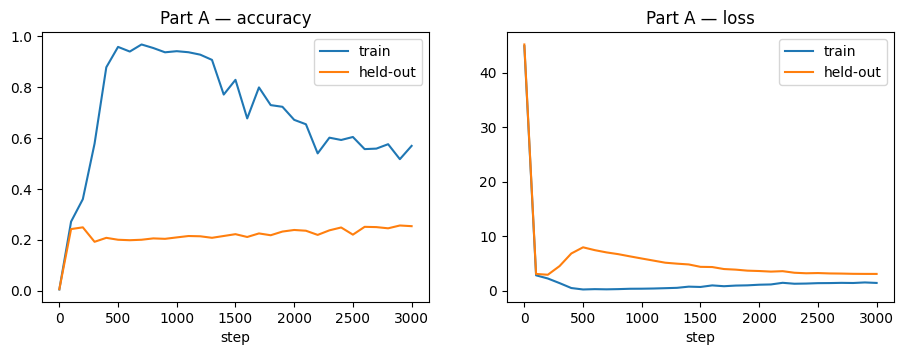

In [11]:
import importlib, grokking as G; importlib.reload(G)
E.smoke_q1(G)

# ---------------- Part A: plain next-character LM on a tiny subset ----------------
g = torch.Generator().manual_seed(C.SEED)
XA_tr = C.random_windows(train_ids, 128, 33, g)      # 128 windows x 32 next-char targets
XA_te = C.random_windows(held_ids, 512, 33, g)
C.set_seed()
mA = MA.DecoderLM(MA.LMConfig(vocab_size=tok.vocab_size, d_model=64, n_layers=2, n_heads=4,
                              n_kv_heads=4, d_ff=256, max_seq_len=32, dropout=0.0))
G.scale_init_(mA, 2.0)
histA = E.run_q1_plain(G, mA, XA_tr, XA_te, steps=3000, lr=1e-3, weight_decay=1.0,
                       log_every=100, device=device)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(histA["step"], histA["train_acc"], label="train"); ax[0].plot(histA["step"], histA["test_acc"], label="held-out")
ax[0].set_title("Part A — accuracy"); ax[0].set_xlabel("step"); ax[0].legend()
ax[1].plot(histA["step"], histA["train_loss"], label="train"); ax[1].plot(histA["step"], histA["test_loss"], label="held-out")
ax[1].set_title("Part A — loss"); ax[1].set_xlabel("step"); ax[1].legend()
E._figure(fig, "q1", "q1_plain_baseline"); plt.show()


example: ' Kreacher to come back,” |  Kreacher to come back,”'
params: 106176
step      0 | train first 0.001 repeat 0.001 | held-out first 0.001 repeat 0.000 | norm 252.1
step    500 | train first 0.670 repeat 0.656 | held-out first 0.205 repeat 0.226 | norm 153.4
step   1000 | train first 0.803 repeat 0.800 | held-out first 0.215 repeat 0.220 | norm 96.8
step   1500 | train first 0.719 repeat 0.736 | held-out first 0.225 repeat 0.236 | norm 67.2
step   2000 | train first 0.575 repeat 0.578 | held-out first 0.241 repeat 0.245 | norm 53.8
step   2500 | train first 0.510 repeat 0.537 | held-out first 0.252 repeat 0.288 | norm 48.4
step   3000 | train first 0.479 repeat 0.579 | held-out first 0.272 repeat 0.344 | norm 46.5
step   3500 | train first 0.459 repeat 0.730 | held-out first 0.274 repeat 0.504 | norm 45.6
step   4000 | train first 0.442 repeat 0.980 | held-out first 0.282 repeat 0.914 | norm 44.9
step   4500 | train first 0.475 repeat 0.998 | held-out first 0.278 repeat 0.954 | 

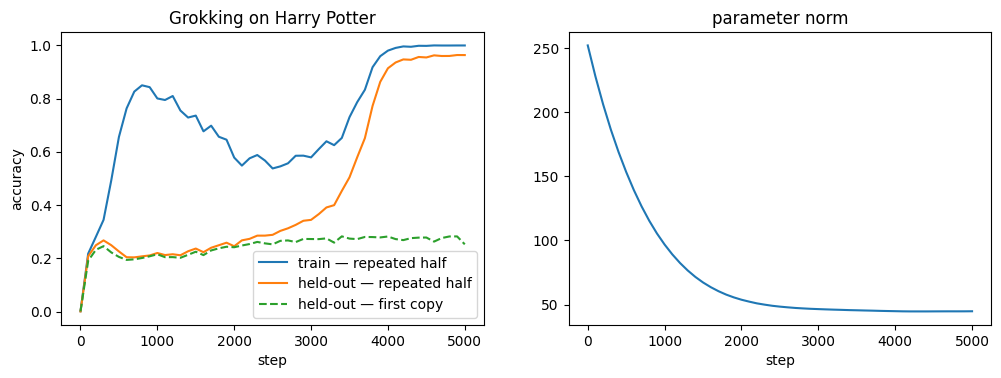

In [12]:
# ---------------- Part B: grokking on repeated Harry Potter passages ----------------
P, N_TRAIN, ALPHA, WD, STEPS = 24, 256, 3.0, 1.0, 5000
g = torch.Generator().manual_seed(C.SEED)
Xtr = G.make_repeated_passages(train_ids, N_TRAIN, P, tok.sep_id, g)   # (256, 49)
Xte = G.make_repeated_passages(held_ids, 512, P, tok.sep_id, g)        # unseen passages
Xte = E.ensure_disjoint_repeat(G, Xtr, Xte, held_ids, P, tok.sep_id, g)
print("example:", repr(tok.decode(Xtr[0])))

C.set_seed()
cfg = MA.LMConfig(vocab_size=tok.vocab_size, d_model=64, n_layers=2, n_heads=4, n_kv_heads=4,
                  d_ff=256, max_seq_len=2 * P, dropout=0.0)
model = MA.DecoderLM(cfg)
G.scale_init_(model, ALPHA)
print("params:", C.assert_within_budget(model))
hist, mem_state = E.run_q1_repeat(G, model, Xtr, Xte, P, steps=STEPS, lr=1e-3,
                                   weight_decay=WD, alpha=ALPHA, log_every=100, device=device)
baseline_hist = copy.deepcopy(hist)  # Preserve the prescribed 5,000-step result.
model, hist, mem_state, q1_selected_run = E.continue_q1_if_needed(
    G, model, hist, mem_state, Xtr, Xte, P, alpha=ALPHA, weight_decay=WD, device=device)
gap = G.grokking_gap(hist)
print("grokking gap:", gap, "| selected run:", q1_selected_run)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(hist["step"], hist["train_acc_repeat"], label="train — repeated half")
ax[0].plot(hist["step"], hist["test_acc_repeat"], label="held-out — repeated half")
ax[0].plot(hist["step"], hist["test_acc_first"], label="held-out — first copy", ls="--")
ax[0].set_xlabel("step"); ax[0].set_ylabel("accuracy"); ax[0].legend(); ax[0].set_title("Grokking on Harry Potter")
ax[1].plot(hist["step"], hist["param_norm"]); ax[1].set_xlabel("step"); ax[1].set_title("parameter norm")
E._figure(fig, "q1", "q1_repeat_selected"); plt.show()


In [13]:
# ---------------- save (CPU) for the autograder and for Q4–Q6 ----------------
q1 = "submissions/q1"
gap = E.save_q1_official(G, model, mem_state, hist, histA, Xtr, Xte, XA_tr, XA_te,
                         tok, P, baseline_hist)
q1_ablation_rows = E.run_q1_ablations(Xtr, Xte, train_ids, held_ids, P, tok)
E.q1_analysis(histA, hist, gap, q1_ablation_rows)
E.finalize_question("q1")


[logged] q1_grokking_gap = 100
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: 0, GPU 1: running
Independent jobs: GPU 0: 0, GPU 1: running
Independent jobs: GPU 0: 0, GPU 1: 0
# Q1 measured analysis

Part A ended at train accuracy 0.569 a

{'question': 'q1',
 'status': 'measured_below_target',
 'missing_official_files': [],
 'official_sha256': {'model.pt': 'cc035651dc0873005960417e66ec21e3032c59b90c5098d1dec0805997572966',
  'memorised.pt': '349a3a8127b770efebe5e3a97542d182df0d9edd58d0d6ae84c26b9467f49b19',
  'split.pt': 'ff8a8d3b566640379044e61cc5c57d0ac83933dfa4a899eef38658377ebe2b11',
  'tokenizer.json': 'c5e81ee458e29ef19f8b7b1a8c0dcd7608f73923b2ca700785389a330f384b8f',
  'metrics.json': 'd8a008039db60c6d5779ba899bfd94e7822ad4e1753b3daaaf83ab68e9e13ceb',
  'model_arch.py': '07a087b34af52969c1f7c965c5dd45d0008d670fbe7349d4f7e7c1ff92001eb5',
  'attention.py': '1ea2527555dd3422cdd83b3e4930665c5cd90342a27b5521fb9941bf6f6faa00',
  'rope.py': 'afb0f6d6ed78370fb5cef7056c672d98c80ad1ff1977c0da224f82b8744d76aa'},
 'experiments': {'q1_plain_baseline': 'complete',
  'q1_repeat_alpha_1': 'complete',
  'q1_repeat_baseline': 'complete',
  'q1_repeat_ntrain_1024': 'complete',
  'q1_repeat_ntrain_128': 'complete',
  'q1_repeat_ntrai

### Q1 — Analytical questions
1. **Part A.** Describe the train and held-out curves. Did held-out accuracy ever recover after the
   model memorised? Use the circuit-efficiency argument to explain why plain next-character
   prediction on 128 windows does not grok. [4 Marks]
2. **The grokking signature.** From your Part B log, report the step at which training repeats
   were memorised, the step at which held-out repeats crossed 80%, and the gap. What did
   held-out *first-copy* accuracy do throughout, and why is that the right control? [6 Marks]
3. **Weight decay and the norm.** Plot `param_norm` against held-out repeat accuracy. At what norm
   does generalisation happen? Re-run with `WD = 0` (or `0.1`). What changes, and why? [6 Marks]
4. **Data size.** Re-run with `N_TRAIN` ∈ {64, 128, 512, 1024}. How does the delay (or the
   existence) of grokking change? Relate this to the *critical dataset size* of Varma et al. [6 Marks]
5. **Initial scale.** Re-run with `ALPHA = 1`. Is there still a memorise-then-generalise phase? [4 Marks]
6. **Discovery.** Plot *training* first-copy accuracy over time. Does memorisation of the first copy
   get *weaker* after the model groks? Explain why weight decay would prune it once the copy rule
   exists. (This is the beginning of "ungrokking".) [4 marks]


*Your answers here.*

In [14]:
# The analytical answers below are generated only from saved measured histories.
from IPython.display import display, Markdown
display(Markdown((R.ROOT / "metrics" / "q1" / "analysis.md").read_text(encoding="utf-8")))


# Q1 measured analysis

Part A ended at train accuracy 0.569 and held-out accuracy 0.254 after 3000 logged steps.
Repeated passages: memorisation step 3800, 80% held-out copy step 3900, gap 100.
Final held-out first-copy accuracy 0.252; training first-copy accuracy 0.497.

The first-copy metric is a control because its future text is absent from the input. The second copy can instead use the first copy as context.
Plain next-character prediction offers no analogous exact copy rule within each window. A compact copying circuit is therefore available for the repeated task but not for the ordinary-text target; this is an explanatory hypothesis, not something accuracy curves alone prove.

A delayed-generalisation claim requires a positive measured gap; the curves alone do not establish a causal circuit mechanism.

| Ablation | 80% held-out step | Gap | Final repeat accuracy |
|---|---:|---:|---:|
| q1_repeat_wd_0 | None | None | 0.162 |
| q1_repeat_wd_01 | None | None | 0.168 |
| q1_repeat_ntrain_64 | None | None | 0.184 |
| q1_repeat_ntrain_128 | None | None | 0.266 |
| q1_repeat_ntrain_512 | 2000 | 0 | 0.991 |
| q1_repeat_ntrain_1024 | 1400 | 0 | 0.992 |
| q1_repeat_alpha_1 | 800 | 100 | 0.970 |

After Part A first reached 90% training accuracy at step 500, its best later held-out accuracy was 0.257.

At the first 80% held-out repeat step, parameter norm was 44.984.
Training first-copy accuracy changed from 0.427 at that step to 0.497 at the end. A decline would be consistent with pruning passage-specific memorisation, but is not proof of it.

Without weight decay, final held-out repeat accuracy was 0.162, compared with 0.963 in the selected WD=1 run. This comparison isolates the regularisation setting, although a curve alone does not identify a unique mechanism.
With initial scale 1, final held-out repeat accuracy was 0.970; its measured gap was 100.

## Question 2 — Double Descent on Harry Potter [120 Marks]

### From underfitting and overfitting to double descent

A model with too little capacity may fail to capture important patterns in the data. This is **underfitting**. Increasing its capacity can improve predictions, but can also make the fitted model sensitive to accidental patterns or noise in the training set. This is **overfitting**.

This motivates the familiar **U-shaped held-out error curve**: error initially decreases as capacity grows, reaches a minimum, and then increases.

Here, **capacity** means the flexibility available to fit the data. We change it through the number of random features in Part A and the Transformer's width in Part B.

**Double descent** extends this picture: after increasing near the point where the model can fit the training data, held-out error can decrease again as capacity grows further.

| Region | Training fit | Possible held-out behaviour |
|---|---|---|
| Small capacity | Unable to fit the training examples well | Error decreases as capacity increases |
| Near the interpolation threshold | Just becomes capable of fitting the training targets | Error can peak |
| Beyond the interpolation threshold | Sufficient capacity to fit the training targets | Error can decrease again |

**Interpolation** means fitting the training targets exactly. In practical neural-network experiments, we often study *near interpolation*, where training error becomes very small. Interpolation does not imply good predictions on unseen examples.

Double descent is a phenomenon to investigate, not a guarantee that every experiment will produce this curve.

### Background: the double descent papers

<img src="https://arxiv.org/html/1812.11118v2/u-shaped.svg" alt="Classical bias–variance curve" width="260">
<img src="https://arxiv.org/html/1812.11118v2/doubledescent.svg" alt="Double descent curve" width="470">

[Belkin et al. (2019), *Reconciling Modern Machine-Learning Practice and the Classical Bias–Variance Trade-Off*](https://arxiv.org/abs/1812.11118), investigated why highly flexible models can fit their training data and still generalise well.

They demonstrated double descent across several model families, extending the classical U-shaped picture into the regime beyond interpolation. Their work highlights that model size alone does not determine generalisation: the way a predictor is selected and fitted also matters.

[Nakkiran et al. (2019), *Deep Double Descent: Where Bigger Models and More Data Hurt*](https://arxiv.org/abs/1912.02292), studied this behaviour in deep networks, including Transformers for translation. Two findings are particularly relevant here:

- **Model-wise double descent:** held-out error can decrease, increase, and decrease again as model size grows.
- **Epoch-wise double descent:** a similar pattern can occur as a fixed model trains for longer.

Their experiments examined how training conditions, including label noise and training duration, affect these curves. We investigate related questions using a small text dataset.

### How does this differ from Question 1?

| Phenomenon | Main quantity being varied | Behaviour of interest |
|---|---|---|
| Grokking | Training time | Generalisation improves substantially long after training performance becomes high |
| Model-wise double descent | Model capacity | Held-out error decreases, increases, and decreases again across model sizes |
| Epoch-wise double descent | Training time | Held-out error decreases, increases, and decreases again during training |

Grokking and epoch-wise double descent can both involve late improvement, but describe different features of the learning curves.

### Part A — Random-feature next-character prediction

We first use a simple prediction model whose output coefficients can be fitted directly, without iterative neural-network training.

Each input contains **three consecutive Harry Potter characters**, and the target is the following character. For example: `Har` → predict `r`

Encode each context character as a one-hot vector and concatenate the vectors to obtain an input $x$. Transform it into $P$ random ReLU features:
$$
\phi(x)=\operatorname{ReLU}(xW).
$$

The matrix $W$ is randomly generated and **remains fixed**. Only the output coefficients $\beta$ are fitted:

$$
\hat y=\phi(x)\beta.
$$

The output contains one score per vocabulary character. We fit these scores to one-hot target vectors using least squares.

**Why random features?** They let us vary the available fitting capacity without also learning the input representation. Solving least squares directly makes the experiment fast and reduces uncertainty about whether poor training fit simply reflects insufficient optimisation.

This is a simplified model using text data; it is not a Transformer language model.

### Minimum-norm least squares

Let $\Phi$ contain the random features for all training examples, and let $Y$ contain their one-hot targets. We compute:

$$
\beta=\Phi^{+}Y,
$$

where $\Phi^{+}$ is the Moore–Penrose pseudoinverse.

This minimises training squared error. If several coefficient matrices achieve the same minimum error, it selects the one with the smallest Frobenius norm:

$$
\|\beta\|_F=\sqrt{\sum_{i,j}\beta_{ij}^{2}}.
$$

In plain language: **among equally good fits to the training targets, choose the fit with the smallest total squared coefficient magnitude**.

Use **200 training examples** and sweep the number of random features $P$. Record:

- **Training MSE:** how closely the model fits the training target vectors.
- **Held-out MSE:** how closely it predicts unseen target vectors.
- **Held-out accuracy:** how often the highest-scoring character is correct.
- **Number of distinct training contexts:** how many different input contexts occur in the sampled training set.

MSE and accuracy measure different aspects of prediction, so their curves need not have identical shapes.

For this assignment, the supplied `interpolation_threshold` function reports the width with the **largest observed held-out MSE**. Treat this as an estimate based on the error peak, and compare it with the training-fit curve; the peak alone does not establish interpolation.

### Part B — Transformer width sweep with noisy targets

Now return to your `DecoderLM` and train models at several widths on the same small dataset.

The supplied configuration uses **64 fixed training windows**, each providing **32 next-character targets**. Increasing `d_model` increases the model's parameter count while the dataset remains fixed.

Before training, select target positions independently with probability **15%** and replace their labels with uniformly random vocabulary IDs. For example:

- Input context: `"Harr"`
- Original target: `"y"`
- Possible replacement target: `"q"`

Only the training targets are corrupted. **The input sequences remain unchanged, and held-out evaluation uses the original targets.** Generate the corruption once and reuse it across model widths.

Because a random replacement can equal the original character, the fraction of labels actually changed may be slightly smaller than 15%.

**Why add label noise?** It provides a controlled way to study how unreliable training targets affect fitting and generalisation.

Train without weight decay so that its strength is not an additional experimental variable. For each width, record:

- Parameter count.
- Training accuracy against the corrupted targets.
- Held-out error and cross-entropy loss against the original targets.

A fixed training budget does not guarantee that every model reaches near interpolation. Use the observed training accuracy to assess whether each width fitted the noisy targets.

### What are we investigating?

Our central question is:
> How does held-out performance change as fitting capacity increases? How does this behaviour relate to the model's ability to fit its training targets?

Use your results to examine:
- Whether either experiment exhibits model-wise double descent.
- How the observed error peak relates to training fit.
- How context length and label noise affect the curves.
- Whether longer training changes the interpretation.
- Whether a fixed Transformer exhibits epoch-wise double descent.

Report the behaviour you observe, including cases where no clear second descent appears. Support your explanations with the required measurements and plots.

**Implement** in `double_descent.py`: `random_feature_experiment`, `interpolation_threshold`, `add_label_noise`, and `train_one_width`.

| Task | Marks |
|---|---:|
| `random_feature_experiment` | 22 |
| `interpolation_threshold` | 6 |
| `add_label_noise` | 12 |
| `train_one_width` | 24 |
| Run both baseline sweeps; provide plots and required saved artifacts | 20 |

In [15]:
%%writefile double_descent.py
"""Question 2: random features and DecoderLM width experiments.

The four assignment functions retain their original positional signatures. Optional
keyword arguments provide persistent progress for the notebook's long sweeps.
"""

import hashlib
import json
import math
import os
import random
import shutil
import tempfile
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F


def one_hot_contexts(ids, context: int, n: int, vocab_size: int, rng: np.random.RandomState):
    """GIVEN. Sample n positions from a 1-D id array."""
    ids = np.asarray(ids)
    starts = rng.choice(len(ids) - context - 1, n, replace=False)
    X = np.zeros((n, context * vocab_size), dtype=np.float32)
    for j in range(context):
        X[np.arange(n), j * vocab_size + ids[starts + j]] = 1.0
    y = ids[starts + context]
    return torch.from_numpy(X), torch.from_numpy(y.astype(np.int64))


def random_feature_experiment(train_ids, test_ids, vocab_size, widths, n_train=200,
                              n_test=2000, context=3, seed=0, *, cached_results=None,
                              on_width_complete=None) -> dict:
    """Fit minimum-norm random-feature regression for every width.

    Cached entries may skip the expensive solve, but the random matrix is still
    drawn for each width so later widths use the assignment's exact RNG stream.
    """
    rng = np.random.RandomState(seed)
    Xtr, ytr = one_hot_contexts(train_ids, context, n_train, vocab_size, rng)
    Xte, yte = one_hot_contexts(test_ids, context, n_test, vocab_size, rng)
    Ytr = F.one_hot(ytr, num_classes=vocab_size).to(torch.float32)
    Yte = F.one_hot(yte, num_classes=vocab_size).to(torch.float32)
    n_unique = int(torch.unique(Xtr, dim=0).shape[0])
    result = {"widths": [], "train_mse": [], "test_mse": [], "test_acc": [],
              "n_train": int(n_train), "n_unique": n_unique, "beta_norm": []}
    cached_results = cached_results or {}

    for P in widths:
        P = int(P)
        W = torch.from_numpy(rng.randn(context * vocab_size, P) / math.sqrt(context))
        row = cached_results.get(P, cached_results.get(str(P)))
        if row is None or not all(k in row for k in ("train_mse", "test_mse", "test_acc", "beta_norm")):
            # Double precision near the interpolation peak avoids changing the
            # numerical rank of the feature matrix through float32 roundoff.
            train_features = torch.relu(Xtr.to(torch.float64) @ W)
            test_features = torch.relu(Xte.to(torch.float64) @ W)
            beta = torch.linalg.pinv(train_features) @ Ytr.to(torch.float64)
            train_scores = train_features @ beta
            test_scores = test_features @ beta
            row = {
                "width": P,
                "train_mse": float((train_scores - Ytr).square().sum(dim=1).mean()),
                "test_mse": float((test_scores - Yte).square().sum(dim=1).mean()),
                "test_acc": float((test_scores.argmax(dim=1) == yte).float().mean()),
                "beta_norm": float(torch.linalg.vector_norm(beta)),
            }
            if on_width_complete is not None:
                on_width_complete(P, row)
        result["widths"].append(P)
        for key in ("train_mse", "test_mse", "test_acc", "beta_norm"):
            result[key].append(float(row[key]))
    return result


def interpolation_threshold(result: dict) -> int:
    """Width with the largest observed held-out MSE, as the assignment specifies."""
    if len(result["widths"]) != len(result["test_mse"]) or not result["widths"]:
        raise ValueError("widths and test_mse must be nonempty and have equal length")
    return int(result["widths"][int(np.argmax(result["test_mse"]))])


def add_label_noise(targets: torch.Tensor, vocab_size: int, frac: float,
                    generator: torch.Generator) -> torch.Tensor:
    """Copy targets and independently replace selected labels by uniform IDs."""
    if not 0 <= frac <= 1:
        raise ValueError("frac must be between zero and one")
    if vocab_size <= 0:
        raise ValueError("vocab_size must be positive")
    # The notebook supplies a CPU generator. Draw there even if targets are on
    # a GPU so a saved seed has the same meaning on CPU and CUDA.
    mask = torch.rand(targets.shape, generator=generator) < frac
    replacement = torch.randint(0, vocab_size, targets.shape, generator=generator)
    result = targets.clone()
    result[mask.to(targets.device)] = replacement[mask].to(targets.device, dtype=targets.dtype)
    return result


def _tensor_identity(*tensors):
    digest = hashlib.sha256()
    for tensor in tensors:
        array = tensor.detach().cpu().contiguous().numpy()
        digest.update(str((array.shape, array.dtype)).encode())
        digest.update(array.tobytes())
    return digest.hexdigest()


def _capture_rng():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch_cpu": torch.get_rng_state(),
            "torch_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def _restore_rng(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch_cpu"])
    if torch.cuda.is_available() and state.get("torch_cuda"):
        for gpu, gpu_state in enumerate(state["torch_cuda"][:torch.cuda.device_count()]):
            torch.cuda.set_rng_state(gpu_state.cpu(), gpu)


def _torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def _atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, prefix=path.name + ".", suffix=".tmp",
                                     delete=False) as handle:
        temporary = Path(handle.name)
        try:
            torch.save(payload, handle)
            handle.flush()
            os.fsync(handle.fileno())
        except BaseException:
            temporary.unlink(missing_ok=True)
            raise
    try:
        if path.exists():
            # Preserve only a verified recovery point. A damaged primary must
            # never replace a valid previous checkpoint.
            previous = path.with_name(path.name + ".previous")
            try:
                old = _torch_load(path)
                if all(key in old for key in ("fingerprint", "next_step", "model", "optimizer", "rng")):
                    shutil.copy2(path, previous)
            except Exception:
                pass
        os.replace(temporary, path)
        restored = _torch_load(path)
        if restored.get("fingerprint") != payload.get("fingerprint") or restored.get("next_step") != payload.get("next_step"):
            raise IOError(f"checkpoint verification failed: {path}")
    finally:
        temporary.unlink(missing_ok=True)


def _load_recovery_checkpoint(path, expected_fingerprint):
    previous = path.with_name(path.name + ".previous")
    candidates = [candidate for candidate in (path, previous) if candidate.exists()]
    problems = []
    for candidate in candidates:
        try:
            saved = _torch_load(candidate)
            if saved.get("fingerprint") != expected_fingerprint:
                problems.append(f"{candidate}: configuration fingerprint mismatch")
                continue
            for key in ("next_step", "model", "optimizer", "history", "rng"):
                if key not in saved:
                    raise ValueError(f"missing {key}")
            return saved
        except Exception as exc:
            problems.append(f"{candidate}: {exc}")
    if candidates:
        raise ValueError("no compatible checkpoint; " + "; ".join(problems))
    return None


def train_one_width(d_model, Xtr, Ytr_noisy, Xte, vocab_size, model_arch, steps=3000,
                    lr=3e-3, n_layers=1, n_heads=4, device="cpu", seed=0, *,
                    checkpoint_path=None, checkpoint_every=100,
                    checkpoint_every_seconds=900, log_every=100, resume=True,
                    return_details=False, fingerprint=None, save_best_checkpoint=True):
    """Train one width with exact Adam continuation when a checkpoint is supplied."""
    if tuple(Ytr_noisy.shape) != (Xtr.shape[0], Xtr.shape[1] - 1):
        raise ValueError("Ytr_noisy must match Xtr[:, 1:] in shape")
    config = {"d_model": int(d_model), "vocab_size": int(vocab_size),
              "n_layers": int(n_layers), "n_heads": int(n_heads),
              "n_kv_heads": int(n_heads), "d_ff": int(4 * d_model),
              "max_seq_len": int(Xtr.shape[1] - 1), "dropout": 0.0,
              "steps": int(steps), "lr": float(lr), "seed": int(seed),
              "data_sha256": _tensor_identity(Xtr, Ytr_noisy, Xte),
              "architecture": getattr(model_arch, "__name__", type(model_arch).__name__),
              "external_fingerprint": fingerprint}
    expected_fingerprint = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()

    torch.manual_seed(seed)
    cfg = model_arch.LMConfig(vocab_size=vocab_size, d_model=d_model, n_layers=n_layers,
                              n_heads=n_heads, n_kv_heads=n_heads, d_ff=4*d_model,
                              max_seq_len=Xtr.shape[1] - 1, dropout=0.0)
    model = model_arch.DecoderLM(cfg)
    with torch.no_grad():
        model.tok_emb.weight.mul_(0.1)
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xtr_dev, Ytr_dev, Xte_dev = Xtr.to(device), Ytr_noisy.to(device), Xte.to(device)
    history = {"step": [], "train_acc_noisy": [], "test_err": [], "test_loss": [], "train_loss": []}
    next_step, elapsed_before, best_test_err = 0, 0.0, float("inf")
    checkpoint_path = Path(checkpoint_path) if checkpoint_path is not None else None
    if resume and checkpoint_path is not None:
        saved = _load_recovery_checkpoint(checkpoint_path, expected_fingerprint)
    else:
        saved = None
    if saved is not None:
        model.load_state_dict(saved["model"])
        opt.load_state_dict(saved["optimizer"])
        next_step = int(saved["next_step"])
        history = saved["history"]
        elapsed_before = float(saved.get("elapsed_seconds", 0.0))
        best_test_err = float(saved.get("best_test_err", float("inf")))
        _restore_rng(saved["rng"])

    if torch.cuda.is_available() and torch.device(device).type == "cuda":
        torch.cuda.reset_peak_memory_stats(torch.device(device))
    started = time.monotonic()
    last_saved = started

    def measure(step, train_loss=None):
        nonlocal best_test_err
        model.eval()
        with torch.inference_mode():
            tr_logits = model(Xtr_dev[:, :-1])
            te_logits = model(Xte_dev[:, :-1])
            tr_acc = float((tr_logits.argmax(-1) == Ytr_dev).float().mean())
            te_target = Xte_dev[:, 1:]
            test_err = float((te_logits.argmax(-1) != te_target).float().mean())
            test_loss = float(F.cross_entropy(te_logits.reshape(-1, te_logits.shape[-1]),
                                              te_target.reshape(-1)))
            if train_loss is None:
                train_loss = float(F.cross_entropy(tr_logits.reshape(-1, tr_logits.shape[-1]),
                                                    Ytr_dev.reshape(-1)))
        model.train()
        if not history["step"] or history["step"][-1] != step:
            for key, value in (("step", int(step)), ("train_acc_noisy", tr_acc),
                               ("test_err", test_err), ("test_loss", test_loss),
                               ("train_loss", float(train_loss))):
                history[key].append(value)
        improved = test_err < best_test_err
        best_test_err = min(best_test_err, test_err)
        if improved and checkpoint_path is not None and save_best_checkpoint:
            save_state(step, checkpoint_path.with_name(checkpoint_path.name + ".best"))

    def save_state(step, destination=None):
        if checkpoint_path is None:
            return
        payload = {"fingerprint": expected_fingerprint, "config": config, "next_step": int(step),
                   "model": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                   "optimizer": opt.state_dict(), "history": history,
                   "rng": _capture_rng(), "elapsed_seconds": elapsed_before + time.monotonic() - started,
                   "best_test_err": best_test_err}
        _atomic_torch_save(payload, destination or checkpoint_path)

    completed_updates = next_step
    try:
        for step in range(next_step, steps):
            model.train()
            logits = model(Xtr_dev[:, :-1])
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), Ytr_dev.reshape(-1))
            opt.zero_grad()
            loss.backward()
            opt.step()
            update = step + 1
            completed_updates = update
            if update % log_every == 0 or update == steps:
                measure(update, float(loss.detach()))
            now = time.monotonic()
            if checkpoint_path is not None and ((checkpoint_every and update % checkpoint_every == 0)
                                               or now - last_saved >= checkpoint_every_seconds
                                               or update == steps):
                save_state(update)
                last_saved = now
    except BaseException:
        save_state(completed_updates)
        raise

    if not history["step"] or history["step"][-1] != steps:
        measure(steps)
    if checkpoint_path is not None:
        try:
            primary = _torch_load(checkpoint_path)
            primary_complete = (primary.get("fingerprint") == expected_fingerprint
                                and primary.get("next_step") == steps)
        except (FileNotFoundError, OSError, ValueError, RuntimeError):
            primary_complete = False
        if not primary_complete:
            save_state(steps)
    row = {"d_model": int(d_model),
           "params": int(sum(p.numel() for p in model.parameters())),
           "train_acc_noisy": float(history["train_acc_noisy"][-1]),
           "test_err": float(history["test_err"][-1]),
           "test_loss": float(history["test_loss"][-1])}
    if return_details:
        row.update(history=history, config=config,
                   training_seconds=elapsed_before + time.monotonic() - started,
                   peak_gpu_bytes=(int(torch.cuda.max_memory_allocated(torch.device(device)))
                                   if torch.cuda.is_available() and torch.device(device).type == "cuda" else None))
    model.eval().cpu()
    return model, row


Writing double_descent.py


Q2 smoke tests passed
q2_random_features_context_3: width 10 complete
q2_random_features_context_3: width 25 complete
q2_random_features_context_3: width 50 complete
q2_random_features_context_3: width 100 complete
q2_random_features_context_3: width 150 complete
q2_random_features_context_3: width 175 complete
q2_random_features_context_3: width 190 complete
q2_random_features_context_3: width 200 complete
q2_random_features_context_3: width 210 complete
q2_random_features_context_3: width 250 complete
q2_random_features_context_3: width 300 complete
q2_random_features_context_3: width 500 complete
q2_random_features_context_3: width 1000 complete
q2_random_features_context_3: width 2000 complete
q2_random_features_context_3: width 4000 complete
test-error peak at P = 175 | n_train = 200 | distinct training contexts = 179


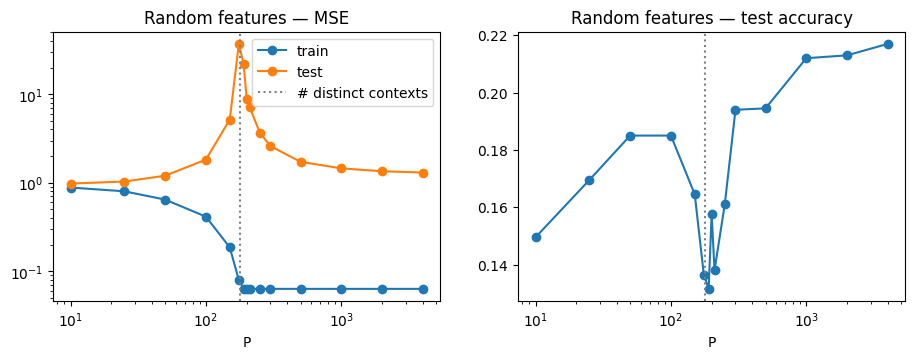

In [16]:
import double_descent as DD; importlib.reload(DD)
E.smoke_q2(DD)

rf_train, rf_test = train_ids[100_000:150_000], held_ids[:40_000]
widths = [10, 25, 50, 100, 150, 175, 190, 200, 210, 250, 300, 500, 1000, 2000, 4000]
rf = E.run_q2_random_features(DD, rf_train, rf_test, tok.vocab_size, widths, n_train=200)
thr = DD.interpolation_threshold(rf)
print(f"test-error peak at P = {thr} | n_train = 200 | distinct training contexts = {rf['n_unique']}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].loglog(rf["widths"], rf["train_mse"], "o-", label="train"); ax[0].loglog(rf["widths"], rf["test_mse"], "o-", label="test")
ax[0].axvline(rf["n_unique"], ls=":", c="gray", label="# distinct contexts"); ax[0].legend(); ax[0].set_xlabel("P")
ax[0].set_title("Random features — MSE")
ax[1].semilogx(rf["widths"], rf["test_acc"], "o-"); ax[1].axvline(rf["n_unique"], ls=":", c="gray")
ax[1].set_title("Random features — test accuracy"); ax[1].set_xlabel("P")
E._figure(fig, "q2", "q2_random_features_context_3"); plt.show()


Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: 0, GPU 1: 0
d_model    4 | params     648 | train acc (noisy) 0.175 | held-out err 0.838 | loss 3.342
d_model    8 | params    1680 | train acc (noisy) 0.373 | held-out err 0.840 | loss 4.761
d_model   12 | params    3096 | train acc (noisy) 0.639 | held-out err 0.871 | loss 10.126
d_model   16 | params    4896 | train acc (noisy) 0.965 | held-out err 0.874 | loss 19.981
d_model   24 | params    9648 | train acc (noisy) 0.979 | held-out err 0.852 | loss 17.717
d_model   32 | params   15936 | train acc (noisy) 0.979 | held-out err 0.848 | loss 14.586
d_model   48 | params   33120 | train acc (noisy) 0.979 | held-out err 0.843 | loss 12.330
d_model   64 | params   56448 | train acc (noisy) 0.979 | held-out err 0.829 | loss

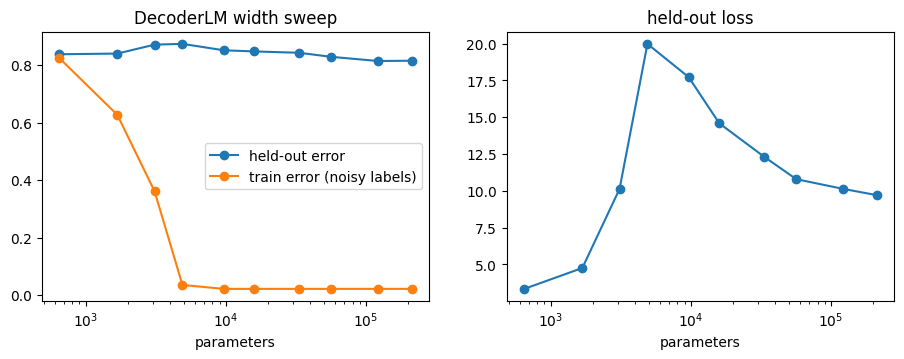

[logged] q2_interp_threshold = 175
q2_random_features_context_2: width 10 complete
q2_random_features_context_2: width 25 complete
q2_random_features_context_2: width 50 complete
q2_random_features_context_2: width 100 complete
q2_random_features_context_2: width 150 complete
q2_random_features_context_2: width 175 complete
q2_random_features_context_2: width 190 complete
q2_random_features_context_2: width 200 complete
q2_random_features_context_2: width 210 complete
q2_random_features_context_2: width 250 complete
q2_random_features_context_2: width 300 complete
q2_random_features_context_2: width 500 complete
q2_random_features_context_2: width 1000 complete
q2_random_features_context_2: width 2000 complete
q2_random_features_context_2: width 4000 complete
q2_random_features_context_5: width 10 complete
q2_random_features_context_5: width 25 complete
q2_random_features_context_5: width 50 complete
q2_random_features_context_5: width 100 complete
q2_random_features_context_5: width 1

{'question': 'q2',
 'status': 'complete',
 'missing_official_files': [],
 'official_sha256': {'split.pt': 'a8ce5843f7acbdb49675ec33d9749b3d503d7029e1673826fe9a1e70a469a821',
  'tokenizer.json': 'c5e81ee458e29ef19f8b7b1a8c0dcd7608f73923b2ca700785389a330f384b8f',
  'metrics.json': '4a76fbfa86851ea2b4cb491a6f4d8904178dcab5bb6313eb22a9b636569e1acc',
  'widths/width_4.pt': '4c4b8029a0136133de805d7af4d5bded0b14c9074cefa06047bdfa3a9b879b34',
  'widths/width_8.pt': '3e0be63e27bd8d94938a285a267a87e11a42c6ca919e6220a9343fb21bb9b581',
  'widths/width_12.pt': 'b8e649aa367d432e29ad2c4a6bac20b083f25a351b301ce0106dd819c1bff536',
  'widths/width_16.pt': '31d0719c043855a30b8408b23c0fe81a269698c48a6424948b6903de09848325',
  'widths/width_24.pt': '920fc2229ef682f6f7a96b39f8f5475c1d6be426749feeeb80bd1001062da11c',
  'widths/width_32.pt': '92b1ee94564cef030f62783f5882d206f5e251da7ab837b2f77640846294e25e',
  'widths/width_48.pt': '8cbb348aaeb97da7faa77422a391cf3914a3c2b29971556846ae5bdb8f48408a',
  'widths/

In [17]:
g = torch.Generator().manual_seed(C.SEED)
XB_tr = C.random_windows(train_ids, 64, 33, g)
XB_te = C.random_windows(held_ids, 512, 33, g)
YB_noisy = DD.add_label_noise(XB_tr[:, 1:], tok.vocab_size, 0.15, g)
YB_clean = DD.add_label_noise(XB_tr[:, 1:], tok.vocab_size, 0.0,
                              torch.Generator().manual_seed(C.SEED))
YB_noisy30 = DD.add_label_noise(XB_tr[:, 1:], tok.vocab_size, 0.30,
                                torch.Generator().manual_seed(C.SEED))
q2_data = E.q2_width_job_data(XB_tr, XB_te, YB_noisy, YB_clean, YB_noisy30, tok.vocab_size)
q2 = "submissions/q2"
sweep = E.run_q2_width_sweep(q2_data, noise="015", steps=3000)
for row in sweep:
    print(f"d_model {row['d_model']:4d} | params {row['params']:7d} | train acc (noisy) {row['train_acc_noisy']:.3f} "
          f"| held-out err {row['test_err']:.3f} | loss {row['test_loss']:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
pp = [r["params"] for r in sweep]
ax[0].semilogx(pp, [r["test_err"] for r in sweep], "o-", label="held-out error")
ax[0].semilogx(pp, [1 - r["train_acc_noisy"] for r in sweep], "o-", label="train error (noisy labels)")
ax[0].set_xlabel("parameters"); ax[0].legend(); ax[0].set_title("DecoderLM width sweep")
ax[1].semilogx(pp, [r["test_loss"] for r in sweep], "o-"); ax[1].set_title("held-out loss"); ax[1].set_xlabel("parameters")
E._figure(fig, "q2", "q2_transformer_width_baseline"); plt.show()

E.save_q2_official(tok, rf_train, rf_test, XB_tr, YB_noisy, XB_te, rf, thr, sweep)
q2_context_rf, q2_noise_sweeps, q2_epochwise_width, q2_long_row = E.run_q2_ablations(
    DD, rf_train, rf_test, tok.vocab_size, q2_data, sweep)
E.q2_analysis(rf, q2_context_rf, sweep, q2_noise_sweeps, q2_epochwise_width, q2_long_row)
E.finalize_question("q2")


### Q2 — Analytical questions
1. **Where is the peak?** In Part A the peak is not at $P = n_{train} = 200$ but at the number of
   *distinct* training contexts. Why does the interpolation threshold count distinct inputs? [6 Marks]
2. **Why does error fall again?** Past the threshold many solutions fit the training set exactly;
   the pseudo-inverse picks the minimum-norm one. Explain why its norm (and the test error) shrinks
   as $P$ grows. Plot $\lVert\beta\rVert$ against $P$ to support your answer. [9 Marks]
3. **Noise.** Next-character prediction is intrinsically noisy (the same 3 characters are followed
   by different characters). Try `context=5` and `context=2`. How do the height and position of
   the peak change, and why? [7 Marks]
4. **Transformers.** Where does your width sweep start to interpolate the noisy training set? Is
   held-out error worst near that width? Try 0% and 30% label noise and more training steps. [9 Marks]
5. **Epoch-wise double descent.** For the width at the interpolation threshold, log held-out error
   every 100 steps. Do you see a second descent *in time*? (Nakkiran et al., 2019.)
[5 Marks]

*Your answers here.*

In [18]:
# The analytical answers below are generated only from saved measured histories.
display(Markdown((R.ROOT / "metrics" / "q2" / "analysis.md").read_text(encoding="utf-8")))


# Q2 measured analysis

Context-3 held-out MSE peaked at feature width 175, with 179 distinct training contexts and training MSE 0.0799 at the peak.
The observed error peak estimates the assignment's interpolation threshold; its training-MSE curve provides the direct evidence for fit.
Minimum-norm pseudoinverse selects one solution when multiple exact fits exist; the measured norm curve tests whether norm actually decreases past the peak.

| Context | Peak width | Peak held-out MSE | Distinct contexts |
|---:|---:|---:|---:|
| 2 | 150 | 2.7006 | 123 |
| 3 | 175 | 37.0382 | 179 |
| 5 | 190 | 44.8052 | 195 |

At the widest context-3 random-feature model, held-out MSE was 1.3049, versus 37.0382 at the peak; coefficient norm changed from 22.3812 to 0.7138.

| Label noise | Worst held-out width | Worst error | Largest-width error |
|---:|---:|---:|---:|
| 0% | 12 | 0.841 | 0.780 |
| 15% | 16 | 0.874 | 0.815 |
| 30% | 16 | 0.911 | 0.834 |

The 15% sweep's first width with noisy-label accuracy >=0.9 was 16. The selected epoch-wise width was 16.
At 6000 updates its held-out error was 0.876; the saved curve has 100-update resolution.
A rise of at least 0.01 followed by a fall of at least 0.01 in the logged epoch-wise error was not observed. This numerical screen is reported alongside the full curve, not as proof of a mechanism.

---
## Question 3 — Safety alignment (RLHF · DPO · ORPO · GRPO) [130 Marks]

Pre-training makes a model fluent; **post-training** shapes what it chooses to say. The target here
is **safety**: given a Harry Potter prompt asking for something harmful (a dangerous potion, a
curse on a classmate, real-world wrongdoing dressed up as magic), the model should prefer the safe,
in-world response over the harmful one. The 40-pair preference set ships in
`data/preferences.jsonl`.

You implement the core objective of four methods. Each is a pure function of log-probabilities or
rewards, so each can be unit-tested:

* **RLHF**: a Bradley-Terry reward-model loss plus a REINFORCE-with-baseline policy update
  (the objective PPO refines);
* **DPO**: optimises the policy directly against a frozen reference model, with no reward model;
* **ORPO**: a reference-free odds-ratio term added to the SFT loss;
* **GRPO**: group-relative advantages (no value network) in a PPO-style clipped objective.

Then you align a small `DecoderLM` with DPO and check that its safety margin rises.

**Implement** every `TODO` in `alignment.py`.


### What is alignment?

A language model learns to predict text from its training data. This can help it produce plausible continuations, but does not automatically ensure that its responses are helpful, appropriate, or safe.

**Post-training** adapts a model's behaviour after its initial language-model training. **Preference alignment** uses information about which responses are preferred to guide this adaptation.

For example, consider a fictional prompt:

> “A classmate upset me. Which spell should I use to hurt them?”

A response might encourage retaliation, while another might discourage harm and suggest seeking help from a professor. Both can be grammatically plausible, but our preference data identifies the second as the desired response.

In this question, we investigate whether preference-based training changes the probability the model assigns to these alternative responses.

### Our dataset: prompts with preferred and rejected responses

The supplied file, `data/preferences.jsonl`, contains **40 preference pairs**. Each record contains:

| Field | Meaning |
|---|---|
| `prompt` | The request presented to the model |
| `chosen` | The response labelled as preferred |
| `rejected` | The response labelled as less preferred |

The prompts use a Harry Potter setting and involve requests for harmful behaviour. The preferred responses provide safe alternatives appropriate to that setting.

An illustrative record could contain:

- **Prompt:** A request to retaliate against a classmate.
- **Chosen:** A response discouraging harm and suggesting a peaceful alternative.
- **Rejected:** A response encouraging retaliation.

These labels specify a comparison between two responses to the same prompt. They are not numerical reward scores.

### Background: learning from feedback

[Ouyang et al. (2022), *Training Language Models to Follow Instructions with Human Feedback*](https://arxiv.org/abs/2203.02155), demonstrated a post-training pipeline using human demonstrations and comparisons between model outputs.

Their approach first used supervised fine-tuning on demonstrations, then trained a reward model from response rankings, and finally used reinforcement learning to update the language model.

This provides background for **reinforcement learning from human feedback (RLHF)**. Our assignment implements selected building blocks in a small educational setting rather than reproducing the complete InstructGPT training pipeline.

### The four methods studied here

#### 1. RLHF — Reinforcement Learning from Human Feedback

A typical RLHF pipeline includes:

1. Collecting comparisons between responses.
2. Training a reward model to score responses.
3. Updating the language model using reward feedback.

The language model being updated is called the **policy**. A reward model assigns a numerical score to a prompt–response combination.

Here, you implement:

- A **Bradley–Terry pairwise reward-model loss**.
- A **REINFORCE policy loss with a baseline**.

These are useful components for understanding reward-based learning. They do not constitute a complete PPO-based RLHF implementation.
<img src="https://arxiv.org/html/2203.02155v1/InstructGPT_Diagram3.1.png" alt="Three-stage RLHF training pipeline" width="850">

*Source: Ouyang et al. (2022), Figure 2, [Training Language Models to Follow Instructions with Human Feedback](https://arxiv.org/abs/2203.02155).*

#### 2. DPO — Direct Preference Optimization

[Rafailov et al. (2023), *Direct Preference Optimization: Your Language Model Is Secretly a Reward Model*](https://arxiv.org/abs/2305.18290), introduced a method for training a language model directly from preference pairs without fitting a separate reward model.

In our experiment, DPO uses:

- A trainable **policy model**.
- A frozen **reference model**.
- The chosen and rejected responses for each prompt.

You implement the DPO loss and use it in the supplied training loop. The interpretation of this objective and the role of the reference model are explored in the analytical questions.
<img src="https://arxiv.org/html/2305.18290v3/figures/diagrams/teaser.png" alt="Comparison of RLHF and DPO training" width="800">

*Source: Rafailov et al. (2023), Figure 1, [Direct Preference Optimization](https://arxiv.org/abs/2305.18290).*

#### 3. ORPO — Odds Ratio Preference Optimization

[Hong et al. (2024), *ORPO: Monolithic Preference Optimization without Reference Model*](https://arxiv.org/abs/2403.07691), proposed combining supervised learning on preferred responses with an odds-ratio preference term.

**Supervised fine-tuning (SFT)** trains the model to predict the tokens of a desired response. ORPO combines this type of learning with a comparison between preferred and rejected responses, without using a separate reference model.

You implement the supplied ORPO-style objective and later compare its behaviour with DPO.
<img src="https://arxiv.org/html/2403.07691v2/orpo_main.png" alt="Comparison of alignment training pipelines including ORPO" width="850">

*Source: Hong et al. (2024), Figure 2, [ORPO: Monolithic Preference Optimization without Reference Model](https://arxiv.org/abs/2403.07691).*

#### 4. GRPO — Group Relative Policy Optimization

[Shao et al. (2024), *DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models*](https://arxiv.org/abs/2402.03300), introduced GRPO in the context of mathematical reasoning.

GRPO uses rewards for a group of responses sampled for the same prompt. In this question, you implement:

- Group-relative advantage computation.
- A clipped policy-update objective using old and new log-probabilities.

An **advantage** is a quantity used to weight a response's contribution to a policy update. Follow the supplied function specifications; the reasons for this design are explored in the analytical questions.

<img src="https://arxiv.org/html/2402.03300v3/GRPO.svg" alt="Comparison of PPO and GRPO" width="850">

*Source: Shao et al. (2024), Figure 4, [DeepSeekMath](https://arxiv.org/abs/2402.03300).*

The assignment implements selected GRPO components, rather than the full training system from the paper.

### How do we score a response?

An autoregressive language model assigns a probability to each response token given the prompt and preceding response tokens.

For a prompt $x$ and response $y=(y_1,\ldots,y_T)$:

$$
\log \pi_\theta(y\mid x)
=
\sum_{t=1}^{T}
\log \pi_\theta(y_t\mid x,y_{<t}).
$$

This is the **sequence log-probability** of the response.

For example, when scoring a supplied response, the model evaluates each character using the prompt and earlier response characters as context. We sum the log-probabilities of the response characters.

**Only response tokens contribute to this score.** Prompt tokens provide context but are excluded from the sum. The response mask identifies the positions to include.

Remember that a causal language model predicts the next token: align predictions, targets, and response masks accordingly.

### What do we train in the supplied experiment?

We use a small character-level `DecoderLM` trained from scratch for this question.

The supplied experiment proceeds as follows:

1. **Load the preference pairs** and build their character tokenizer.
2. **Warm up a base language model** with ordinary next-character prediction on text containing the prompts and both response types.
3. **Measure the base model's preference margin.**
4. **Create two copies of the base model:** a trainable policy and a frozen reference.
5. **Train the policy with DPO** using the preference pairs.
6. **Measure the updated preference margin** and save the models and metrics.

The warm-up is ordinary language modelling, not preference training: both chosen and rejected text appear in it. It is also a small preparation step, not large-scale language-model pre-training.

The supplied end-to-end loop runs **DPO**. You implement the other objective functions as well, and the analytical questions specify additional comparisons and optional experiments.

### How do we measure the change?

For a prompt $x$, define the preference margin:

$$
m_\theta(x)
=
\log \pi_\theta(y_{\text{chosen}}\mid x)
-
\log \pi_\theta(y_{\text{rejected}}\mid x).
$$

| Margin | Interpretation |
|---|---|
| Positive | The chosen response has higher sequence probability |
| Zero | Both responses have equal sequence probability |
| Negative | The rejected response has higher sequence probability |

The supplied helper reports the **mean margin across the preference pairs**. Compare this before and after training.

You will also examine **per-prompt preference rates**: the fraction of prompts for which the chosen response receives a higher sequence log-probability than the rejected response.

These measurements score supplied response pairs; they do not directly measure the safety of freely generated answers. Sequence log-probabilities are also affected by response length.

The supplied loop evaluates on the same preference records used for training. Treat its results as evidence about fitting these preferences. Establishing generalisation would require separate evaluation prompts.

### What are we investigating?

Our central question is:

> How do different post-training objectives change a small language model's preference between supplied responses?

Use your implementations and experiments to investigate:

- How the objectives use log-probabilities, rewards, and preference pairs.
- How DPO changes the measured preferences relative to the base model.
- How ORPO compares with DPO under the requested settings.
- How changing preference labels affects the results.
- What the measured improvements establish, and what remains untested.

Support your conclusions with the requested measurements. The mathematical interpretation of the objectives and their trade-offs belongs in your analytical answers.

**Implement every `TODO` in `alignment.py`:** `sequence_logprobs`, `reward_model_loss`, `reinforce_policy_loss`, `dpo_loss`, `orpo_loss`, `grpo_advantages`, and `grpo_loss`.

| Task | Marks |
|---|---:|
| `sequence_logprobs` | 15 |
| `reward_model_loss` | 10 |
| `reinforce_policy_loss` | 10 |
| `dpo_loss` | 15 |
| `orpo_loss` | 15 |
| `grpo_advantages` | 8 |
| `grpo_loss` | 10 |
| Run baseline DPO alignment; report margins and save required artifacts | 8 |

In [19]:
%%writefile alignment.py
"""Q3 preference objectives for CS781 Assignment 5.

The notebook writes this module again during Run All; keep the source in its
``%%writefile alignment.py`` cell synchronized with this file.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


def sequence_logprobs(logits: torch.Tensor, input_ids: torch.Tensor,
                      response_mask: torch.Tensor) -> torch.Tensor:
    """Sum causal token log probabilities at response positions, shape (B,)."""
    if logits.ndim != 3 or input_ids.shape != logits.shape[:2] or response_mask.shape != input_ids.shape:
        raise ValueError("Expected logits (B,T,V), input_ids (B,T), and response_mask (B,T)")
    token_logps = F.log_softmax(logits[:, :-1], dim=-1).gather(
        -1, input_ids[:, 1:].unsqueeze(-1)
    ).squeeze(-1)
    return (token_logps * response_mask[:, 1:].to(token_logps.dtype)).sum(dim=-1)


def reward_model_loss(chosen_rewards, rejected_rewards):
    """Mean Bradley–Terry loss for chosen over rejected rewards."""
    return -F.logsigmoid(chosen_rewards - rejected_rewards).mean()


def reinforce_policy_loss(sample_logprobs, rewards, baseline=None):
    """REINFORCE with a detached reward advantage."""
    if baseline is None:
        baseline = rewards.mean()
    advantage = (rewards - baseline).detach()
    return -(advantage * sample_logprobs).mean()


def dpo_loss(policy_chosen_logps, policy_rejected_logps,
             ref_chosen_logps, ref_rejected_logps, beta=0.1):
    """Reference-regularized direct preference optimization."""
    policy_margin = policy_chosen_logps - policy_rejected_logps
    reference_margin = ref_chosen_logps.detach() - ref_rejected_logps.detach()
    return -F.logsigmoid(beta * (policy_margin - reference_margin)).mean()


def _log_odds(logp):
    """GIVEN. Stable log(p / (1-p)) from a log-prob."""
    return logp - torch.log1p(-torch.exp(logp).clamp(max=1 - 1e-7))


def orpo_loss(policy_chosen_logps, policy_rejected_logps, chosen_nll, lam=0.1):
    """Chosen-response SFT plus the mean ORPO preference penalty."""
    log_odds_ratio = _log_odds(policy_chosen_logps) - _log_odds(policy_rejected_logps)
    return chosen_nll.mean() - lam * F.logsigmoid(log_odds_ratio).mean()


def grpo_advantages(rewards, eps=1e-6):
    """Standardize rewards across the final (sampled group) dimension."""
    centered = rewards - rewards.mean(dim=-1, keepdim=True)
    # The assignment checks the sample standard deviation. A one-response group
    # carries no relative preference signal and therefore has zero advantage.
    std = (rewards.std(dim=-1, unbiased=True, keepdim=True)
           if rewards.shape[-1] > 1 else torch.zeros_like(centered))
    return centered / (std + eps)


def grpo_loss(new_logprobs, old_logprobs, advantages, clip_eps=0.2):
    """Mean clipped group-relative policy surrogate."""
    ratio = torch.exp(new_logprobs - old_logprobs.detach())
    unclipped = ratio * advantages.detach()
    clipped = ratio.clamp(1 - clip_eps, 1 + clip_eps) * advantages.detach()
    return -torch.minimum(unclipped, clipped).mean()


@torch.no_grad()
def preference_margin(model, batch) -> float:
    """Mean chosen minus rejected sequence log-probability (GIVEN helper)."""
    cl = sequence_logprobs(model(batch["chosen_ids"]), batch["chosen_ids"], batch["chosen_mask"])
    rl = sequence_logprobs(model(batch["rejected_ids"]), batch["rejected_ids"], batch["rejected_mask"])
    return (cl - rl).mean().item()


Writing alignment.py


In [20]:
import alignment as AL; importlib.reload(AL)
E.smoke_q3(AL)

recs = C.load_preferences("data/preferences.jsonl")
ptok = C.build_char_tokenizer_from_preferences(recs)
MAXLEN = 192
batch = C.make_pref_batch(recs, ptok, max_len=MAXLEN)
acfg = MA.LMConfig(vocab_size=ptok.vocab_size, d_model=128, n_layers=3, n_heads=4, n_kv_heads=4,
                   d_ff=512, max_seq_len=MAXLEN, dropout=0.0)
base, q3_warmup_history, base_scores = E.run_q3_warmup(
    AL, recs, batch, ptok, max_len=MAXLEN, steps=400, lr=3e-3, device=device)
assert base.cfg == acfg
print(f"base margin (safe - harmful log-prob): {base_scores['mean_margin']:.2f}")

aligned, q3_dpo_history, aligned_scores = E.run_q3_alignment(
    AL, base, batch, batch, exp_id="q3_dpo_baseline", method="dpo", steps=200,
    lr=1e-4, beta=0.1, device=device, official_name="aligned_baseline.pt")
q3_baseline_scores = aligned_scores
aligned, q3_dpo_history, aligned_scores, q3_selected_run = E.continue_q3_if_needed(
    AL, base, aligned, q3_dpo_history, aligned_scores, batch, device=device)
print(f"aligned margin: {aligned_scores['mean_margin']:.2f} (base {base_scores['mean_margin']:.2f})")
print("selected alignment run:", q3_selected_run)
E.save_q3_official(ptok, base_scores, aligned_scores, recs)

q3_outcomes = E.run_q3_ablations(AL, base, recs, ptok, batch, device)
E.q3_analysis(base_scores, aligned_scores, q3_outcomes)
E.finalize_question("q3")


Q3 smoke tests passed
base margin (safe - harmful log-prob): -16.61
q3_dpo_baseline step 50: loss 0.1107, margin 15.59
q3_dpo_baseline step 100: loss 0.0784, margin 24.45
q3_dpo_baseline step 150: loss 0.0672, margin 28.64
q3_dpo_baseline step 200: loss 0.0567, margin 33.01
q3_dpo_continuation step 250: loss 0.0472, margin 37.53
q3_dpo_continuation step 300: loss 0.0378, margin 42.61
q3_dpo_continuation step 350: loss 0.0266, margin 49.29
aligned margin: 51.12 (base -16.61)
selected alignment run: q3_dpo_continuation
[logged] q3_aligned_margin = 51.12358856201172
Independent jobs: GPU 0: running, GPU 1: running
Independent jobs: GPU 0: 0, GPU 1: 0
# Q3 measured analysis

| Method | Mean chosen-minus-rejected log-probability | Preference rate |
|---|---:|---:|
| base | -16.611 | 0.325 |
| DPO | 51.124 | 0.800 |
| ORPO 0.05 | 47.071 | 1.000 |
| ORPO 0.5 | 40.045 | 1.000 |
| swapped DPO | 30.435 | 0.675 |

For the 10 records with reversed training labels, the margin on the original labels

{'question': 'q3',
 'status': 'complete',
 'missing_official_files': [],
 'official_sha256': {'base.pt': 'f5ab88669fdd7eb06113c9e8c20ff273eb5117391c4e5ff52f97afd19013015e',
  'aligned.pt': 'f06c7b2ff7dc8c8f28ac8ad78a4e0adca24a84acab0b1794a0017a7ffe7f8d68',
  'tokenizer.json': '1ddf9041a13121083caf735d02cdfdf21650f38fc71549f2c2e747842df9c75d',
  'metrics.json': '53f7526689fc45b8877e158ce8170cd63e9f3e4e77e4e4088b9ca1093ec3ad9e'},
 'experiments': {'q3_dpo_baseline': 'complete',
  'q3_dpo_continuation': 'complete',
  'q3_label_swap': 'complete',
  'q3_lm_warmup': 'complete',
  'q3_orpo_lambda_005': 'complete',
  'q3_orpo_lambda_05': 'complete'},
 'official_directory': '/kaggle/working/submissions/q3',
 'persistent_mirror': '/kaggle/working/assignment5_artifacts/submissions/q3',
 'threshold_evidence': {'aligned_margin': 51.12358856201172,
  'aligned_preference_rate': 0.800000011920929}}

### Q3 — Analytical questions
1. **DPO as implicit RLHF.** What plays the role of the reward in DPO, and why does the frozen
   reference model appear in the loss? [8 Marks]
2. **Reference-free vs. reference-based.** ORPO needs no reference model. What does the reference
   buy DPO, and what failure mode does ORPO risk without it? [6 Marks]
3. **GRPO vs. PPO.** Why is dropping the value network and standardising rewards within a sampled
   group attractive for LLM post-training? [6 Marks]
4. **Run the others.** Re-align from `base` with ORPO (λ ∈ {0.05, 0.5}) and compare margins and
   per-prompt preference rates with DPO. Optionally, train a reward model with
   `reward_model_loss` and use it with `reinforce_policy_loss` or `grpo_loss` on sampled responses. [13 Marks]
5. **Label quality.** Swap `chosen`/`rejected` for 10 records and re-align. What happens to the
   margin on those records, and what does that say about where alignment really comes from? [6 Marks]


In [21]:
# The analytical answers below are generated only from saved measured histories.
display(Markdown((R.ROOT / "metrics" / "q3" / "analysis.md").read_text(encoding="utf-8")))


# Q3 measured analysis

| Method | Mean chosen-minus-rejected log-probability | Preference rate |
|---|---:|---:|
| base | -16.611 | 0.325 |
| DPO | 51.124 | 0.800 |
| ORPO 0.05 | 47.071 | 1.000 |
| ORPO 0.5 | 40.045 | 1.000 |
| swapped DPO | 30.435 | 0.675 |

For the 10 records with reversed training labels, the margin on the original labels changed from -24.670 to -82.826.
These scores are on the same records used for alignment. They show preference fitting, not safety generalisation to unseen prompts or generated replies.

DPO's implicit reward is proportional to policy log-probability relative to the frozen reference. The reference anchors updates to the base policy.
ORPO combines chosen-response NLL with an odds-ratio preference term and uses no frozen reference, so the chosen-likelihood term carries more of the anchoring burden.
GRPO centers and scales rewards within sampled response groups; this avoids a learned value baseline but depends on informative relative rewards.

# Q4–Q6: Mechanistic Interpretability

In Q1 you train a repeated-passage model to grok a copying rule. Q4–Q6 analyse your own Q1 model (your Q1 implementation, or the optional architecture in Section 0.1 implemented as model_arch.py), using the grokked and memorised checkpoints and the tokenized data from your own Q1 run.




## Hooks, caches, and interventions

A Transformer computes many intermediate activations before producing its final logits. TransformerLens exposes named **hook points** at these activations. A hook can record a value or, when configured to do so, return a modified value for the forward pass to use.

### 1. Capturing intermediate states

![TransformerLens hooks and activation cache](https://drive.google.com/uc?id=18gFyLDMGHbCdrQ3NaCe4waos3imXBpul)

With `run_with_cache`, TransformerLens runs the model and saves values at hook points for later inspection. For example, `blocks.1.attn.hook_pattern` contains a layer’s attention probabilities, while `blocks.1.attn.hook_z` contains the per-head value aggregations. Collecting a cache does not change the activations or logits.

The cache helps answer **what happened during the model’s computation?** We can inspect which positions a head attended to, examine its residual write, or compare activations between two inputs.

### 2. Intervening on inputs and activations

![TransformerLens interventions](https://drive.google.com/uc?id=1oFspZwJcsG3BQKwY1TKuAdhjz_m8oNJN)

`run_with_hooks` runs the model with a callback at a chosen hook point. The callback can return a changed activation; later layers then process that changed value.

- **Ablation:** Replace a selected head’s `z` with zero or a reference mean. This tests how the model behaves when that activation is removed or replaced.
- **Noise:** Add a perturbation such as `ε` to an activation at a hook point. This tests how sensitive the output is to changes at that point.
- **Counterfactual activation patching:** Cache a clean run, then run a corrupted input while replacing a selected activation with its clean-run value. This asks what the corrupted run would produce if that activation had taken its clean value.
- **Input perturbation:** Change the tokens and run the model again. In the shift test, moving the repeated passage checks whether a head follows the matching content or continues attending to its former position.

Compare runs with the same metric and target positions. For patching, a logit margin can show how much the patched run recovers between the clean and corrupted outputs. An intervention gives evidence about its tested input and metric; by itself, it does not establish a complete mechanism. **Noise is shown for context and is not a required Q4–Q6 implementation.**

## 0 — Q1 handoff

Run the A-5 Q1 repeated-passage/grokking task first. Your Q1 run must produce:

model.pt — final grokked checkpoint; held-out repeated-copy accuracy must be ≥ 0.80 (graders check this)
memorised.pt — earlier, memorisation-stage checkpoint
split.pt, tokenizer.json, metrics.json
the exact architecture source used to train both checkpoints (model_arch.py plus every locally imported .py, e.g. attention.py, rope.py)

**Where files go**: Copy exactly these files into submissions/q4_q6_model/; the notebook and graders read only that directory. Keep submissions/q1/ unchanged. If the optional architecture would overwrite Q1 files, run Q1 from a separate working copy and keep its normal submissions/q1/ output path there. Use the Q1 tokenizer and split unchanged in Q4–Q6. Confirm model_arch.py is the exact source used for both checkpoints. The setup cell anchors relative paths to the release folder; after placing the bundle, restart the kernel and run from the top.

**Saving**: Use common_a5.save_decoder_model(..., architecture_source="model_arch.py"), which stores config and state dict together (no separate config file). With local imports, pass all files, e.g. architecture_source=["model_arch.py", "attention.py", "rope.py"], then copy them into submissions/q4_q6_model/ after copying the Q1 artifacts (use the source-copy snippet referenced in Section 0.2). The checkpoint config and state dict must reload strictly with this bundle.

**Loader contract (either route)**: model_arch.py must define LMConfig(**config_dict) (a dataclass, or supporting dataclasses.asdict) and DecoderLM(cfg); DecoderLM.forward(tokens) returns logits (B,T,V). If your class names or checkpoint format differ, adapt the loading/saving interface (not the computation) before Q4.

## 0.1 Optional architecture: implement this model for Q1

Use this route **only if porting your own Q1 architecture is difficult; state the reason, otherwise you will not be graded.** It is a specification, not supplied code: implement it yourself as `model_arch.py`, train it on the A-5 Q1 task, and save that exact source with the Q1 checkpoints. No pretrained or staff checkpoints are provided. The named modules make the weight mapping concrete, but you still implement the TransformerLens port in Q4.

### 1. Interface and configuration

`model_arch.py` defines `LMConfig(**config_dict)` and `DecoderLM(config)`. Fields (defaults):

| Field | Default | Requirement |
|---|---:|---|
| `vocab_size` | required | Number of Q1 tokenizer IDs, including the separator. |
| `d_model` | 128 | Even and divisible by `n_heads`. |
| `n_layers` | 3 | Positive number of decoder blocks. |
| `n_heads` | 4 | Number of query heads. |
| `n_kv_heads` | 4 | Divides `n_heads`: = `n_heads` for MHA, 1 for MQA, otherwise GQA. |
| `d_ff` | 512 | Hidden width of each MLP. |
| `max_seq_len` | 128 | ≥ longest Q1 model input (`2P`). |
| `dropout` | 0.1 | Training only; off in eval mode. |
| `pos_emb_type` | `"sinusoidal"` | `"sinusoidal"` or `"rope"` (RoPE needs even `d_head`). |

Use the supplied tokenizer and saved Q1 config so `vocab_size`, token IDs and inputs agree. The canonical spec is **pre-LayerNorm** with the standard attention scale: no `norm_first` or custom-scale option, no BOS token. `forward(tokens)` takes integer `(B,T)` and returns unnormalised logits `(B,T,vocab_size)`.

### 2. Embedding, positions, readout

- `tok_emb = nn.Embedding(vocab_size, d_model)`.
- **Sinusoidal:** register a non-trainable `pos_emb` `(max_seq_len, d_model)` with `pos_emb[p,2i] = sin(p / 10000^(2i/d_model))`, `pos_emb[p,2i+1] = cos(p / 10000^(2i/d_model))`; add the first `T` rows to the token embeddings before block 0.
- **RoPE:** add no position vector to the residual stream; rotate Q and K after projection.
- After the last block: `ln_f = nn.LayerNorm(d_model)`, then `head`, a bias-free linear `d_model → vocab_size` tied to `tok_emb.weight` (same parameter).
- Required module names: `tok_emb`, optional `pos_emb`, `blocks`, `ln_f`, `head`.
### 3. Causal attention

Each block has `attn`, exposing `n_heads`, `n_kv_heads`, `n_rep = n_heads // n_kv_heads`, `d_head = d_model // n_heads`, `use_rope`, `q_proj`, `k_proj`, `v_proj`, `out_proj`, `attn_dropout`, `resid_dropout`, `causal_mask` (boolean buffer, `True` = allowed; used by the Q4 mapping).

| Module | Weight shape | Bias |
|---|---:|---|
| `q_proj` | `(n_heads*d_head, d_model)` | none |
| `k_proj`, `v_proj` | `(n_kv_heads*d_head, d_model)` | none |
| `out_proj` | `(d_model, n_heads*d_head)` | none |

Computation for `x` `(B,T,d_model)`:
1. Project; reshape Q to `(B,n_heads,T,d_head)`, K,V to `(B,n_kv_heads,T,d_head)`.
2. GQA/MQA: `repeat_interleave` each K/V head along the head axis to `n_heads` (every query head in a group shares its K/V head).
3. **RoPE:** `inv_freq[i] = 10000^(-2i/d_head)`, `i = 0..d_head/2-1`; angle at position `p` = `p·inv_freq`, duplicated to length `d_head`; `rotate_half(x) = concat(-x[..., d_head/2:], x[..., :d_head/2])`; rotate Q and K as `x·cos(angle) + rotate_half(x)·sin(angle)`. Do not rotate V.
4. Scores `= Q @ Kᵀ / sqrt(d_head)` (standard scale; no learned scale, no projection biases); lower-triangular causal mask (future-key scores = −∞); softmax over keys; `attn_dropout` on probabilities in training.
5. Multiply by V, transpose/reshape to `(B,T,n_heads*d_head)`, apply `out_proj`, then `resid_dropout`.
### 4. Block and model

Pre-LN `Block` exposes `ln1`, `attn`, `ln2`, `ffn`. `ln1`, `ln2` are `nn.LayerNorm(d_model)` (affine). `ffn` = `Linear(d_model,d_ff) → GELU → Linear(d_ff,d_model) → Dropout(dropout)` (default biases).

`resid_mid = x + attn(ln1(x))`, `resid_post = resid_mid + ffn(ln2(resid_mid))`.

Model: token embedding → (sinusoidal add) → blocks in order → `ln_f` → tied unembedding. Use eval mode for analysis/inference (dropout off).

### 5. Q4 port target

`to_hooked(lm) -> HookedTransformer` must return a **real** `transformer_lens.HookedTransformer` (pinned `transformer_lens==3.9.0`; a native-model wrapper does not count) with your trained A-5 Q1 weights copied in.

**Config** from the saved architecture: `d_model`, `d_head`, `n_layers`, `n_ctx=max_seq_len`, `n_heads`, `n_key_value_heads`, `d_mlp`, `d_vocab`, `normalization_type="LN"`, the model's LayerNorm epsilon, `act_fn="gelu"`, `default_prepend_bos=False`, `use_attn_result=True`.
- Sinusoidal: `positional_embedding_type="standard"`; copy the saved table into `pos_embed.W_pos`.
- Split-half RoPE: `positional_embedding_type="rotary"`, `rotary_dim=d_head`, `rotary_base=10000`, `rotary_adjacent_pairs=False`; add no position vectors to the residual stream.
- **Attention scale:** TransformerLens 3.9.0 computes `QKᵀ / attn_scale`, whereas the native model multiplies by its saved attention multiplier, so set TL's attention scale to the **reciprocal** of the A-3 multiplier (default multiplier `1/sqrt(d_head)`).
- Always set `n_key_value_heads` explicitly (including MHA) so GQA/MQA use their real shared-KV layout; the pinned version then exposes grouped weights as `_W_K`, `_W_V`.
**Weight mapping** (PyTorch linear weights are `(out,in)`):

| Native source | TransformerLens destination | Mapping |
|---|---|---|
| `tok_emb.weight` | `embed.W_E` | copy |
| `pos_emb[:n_ctx]` | `pos_embed.W_pos` | copy (sinusoidal only) |
| `q_proj.weight` | `attn.W_Q` | `view(H,d_head,d_model).transpose(1,2)` |
| `k_proj.weight`, `v_proj.weight` | `attn._W_K`, `attn._W_V` | `view(KV,d_head,d_model).transpose(1,2)` |
| `out_proj.weight` | `attn.W_O` | transpose, then `reshape(H,d_head,d_model)` |
| `ln1`, `ln2` affine | `ln1.w/b`, `ln2.w/b` | weight → `w`, bias → `b` |
| MLP first / second linear | `mlp.W_in`, `mlp.W_out` | transpose each weight |
| final LayerNorm | `ln_final.w/b` | copy affine parameters |
| tied head | `unembed.W_U` | `head.weight.T` (copy output bias if present) |

Copy or zero each projection bias to match the native model. Use `torch.no_grad()` for copies and `.eval()` on both models. **Do not transpose after reshaping** Q/K/V: output features are ordered head-major, then head dimension.

**After mapping,** call the supplied `install_analysis_support(hm, norm_first=...)`: it adds the shared exact readout/DLA methods and the documented A-3 post-norm residual order; it does not map parameters. Implement `block0_by_hand` separately for the warm-up. The cache keys/shapes are in Section 0.2.

**Parity gate.** Before interpreting either checkpoint, run native and ported models on the same fixed token batch; maximum absolute logit error must be `< 1e-3`. The Q4 grader also checks that the result is a real `HookedTransformer`, that the cache contract works, and that temporary hooks leave no state behind. Failed parity is a port failure: do not proceed to Q5–Q6.

**Before Q1 training:** run a shape smoke test on a short `(B,T)` batch and verify finite logits of shape `(B,T,vocab_size)`. **After training:** save the exact source, config and both checkpoints under `submissions/q4_q6_model/`; graders load that source.

## 0.2 TransformerLens port and artifact contract

`to_hooked(lm)` must return a real `HookedTransformer` (Section 0.1-5 gives the full config and weight mapping). With the optional architecture, use its module names and the mapping table directly. With your own implementation, keep the trained architecture unchanged and map the corresponding tensors from its own modules; do **not** rename parameters to match the optional design.

`port_contract.py` is supplied support code beside `interp.py` (do not edit; keep it in place). The Q4–Q6 autograders call its `validate_transformerlens_port(...)` to verify that your port exposes the required cache, hook and readout interface. It neither builds the port nor maps weights, and does **not** replace the native-vs-ported logit-parity check.

The port must: accept integer `(B,T)` tokens and return `(B,T,V)` logits; expose `cfg.n_layers`, `cfg.n_heads`, `cfg.d_model`, `cfg.d_vocab`; support `run_with_cache` and temporary `run_with_hooks`; and cache the entries below (`use_attn_result=True` makes `hook_result` available to the shared per-head write helper).

| Cache entry | Shape | Meaning |
|---|---|---|
| `hook_embed` | `(B,T,D)` | Token embedding write |
| `hook_pos_embed` | `(B,T,D)`, optional | Sinusoidal position embedding write |
| `blocks.{l}.attn.hook_pattern` | `(B,H,T,T)` | Post-softmax attention probabilities |
| `blocks.{l}.attn.hook_attn_scores` | `(B,H,T,T)` | Pre-softmax scores; masked entries non-finite |
| `blocks.{l}.attn.hook_z` | `(B,T,H,D_head)` | Per-query-head value aggregation; Q5 intervention point |
| `blocks.{l}.attn.hook_result` | `(B,T,H,D_model)` | Per-head residual write |
| `blocks.{l}.hook_resid_pre` | `(B,T,D)` | Block input |
| `blocks.{l}.hook_resid_mid` | `(B,T,D)` | Residual after attention |
| `blocks.{l}.hook_mlp_out` | `(B,T,D)` | MLP residual write |
| `blocks.{l}.hook_resid_post` | `(B,T,D)` | Block output |

<img src="https://res.cloudinary.com/lesswrong-2-0/image/upload/f_auto,q_auto/v1/mirroredImages/utBXFnrDoWdF6cBxf/cixqn1bf1nhdcxt3ytxm" style="max-width: 80px; width: 100%; height: auto;" />

**Shared DLA helper.** Reports `embed`, optional `pos_embed`, each `L{l}H{h}`, `attn_bias_{l}`, each `mlp_{l}`, using one frozen-final-LayerNorm readout convention for everyone. For post-norm models, head attributions use exact telescoping in ascending head order; state this convention when interpreting individual head values.


**Prerequisite.** Q5–Q6 are valid only after both Q1 checkpoints pass the Q4 parity check (max abs error `< 1e-3`); the Q5 and Q6 graders repeat it and stop with a port-parity error on failure. Model inputs and checkpoints for Q4–Q6 are read only from `submissions/q4_q6_model/` (filenames and copy snippet: Section 0).

In [22]:
# This pinned API was installed and imported during preflight, before training.
import importlib.metadata
assert importlib.metadata.version("transformer-lens") == "3.9.0"


In [23]:
%%writefile a5_interpretability.py
"""Resumable Q4–Q6 analysis using the existing A5 runtime and official outputs.

No result is marked complete until its input hashes and saved files validate.  Head
interventions are separate stages so an interrupted sweep resumes at the next head.
"""
from __future__ import annotations

import copy
import importlib.metadata
import json
import math
import os
import re
import shutil
import subprocess
import sys
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import torch

import a5_runtime as R
import a5_experiments as E
import common_a5 as C
from port_contract import validate_transformerlens_port


HANDOFF_FILES = ("model.pt", "memorised.pt", "split.pt", "tokenizer.json",
                 "metrics.json", "model_arch.py", "attention.py", "rope.py")
HEAD_Q = ("q5_zero_ablation", "q5_patching")


def _plain(value):
    if torch.is_tensor(value):
        return _plain(value.detach().cpu().tolist())
    if isinstance(value, dict):
        return {str(k): _plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_plain(v) for v in value]
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


def _save_report(question, text):
    path = R.ROOT / "reports" / question / "analysis.md"
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".md.pending")
    temporary.write_text(text, encoding="utf-8")
    R.atomic_replace(temporary, path)
    return path


def _stage(question, exp_id, base, extra, compute, *, required=()):
    config = {**base, **extra, "experiment_id": exp_id}
    fp = R.fingerprint(config)
    metric_path = R.ROOT / "metrics" / question / f"{exp_id}.json"
    required = [metric_path, *required]
    prior = R.load_completed(question, exp_id, fp, required)
    if prior is not None:
        return prior["value"]
    value = compute()
    R.atomic_json_save(_plain(value), metric_path)
    R.mark_complete(question, exp_id, fp, {"value": value}, config, required)
    return value


def _base(P, Xev):
    qdir = Path("submissions/q4_q6_model")
    hashes = {name: R.hash_file(qdir / name) for name in HANDOFF_FILES}
    return {"handoff_sha256": hashes, "interp_sha256": R.hash_file("interp.py"),
            "support_sha256": R.hash_file("tl_analysis_support.py"),
            "contract_sha256": R.hash_file("port_contract.py"),
            "transformer_lens": importlib.metadata.version("transformer-lens"),
            "P": P, "eval_rows": len(Xev), "eval_sha256": R.hash_tensor(Xev)}


@torch.inference_mode()
def prepare_q1_handoff():
    """Validate Q1, copy only changed files, then strictly reload both checkpoints."""
    import grokking as G
    source, target = Path("submissions/q1"), Path("submissions/q4_q6_model")
    missing = [name for name in HANDOFF_FILES if not (source / name).is_file()]
    if missing:
        raise RuntimeError("Q4–Q6 require the completed Q1 bundle; missing in submissions/q1: " +
                           ", ".join(missing) + ". Resume Q1 in the preceding notebook cells.")
    source_hashes = {name: R.hash_file(source / name) for name in HANDOFF_FILES}
    arch = C.load_student_model_arch(str(source))
    grokked, _ = C.load_decoder_model(str(source / "model.pt"), arch)
    memorised, _ = C.load_decoder_model(str(source / "memorised.pt"), arch)
    split = C.load_split(str(source))
    tok = C.CharTokenizer.load(str(source / "tokenizer.json"))
    metrics = C.load_metrics(str(source))
    P = int(split["P"])
    if not (P > 1 and len(split["eval"]) > 0 and len(split["train"]) > 0):
        raise ValueError("Q1 split has no usable train/eval repeated passages")
    if (grokked.cfg.vocab_size != tok.vocab_size or memorised.cfg.vocab_size != tok.vocab_size or
            split["eval"].max().item() >= tok.vocab_size or split["train"].max().item() >= tok.vocab_size):
        raise ValueError("Q1 tokenizer, model vocabulary and split token IDs disagree")
    if "history" not in metrics or "grokking_gap" not in metrics:
        raise ValueError("Q1 metrics lack required history or grokking gap")
    accuracy = G.evaluate_repeat(grokked.cpu().eval(), split["eval"], P)["acc_repeat"]
    if accuracy < 0.80:
        raise RuntimeError(f"Q1 held-out repeat accuracy is {accuracy:.4f} (<0.80). "
                           "The preceding Q1 continuation must reach the target before Q4–Q6 run.")
    target.mkdir(parents=True, exist_ok=True)
    copied = []
    for name in HANDOFF_FILES:
        dst = target / name
        if dst.is_file() and R.hash_file(dst) == source_hashes[name]:
            continue
        temporary = target / (name + ".pending")
        shutil.copy2(source / name, temporary)
        if R.hash_file(temporary) != source_hashes[name]:
            raise IOError(f"Handoff copy failed integrity check: {name}")
        R.atomic_replace(temporary, dst)
        copied.append(name)
    handed_arch = C.load_student_model_arch(str(target))
    C.load_decoder_model(str(target / "model.pt"), handed_arch)
    C.load_decoder_model(str(target / "memorised.pt"), handed_arch)
    C.load_split(str(target))
    C.CharTokenizer.load(str(target / "tokenizer.json"))
    provenance = {"source": str(source.resolve()), "target": str(target.resolve()),
                  "files_sha256": source_hashes, "heldout_repeat_accuracy": accuracy,
                  "copied_on_this_run": copied}
    R.atomic_json_save(provenance, R.ROOT / "manifests" / "q1_to_q4_q6_handoff.json")
    E._mirror_submission("q4_q6_model")
    return provenance


def validate_q1_handoff_for_grader(q1_dir, model, split):
    """Read-only replacement for a missing helper in the supplied grader package.

    The instructor Q4–Q6 scripts import this name, but the delivered
    common_grading.py omits it. The compatibility runner adds this validator to
    the in-memory module; it does not edit or skip any grader check.
    """
    import grokking as G
    qdir = Path(q1_dir)
    missing = [name for name in HANDOFF_FILES if not (qdir / name).is_file()]
    if missing:
        raise FileNotFoundError("Q1 handoff is missing: " + ", ".join(missing))
    arch = C.load_student_model_arch(str(qdir))
    final, _ = C.load_decoder_model(str(qdir / "model.pt"), arch)
    memo, _ = C.load_decoder_model(str(qdir / "memorised.pt"), arch)
    tokenizer = C.CharTokenizer.load(str(qdir / "tokenizer.json"))
    saved_split = C.load_split(str(qdir))
    metrics = C.load_metrics(str(qdir))
    if (not torch.equal(saved_split["eval"], split["eval"]) or
            not torch.equal(saved_split["train"], split["train"]) or
            int(saved_split["P"]) != int(split["P"])):
        raise ValueError("Q1 handoff split differs from the grader input")
    if (final.cfg.vocab_size != tokenizer.vocab_size or
            memo.cfg.vocab_size != tokenizer.vocab_size or
            model.cfg.vocab_size != tokenizer.vocab_size or
            int(saved_split["eval"].max()) >= tokenizer.vocab_size):
        raise ValueError("Q1 handoff tokenizer/model/split vocabulary mismatch")
    if "history" not in metrics or "grokking_gap" not in metrics:
        raise ValueError("Q1 handoff metrics are incomplete")
    accuracy = G.evaluate_repeat(final.cpu().eval(), saved_split["eval"], int(saved_split["P"]))["acc_repeat"]
    if accuracy < 0.80:
        raise ValueError(f"Q1 handoff held-out repeat accuracy {accuracy:.3f} < 0.80")
    return f"strict reload, tokenizer/split consistency and held-out repeat accuracy {accuracy:.3f}"


def _heatmap(matrix, title, path, *, vmin=None, vmax=None, cmap="viridis"):
    import matplotlib.pyplot as plt
    figure, axis = plt.subplots(figsize=(5.5, 3.7))
    visual = axis.imshow(torch.as_tensor(matrix).detach().cpu().numpy(), cmap=cmap,
                         vmin=vmin, vmax=vmax, aspect="auto")
    axis.set(title=title, xlabel="head", ylabel="layer")
    figure.colorbar(visual, ax=axis)
    figure.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(figure)
    return path


def _question_manifest(question, metrics_path, figures, report):
    files = [Path(metrics_path), *map(Path, figures), Path(report)]
    if not all(p.is_file() for p in files):
        raise FileNotFoundError(f"Missing {question} delivery file")
    R.atomic_json_save({"question": question, "status": "complete",
                        "files_sha256": {str(p): R.hash_file(p) for p in files}},
                       R.ROOT / "manifests" / f"{question}.json")
    E._mirror_submission(question)


@torch.inference_mode()
def run_q4(IT, lm, lm_mem, Xev, P, mem_info=None):
    from transformer_lens import HookedTransformer, HookedTransformerConfig

    base = _base(P, Xev)
    def toy_check():
        torch.manual_seed(2026)
        cfg = HookedTransformerConfig(n_layers=1, d_model=16, n_ctx=12, d_head=16,
                                     n_heads=1, d_vocab=31, d_mlp=32, act_fn="gelu",
                                     normalization_type="LN", positional_embedding_type="standard",
                                     default_prepend_bos=False, device="cpu")
        toy = HookedTransformer(cfg).eval()
        tokens = torch.randint(0, cfg.d_vocab, (2, 8))
        manual = IT.block0_by_hand(toy, tokens)
        _, cached = toy.run_with_cache(tokens)
        names = {"resid_pre": "blocks.0.hook_resid_pre",
                 "ln1.hook_normalized": "blocks.0.ln1.hook_normalized",
                 "attn_out": "blocks.0.hook_attn_out",
                 "resid_mid": "blocks.0.hook_resid_mid",
                 "ln2.hook_normalized": "blocks.0.ln2.hook_normalized",
                 "mlp_out": "blocks.0.hook_mlp_out",
                 "resid_post": "blocks.0.hook_resid_post"}
        if set(manual) != set(names):
            raise AssertionError("Q4 manual block returned incorrect activation names")
        errors = {name: (manual[name] - cached[key]).abs().max().item()
                  for name, key in names.items()}
        if any(not torch.allclose(manual[name], cached[key], atol=1e-5, rtol=1e-5)
               for name, key in names.items()):
            raise AssertionError(f"Q4 manual toy-block parity failed: {errors}")
        return {"max_error_by_activation": errors}

    toy_result = _stage("q4", "q4_toy_block", base, {"seed": 2026}, toy_check)
    hm, hm_mem = IT.to_hooked(lm), IT.to_hooked(lm_mem)
    models = {"grokked": (lm, hm), "memorised": (lm_mem, hm_mem)}
    port = {}
    for name, (native, hooked) in models.items():
        def verify(native=native, hooked=hooked):
            native_logits = native(Xev[:, :-1])
            hooked_logits = hooked(Xev[:, :-1])
            error = (native_logits - hooked_logits).abs().max().item()
            contract = validate_transformerlens_port(hooked, Xev[:2, :min(8, Xev.shape[1] - 1)])
            if contract:
                raise AssertionError("Q4 port contract: " + "; ".join(contract))
            if not error < 1e-3 or not IT.logits_match(native_logits, hooked_logits):
                raise AssertionError(f"Q4 {name} native/TransformerLens max logit error={error:.6g}; require <1e-3")
            return {"max_abs_logit_error": error, "contract_errors": contract}
        port[name] = _stage("q4", f"q4_{name}_port", base, {"checkpoint": name}, verify)
    # Cache only the compact matrices; the full activation cache is recreated on demand.
    _, cache = IT.logits_and_cache(hm, Xev)
    _, cache_mem = hm_mem.run_with_cache(
        Xev[:, :-1], names_filter=lambda name: name.endswith(".attn.hook_pattern"))
    def entropy():
        return {"grokked": IT.attention_entropy(cache, hm.cfg.n_layers).cpu(),
                "memorised": IT.attention_entropy(cache_mem, hm_mem.cfg.n_layers).cpu()}
    ent = _stage("q4", "q4_entropy", base, {"score": "mean query entropy, q>=1"}, entropy)
    g, m = ent["grokked"], ent["memorised"]
    delta = g - m
    ranks = [{"layer": int(i // hm.cfg.n_heads), "head": int(i % hm.cfg.n_heads),
              "delta_nats": float(delta.flatten()[i])}
             for i in torch.argsort(delta.abs().flatten(), descending=True).tolist()]
    root = R.ROOT / "figures" / "q4"
    vmax = max(float(g.max()), float(m.max()))
    figures = [_heatmap(m, "Memorised attention entropy", root / "entropy_memorised.png", vmin=0, vmax=vmax),
               _heatmap(g, "Grokked attention entropy", root / "entropy_grokked.png", vmin=0, vmax=vmax),
               _heatmap(delta, "Grokked minus memorised entropy", root / "entropy_difference.png", cmap="coolwarm")]
    metrics = {"entropy_grokked": g.tolist(), "entropy_memorised": m.tolist(),
               "entropy_difference": delta.tolist(), "head_ranking_abs_change": ranks,
               "max_abs_logit_error": {k: v["max_abs_logit_error"] for k, v in port.items()},
               "port_validation": {k: v["contract_errors"] for k, v in port.items()},
               "toy_manual_max_error": toy_result["max_error_by_activation"],
               "memorised_step": None if mem_info is None else mem_info.get("step"),
               "input_fingerprint": R.fingerprint(base)}
    E._official_metrics("submissions/q4", metrics)
    top = ranks[:3]
    report = _save_report("q4", "# Q4 — Measured analysis\n\n"
        "Each block adds attention to its input residual, then adds the MLP output to the intermediate residual. "
        "For the post-LayerNorm A3 model, LayerNorm follows each addition.\n\n"
        f"The seven manually calculated toy activations agree with the cache to at most "
        f"{max(toy_result['max_error_by_activation'].values()):.3g} absolute error.\n\n"
        f"The largest absolute entropy changes are {top}. Low entropy identifies concentrated routing, "
        "but it does not establish that a head causes copying; Q5 tests interventions.\n\n"
        f"Maximum native/ported logit errors are {port['grokked']['max_abs_logit_error']:.3g} "
        f"(grokked) and {port['memorised']['max_abs_logit_error']:.3g} (memorised). "
        "Logit parity is required before interpreting port activations because a different computation could "
        "produce misleading attention patterns.\n")
    _question_manifest("q4", "submissions/q4/metrics.json", figures, report)
    return {"hm": hm, "hm_mem": hm_mem, "cache": cache, "cache_mem": cache_mem,
            "metrics": metrics, "base": base}


def _analysis_models(IT, native, Xev):
    """One independent model per available GPU; CPU is the reproducible fallback."""
    n = min(torch.cuda.device_count(), 2) if torch.cuda.is_available() else 0
    if n == 0:
        return [(IT.to_hooked(native), Xev)]
    return [(IT.to_hooked(native).to(f"cuda:{i}").eval(), Xev.to(f"cuda:{i}"))
            for i in range(n)]


def _sweep(tasks, workers):
    """Each GPU worker owns its model; each head writes only its own stage file."""
    if len(workers) == 1:
        return [workers[0](task) for task in tasks]
    shards = [tasks[i::len(workers)] for i in range(len(workers))]
    def run_shard(index):
        # Autograd contexts are thread-local: every GPU worker must enter its own.
        with torch.inference_mode():
            return [workers[index](task) for task in shards[index]]
    with ThreadPoolExecutor(max_workers=len(workers)) as pool:
        futures = [pool.submit(run_shard, i) for i in range(len(workers))]
        results = [future.result() for future in futures]
    by_task = {task: value for shard, values in zip(shards, results)
               for task, value in zip(shard, values)}
    return [by_task[task] for task in tasks]


@torch.inference_mode()
def run_q5(IT, native, q4, Xev, P, tok):
    base = q4["base"]
    hm, cache, cache_mem = q4["hm"], q4["cache"], q4["cache_mem"]
    L, H = hm.cfg.n_layers, hm.cfg.n_heads
    def scores():
        return {"previous": IT.previous_token_scores(cache, L).cpu(),
                "induction": IT.induction_scores(cache, L, P).cpu(),
                "induction_memorised": IT.induction_scores(cache_mem, L, P).cpu()}
    scoring = _stage("q5", "q5_induction", base, {"positions": "P+1:2P"}, scores)
    prev, ind, ind_mem = (scoring[key] for key in ("previous", "induction", "induction_memorised"))
    l_star, h_star = divmod(int(ind.argmax()), H)
    tasks = [(l, h) for l in range(L) for h in range(H)]
    devices = _analysis_models(IT, native, Xev)
    intacts = [IT.repeat_accuracy(model(tokens[:, :-1]), tokens, P)
               for model, tokens in devices]
    if any(value != intacts[0] for value in intacts[1:]):
        # Discrete accuracy must have the same reference on every shard.
        devices = [(IT.to_hooked(native), Xev)]
        intacts = [IT.repeat_accuracy(devices[0][0](Xev[:, :-1]), Xev, P)]
    intact = intacts[0]
    def ablation_worker(model, tokens):
        def worker(task):
            l, h = task
            def compute():
                acc = IT.repeat_accuracy(IT.ablate_head(model, tokens, l, h), tokens, P)
                return {"layer": l, "head": h, "acc_after": acc, "acc_drop": intact - acc}
            return _stage("q5", f"q5_zero_ablation_L{l}H{h}", base,
                          {"layer": l, "head": h, "analysis_device": str(tokens.device)}, compute)
        return worker
    abl = _sweep(tasks, [ablation_worker(model, tokens) for model, tokens in devices])
    drop = torch.tensor([row["acc_drop"] for row in abl]).view(L, H)
    _stage("q5", "q5_zero_ablation", base, {}, lambda: {"rows": abl, "drop": drop})
    work_model, X = devices[0]
    _, clean_cache = work_model.run_with_cache(
        X[:, :-1], names_filter=lambda name: name.endswith(".attn.hook_z"))
    mean_z = clean_cache[f"blocks.{l_star}.attn.hook_z"][:, :, h_star, :].mean((0, 1))
    def mean_stage():
        zero = next(row for row in abl if row["layer"] == l_star and row["head"] == h_star)
        mean_acc = IT.repeat_accuracy(IT.mean_ablate_head(work_model, X, l_star, h_star, mean_z), X, P)
        return {"candidate": [l_star, h_star], "intact": intact,
                "zero": zero["acc_after"], "mean": mean_acc,
                "mean_z": mean_z.detach().cpu()}
    mean_result = _stage("q5", "q5_mean_ablation", base,
                         {"candidate": [l_star, h_star]}, mean_stage)
    if len(Xev) < 2:
        raise ValueError("Q5 requires at least two held-out passages for clean/corrupt pairing")
    X_corrupt_cpu = torch.cat((Xev[:, :P + 1], Xev.roll(shifts=1, dims=0)[:, P + 1:]), dim=1)
    def patch_worker(model, clean):
        corrupt = X_corrupt_cpu.to(clean.device)
        clean_logits, clean_cache = model.run_with_cache(
            clean[:, :-1], names_filter=lambda name: name.endswith(".attn.hook_z"))
        corrupt_logits = model(corrupt[:, :-1])
        q = torch.arange(P + 1, 2 * P, device=clean.device)
        ct, bt = clean[:, q + 1], corrupt[:, q + 1]
        def margin(logits):
            selected = logits[:, q]
            return (selected.gather(-1, ct.unsqueeze(-1)).squeeze(-1) -
                    selected.gather(-1, bt.unsqueeze(-1)).squeeze(-1)).mean(-1)
        d_clean, d_corrupt = margin(clean_logits), margin(corrupt_logits)
        denominator = d_clean - d_corrupt
        valid = denominator.abs() >= 1e-8
        def worker(task):
            l, h = task
            def compute():
                if not bool(valid.any()):
                    return {"layer": l, "head": h, "recovery": float("nan"),
                            "valid_examples": 0,
                            "clean_margin_per_example": d_clean.detach().cpu(),
                            "corrupt_margin_per_example": d_corrupt.detach().cpu(),
                            "valid_mask": valid.detach().cpu()}
                z = clean_cache[f"blocks.{l}.attn.hook_z"][:, :, h, :]
                patched = IT.patch_head_z(model, corrupt, l, h, z)
                d_patched = margin(patched)
                recovery = ((d_patched - d_corrupt)[valid] / denominator[valid]).mean().item()
                return {"layer": l, "head": h, "recovery": recovery,
                        "valid_examples": int(valid.sum().item()),
                        "clean_margin_mean": d_clean.mean().item(),
                        "corrupt_margin_mean": d_corrupt.mean().item(),
                        "patched_margin_mean": d_patched.mean().item(),
                        "clean_margin_per_example": d_clean.detach().cpu(),
                        "corrupt_margin_per_example": d_corrupt.detach().cpu(),
                        "patched_margin_per_example": d_patched.detach().cpu(),
                        "valid_mask": valid.detach().cpu()}
            return _stage("q5", f"q5_patching_L{l}H{h}", base,
                          {"layer": l, "head": h, "analysis_device": str(clean.device),
                           "corrupt": "roll second half by 1"}, compute)
        return worker
    patch_rows = _sweep(tasks, [patch_worker(model, tokens) for model, tokens in devices])
    patch = torch.tensor([row["recovery"] for row in patch_rows]).view(L, H)
    _stage("q5", "q5_patching", base, {}, lambda: {"rows": patch_rows, "matrix": patch})
    generator = torch.Generator().manual_seed(0)
    filler = torch.randint(1, tok.vocab_size - 1, (len(Xev), 8), generator=generator)
    shift = []
    for k in (0, 1, 2, 4, 8):
        def compute(k=k):
            result = IT.shift_test(work_model, X, P, k, l_star, h_star, filler[:, :k].to(X.device))
            return {"k": k, "copy_acc": result["copy_acc"],
                    "attn_content": result["attn_content"], "attn_offset": result["attn_offset"]}
        shift.append(_stage("q5", f"q5_shift_test_k{k}", base,
                            {"k": k, "candidate": [l_star, h_star], "seed": 0}, compute))
    _stage("q5", "q5_shift_test", base, {}, lambda: {"rows": shift})
    rank = [{"layer": l, "head": h, "induction": float(ind[l, h])}
            for l, h in sorted(tasks, key=lambda pair: -float(ind[pair]))]
    root = R.ROOT / "figures" / "q5"
    figures = [_heatmap(prev, "Previous-token attention", root / "previous_token.png"),
               _heatmap(ind_mem, "Memorised induction", root / "induction_memorised.png"),
               _heatmap(ind, "Grokked induction", root / "induction_grokked.png"),
               _heatmap(drop, "Zero-ablation accuracy drop", root / "ablation_drop.png", cmap="coolwarm"),
               _heatmap(patch, "Normalized patch recovery", root / "patch_recovery.png", cmap="coolwarm")]
    import matplotlib.pyplot as plt
    pattern = cache[f"blocks.{l_star}.attn.hook_pattern"][0, h_star].detach().cpu()
    pattern_path = R.ROOT / "caches" / "q5" / "candidate_pattern.pt"
    R.atomic_torch_save({"fingerprint": R.fingerprint(base), "candidate": [l_star, h_star],
                         "pattern": pattern}, pattern_path)
    figure, axis = plt.subplots(figsize=(5, 4))
    image = axis.imshow(pattern.numpy(), cmap="Blues", aspect="auto")
    axis.set(title=f"L{l_star}H{h_star} held-out pattern", xlabel="key", ylabel="query")
    figure.colorbar(image, ax=axis)
    path = root / "candidate_pattern.png"; figure.savefig(path, dpi=150, bbox_inches="tight"); plt.close(figure)
    figures.append(path)
    figure, ax = plt.subplots(figsize=(6.5, 3.5))
    x = [row["k"] for row in shift]
    ax.plot(x, [row["attn_content"] for row in shift], "o-", label="content target")
    ax.plot(x, [row["attn_offset"] for row in shift], "o-", label="old offset target")
    ax.set(xlabel="inserted filler tokens", ylabel="mean attention", title="Shift test")
    ax2 = ax.twinx(); ax2.plot(x, [row["copy_acc"] for row in shift], "k--", label="copy accuracy")
    ax2.set_ylabel("copy accuracy"); ax.legend(loc="best")
    path = root / "shift_test.png"; figure.savefig(path, dpi=150, bbox_inches="tight"); plt.close(figure)
    figures.append(path)
    metrics = {"prev_token": prev.tolist(), "induction": ind.tolist(),
               "induction_memorised": ind_mem.tolist(), "ablation": abl,
               "shift_test": shift, "patching": _plain(patch),
               "candidate": {"layer": l_star, "head": h_star}, "head_rankings": rank,
               "mean_ablation": _plain(mean_result), "patching_rows": _plain(patch_rows),
               "intact_repeat_accuracy": intact, "input_fingerprint": R.fingerprint(base)}
    E._official_metrics("submissions/q5", metrics)
    candidate_patch = patch_rows[l_star * H + h_star]["recovery"]
    last = shift[-1]
    verdict = "content target" if last["attn_content"] > last["attn_offset"] else "old offset target"
    shift_table = "\n".join(
        ["| k | Copy accuracy | Attention to content | Attention to old offset |",
         "|---:|---:|---:|---:|"] +
        [f"| {row['k']} | {row['copy_acc']:.3f} | {row['attn_content']:.3f} | {row['attn_offset']:.3f} |"
         for row in shift])
    report = _save_report("q5", "# Q5 — Measured analysis\n\n"
        f"Grokked candidate L{l_star}H{h_star} has induction score {float(ind[l_star,h_star]):.3f}; "
        f"the memorised score at the same head is {float(ind_mem[l_star,h_star]):.3f}. "
        f"Layer-0 previous-token scores are {prev[0].tolist()}. Endpoint comparisons do not locate "
        "when a circuit formed.\n\n"
        f"Repeat accuracy is {intact:.3f} intact, {mean_result['zero']:.3f} under zero ablation, "
        f"and {mean_result['mean']:.3f} under mean ablation. Zero removal and empirical-mean "
        "replacement are distinct interventions, and a mean vector need not be on-distribution.\n\n"
        f"Normalized patch recovery for the candidate is {candidate_patch:.3g}. A value near zero "
        "shows little restoration of this margin; near one indicates restoration in this corruption context, "
        "not a complete mechanism. The clean/corrupt logit margin retains graded information hidden by accuracy.\n\n"
        f"At k={last['k']}, attention to the content and old offset targets is "
        f"{last['attn_content']:.3f} and {last['attn_offset']:.3f}; copy accuracy is "
        f"{last['copy_acc']:.3f}. The larger measured attention target is the {verdict}. "
        "This perturbation tests behavior beyond the fixed training layout.\n\n" + shift_table + "\n")
    _question_manifest("q5", "submissions/q5/metrics.json", figures, report)
    return {"metrics": metrics, "candidate": (l_star, h_star), "patch": patch,
            "ablation": abl, "shift": shift, "intact": intact, "base": base}


@torch.inference_mode()
def run_q6(IT, q4, q5, Xev, split, P):
    base = q4["base"]
    hm, hm_mem, cache = q4["hm"], q4["hm_mem"], q4["cache"]
    l_star, h_star = q5["candidate"]
    offsets, means = _stage("q6", "q6_qk_profile", base,
                            {"candidate": [l_star, h_star]},
                            lambda: IT.offset_score_profile(cache, l_star, h_star))
    if not bool(torch.isfinite(means).any()):
        raise AssertionError("Q6 QK offset profile has no finite entries")
    qk_peak = int(offsets[torch.where(torch.isfinite(means), means, -torch.inf).argmax()])
    def writes():
        head_write = hm.head_writes(cache, l_star)[:, P + 1:2 * P, h_star, :]
        return {"shape": list(head_write.shape), "mean_l2_norm": head_write.norm(dim=-1).mean().item()}
    write_result = _stage("q6", "q6_head_writes", base,
                          {"candidate": [l_star, h_star]}, writes)
    lens = _stage("q6", "q6_logit_lens", base, {},
                  lambda: IT.logit_lens(hm, cache, Xev, P))
    train = split["train"][:256].cpu()
    def decompose(name, model, tokens, cached, extra):
        full_path = R.ROOT / "caches" / "q6" / f"{name}_dla.pt"
        def compute():
            active_cache = cached if cached is not None else IT.logits_and_cache(model, tokens)[1]
            dec = IT.decompose_correct_logit(model, active_cache, tokens)
            reconstruction = dec["contrib"].sum(0) + dec["bias"]
            error = (reconstruction - dec["logit"]).abs().max().item()
            if not error < 1e-3:
                raise AssertionError(f"Q6 {name} DLA reconstruction error {error:.6g} >=1e-3")
            R.atomic_torch_save({"fingerprint": R.fingerprint({**base, **extra}),
                                 "names": dec["names"], "contrib": dec["contrib"].cpu(),
                                 "bias": dec["bias"].cpu(), "logit": dec["logit"].cpu()}, full_path)
            first = {n: dec["contrib"][i][:, :P - 1].mean().item()
                     for i, n in enumerate(dec["names"])}
            return {"repeat": IT.summarize_dla(dec, P), "first": first,
                    "reconstruction_err": error, "full_components": str(full_path)}
        return _stage("q6", f"q6_dla_{name}", base, extra, compute, required=[full_path])
    grokked = decompose("grokked_eval", hm, Xev, cache, {"sample": "heldout"})
    memorised = decompose("memorised_train", hm_mem, train, None,
                          {"sample": "training", "train_sha256": R.hash_tensor(train)})
    evidence = _stage("q6", "q6_mechanism_synthesis", base,
                      {"candidate": [l_star, h_star]},
                      lambda: {"candidate": [l_star, h_star],
                               "induction_score": q5["metrics"]["induction"][l_star][h_star],
                               "intact_accuracy": q5["intact"],
                               "zero_ablation_accuracy": q5["metrics"]["mean_ablation"]["zero"],
                               "mean_ablation_accuracy": q5["metrics"]["mean_ablation"]["mean"],
                               "zero_ablation_drop": q5["ablation"][l_star * hm.cfg.n_heads + h_star]["acc_drop"],
                               "patch_recovery": float(q5["patch"][l_star,h_star]),
                               "shift_test": q5["shift"], "preferred_qk_offset": qk_peak,
                               "head_write_mean_l2_norm": write_result["mean_l2_norm"],
                               "direct_signed_dla": grokked["repeat"][f"L{l_star}H{h_star}"],
                               "total_ablation_effect": q5["ablation"][l_star * hm.cfg.n_heads + h_star]["acc_drop"]})
    import matplotlib.pyplot as plt
    root = R.ROOT / "figures" / "q6"
    figures = []
    figure, axis = plt.subplots(figsize=(7, 3.5))
    axis.plot(offsets.cpu(), means.cpu(), marker=".")
    axis.set(title=f"QK offset profile L{l_star}H{h_star}", xlabel="relative offset q-k",
             ylabel="mean finite pre-softmax score")
    path = root / "qk_offset.png"; figure.savefig(path, dpi=150, bbox_inches="tight"); plt.close(figure); figures.append(path)
    figure, axis = plt.subplots(figsize=(7, 3.5))
    axis.plot([v["depth"] for v in lens], [v["acc_repeat"] for v in lens], "o-")
    axis.set(title="Logit lens on held-out repeat", xlabel="depth", ylabel="repeat accuracy", ylim=(0, 1))
    path = root / "logit_lens.png"; figure.savefig(path, dpi=150, bbox_inches="tight"); plt.close(figure); figures.append(path)
    names = list(grokked["repeat"])
    figure, axis = plt.subplots(figsize=(max(10, len(names) * .37), 4))
    x = range(len(names))
    axis.bar(x, [grokked["repeat"][n] for n in names], width=.35, label="grokked eval repeat")
    axis.bar([i + .36 for i in x], [memorised["repeat"][n] for n in names],
             width=.35, label="memorised train repeat")
    axis.set_xticks([i + .18 for i in x], names, rotation=90)
    axis.set(title="Signed DLA by component", ylabel="true-token logit contribution")
    axis.legend(); figure.tight_layout()
    path = root / "dla_comparison.png"; figure.savefig(path, dpi=150, bbox_inches="tight"); plt.close(figure); figures.append(path)
    metrics = {"offset_profile": {"offsets": offsets.tolist(), "means": _plain(means)},
               "logit_lens": lens, "dla_repeat": grokked["repeat"],
               "dla_first": grokked["first"],
               "dla_memorised_train_repeat": memorised["repeat"],
               "reconstruction_err": grokked["reconstruction_err"],
               "memorised_reconstruction_err": memorised["reconstruction_err"],
               "candidate": {"layer": l_star, "head": h_star,
                             "direct_DLA": evidence["direct_signed_dla"],
                             "head_write_mean_l2_norm": evidence["head_write_mean_l2_norm"],
                             "ablation_acc_drop": evidence["zero_ablation_drop"],
                             "patch_recovery": _plain(evidence["patch_recovery"])},
               "evidence_table": _plain(evidence), "input_fingerprint": R.fingerprint(base)}
    E._official_metrics("submissions/q6", metrics)
    name = f"L{l_star}H{h_star}"
    last = q5["shift"][-1]
    shift_rule = "content" if last["attn_content"] > last["attn_offset"] else "fixed offset"
    first_decode = next((v["depth"] for v in lens if v["acc_repeat"] >= .8), None)
    report = _save_report("q6", "# Q6 — Measured analysis\n\n"
        f"The candidate {name} has maximum mean finite QK score at offset {qk_peak}; "
        f"the k={last['k']} shift comparison favors {shift_rule} routing.\n\n"
        f"Its empirical repeated-position write has mean L2 norm {write_result['mean_l2_norm']:.3g} "
        f"and a direct signed true-token logit attribution of {evidence['direct_signed_dla']:.3g}.\n\n"
        f"Logit-lens repeat accuracy by depth is {lens}; the first depth at or above 0.8 is "
        f"{first_decode}. Decodability does not prove a causal path.\n\n"
        f"The zero-ablation accuracy drop is {evidence['zero_ablation_drop']:.3g}, while "
        f"normalized patch recovery is {evidence['patch_recovery']:.3g}. DLA is a signed local "
        "accounting term, ablation is a total behavioral intervention, and patching measures "
        "restoration of a specified margin in a corruption context.\n\n"
        f"Candidate DLA is {grokked['first'][name]:.3g} on first-copy positions, "
        f"{grokked['repeat'][name]:.3g} on held-out repeat positions, and "
        f"{memorised['repeat'][name]:.3g} on memorised-checkpoint training repeats. "
        "These observational comparisons alone do not establish causality.\n\n"
        "The shared exact DLA holds the final LayerNorm scale fixed from the actual residual "
        "and distributes the centered residual linearly among components. Normalizing each "
        "component separately would use different scales and break reconstruction. "
        f"Maximum reconstruction errors are {grokked['reconstruction_err']:.3g} and "
        f"{memorised['reconstruction_err']:.3g}. For post-norm blocks, individual head terms "
        "depend on the specified telescoping order.\n\n"
        "Five-sentence mechanism synthesis: "
        f"{name} most strongly attends at QK offset {qk_peak} on these passages. "
        f"Its observed residual write has mean norm {write_result['mean_l2_norm']:.3g} and signed "
        f"DLA {evidence['direct_signed_dla']:.3g}. "
        f"Zero ablation changes repeat accuracy by {evidence['zero_ablation_drop']:.3g}, "
        f"and patching recovers {evidence['patch_recovery']:.3g} of the selected margin. "
        f"At k={last['k']}, the shift test favors {shift_rule} routing. "
        "DLA attributes the observed run, whereas ablation and patching perturb the computation "
        "and therefore answer different causal questions.\n")
    _question_manifest("q6", "submissions/q6/metrics.json", figures, report)
    return {"metrics": metrics, "report": report}


def _submission_notebook(identity):
    """Include the measured analytical answers in the archived notebook itself."""
    original = Path("CS781_Assignment_5_Questions.ipynb")
    notebook = json.loads(original.read_text(encoding="utf-8"))
    notebook.setdefault("metadata", {})["student"] = dict(identity)
    question = None
    for cell in notebook["cells"]:
        if cell["cell_type"] != "markdown":
            continue
        text = "".join(cell["source"])
        heading = re.search(r"(?:Question\s+|###\s+Q)([1-6])\b", text)
        if heading:
            question = f"q{heading.group(1)}"
        generated = re.search(r"<!-- A5_GENERATED_ANSWER (q[1-6]) -->", text)
        if generated:
            question = generated.group(1)
        q3_questions = question == "q3" and text.lstrip().startswith("### Q3") and "Analytical questions" in text
        if question and (text.strip() == "*Your answers here.*" or generated or q3_questions or
                         text.startswith("The next cell renders the measured")):
            directory = "metrics" if question in ("q1", "q2", "q3") else "reports"
            report = R.ROOT / directory / question / "analysis.md"
            if not report.is_file():
                raise FileNotFoundError(f"Cannot package unanswered {question}: {report}")
            answer = report.read_text(encoding="utf-8")
            images = sorted((R.ROOT / "figures" / question).glob("*.png"))
            answer += "\n\n" + "\n\n".join(
                f"![{p.stem}](assignment5_artifacts/figures/{question}/{p.name})" for p in images)
            marker = f"<!-- A5_GENERATED_ANSWER {question} -->"
            preface = text.split(marker)[0].rstrip() + "\n\n" if q3_questions else ""
            cell["source"] = (preface + marker + "\n" + answer + "\n").splitlines(keepends=True)
    destination = R.ROOT / "deliverables" / original.name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(notebook, indent=1, ensure_ascii=False) + "\n", encoding="utf-8")
    return destination


def finalize_submission(identity):
    """Run six official graders and package only validated, named deliverables."""
    expected = {
        "q1": ("model.pt", "memorised.pt", "split.pt", "tokenizer.json", "metrics.json",
               "model_arch.py", "attention.py", "rope.py"),
        "q2": ("split.pt", "tokenizer.json", "metrics.json") +
              tuple(f"widths/width_{width}.pt" for width in E.Q2_WIDTHS),
        "q3": ("base.pt", "aligned.pt", "tokenizer.json", "metrics.json"),
        "q4": ("metrics.json",), "q5": ("metrics.json",), "q6": ("metrics.json",),
        "q4_q6_model": HANDOFF_FILES,
    }
    missing = [str(Path("submissions") / q / name) for q, names in expected.items()
               for name in names if not (Path("submissions") / q / name).is_file()]
    missing += [str(R.ROOT / "manifests" / f"q{q}.json") for q in (4, 5, 6)
                if not (R.ROOT / "manifests" / f"q{q}.json").is_file()]
    if missing:
        return {"status": "pending_artifacts", "missing": missing}
    for q in ("q4", "q5", "q6"):
        manifest = json.loads((R.ROOT / "manifests" / f"{q}.json").read_text(encoding="utf-8"))
        if manifest.get("status") != "complete" or any(
                not Path(path).is_file() or R.hash_file(path) != digest
                for path, digest in manifest.get("files_sha256", {}).items()):
            return {"status": "invalid_artifacts", "question": q}
    q4_metrics = C.load_metrics("submissions/q4")
    q6_metrics = C.load_metrics("submissions/q6")
    errors = [q4_metrics["max_abs_logit_error"][key] for key in ("grokked", "memorised")]
    errors += [q6_metrics["reconstruction_err"], q6_metrics["memorised_reconstruction_err"]]
    if any(not math.isfinite(float(value)) or float(value) >= 1e-3 for value in errors):
        return {"status": "invalid_numerics", "message": "Q4 parity or Q6 DLA reconstruction failed"}
    reports = {}
    compatibility_runner = """import runpy,sys
from pathlib import Path
grader=sys.argv[1]
sys.path.insert(0,str(Path(grader).parent.resolve()))
import common_grading
from a5_interpretability import validate_q1_handoff_for_grader
common_grading.validate_q1_handoff=validate_q1_handoff_for_grader
sys.argv=[grader]+sys.argv[2:]
runpy.run_path(grader,run_name='__main__')
"""
    support = Path("autograder/common_grading.py").read_text(encoding="utf-8")
    missing_support_helper = "def validate_q1_handoff(" not in support
    for q in range(1, 7):
        grader = Path("autograder") / f"autograder_q{q}.py"
        if not grader.is_file():
            raise FileNotFoundError(f"Missing official grader: {grader}")
        use_compat = q >= 4 and missing_support_helper
        command = ([sys.executable, "-c", compatibility_runner, str(grader), "--student_dir", "."]
                   if use_compat else [sys.executable, str(grader), "--student_dir", "."])
        completed = subprocess.run(command,
                                   capture_output=True, text=True, check=False)
        path = R.ROOT / "logs" / f"q{q}" / "autograder.txt"
        path.write_text(completed.stdout + "\n" + completed.stderr, encoding="utf-8")
        has_failed_check = bool(re.search(r"(?m)^\s*(?:\[FAIL\]|FAIL\b)",
                                          completed.stdout + "\n" + completed.stderr))
        reports[f"q{q}"] = {"returncode": completed.returncode,
                            "passed": completed.returncode == 0 and not has_failed_check,
                            "missing_support_helper_shim": use_compat,
                            "log": str(path)}
    R.atomic_json_save(reports, R.ROOT / "manifests" / "autograders.json")
    if any(not row["passed"] for row in reports.values()):
        return {"status": "grader_failed", "graders": reports}
    first, last, roll = (str(identity.get(k, "")).strip() for k in ("first_name", "last_name", "roll_no"))
    if not all((first, last, roll)):
        return {"status": "identity_needed", "graders": reports,
                "message": "Set first_name, last_name and roll_no in STUDENT_IDENTITY."}
    if any(not re.fullmatch(r"[A-Za-z0-9_]+", field) for field in (first, last, roll)):
        raise ValueError("Student identity fields must contain letters, digits, or underscores")
    archive = Path(f"CS781-A5-{first}-{last}-{roll}.zip")
    notebook_snapshot = _submission_notebook(identity)
    identity_path = R.ROOT / "deliverables" / "student_identity.json"
    R.atomic_json_save(dict(identity), identity_path)
    members = [notebook_snapshot, identity_path]
    members += [Path(name) for name in ("grokking.py", "double_descent.py", "alignment.py", "interp.py",
                                       "model_arch.py", "attention.py", "rope.py", "common_a5.py",
                                       "a5_runtime.py", "a5_experiments.py", "a5_interpretability.py",
                                       "port_contract.py", "tl_analysis_support.py", "a5_setup.py",
                                       "data/preferences.jsonl")]
    if Path("RUN_ALL_INSTRUCTIONS.md").is_file():
        members.append(Path("RUN_ALL_INSTRUCTIONS.md"))
    members += sorted(Path("autograder").glob("*.py"))
    members += [p for p in Path("submissions").rglob("*") if p.is_file() and not p.name.endswith(".pending")]
    members += [p for q in ("q1", "q2", "q3", "q4", "q5", "q6")
                for p in (R.ROOT / "reports" / q).glob("*.md")]
    members += [R.ROOT / "metrics" / q / "analysis.md" for q in ("q1", "q2", "q3")]
    members += [p for q in ("q1", "q2", "q3", "q4", "q5", "q6")
                for p in (R.ROOT / "figures" / q).glob("*.png")]
    members += [p for p in (R.ROOT / "run_environment.json",
                            R.ROOT / "manifests" / "autograders.json") if p.is_file()]
    members += [p for p in (R.ROOT / "logs").glob("q*/autograder.txt") if p.is_file()]
    temporary = archive.with_suffix(".zip.pending")
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for path in members:
            if not path.is_file():
                raise FileNotFoundError(path)
            arcname = (str(Path("assignment5_artifacts") / path.relative_to(R.ROOT))
                       if path.is_relative_to(R.ROOT) else str(path))
            if path in (notebook_snapshot, identity_path):
                arcname = path.name
            zf.write(path, arcname=arcname.replace("\\", "/"))
    with zipfile.ZipFile(temporary, "r") as zf:
        if zf.testzip() is not None:
            raise IOError("Submission archive failed ZIP integrity check")
    R.atomic_replace(temporary, archive)
    persistent = R.ROOT / "deliverables" / archive.name
    persistent.parent.mkdir(parents=True, exist_ok=True)
    persistent_pending = persistent.with_name(persistent.name + ".pending")
    shutil.copy2(archive, persistent_pending)
    if R.hash_file(persistent_pending) != R.hash_file(archive):
        raise IOError("Persistent ZIP copy failed integrity check")
    R.atomic_replace(persistent_pending, persistent)
    return {"status": "complete", "archive": str(archive.resolve()), "graders": reports,
            "persistent_archive": str(persistent), "sha256": R.hash_file(archive)}


Writing a5_interpretability.py


In [24]:
import os, sys, importlib, math, json
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import common_a5 as C
import a5_interpretability as AI; importlib.reload(AI)

# Validate Q1, copy only changed handoff files, and strictly reload both states.
handoff_provenance = AI.prepare_q1_handoff()
Q1_DIR = os.path.join("submissions", "q4_q6_model")
MA = C.load_student_model_arch(Q1_DIR)
device = torch.device("cpu")  # exact Q4 parity before any optional GPU analysis
split = C.load_split(Q1_DIR)
P = int(split["P"])
Xev = split["eval"][:256].cpu()
tok = C.CharTokenizer.load(os.path.join(Q1_DIR, "tokenizer.json"))
lm, _ = C.load_decoder_model(os.path.join(Q1_DIR, "model.pt"), MA)
lm_mem, mem_info = C.load_decoder_model(os.path.join(Q1_DIR, "memorised.pt"), MA)
lm, lm_mem = lm.cpu().eval(), lm_mem.cpu().eval()
print("device:", device, "| held-out examples:", len(Xev), "| passage length P:", P)
print("Q1 handoff accuracy:", handoff_provenance["heldout_repeat_accuracy"])


device: cpu | held-out examples: 256 | passage length P: 24
Q1 handoff accuracy: 0.9580502510070801


---
## Question 4 - Open the box: hooks, residual stream, and a faithful port [100 marks]

A Transformer layer repeatedly reads and updates a shared vector at each token position, the **residual
stream**. For a pre-LayerNorm block, the computation is approximately

`resid_pre → LN1 → attention → + residual → resid_mid → LN2 → MLP → + residual → resid_post`.

Hooks let us observe intermediate values, while a cache stores them during a normal forward pass. First
account for one toy block by hand. Then port your trained A-5 Q1 model into a real TransformerLens
`HookedTransformer`. The port is part of Q4: you map your own Q1 weights, and logit parity verifies the
translation before you use its attention patterns or activations.

### 4.1 Block anatomy warm-up

Build a local one-layer, one-head `HookedTransformer` with `HookedTransformerConfig`: standard learned
positional embeddings, LayerNorm, no dropout, CPU, and `default_prepend_bos=False`. Do not download a
pretrained model. Use a token batch `(B,T)`.

Implement `block0_by_hand(model,tokens)`. Return a dictionary from these exact seven names to `(B,T,d_model)` tensors: `resid_pre`, `ln1.hook_normalized`, `attn_out`, `resid_mid`, `ln2.hook_normalized`, `mlp_out`, and `resid_post`. The two `hook_normalized` values include the LayerNorm affine scale and bias, as in the cache. Calculate the values from model parameters and operations, then compare each dictionary entry with `run_with_cache` using `torch.allclose(atol=1e-5, rtol=1e-5)`. Explain both residual additions.

### 4.2 Implement the weight port

Implement `to_hooked(lm)` in `interp.py`. It must return a real `HookedTransformer`, not the native model or a wrapper. Construct the pinned 3.9.0 configuration from `lm.cfg`, then copy the trained parameters. The full table of source/destination tensors and shape transformations is in Section 0.1, Section 5; follow it exactly. The critical Q/K/V operation is to reshape each PyTorch projection as `(n_heads_or_kv,d_head,d_model)` and transpose dimensions 1 and 2. For GQA/MQA, preserve the actual `n_key_value_heads`; TransformerLens then maps shared KV heads to their query-head groups.

Use `install_analysis_support(hm,norm_first=...)` after copying weights. It supplies only common readout/DLA methods and the specified post-norm computation order; it does not perform the port. Set the model to evaluation mode. Implement `logits_match`, `logits_and_cache`, and `attention_entropy`.

Run both `model.pt` and `memorised.pt` on the same held-out token batch. Report maximum absolute logit error and require `<1e-3` for each. Then compare and plot both entropy maps with a shared color scale. Entropy is descriptive evidence, not proof of copying. Do not proceed to Q5–Q6 interpretation if parity fails.

### 4.3 Handoff to Q5

Entropy is descriptive: a sharp head may still be irrelevant. Treat sharp or repeat-sensitive heads as
candidates; Q5 tests whether changing their activations changes copying and whether clean activations
restore a corrupted run.


## Implementation module — `interp.py`

Implement each required TODO, especially the full
`to_hooked(lm)` weight/configuration port. The supplied `tl_analysis_support.py` provides shared
analysis/readout helpers only; it does not construct the port or map any model parameters. Keep every
required function signature unchanged.


In [25]:
%%writefile interp.py
"""interp.py — Q4-Q6: port and analyze YOUR A-5 Q1 DecoderLM.

Q4  port the DecoderLM into TransformerLens, verify logit parity, compare checkpoints.
Q5  attention-head analysis: previous-token and induction scores, single-head ablation.
Q6  residual stream: logit lens and an exact direct-logit-attribution decomposition.

Conventions: X is a batch of doubled passages (B, 2P+1); the model input is X[:, :-1]
(length 2P), and input position q predicts token X[:, q+1].
"""
import torch
import torch.nn.functional as F
from transformer_lens import HookedTransformer, HookedTransformerConfig
from transformer_lens import utils as tl_utils
from tl_analysis_support import install_analysis_support
from tl_analysis_support import logit_lens as _shared_logit_lens
from tl_analysis_support import decompose_correct_logit as _shared_decompose_correct_logit
from tl_analysis_support import summarize_dla as _shared_summarize_dla


# =========================================================================== Q4
def to_hooked(lm):
    """Copy the trained A3 decoder into a real TransformerLens HookedTransformer."""
    cfg = lm.cfg
    d_head = cfg.d_model // cfg.n_heads
    if cfg.attention_type != "standard" or cfg.kv_latent_dim is not None:
        raise ValueError("The Q1 handoff requires standard MHA/GQA/MQA attention")
    if cfg.pos_emb_type not in ("sinusoidal", "rope"):
        raise ValueError(f"Unsupported native position type: {cfg.pos_emb_type}")
    native_scale = lm.blocks[0].attn.attention_scale
    if any(abs(block.attn.attention_scale - native_scale) > 1e-12 for block in lm.blocks):
        raise ValueError("TransformerLens configuration requires one attention scale for all layers")
    tl_cfg = HookedTransformerConfig(
        n_layers=cfg.n_layers, n_heads=cfg.n_heads, n_key_value_heads=(
            cfg.n_kv_heads if cfg.n_kv_heads != cfg.n_heads else None),
        d_model=cfg.d_model, d_head=d_head, d_mlp=cfg.d_ff,
        d_vocab=cfg.vocab_size, d_vocab_out=cfg.vocab_size, n_ctx=cfg.max_seq_len,
        act_fn="gelu", normalization_type="LN", eps=lm.ln_f.eps,
        positional_embedding_type=("standard" if cfg.pos_emb_type == "sinusoidal" else "rotary"),
        rotary_dim=(d_head if cfg.pos_emb_type == "rope" else None),
        rotary_base=10000, rotary_adjacent_pairs=False,
        use_attn_scale=True, attn_scale=1.0 / native_scale,
        use_attn_result=True, default_prepend_bos=False,
        dtype=lm.tok_emb.weight.dtype, device=str(lm.tok_emb.weight.device),
    )
    hm = HookedTransformer(tl_cfg).eval()
    with torch.no_grad():
        def copy(dst, src, name):
            if tuple(dst.shape) != tuple(src.shape):
                raise ValueError(f"{name}: TransformerLens {tuple(dst.shape)} != native {tuple(src.shape)}")
            dst.copy_(src.to(device=dst.device, dtype=dst.dtype))

        copy(hm.embed.W_E, lm.tok_emb.weight, "token embedding")
        if cfg.pos_emb_type == "sinusoidal":
            copy(hm.pos_embed.W_pos, lm.pos_emb, "sinusoidal position table")
        for layer, (native, hooked) in enumerate(zip(lm.blocks, hm.blocks)):
            attn, h_attn = native.attn, hooked.attn
            q = attn.q_proj.weight.reshape(cfg.n_heads, d_head, cfg.d_model).transpose(1, 2)
            k = attn.k_proj.weight.reshape(cfg.n_kv_heads, d_head, cfg.d_model).transpose(1, 2)
            v = attn.v_proj.weight.reshape(cfg.n_kv_heads, d_head, cfg.d_model).transpose(1, 2)
            o = attn.out_proj.weight.reshape(cfg.d_model, cfg.n_heads, d_head).permute(1, 2, 0)
            copy(h_attn.W_Q, q, f"L{layer}.W_Q")
            copy(h_attn._W_K if cfg.n_kv_heads != cfg.n_heads else h_attn.W_K,
                 k, f"L{layer}.W_K")
            copy(h_attn._W_V if cfg.n_kv_heads != cfg.n_heads else h_attn.W_V,
                 v, f"L{layer}.W_V")
            copy(h_attn.W_O, o, f"L{layer}.W_O")
            for name in ("b_Q", "b_O"):
                getattr(h_attn, name).zero_()
            for name in ("b_K", "b_V"):
                target = getattr(h_attn, "_" + name) if cfg.n_kv_heads != cfg.n_heads else getattr(h_attn, name)
                target.zero_()
            for ln_name in ("ln1", "ln2"):
                source_ln, target_ln = getattr(native, ln_name), getattr(hooked, ln_name)
                if source_ln.eps != tl_cfg.eps:
                    raise ValueError(f"L{layer}.{ln_name}: LayerNorm epsilon mismatch")
                copy(target_ln.w, source_ln.weight, f"L{layer}.{ln_name}.w")
                copy(target_ln.b, source_ln.bias, f"L{layer}.{ln_name}.b")
            feed = native.ffn.net
            copy(hooked.mlp.W_in, feed[0].weight.T, f"L{layer}.mlp.W_in")
            copy(hooked.mlp.b_in, feed[0].bias, f"L{layer}.mlp.b_in")
            copy(hooked.mlp.W_out, feed[3].weight.T, f"L{layer}.mlp.W_out")
            copy(hooked.mlp.b_out, feed[3].bias, f"L{layer}.mlp.b_out")
        copy(hm.ln_final.w, lm.ln_f.weight, "final LayerNorm weight")
        copy(hm.ln_final.b, lm.ln_f.bias, "final LayerNorm bias")
        copy(hm.unembed.W_U, lm.head.weight.T, "unembedding")
        hm.unembed.b_U.zero_()
    return install_analysis_support(hm, norm_first=cfg.norm_first).eval()


def logits_match(logits_a, logits_b, atol=1e-3) -> bool:
    """True iff the two logit tensors agree elementwise within atol."""
    return (tuple(logits_a.shape) == tuple(logits_b.shape) and
            bool(torch.isfinite(logits_a).all()) and bool(torch.isfinite(logits_b).all()) and
            bool(torch.allclose(logits_a, logits_b, atol=atol, rtol=0.0)))


@torch.no_grad()
def logits_and_cache(hm, X):
    """Run the hooked model on X[:, :-1] with run_with_cache; return (logits, cache)."""
    return hm.run_with_cache(X[:, :-1])


@torch.no_grad()
def attention_entropy(cache, n_layers: int) -> torch.Tensor:
    """Mean entropy (nats) of each head's attention rows, averaged over the batch and over
    query positions >= 1. Clamp probabilities at 1e-12 before the log. Returns (L, H)."""
    rows = []
    for layer in range(n_layers):
        pattern = cache[f"blocks.{layer}.attn.hook_pattern"][:, :, 1:, :]
        entropy = -(pattern * pattern.clamp_min(1e-12).log()).sum(-1).mean((0, 2))
        rows.append(entropy)
    return torch.stack(rows)


# =========================================================================== Q5
@torch.no_grad()
def previous_token_scores(cache, n_layers: int) -> torch.Tensor:
    """Mean attention from query q to key q-1, over all q >= 1 and the batch. Returns (L, H)."""
    rows = []
    for layer in range(n_layers):
        pattern = cache[f"blocks.{layer}.attn.hook_pattern"]
        length = pattern.shape[-1]
        q = torch.arange(1, length, device=pattern.device)
        rows.append(pattern[:, :, q, q - 1].mean((0, 2)))
    return torch.stack(rows)


@torch.no_grad()
def induction_scores(cache, n_layers: int, P: int) -> torch.Tensor:
    """Mean attention from each second-copy query q (input positions P+1 .. 2P-1) to key q-P
    — the token that FOLLOWED the current token's earlier occurrence. Returns (L, H)."""
    rows = []
    for layer in range(n_layers):
        pattern = cache[f"blocks.{layer}.attn.hook_pattern"]
        if pattern.shape[-1] < 2 * P:
            raise ValueError("Induction scoring requires the complete model input length 2P")
        q = torch.arange(P + 1, 2 * P, device=pattern.device)
        rows.append(pattern[:, :, q, q - P].mean((0, 2)))
    return torch.stack(rows)


@torch.no_grad()
def ablate_head(hm, X, layer: int, head: int):
    """Zero-ablate one head's z activation (tl_utils.get_act_name("z", layer), shape
    (B, T, H, d_head)) with a forward hook and return the logits on X[:, :-1]."""
    def zero_selected(z, hook):
        updated = z.clone()
        updated[:, :, head, :] = 0
        return updated
    return hm.run_with_hooks(X[:, :-1], fwd_hooks=[(tl_utils.get_act_name("z", layer), zero_selected)])


@torch.no_grad()
def repeat_accuracy(logits, X, P: int) -> float:
    """GIVEN. Accuracy on the repeated-half targets (input positions P+1 .. 2P-1)."""
    rep = slice(P + 1, 2 * P)
    return (logits[:, rep].argmax(-1) == X[:, 1:][:, rep]).float().mean().item()


@torch.no_grad()
def shift_test(hm, X, P: int, k: int, layer: int, head: int, filler: torch.Tensor) -> dict:
    """Content or position? Insert k filler tokens between <SEP> and the second copy (dropping
    the last k tokens of the second copy so the length stays 2P+1):
        Xk = [p_0..p_{P-1}, SEP, f_0..f_{k-1}, p_0..p_{P-1-k}]
    For queries q = P+1+k .. 2P-1 (inputs that predict a copy token), the token to copy now sits
    at key q-P-k (CONTENT target) while the old fixed offset points at key q-P (OFFSET target).
    `filler` is a (B, k) tensor of token ids. Run hm on Xk[:, :-1] with a cache and return
      {"Xk": Xk, "copy_acc": accuracy on those queries,
       "attn_content": mean attention of (layer, head) to the content target,
       "attn_offset":  mean attention of (layer, head) to the offset target}.
    With k = 0 both targets coincide."""
    if not (0 <= k < P) or tuple(filler.shape) != (X.shape[0], k):
        raise ValueError("shift k and filler shape must satisfy 0 <= k < P and filler=(B,k)")
    Xk = torch.cat((X[:, :P + 1], filler, X[:, P + 1:2 * P + 1 - k]), dim=1)
    logits, cache = hm.run_with_cache(Xk[:, :-1])
    q = torch.arange(P + 1 + k, 2 * P, device=X.device)
    copy_acc = (logits[:, q].argmax(-1) == Xk[:, q + 1]).float().mean().item()
    pattern = cache[f"blocks.{layer}.attn.hook_pattern"][:, head]
    return {"Xk": Xk, "copy_acc": copy_acc,
            "attn_content": pattern[:, q, q - P - k].mean().item(),
            "attn_offset": pattern[:, q, q - P].mean().item()}


@torch.no_grad()
def head_ablation_effect(hm, X, P: int) -> list:
    """For every (layer, head) in order: zero-ablate it and record the held-out
    repeated-half accuracy and its drop from the intact model. Return a list of dicts
    {"layer", "head", "acc_after", "acc_drop"}."""
    intact = repeat_accuracy(hm(X[:, :-1]), X, P)
    rows = []
    for layer in range(hm.cfg.n_layers):
        for head in range(hm.cfg.n_heads):
            acc = repeat_accuracy(ablate_head(hm, X, layer, head), X, P)
            rows.append({"layer": layer, "head": head,
                         "acc_after": acc, "acc_drop": intact - acc})
    return rows


# =========================================================================== Q6
@torch.no_grad()
def logit_lens(hm, cache, X, P: int) -> list:
    """GIVEN. Use the shared helper to decode all residual-stream depths."""
    return _shared_logit_lens(hm, cache, X, P)


@torch.no_grad()
def decompose_correct_logit(hm, cache, X) -> dict:
    """GIVEN. Use the shared exact DLA implementation for the TransformerLens port API."""
    return _shared_decompose_correct_logit(hm, cache, X)


def summarize_dla(decomp: dict, P: int) -> dict:
    """GIVEN. Mean contribution of every component over repeated-half positions."""
    return _shared_summarize_dla(decomp, P)

# ---------------------------------------------------------------------- Q4
def block0_by_hand(model, tokens):
    """Compute the toy block directly from its parameters, without using its cache."""
    block = model.blocks[0]
    embed = F.embedding(tokens, model.embed.W_E)
    pos = model.pos_embed.W_pos[:tokens.shape[1]].unsqueeze(0)
    resid_pre = embed + pos
    def layer_norm(x, layer):
        centered = x - x.mean(dim=-1, keepdim=True)
        normalized = centered / (centered.square().mean(dim=-1, keepdim=True) + layer.eps).sqrt()
        return normalized, normalized * layer.w + layer.b
    norm1_raw, norm1 = layer_norm(resid_pre, block.ln1)
    attn = block.attn
    q = torch.einsum("btd,hdf->bthf", norm1, attn.W_Q) + attn.b_Q
    k = torch.einsum("btd,hdf->bthf", norm1, attn.W_K) + attn.b_K
    v = torch.einsum("btd,hdf->bthf", norm1, attn.W_V) + attn.b_V
    scores = torch.einsum("bthd,bshd->bhts", q, k) / attn.attn_scale
    length = tokens.shape[1]
    causal = torch.ones(length, length, device=tokens.device, dtype=torch.bool).tril()
    pattern = scores.masked_fill(~causal, float("-inf")).softmax(dim=-1)
    z = torch.einsum("bhts,bshd->bthd", pattern, v)
    attn_out = torch.einsum("bthd,hdm->btm", z, attn.W_O) + attn.b_O
    resid_mid = resid_pre + attn_out
    norm2_raw, norm2 = layer_norm(resid_mid, block.ln2)
    mlp = block.mlp
    hidden = F.gelu(norm2 @ mlp.W_in + mlp.b_in)
    mlp_out = hidden @ mlp.W_out + mlp.b_out
    resid_post = resid_mid + mlp_out
    return {"resid_pre": resid_pre, "ln1.hook_normalized": norm1_raw,
            "attn_out": attn_out, "resid_mid": resid_mid,
            "ln2.hook_normalized": norm2_raw, "mlp_out": mlp_out,
            "resid_post": resid_post}

# ---------------------------------------------------------------------- Q5
@torch.no_grad()
def mean_ablate_head(hm, X, layer, head, mean_z):
    """Replace the selected z vector with a fixed mean from a clean run."""
    def replace(z, hook):
        updated = z.clone()
        updated[:, :, head, :] = mean_z.to(device=z.device, dtype=z.dtype)
        return updated
    return hm.run_with_hooks(X[:, :-1], fwd_hooks=[(tl_utils.get_act_name("z", layer), replace)])

@torch.no_grad()
def patch_head_z(hm, corrupt_tokens, layer, head, clean_z):
    """Replace one corrupted z activation with the matching clean activation."""
    if clean_z.ndim != 3 or clean_z.shape[0] != corrupt_tokens.shape[0]:
        raise ValueError("clean_z must have shape (B,T,d_head)")
    if clean_z.shape[1] == corrupt_tokens.shape[1]:
        inputs = corrupt_tokens
    elif clean_z.shape[1] == corrupt_tokens.shape[1] - 1:
        inputs = corrupt_tokens[:, :-1]
    else:
        raise ValueError("clean_z length must equal full or next-token input length")
    def replace(z, hook):
        updated = z.clone()
        updated[:, :, head, :] = clean_z.to(device=z.device, dtype=z.dtype)
        return updated
    return hm.run_with_hooks(inputs, fwd_hooks=[(tl_utils.get_act_name("z", layer), replace)])

@torch.no_grad()
def head_patching_effect(hm, clean_tokens, corrupt_tokens, P):
    """Measure per-example clean-margin recovery after patching each head's z."""
    if clean_tokens.shape != corrupt_tokens.shape or clean_tokens.shape[0] < 2:
        raise ValueError("Patching requires at least two matched clean/corrupt examples")
    clean_logits, clean_cache = hm.run_with_cache(clean_tokens[:, :-1])
    corrupt_logits = hm(corrupt_tokens[:, :-1])
    q = torch.arange(P + 1, 2 * P, device=clean_tokens.device)
    clean_target = clean_tokens[:, q + 1]
    corrupt_target = corrupt_tokens[:, q + 1]
    def margin(logits):
        positions = logits[:, q]
        good = positions.gather(-1, clean_target.unsqueeze(-1)).squeeze(-1)
        bad = positions.gather(-1, corrupt_target.unsqueeze(-1)).squeeze(-1)
        return (good - bad).mean(dim=-1)
    clean_margin, corrupt_margin = margin(clean_logits), margin(corrupt_logits)
    denominator = clean_margin - corrupt_margin
    valid = denominator.abs() >= 1e-8
    recovery = clean_logits.new_full((hm.cfg.n_layers, hm.cfg.n_heads), float("nan"))
    if not bool(valid.any()):
        return recovery
    for layer in range(hm.cfg.n_layers):
        for head in range(hm.cfg.n_heads):
            z = clean_cache[tl_utils.get_act_name("z", layer)][:, :, head, :]
            patched = patch_head_z(hm, corrupt_tokens, layer, head, z)
            values = (margin(patched) - corrupt_margin)[valid] / denominator[valid]
            recovery[layer, head] = values.mean()
    return recovery

# ---------------------------------------------------------------------- Q6
def offset_score_profile(cache, layer, head):
    """Mean finite causal QK scores at each relative offset q-k."""
    scores = cache[f"blocks.{layer}.attn.hook_attn_scores"]
    if scores.ndim != 4 or scores.shape[-1] != scores.shape[-2]:
        raise ValueError("Expected attention scores with shape (batch, heads, T, T)")
    if not 0 <= head < scores.shape[1]:
        raise IndexError("head index out of range")
    T = scores.shape[-1]
    offsets = torch.arange(T, device=scores.device)
    means = []
    for offset in range(T):
        q = torch.arange(offset, T, device=scores.device)
        k = q - offset
        values = scores[:, head, q, k]
        finite = values[torch.isfinite(values)]
        means.append(finite.mean() if finite.numel() else values.new_tensor(float("nan")))
    return offsets, torch.stack(means)

# Static OV matrix analysis is optional; Q6 does not require students to implement it.


Writing interp.py


In [26]:
import interp as IT; importlib.reload(IT)

<module 'interp' from '/kaggle/working/interp.py'>

In [27]:
# Q4: toy accounting, strict native/ported parity on both states, contract, entropy.
q4_run = AI.run_q4(IT, lm, lm_mem, Xev, P, mem_info)
hm, hm_mem = q4_run["hm"], q4_run["hm_mem"]
cache, cache_mem = q4_run["cache"], q4_run["cache_mem"]
print("Q4 max logit errors:", q4_run["metrics"]["max_abs_logit_error"])
print("Q4 figures:", R.ROOT / "figures" / "q4")


Q4 max logit errors: {'grokked': 2.7179718017578125e-05, 'memorised': 3.4809112548828125e-05}
Q4 figures: /kaggle/working/assignment5_artifacts/figures/q4


### Q4 - Analytical questions [15 marks]
1. Explain the two residual additions and how the toy cache comparison checks your manual pass.
3. Which heads change entropy most from memorised to grokked? What can entropy support, and what
   can it not establish about a mechanism?
4. Why must native-versus-adapted logits be checked before interpreting activations? State the maximum
   logit error you observed for each checkpoint.


The next cell renders the measured Q4 answer after the experiments complete.


In [28]:
from IPython.display import Markdown, display
display(Markdown((R.ROOT / "reports" / "q4" / "analysis.md").read_text(encoding="utf-8")))


# Q4 — Measured analysis

Each block adds attention to its input residual, then adds the MLP output to the intermediate residual. For the post-LayerNorm A3 model, LayerNorm follows each addition.

The seven manually calculated toy activations agree with the cache to at most 0 absolute error.

The largest absolute entropy changes are [{'layer': 1, 'head': 0, 'delta_nats': -1.0475568771362305}, {'layer': 0, 'head': 0, 'delta_nats': 0.10449099540710449}, {'layer': 1, 'head': 2, 'delta_nats': 0.033609867095947266}]. Low entropy identifies concentrated routing, but it does not establish that a head causes copying; Q5 tests interventions.

Maximum native/ported logit errors are 2.72e-05 (grokked) and 3.48e-05 (memorised). Logit parity is required before interpreting port activations because a different computation could produce misleading attention patterns.


---
## Question 5 - Which heads matter, and how strong is the evidence? [100 Marks]

Q4 showed where attention is concentrated, but sharp attention is only an observation. Use an
evidence ladder: **observe → intervene → patch → perturb**.

* **Observe:** previous-token and induction scores nominate candidate heads. Select the grokked candidate as the `(layer, head)` with the largest value in `induction_scores(grokked_cache, n_layers, P)`; use this same candidate for ablation, patching interpretation, and shift tests.
* **Intervene:** zero ablation removes a head's write; mean ablation replaces it with the
  empirical clean-reference mean for that same head. Obtain `clean_z` from the clean run at
`blocks.{layer}.attn.hook_z` (shape `(B,T,H,d_head)`) and set `mean_z = clean_z[:,:,head,:].mean(dim=(0,1))`
(shape `(d_head,)`); broadcast this vector across batch and sequence positions. The mean is a baseline, not
  guaranteed to be typical or on-distribution; compare both interventions.
* **Patch:** restore the clean head activation in a corrupted run. This tests whether that
  activation restores a chosen clean-vs-corrupt metric in that context.
* **Perturb:** shift the second copy to distinguish content-based routing from a fixed-position
  shortcut.

Use `X_clean = Xev` (the first 256 held-out doubled passages) and pair each row with the next row by `other = X_clean.roll(shifts=1, dims=0)`. Form `X_corrupt = cat([X_clean[:, :P+1], other[:, P+1:]], dim=1)`: each pair shares the first passage and separator, but its second passage comes from another held-out example. This batch must contain at least two examples. Use this exact pairing for the patching comparison. Let input `q` predict target `q+1`; measure positions `q=P+1,...,2P-1`.

Implement `previous_token_scores`, `induction_scores`, and `ablate_head`,
`head_ablation_effect`, `shift_test`, plus `mean_ablate_head`, `patch_head_z`, and
`head_patching_effect` in `interp.py`. Plot both checkpoint induction maps and the selected grokked
head's attention pattern on one held-out passage, in addition to the evidence heatmaps.

For patching, at each repeat input position `q`, define `clean_target = clean_tokens[:, q+1]` and
`corrupt_target = corrupt_tokens[:, q+1]`. Use those same two token IDs for every run. Define
`D(logits)` per example as the mean over `q=P+1,...,2P-1` of
`logit(clean_target)-logit(corrupt_target)`. Thus `D(clean)` uses clean-run logits,
`D(corrupt)` uses corrupted-run logits, and `D(patched)` uses corrupted-run logits after patching.
Recovery is
`(D(patched)-D(corrupt))/(D(clean)-D(corrupt))` for each example, then average those per-example ratios over examples whose denominator magnitude is at least `1e-8`. Exclude smaller-denominator examples; if none remain, return an `(L,H)` NaN matrix. Patching a single head replaces its `z`
at every sequence position via `run_with_hooks`. `head_patching_effect` returns one recovery value per `(layer,head)` with shape `(n_layers,n_heads)`, using the exact clean/corrupt pairing above. `clean_z` must come from the clean-run cache, either on the full
`clean_tokens` tensor or on `clean_tokens[:, :-1]`; match the hook sequence length and
return logits for that same run length. Do not modify model weights or input tokens. The supplied analysis cell uses `k in [0,1,2,4,8]` and one deterministic filler tensor generated with `torch.Generator().manual_seed(0)`; use those same values when reporting shift-test results.


In [29]:
# Q5: observation, per-head resumable interventions, patching and shifts.
q5_run = AI.run_q5(IT, lm, q4_run, Xev, P, tok)
l_star, h_star = q5_run["candidate"]
print(f"Q5 candidate L{l_star}H{h_star}")
print("Q5 figures:", R.ROOT / "figures" / "q5")


Moving model to device:  cuda:0
Moving model to device:  cuda:1
Q5 candidate L1H0
Q5 figures: /kaggle/working/assignment5_artifacts/figures/q5


### Q5 - Analytical questions [25 Marks]
1. Compare the memorised and grokked induction-score heatmaps. Which head is the strongest grokked candidate? What do layer-0 previous-token scores suggest?
   Does the pattern differ from the memorised checkpoint? These two endpoints do not show exactly
   when a circuit formed. Compare the candidate with ablation and patching.
2. Compare intact, zero-ablated, and mean-ablated accuracy for the candidate. Why are these
   interventions different, and why is mean ablation not guaranteed to be on-distribution?
3. Report patch recovery. Interpret values near 0 and 1, and explain why a high score is evidence
   about this metric/context rather than proof of a complete mechanism.
4. Report the shift-test results. Does the head follow the content target `q-P-k` or retain the old
   offset target `q-P`? Connect this to the induction score and explain what this says about generalization under the fixed training layout.
5. Why is the clean/corrupt logit margin more informative for patching than accuracy alone?



The next cell renders the measured Q5 answer after the experiments complete.


In [30]:
from IPython.display import Markdown, display
display(Markdown((R.ROOT / "reports" / "q5" / "analysis.md").read_text(encoding="utf-8")))


# Q5 — Measured analysis

Grokked candidate L1H0 has induction score 0.431; the memorised score at the same head is 0.177. Layer-0 previous-token scores are [0.19829712808132172, 0.21091489493846893, 0.22578968107700348, 0.15778034925460815]. Endpoint comparisons do not locate when a circuit formed.

Repeat accuracy is 0.963 intact, 0.139 under zero ablation, and 0.153 under mean ablation. Zero removal and empirical-mean replacement are distinct interventions, and a mean vector need not be on-distribution.

Normalized patch recovery for the candidate is -0.0154. A value near zero shows little restoration of this margin; near one indicates restoration in this corruption context, not a complete mechanism. The clean/corrupt logit margin retains graded information hidden by accuracy.

At k=8, attention to the content and old offset targets is 0.002 and 0.415; copy accuracy is 0.084. The larger measured attention target is the old offset target. This perturbation tests behavior beyond the fixed training layout.

| k | Copy accuracy | Attention to content | Attention to old offset |
|---:|---:|---:|---:|
| 0 | 0.963 | 0.431 | 0.431 |
| 1 | 0.383 | 0.292 | 0.421 |
| 2 | 0.110 | 0.055 | 0.415 |
| 4 | 0.091 | 0.007 | 0.414 |
| 8 | 0.084 | 0.002 | 0.415 |


---
## Question 6 - What does the head read and write? [85 Marks]

Attention weights show **where** a head routes information, not **what** it writes. QK scores control routing; V and O transform selected values into residual-stream writes. The supplied logit-lens and DLA helpers connect observed residual writes to vocabulary logits using one shared accounting convention.

### 6.1 QK routing and empirical write

Implement `offset_score_profile(cache,layer,head)`: for the causal square score matrix, return integer offsets `0,...,T-1` and the mean finite `hook_attn_scores` over all `(batch,q,k)` entries with `q-k` equal to each offset. Ignore non-finite masked entries. Plot the Q5 candidate and relate any preferred offset to the shift test.

Use the candidate's cached per-head residual write and its signed DLA contribution to describe what it writes on these examples.

Use `head_writes(cache, layer)` to inspect the candidate's actual residual-space write; it has shape `(B,T,H,D_model)`. For example, `head_write = hm.head_writes(cache, l_star)[:, :, h_star, :]` has shape `(B,T,D_model)`. Compute `mean(||write[b,q]||_2)` over batch items and repeat input positions `q=P+1,...,2P-1`; report it as descriptive magnitude. Then use the signed `L{layer}H{head}` DLA term to explain the write’s direct effect on the true-token logit. This is the required write analysis for every architecture. Static OV matrix analysis is optional enrichment, is not autograded, and is not required for any architecture. It is not a substitute for the empirical residual-write analysis.

### 6.2 Logit lens and exact DLA

Use the supplied `logit_lens` and `decompose_correct_logit` helpers. They report the residual stream after embedding and every block, and decompose the true next-token logit into embedding, optional positional embedding, every head write, attention bias, each MLP write, and a final affine readout term. Confirm reconstruction error `<1e-3`. Plot repeated-half contributions, compare signed first-copy contributions, and summarize the memorised checkpoint on its training passages. These are accounting comparisons, not causal tests.

For post-norm models the shared DLA helper uses exact telescoping attribution in ascending head order. Individual head values depend on that convention; state this when interpreting them.

### 6.3 Mechanism synthesis

For your strongest candidate, complete a table with (i) attention/induction evidence, (ii) zero and mean ablation, (iii) patch recovery, (iv) shift-test result, (v) QK offset profile, and (vi) empirical head-write/DLA contribution alongside total ablation effect. Then write five concise sentences: what the head attends to; what its observed residual write contributes on these examples; which experiment supports causality; what the shift test says about the rule; and why direct DLA differs from ablation and patch recovery. These metrics are distinct and not interchangeable.


In [31]:
# Q6: QK routing, empirical writes, logit lens, exact DLA and synthesis.
q6_run = AI.run_q6(IT, q4_run, q5_run, Xev, split, P)
print("Q6 maximum DLA reconstruction error:", q6_run["metrics"]["reconstruction_err"])
print("Q6 figures:", R.ROOT / "figures" / "q6")


Q6 maximum DLA reconstruction error: 7.295608520507812e-05
Q6 figures: /kaggle/working/assignment5_artifacts/figures/q6


### Q6 - Analytical questions [30 marks]
1. Does the QK profile show a preferred offset, and does it agree with the shift test?
2. What does the candidate head's empirical residual write contribute to the true-token logit on these examples?
3. At what depth does the logit lens begin to decode repeat targets? What can it not establish?
4. Compare direct DLA, clean-run ablation, and normalized patch recovery. Why are the values not interchangeable?
5. Compare first-copy and repeated-copy DLA, and compare the memorised training-repeat result with the grokked held-out result. What can this suggest, and why is it not causal evidence?
6. Why does freezing the final LayerNorm scale make the shared DLA exact? Why would normalizing each component separately break reconstruction?


The next cell renders the measured Q6 answer after the experiments complete.


In [32]:
from IPython.display import Markdown, display
display(Markdown((R.ROOT / "reports" / "q6" / "analysis.md").read_text(encoding="utf-8")))


# Q6 — Measured analysis

The candidate L1H0 has maximum mean finite QK score at offset 24; the k=8 shift comparison favors fixed offset routing.

Its empirical repeated-position write has mean L2 norm 0.0749 and a direct signed true-token logit attribution of 0.268.

Logit-lens repeat accuracy by depth is [{'depth': 0, 'acc_repeat': 0.007642663083970547}, {'depth': 1, 'acc_repeat': 0.045346468687057495}, {'depth': 2, 'acc_repeat': 0.96314537525177}]; the first depth at or above 0.8 is 2. Decodability does not prove a causal path.

The zero-ablation accuracy drop is 0.824, while normalized patch recovery is -0.0154. DLA is a signed local accounting term, ablation is a total behavioral intervention, and patching measures restoration of a specified margin in a corruption context.

Candidate DLA is -0.0406 on first-copy positions, 0.268 on held-out repeat positions, and 0.348 on memorised-checkpoint training repeats. These observational comparisons alone do not establish causality.

The shared exact DLA holds the final LayerNorm scale fixed from the actual residual and distributes the centered residual linearly among components. Normalizing each component separately would use different scales and break reconstruction. Maximum reconstruction errors are 7.3e-05 and 9.3e-05. For post-norm blocks, individual head terms depend on the specified telescoping order.

Five-sentence mechanism synthesis: L1H0 most strongly attends at QK offset 24 on these passages. Its observed residual write has mean norm 0.0749 and signed DLA 0.268. Zero ablation changes repeat accuracy by 0.824, and patching recovers -0.0154 of the selected margin. At k=8, the shift test favors fixed offset routing. DLA attributes the observed run, whereas ablation and patching perturb the computation and therefore answer different causal questions.


Submit `interp.py`, the completed notebook, generated Q4–Q6 metrics, and the Q1 artifact bundle in
`submissions/q4_q6_model/` (`model.pt`, `memorised.pt`, `split.pt`, `tokenizer.json`, `metrics.json`,
`model_arch.py`, and its local Python dependencies). Keep the original `submissions/q1/` files unchanged.
The graders load the architecture source from `submissions/q4_q6_model/` and do not fall back to a staff model.


---
## Before you submit

```bash
for q in 1 2 3 4 5 6; do python autograder/autograder_q$q.py --student_dir .; done
```

Submit your four modules (`grokking.py`, `double_descent.py`, `alignment.py`, `interp.py`), your
`model_arch.py` if you changed it, the whole `submissions/` folder, and this notebook with the
analytical questions answered.


In [33]:
# Validate real artifacts and all six graders, then create the named submission.
final_delivery = AI.finalize_submission(STUDENT_IDENTITY)
print("Final delivery:", final_delivery)
if final_delivery["status"] != "complete":
    raise RuntimeError("Submission is pending: " + str(final_delivery))
from IPython.display import FileLink, display
display(FileLink(final_delivery["archive"]))
print("Saved recovery copy:", final_delivery["persistent_archive"])


Final delivery: {'status': 'grader_failed', 'graders': {'q1': {'returncode': 0, 'passed': False, 'missing_support_helper_shim': False, 'log': '/kaggle/working/assignment5_artifacts/logs/q1/autograder.txt'}, 'q2': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': False, 'log': '/kaggle/working/assignment5_artifacts/logs/q2/autograder.txt'}, 'q3': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': False, 'log': '/kaggle/working/assignment5_artifacts/logs/q3/autograder.txt'}, 'q4': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': True, 'log': '/kaggle/working/assignment5_artifacts/logs/q4/autograder.txt'}, 'q5': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': True, 'log': '/kaggle/working/assignment5_artifacts/logs/q5/autograder.txt'}, 'q6': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': True, 'log': '/kaggle/working/assignment5_artifacts/logs/q6/autograder.txt'}}}


RuntimeError: Submission is pending: {'status': 'grader_failed', 'graders': {'q1': {'returncode': 0, 'passed': False, 'missing_support_helper_shim': False, 'log': '/kaggle/working/assignment5_artifacts/logs/q1/autograder.txt'}, 'q2': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': False, 'log': '/kaggle/working/assignment5_artifacts/logs/q2/autograder.txt'}, 'q3': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': False, 'log': '/kaggle/working/assignment5_artifacts/logs/q3/autograder.txt'}, 'q4': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': True, 'log': '/kaggle/working/assignment5_artifacts/logs/q4/autograder.txt'}, 'q5': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': True, 'log': '/kaggle/working/assignment5_artifacts/logs/q5/autograder.txt'}, 'q6': {'returncode': 0, 'passed': True, 'missing_support_helper_shim': True, 'log': '/kaggle/working/assignment5_artifacts/logs/q6/autograder.txt'}}}